# CSCI 6970 – Data Science MS Project

## Data Cleaning and Preprocessing

**Project Title:** Classifying Diagnosed Diabetes Using Demographic, Lifestyle, and Health Indicators from NHANES Data

**Dataset:** NHANES August 2021 – August 2023

**Source Notebook:** CSCI6970_01_Data_Collection.ipynb

**Input Dataset:** nhanes_diabetes_integrated.csv

This notebook focuses on cleaning and preprocessing the integrated NHANES dataset before exploratory data analysis and machine learning.

### 1. Importing Required Libraries

Import the Python libraries required for data manipulation, numerical operations, visualization, and data analysis.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("LIBRARY IMPORTS SUCCESSFUL")
print("=" * 45)

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

LIBRARY IMPORTS SUCCESSFUL
Pandas: 2.3.3
NumPy: 2.0.2


### 2. Setting Up Project Directories

Define the project directory and paths for raw data, processed data, notebooks, and outputs.

These paths will allow the notebook to access saved datasets even after a kernel restart.

In [3]:
# Set project directory
PROJECT_DIR = Path.cwd().parent

# Define project directories
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs"

# Input dataset
INPUT_FILE = PROCESSED_DIR / "nhanes_diabetes_integrated.csv"

print("PROJECT ENVIRONMENT")
print("=" * 45)

print("Project directory:", PROJECT_DIR)
print("Raw data directory:", RAW_DIR)
print("Processed data directory:", PROCESSED_DIR)
print("Input file exists:", INPUT_FILE.exists())

PROJECT ENVIRONMENT
Project directory: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970
Raw data directory: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/data/raw
Processed data directory: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/data/processed
Input file exists: True


In [4]:
from pathlib import Path

# Recreate output directory paths
PROJECT_DIR = Path.cwd().parent
OUTPUT_DIR = PROJECT_DIR / "outputs"

FIGURES_DIR = OUTPUT_DIR / "figures"
TABLES_DIR = OUTPUT_DIR / "tables"
MODELS_DIR = OUTPUT_DIR / "models"

# Create directories if they do not exist
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("OUTPUT DIRECTORIES READY")
print("Figures directory:", FIGURES_DIR)
print("Figures directory exists:", FIGURES_DIR.exists())

OUTPUT DIRECTORIES READY
Figures directory: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/figures
Figures directory exists: True


### 3. Loading the Integrated NHANES Dataset

Load the integrated dataset created in the previous data collection notebook.

The original collected dataset will remain unchanged. All cleaning operations will be performed on a separate working copy.

In [5]:
# Load the integrated dataset
df = pd.read_csv(INPUT_FILE)

# Create a separate working copy
cleaning_df = df.copy()

print("INTEGRATED DATASET LOADED")
print("=" * 45)

print("Original dataset shape:", df.shape)
print("Working dataset shape:", cleaning_df.shape)

print("\nDataset loaded successfully.")
display(cleaning_df.head())

INTEGRATED DATASET LOADED
Original dataset shape: (7536, 69)
Working dataset shape: (7536, 69)

Dataset loaded successfully.


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,SMD630,SMAQUEX2,ALQ111,ALQ121,ALQ130,ALQ142,ALQ270,ALQ280,ALQ151,ALQ170
0,130378.0,12.0,2.0,1.0,43.0,NaN,5.0,6.0,2.0,NaN,...,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,130379.0,12.0,2.0,1.0,66.0,NaN,3.0,3.0,2.0,NaN,...,NaN,1.0,1.0,2.0,3.0,5.397605e-79,NaN,NaN,2.0,NaN
2,130380.0,12.0,2.0,2.0,44.0,NaN,2.0,2.0,1.0,NaN,...,NaN,1.0,1.0,10.0,1.0,5.397605e-79,NaN,NaN,2.0,NaN
3,130384.0,12.0,1.0,1.0,43.0,NaN,1.0,1.0,NaN,NaN,...,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,130385.0,12.0,1.0,2.0,65.0,NaN,3.0,3.0,NaN,NaN,...,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 4. Initial Data Inspection

Perform an initial inspection of the integrated NHANES dataset to understand its structure and data quality.

This section examines:
- Dataset dimensions and column names.
- Data types of variables.
- Missing values in each column.
- Summary statistics of numerical variables.
- Unique values in selected categorical variables.

The inspection will help identify potential data quality issues before applying cleaning operations.

In [6]:
print("INITIAL DATASET INSPECTION")
print("=" * 50)

print("Dataset dimensions:", cleaning_df.shape)

print("\nColumn names:")
print(cleaning_df.columns.tolist())

print("\nData types:")
display(cleaning_df.dtypes)

print("\nDataset information:")
cleaning_df.info()

INITIAL DATASET INSPECTION
Dataset dimensions: (7536, 69)

Column names:
['SEQN', 'SDDSRVYR', 'RIDSTATR', 'RIAGENDR', 'RIDAGEYR', 'RIDAGEMN', 'RIDRETH1', 'RIDRETH3', 'RIDEXMON', 'RIDEXAGM', 'DMQMILIZ', 'DMDBORN4', 'DMDYRUSR', 'DMDEDUC2', 'DMDMARTZ', 'RIDEXPRG', 'DMDHHSIZ', 'DMDHRGND', 'DMDHRAGZ', 'DMDHREDZ', 'DMDHRMAZ', 'DMDHSEDZ', 'WTINT2YR', 'WTMEC2YR', 'SDMVSTRA', 'SDMVPSU', 'INDFMPIR', 'DIABETES', 'BMXBMI', 'BMXWT', 'BMXHT', 'BMXWAIST', 'BPXOSY1', 'BPXODI1', 'BPXOSY2', 'BPXODI2', 'BPXOSY3', 'BPXODI3', 'BPXOPLS1', 'BPXOPLS2', 'BPXOPLS3', 'BPQ020', 'BPQ030', 'BPQ150', 'BPQ080', 'BPQ101D', 'PAD790Q', 'PAD790U', 'PAD800', 'PAD810Q', 'PAD810U', 'PAD820', 'PAD680', 'SMQ020', 'SMQ040', 'SMD641', 'SMD650', 'SMD100MN', 'SMQ621', 'SMD630', 'SMAQUEX2', 'ALQ111', 'ALQ121', 'ALQ130', 'ALQ142', 'ALQ270', 'ALQ280', 'ALQ151', 'ALQ170']

Data types:


SEQN        float64
SDDSRVYR    float64
RIDSTATR    float64
RIAGENDR    float64
RIDAGEYR    float64
             ...   
ALQ142      float64
ALQ270      float64
ALQ280      float64
ALQ151      float64
ALQ170      float64
Length: 69, dtype: object


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7536 entries, 0 to 7535
Data columns (total 69 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SEQN      7536 non-null   float64
 1   SDDSRVYR  7536 non-null   float64
 2   RIDSTATR  7536 non-null   float64
 3   RIAGENDR  7536 non-null   float64
 4   RIDAGEYR  7536 non-null   float64
 5   RIDAGEMN  0 non-null      float64
 6   RIDRETH1  7536 non-null   float64
 7   RIDRETH3  7536 non-null   float64
 8   RIDEXMON  5843 non-null   float64
 9   RIDEXAGM  0 non-null      float64
 10  DMQMILIZ  7523 non-null   float64
 11  DMDBORN4  7522 non-null   float64
 12  DMDYRUSR  1483 non-null   float64
 13  DMDEDUC2  7523 non-null   float64
 14  DMDMARTZ  7521 non-null   float64
 15  RIDEXPRG  1477 non-null   float64
 16  DMDHHSIZ  7536 non-null   float64
 17  DMDHRGND  0 non-null      float64
 18  DMDHRAGZ  0 non-null      float64
 19  DMDHREDZ  0 non-null      float64
 20  DMDHRMAZ

In [7]:
# Calculate missing values for each column

missing_summary = pd.DataFrame({
    "Missing_Count": cleaning_df.isna().sum(),
    "Missing_Percentage": (
        cleaning_df.isna().sum() / len(cleaning_df) * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

print("MISSING VALUE SUMMARY")
print("=" * 50)

display(missing_summary)

MISSING VALUE SUMMARY


,Missing_Count,Missing_Percentage
DMDHSEDZ,7536,100.0
DMDHRMAZ,7536,100.0
RIDAGEMN,7536,100.0
DMDHREDZ,7536,100.0
DMDHRAGZ,7536,100.0
...,...,...
BPQ080,0,0.0
SDMVPSU,0,0.0
BPQ020,0,0.0
DIABETES,0,0.0


In [8]:
print("NUMERICAL VARIABLE SUMMARY")
print("=" * 50)

display(cleaning_df.describe().T)

NUMERICAL VARIABLE SUMMARY


,count,mean,std,min,25%,50%,75%,max
SEQN,7536.0,136367.434713,3445.345140,1.303780e+05,1.333725e+05,1.364035e+05,139338.25,142310.0
SDDSRVYR,7536.0,12.000000,0.000000,1.200000e+01,1.200000e+01,1.200000e+01,12.00,12.0
RIDSTATR,7536.0,1.775345,0.417383,1.000000e+00,2.000000e+00,2.000000e+00,2.00,2.0
RIAGENDR,7536.0,1.553477,0.497165,1.000000e+00,1.000000e+00,2.000000e+00,2.00,2.0
RIDAGEYR,7536.0,53.339039,17.574952,2.000000e+01,3.800000e+01,5.600000e+01,68.00,80.0
...,...,...,...,...,...,...,...,...
ALQ142,3821.0,4.733316,7.491728,5.397605e-79,5.397605e-79,4.000000e+00,9.00,99.0
ALQ270,2205.0,4.785941,7.982881,5.397605e-79,5.397605e-79,4.000000e+00,9.00,99.0
ALQ280,2201.0,3.603362,7.307864,5.397605e-79,5.397605e-79,5.397605e-79,7.00,99.0
ALQ151,4592.0,1.819904,0.450576,1.000000e+00,2.000000e+00,2.000000e+00,2.00,9.0


In [9]:
print("DIABETES TARGET DISTRIBUTION")
print("=" * 50)

display(cleaning_df["DIABETES"].value_counts())

print("\nTarget distribution percentage:")

display(
    cleaning_df["DIABETES"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

DIABETES TARGET DISTRIBUTION


DIABETES
0    6466
1    1070
Name: count, dtype: int64


Target distribution percentage:


DIABETES
0    85.8
1    14.2
Name: proportion, dtype: float64

### 5. Identifying Completely Missing Columns

Identify variables that contain 100% missing values across all participants.

These variables do not provide usable information for the current dataset and will be evaluated for removal.

The original integrated dataset will remain unchanged.

In [10]:
# Identify columns with 100% missing values

empty_columns = cleaning_df.columns[
    cleaning_df.isna().all()
].tolist()

print("COMPLETELY EMPTY COLUMNS")
print("=" * 50)

print("Total completely empty columns:", len(empty_columns))

print("\nColumn names:")

for column in empty_columns:
    print(column)

print("\nPercentage of completely empty columns:")
print(round(len(empty_columns) / len(cleaning_df.columns) * 100, 2), "%")

COMPLETELY EMPTY COLUMNS
Total completely empty columns: 9

Column names:
RIDAGEMN
RIDEXAGM
DMDHRGND
DMDHRAGZ
DMDHREDZ
DMDHRMAZ
DMDHSEDZ
SMQ621
SMD630

Percentage of completely empty columns:
13.04 %


### 6. Removing Completely Empty Columns

Remove variables that contain 100% missing values across all participants.

Since these variables contain no observed information in the integrated adult dataset, they cannot contribute to further statistical analysis or machine learning.

The removal is performed only on the working dataset, while the original integrated dataset remains unchanged.

In [11]:
# Remove completely empty columns

cleaning_df.drop(columns=empty_columns, inplace=True)

print("EMPTY COLUMNS REMOVED")
print("=" * 50)

print("Removed columns:", len(empty_columns))
print("Remaining columns:", cleaning_df.shape[1])
print("Remaining rows:", cleaning_df.shape[0])

print("\nUpdated dataset shape:", cleaning_df.shape)

print("\nRemaining completely empty columns:")
print(cleaning_df.columns[cleaning_df.isna().all()].tolist())

EMPTY COLUMNS REMOVED
Removed columns: 9
Remaining columns: 60
Remaining rows: 7536

Updated dataset shape: (7536, 60)

Remaining completely empty columns:
[]


In [12]:
from pathlib import Path

# Recreate project paths
PROJECT_DIR = Path.cwd().parent
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

# Create checkpoint directory
CLEANING_DIR = PROCESSED_DIR / "cleaning_checkpoints"
CLEANING_DIR.mkdir(parents=True, exist_ok=True)

print("CHECKPOINT DIRECTORY READY")
print("Directory:", CLEANING_DIR)
print("Directory exists:", CLEANING_DIR.exists())

CHECKPOINT DIRECTORY READY
Directory: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/data/processed/cleaning_checkpoints
Directory exists: True


In [13]:
checkpoint_file = CLEANING_DIR / "checkpoint_01_empty_columns_removed.csv"

cleaning_df.to_csv(checkpoint_file, index=False)

print("CHECKPOINT SAVED")
print("=" * 45)
print("File:", checkpoint_file)
print("Shape:", cleaning_df.shape)
print("File exists:", checkpoint_file.exists())

CHECKPOINT SAVED
File: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/data/processed/cleaning_checkpoints/checkpoint_01_empty_columns_removed.csv
Shape: (7536, 60)
File exists: True


### 7. Identifying Special Encoded Values

NHANES datasets may contain special numerical codes representing missing, refused, or unknown responses.

This section investigates unusual values in the integrated dataset, including the value 5.397605e-79 observed in several questionnaire variables.

These values will be identified before any replacement or recoding is performed.

In [14]:
# Investigate special encoded values using approximate matching

special_value = 5.397605e-79

numeric_df = cleaning_df.select_dtypes(include=[np.number])

special_value_counts = numeric_df.apply(
    lambda column: np.isclose(
        column,
        special_value,
        rtol=1e-6,
        atol=0,
        equal_nan=False
    ).sum()
)

special_value_counts = special_value_counts[
    special_value_counts > 0
].sort_values(ascending=False)

print("SPECIAL ENCODED VALUE INVESTIGATION")
print("=" * 55)

print("Reference value:", special_value)

print("\nColumns containing approximately this value:")
display(special_value_counts)

print("\nTotal occurrences:", special_value_counts.sum())

SPECIAL ENCODED VALUE INVESTIGATION
Reference value: 5.397605e-79

Columns containing approximately this value:


PAD810Q     4123
WTMEC2YR    1693
ALQ142      1610
PAD790Q     1594
ALQ280      1287
ALQ170      1049
ALQ270       969
ALQ121       786
SMD100MN     678
INDFMPIR      68
SMD641        10
PAD680         8
dtype: int64


Total occurrences: 13875


### 7.1 Inspecting Special Encoded Values

Investigate the unusual numerical value 5.397605e-79 identified in the integrated NHANES dataset.

The affected variables are examined to understand the distribution of this value and its impact on the collected data.

This investigation is performed before converting special encoded values into standard missing values.

In [15]:
# Inspect special encoded values in affected columns

special_value = 5.397605e-79

affected_columns = special_value_counts.index.tolist()

print("SPECIAL VALUE DETAILS")
print("=" * 55)

for column in affected_columns:
    mask = np.isclose(
        cleaning_df[column],
        special_value,
        rtol=1e-6,
        atol=0,
        equal_nan=False
    )

    print(f"\nColumn: {column}")
    print("Special value count:", mask.sum())
    print("Other missing values:", cleaning_df[column].isna().sum())
    print("Sample affected values:")
    display(cleaning_df.loc[mask, [column]].head(5))

SPECIAL VALUE DETAILS

Column: PAD810Q
Special value count: 4123
Other missing values: 9
Sample affected values:


,PAD810Q
2,5.397605e-79
3,5.397605e-79
6,5.397605e-79
7,5.397605e-79
9,5.397605e-79



Column: WTMEC2YR
Special value count: 1693
Other missing values: 0
Sample affected values:


,WTMEC2YR
3,5.397605e-79
4,5.397605e-79
26,5.397605e-79
30,5.397605e-79
35,5.397605e-79



Column: ALQ142
Special value count: 1610
Other missing values: 3715
Sample affected values:


,ALQ142
1,5.397605e-79
2,5.397605e-79
13,5.397605e-79
14,5.397605e-79
15,5.397605e-79


... (14 outputs left out)


Column: SMD641
Special value count: 10
Other missing values: 7298
Sample affected values:


,SMD641
297,5.397605e-79
737,5.397605e-79
753,5.397605e-79
1167,5.397605e-79
1918,5.397605e-79



Column: PAD680
Special value count: 8
Other missing values: 10
Sample affected values:


,PAD680
31,5.397605e-79
2513,5.397605e-79
2615,5.397605e-79
4368,5.397605e-79
5559,5.397605e-79


### 7.2 Converting SAS Missing Values to Standard NaN

The NHANES XPT datasets contain a special numerical representation of missing values (5.397605e-79) when imported into Python.

This value is not a valid measurement or questionnaire response. It is converted to the standard NumPy NaN representation to ensure accurate missing-value analysis.

The conversion is performed on the working dataset only. The original integrated dataset remains unchanged.

In [16]:
# Convert SAS missing-value representations to standard NaN

special_value = 5.397605e-79

numeric_columns = cleaning_df.select_dtypes(
    include=[np.number]
).columns

total_replaced = 0

for column in numeric_columns:
    mask = np.isclose(
        cleaning_df[column],
        special_value,
        rtol=1e-6,
        atol=0,
        equal_nan=False
    )

    count = mask.sum()
    total_replaced += count

    cleaning_df.loc[mask, column] = np.nan

print("SAS MISSING VALUE CONVERSION")
print("=" * 50)

print("Total special values converted:", total_replaced)
print("Remaining special values:", sum(
    np.isclose(
        cleaning_df[col],
        special_value,
        rtol=1e-6,
        atol=0,
        equal_nan=False
    ).sum()
    for col in numeric_columns
))

print("\nUpdated dataset shape:", cleaning_df.shape)
print("Total missing values:", cleaning_df.isna().sum().sum())

SAS MISSING VALUE CONVERSION
Total special values converted: 13875
Remaining special values: 0

Updated dataset shape: (7536, 60)
Total missing values: 125077


### 7.3 Saving the Updated Cleaning Checkpoint

Save the dataset after converting SAS missing-value representations into standard NaN values.

This checkpoint preserves the cleaned working dataset and allows the analysis to resume without repeating the previous operations.

In [17]:
# Save checkpoint after SAS missing-value conversion

checkpoint_file = CLEANING_DIR / "checkpoint_02_sas_missing_values_converted.csv"

cleaning_df.to_csv(checkpoint_file, index=False)

print("CHECKPOINT SAVED")
print("=" * 50)

print("File:", checkpoint_file)
print("Dataset shape:", cleaning_df.shape)
print("File exists:", checkpoint_file.exists())
print("Total missing values:", cleaning_df.isna().sum().sum())

CHECKPOINT SAVED
File: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/data/processed/cleaning_checkpoints/checkpoint_02_sas_missing_values_converted.csv
Dataset shape: (7536, 60)
File exists: True
Total missing values: 125077


### 8. Missing Value Analysis

Analyze the missing values in the dataset after converting special SAS missing-value representations into standard NaN values.

Calculate the missing-value count and percentage for each variable.

This analysis will help identify variables with high missingness and distinguish variables that require further investigation from those that may be suitable for analysis.

In [18]:
# Calculate updated missing-value statistics

missing_summary = pd.DataFrame({
    "Missing_Count": cleaning_df.isna().sum(),
    "Missing_Percentage": (
        cleaning_df.isna().sum() / len(cleaning_df) * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

print("UPDATED MISSING VALUE SUMMARY")
print("=" * 55)

display(missing_summary)

UPDATED MISSING VALUE SUMMARY


,Missing_Count,Missing_Percentage
SMD641,7308,96.97
SMD100MN,7085,94.02
ALQ280,6622,87.87
SMD650,6407,85.02
ALQ170,6388,84.77
ALQ270,6300,83.60
RIDEXPRG,6059,80.40
DMDYRUSR,6053,80.32
ALQ142,5325,70.66
BPQ030,4759,63.15


In [19]:
# Categorize columns according to missing percentage

print("MISSINGNESS CATEGORY SUMMARY")
print("=" * 50)

print("Complete columns (0% missing):",
      (missing_summary["Missing_Percentage"] == 0).sum())

print("Low missingness (greater than 0% and up to 5%):",
      ((missing_summary["Missing_Percentage"] > 0) &
       (missing_summary["Missing_Percentage"] <= 5)).sum())

print("Moderate missingness (greater than 5% and up to 30%):",
      ((missing_summary["Missing_Percentage"] > 5) &
       (missing_summary["Missing_Percentage"] <= 30)).sum())

print("High missingness (greater than 30% and below 100%):",
      ((missing_summary["Missing_Percentage"] > 30) &
       (missing_summary["Missing_Percentage"] < 100)).sum())

print("Completely missing columns (100%):",
      (missing_summary["Missing_Percentage"] == 100).sum())

MISSINGNESS CATEGORY SUMMARY
Complete columns (0% missing): 18
Low missingness (greater than 0% and up to 5%): 6
Moderate missingness (greater than 5% and up to 30%): 18
High missingness (greater than 30% and below 100%): 18
Completely missing columns (100%): 0


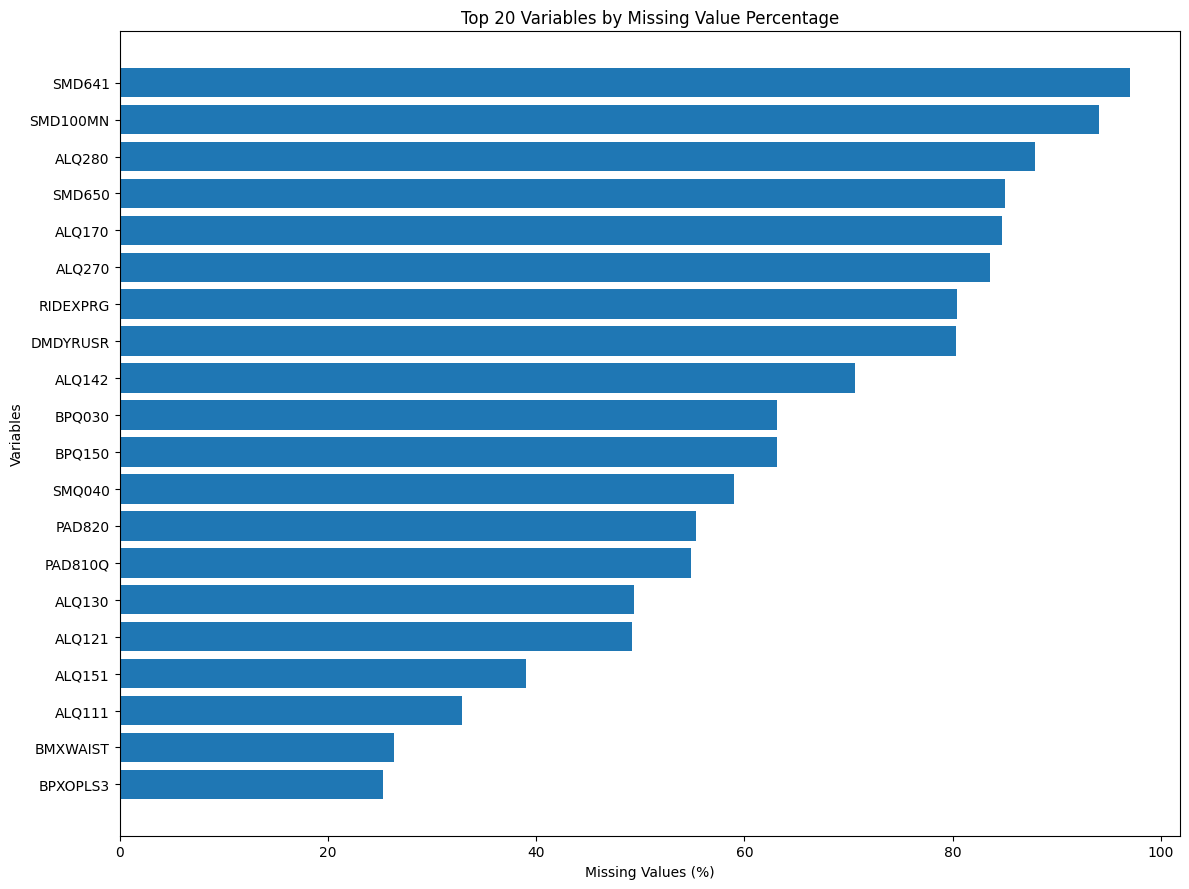

FIGURE SAVED: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/figures/01_top_20_missing_values.png


In [20]:
# Visualize and save the top 20 variables by missing percentage

top_missing = missing_summary.head(20).sort_values(
    by="Missing_Percentage"
)

plt.figure(figsize=(12, 9))

plt.barh(
    top_missing.index,
    top_missing["Missing_Percentage"]
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Variables")
plt.title("Top 20 Variables by Missing Value Percentage")

plt.tight_layout()

# Save figure
figure_path = FIGURES_DIR / "01_top_20_missing_values.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("FIGURE SAVED:", figure_path)

### 8.1 Saving the Missing Value Summary

Save the missing-value statistics for all variables in the integrated dataset.

The summary includes the number and percentage of missing observations for each variable. This output will support decisions regarding missing-data treatment during preprocessing.

In [21]:
# Generate updated missing-value summary

missing_summary = pd.DataFrame({
    "Missing_Count": cleaning_df.isna().sum(),
    "Missing_Percentage": (
        cleaning_df.isna().sum() / len(cleaning_df) * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

# Save missing-value summary
missing_table_path = TABLES_DIR / "01_missing_value_summary.csv"

missing_summary.to_csv(missing_table_path)

print("MISSING VALUE SUMMARY SAVED")
print("=" * 50)

print("File:", missing_table_path)
print("Total variables:", len(missing_summary))
print("File exists:", missing_table_path.exists())

display(missing_summary)

MISSING VALUE SUMMARY SAVED
File: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/01_missing_value_summary.csv
Total variables: 60
File exists: True


,Missing_Count,Missing_Percentage
SMD641,7308,96.97
SMD100MN,7085,94.02
ALQ280,6622,87.87
SMD650,6407,85.02
ALQ170,6388,84.77
ALQ270,6300,83.60
RIDEXPRG,6059,80.40
DMDYRUSR,6053,80.32
ALQ142,5325,70.66
BPQ030,4759,63.15


### 8.2 Categorizing Variables by Missingness

Group variables according to their percentage of missing observations.

The categories provide a descriptive overview of data completeness and help identify variables requiring further investigation.

In [22]:
# Categorize variables by missing percentage

missing_categories = {
    "Complete (0%)": (
        missing_summary["Missing_Percentage"] == 0
    ).sum(),

    "Low (>0% to 5%)": (
        (missing_summary["Missing_Percentage"] > 0) &
        (missing_summary["Missing_Percentage"] <= 5)
    ).sum(),

    "Moderate (>5% to 30%)": (
        (missing_summary["Missing_Percentage"] > 5) &
        (missing_summary["Missing_Percentage"] <= 30)
    ).sum(),

    "High (>30% to <100%)": (
        (missing_summary["Missing_Percentage"] > 30) &
        (missing_summary["Missing_Percentage"] < 100)
    ).sum(),

    "Completely Missing (100%)": (
        missing_summary["Missing_Percentage"] == 100
    ).sum()
}

category_summary = pd.DataFrame(
    list(missing_categories.items()),
    columns=["Missingness_Category", "Number_of_Variables"]
)

print("MISSINGNESS CATEGORY SUMMARY")
print("=" * 50)

display(category_summary)

# Save category summary
category_summary.to_csv(
    TABLES_DIR / "02_missingness_category_summary.csv",
    index=False
)

MISSINGNESS CATEGORY SUMMARY


,Missingness_Category,Number_of_Variables
0,Complete (0%),18
1,Low (>0% to 5%),6
2,Moderate (>5% to 30%),18
3,High (>30% to <100%),18
4,Completely Missing (100%),0


### 8.3 Investigating Variables with High Missingness

Identify variables with more than 30% missing observations.

Examine their missing-value counts and percentages to understand the extent of missingness.

These variables will be reviewed based on their meaning, questionnaire structure, and relevance to the research objective before making feature selection decisions.

In [23]:
# Identify variables with more than 30% missing values

high_missing = missing_summary[
    missing_summary["Missing_Percentage"] > 30
].copy()

print("HIGH-MISSINGNESS VARIABLES")
print("=" * 55)

print("Number of variables:", len(high_missing))

display(high_missing)

# Save high-missingness summary
high_missing.to_csv(
    TABLES_DIR / "03_high_missingness_variables.csv"
)

print("\nHigh-missingness summary saved successfully.")

HIGH-MISSINGNESS VARIABLES
Number of variables: 18


,Missing_Count,Missing_Percentage
SMD641,7308,96.97
SMD100MN,7085,94.02
ALQ280,6622,87.87
SMD650,6407,85.02
ALQ170,6388,84.77
ALQ270,6300,83.60
RIDEXPRG,6059,80.40
DMDYRUSR,6053,80.32
ALQ142,5325,70.66
BPQ030,4759,63.15



High-missingness summary saved successfully.


### 8.4 Visualizing High-Missingness Variables

Create a horizontal bar chart showing the percentage of missing observations in variables with more than 30% missingness.

The visualization helps compare the extent of missing data across variables.

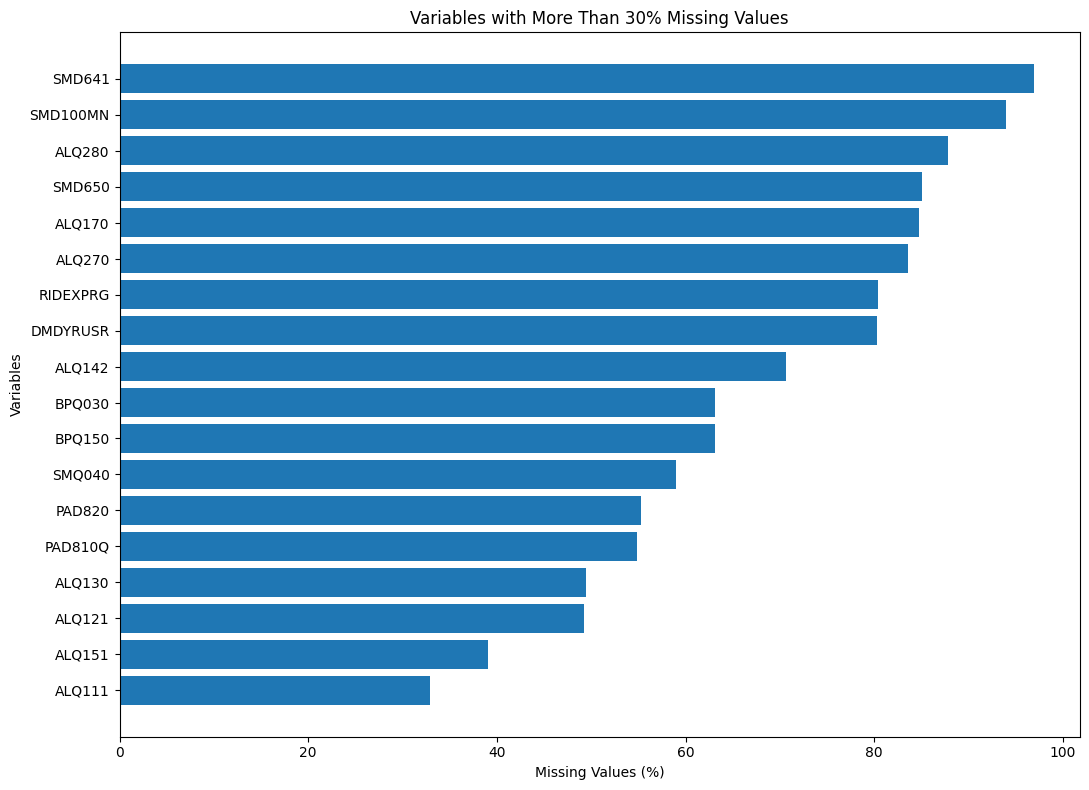

FIGURE SAVED: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/figures/02_high_missingness_variables.png


In [24]:
# Plot high-missingness variables

high_missing_plot = high_missing.sort_values(
    by="Missing_Percentage"
)

plt.figure(figsize=(11, 8))

plt.barh(
    high_missing_plot.index,
    high_missing_plot["Missing_Percentage"]
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Variables")
plt.title("Variables with More Than 30% Missing Values")

plt.tight_layout()

# Save figure
figure_path = FIGURES_DIR / "02_high_missingness_variables.png"

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("FIGURE SAVED:", figure_path)

### 8.5 Detailed Review of High-Missingness Variables

Identify variables with more than 30% missing values and review their missing-value counts and percentages.

These variables will be investigated before deciding whether they should be retained or removed during preprocessing.

In [25]:
# Identify variables with more than 30% missing values
high_missingness = missing_summary[
    missing_summary["Missing_Percentage"] > 30
].copy()

# Display detailed missing-value information
display(high_missingness)

# Save the detailed summary
high_missingness.to_csv(
    TABLES_DIR / "03_high_missingness_variables.csv"
)

print("High-missingness variable summary saved successfully.")
print("Number of variables:", len(high_missingness))

,Missing_Count,Missing_Percentage
SMD641,7308,96.97
SMD100MN,7085,94.02
ALQ280,6622,87.87
SMD650,6407,85.02
ALQ170,6388,84.77
ALQ270,6300,83.60
RIDEXPRG,6059,80.40
DMDYRUSR,6053,80.32
ALQ142,5325,70.66
BPQ030,4759,63.15


High-missingness variable summary saved successfully.
Number of variables: 18


### 8.6 Inspect Values in High-Missingness Variables

Examine the available non-missing values in variables with more than 30% missing data.

This inspection will help identify response patterns, special encoded values, and variables that may require further investigation before preprocessing.

In [26]:
# Inspect non-missing values in high-missingness variables

for column in high_missingness.index:
    print(f"\n{'=' * 50}")
    print(f"Variable: {column}")
    print(f"Non-missing observations: {cleaning_df[column].notna().sum()}")
    print(cleaning_df[column].value_counts(dropna=True).head(15))


Variable: SMD641
Non-missing observations: 228
SMD641
15.0    34
20.0    32
10.0    29
2.0     21
3.0     20
30.0    12
12.0    12
1.0     10
8.0      9
5.0      9
25.0     8
6.0      6
4.0      6
99.0     5
14.0     3
Name: count, dtype: int64

Variable: SMD100MN
Non-missing observations: 451
SMD100MN
1.0    448
9.0      3
Name: count, dtype: int64

Variable: ALQ280
Non-missing observations: 914
ALQ280
10.0    348
7.0     113
9.0     110
6.0      75
8.0      75
5.0      71
4.0      48
3.0      33
2.0      19
1.0      12
99.0      7
77.0      3
Name: count, dtype: int64

Variable: SMD650
Non-missing observations: 1129
SMD650
10.0    206
20.0    200
5.0      94
1.0      87
15.0     85
2.0      77
3.0      54
6.0      53
4.0      53
7.0      42
12.0     33
30.0     31
8.0      29
40.0     26
25.0     14
Name: count, dtype: int64

Variable: ALQ170
Non-missing observations: 1148
ALQ170
1.0     432
2.0     254
3.0     130
4.0      86
5.0      63
30.0     42
6.0      31
8.0      28
20.0    

### 8.7 Findings from High-Missingness Variable Review

The high-missingness variables were reviewed using the NHANES August 2021–August 2023 documentation.

The following observations were identified:

1. Smoking variables:
   - SMD641 records the number of days cigarettes were smoked during the past 30 days.
   - SMD650 records the average number of cigarettes smoked per day.
   - SMD100MN identifies whether cigarettes are menthol or non-menthol.
   - These questions apply to specific participant groups and may contain missing values because of questionnaire skip patterns.

2. Alcohol variables:
   - ALQ111 records whether participants have ever consumed alcohol.
   - ALQ121 records alcohol consumption frequency during the past 12 months.
   - ALQ130, ALQ142, ALQ170, ALQ270, and ALQ280 record different measures of alcohol consumption.
   - Some variables contain special response codes for refused and don't know answers.

3. Pregnancy status:
   - RIDEXPRG applies to females aged 20–44 at the time of the examination.
   - Its missing values are therefore expected for participants outside this eligible group.

4. Other variables:
   - BPQ030, BPQ150, DMDYRUSR, PAD820, and PAD810Q require further review using their respective NHANES documentation.

No variables will be removed solely because of their missing-value percentages at this stage.

In [27]:
# Inspect documented refused and don't know codes

special_code_review = {
    "ALQ111": [7, 9],
    "ALQ121": [77, 99],
    "ALQ130": [777, 999],
    "ALQ142": [77, 99],
    "ALQ151": [7, 9],
    "ALQ170": [77, 99],
    "ALQ270": [77, 99],
    "ALQ280": [77, 99],
    "SMD641": [77, 99],
    "SMD650": [777, 999],
    "SMD100MN": [7, 9]
}

for column, codes in special_code_review.items():
    print(f"\n{column}")
    for code in codes:
        count = (cleaning_df[column] == code).sum()
        if count > 0:
            print(f"Code {code}: {count} observations")


ALQ111
Code 9: 5 observations

ALQ121
Code 77: 2 observations
Code 99: 3 observations

ALQ130
Code 777: 4 observations
Code 999: 10 observations

ALQ142
Code 77: 8 observations
Code 99: 12 observations

ALQ151
Code 7: 1 observations
Code 9: 4 observations

ALQ170

ALQ270
Code 77: 4 observations
Code 99: 9 observations

ALQ280
Code 77: 3 observations
Code 99: 7 observations

SMD641
Code 99: 5 observations

SMD650
Code 999: 9 observations

SMD100MN
Code 9: 3 observations


### 8.8 Convert Special Response Codes in Alcohol Variables

Based on the official NHANES codebook, refused and don't know responses in the alcohol questionnaire variables are converted to standard NaN values.

Valid responses are preserved. Missing values caused by questionnaire skip patterns are not modified.

In [28]:
# Special response codes identified from the NHANES alcohol codebook

alcohol_special_codes = {
    "ALQ111": [7, 9],
    "ALQ121": [77, 99],
    "ALQ130": [777, 999],
    "ALQ142": [77, 99],
    "ALQ151": [7, 9],
    "ALQ170": [777, 999],
    "ALQ270": [77, 99],
    "ALQ280": [77, 99]
}

# Convert confirmed special response codes to NaN
for column, codes in alcohol_special_codes.items():
    cleaning_df[column] = cleaning_df[column].replace(codes, np.nan)

print("Alcohol special response codes converted successfully.")

Alcohol special response codes converted successfully.


In [29]:
# Verify that the special response codes were converted

for column, codes in alcohol_special_codes.items():
    remaining = cleaning_df[column].isin(codes).sum()
    print(f"{column}: {remaining} special codes remaining")

ALQ111: 0 special codes remaining
ALQ121: 0 special codes remaining
ALQ130: 0 special codes remaining
ALQ142: 0 special codes remaining
ALQ151: 0 special codes remaining
ALQ170: 0 special codes remaining
ALQ270: 0 special codes remaining
ALQ280: 0 special codes remaining


In [30]:
checkpoint_file = CLEANING_DIR / "checkpoint_03_alcohol_codes_cleaned.csv"

cleaning_df.to_csv(checkpoint_file, index=False)

print("Checkpoint saved:", checkpoint_file)
print("Current dataset shape:", cleaning_df.shape)
print("Total missing values:", cleaning_df.isna().sum().sum())

Checkpoint saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/data/processed/cleaning_checkpoints/checkpoint_03_alcohol_codes_cleaned.csv
Current dataset shape: (7536, 60)
Total missing values: 125155


### 8.9 Review Special Response Codes in Smoking Variables

Inspect special response codes in the smoking questionnaire variables.

The purpose is to identify refused and don't know responses using the NHANES documentation before converting them into standard missing values.

In [31]:
# Smoking variables requiring special code review

smoking_variables = ["SMD641", "SMD650", "SMD100MN"]

for column in smoking_variables:
    print(f"\n{'=' * 50}")
    print(f"Variable: {column}")
    print(cleaning_df[column].value_counts(dropna=True).sort_index())


Variable: SMD641
SMD641
1.0     10
2.0     21
3.0     20
4.0      6
5.0      9
6.0      6
7.0      3
8.0      9
10.0    29
12.0    12
14.0     3
15.0    34
17.0     1
18.0     1
20.0    32
22.0     1
23.0     1
25.0     8
27.0     2
28.0     2
29.0     1
30.0    12
99.0     5
Name: count, dtype: int64

Variable: SMD650
SMD650
1.0       87
2.0       77
3.0       54
4.0       53
5.0       94
6.0       53
7.0       42
8.0       29
9.0        4
10.0     206
11.0       5
12.0      33
13.0       2
15.0      85
16.0       6
17.0       1
18.0       4
20.0     200
21.0       1
24.0       2
25.0      14
26.0       1
28.0       1
30.0      31
38.0       1
40.0      26
50.0       2
60.0       3
90.0       1
95.0       2
999.0      9
Name: count, dtype: int64

Variable: SMD100MN
SMD100MN
1.0    448
9.0      3
Name: count, dtype: int64


### 8.10 Convert Special Response Codes in Smoking Variables

Based on the official NHANES smoking questionnaire codebook, don't know responses in SMD641, SMD650, and SMD100MN are converted to standard NaN values.

Valid responses are preserved, and missing values resulting from questionnaire skip patterns are not modified.

In [32]:
# Special response codes identified from the NHANES smoking codebook

smoking_special_codes = {
    "SMD641": [99],
    "SMD650": [999],
    "SMD100MN": [9]
}

# Convert confirmed special response codes to NaN
for column, codes in smoking_special_codes.items():
    cleaning_df[column] = cleaning_df[column].replace(codes, np.nan)

print("Smoking special response codes converted successfully.")

Smoking special response codes converted successfully.


In [33]:
# Verify that special response codes were converted

for column, codes in smoking_special_codes.items():
    remaining = cleaning_df[column].isin(codes).sum()
    print(f"{column}: {remaining} special codes remaining")

SMD641: 0 special codes remaining
SMD650: 0 special codes remaining
SMD100MN: 0 special codes remaining


In [34]:
checkpoint_file = CLEANING_DIR / "checkpoint_04_smoking_codes_cleaned.csv"

cleaning_df.to_csv(checkpoint_file, index=False)

print("Checkpoint saved:", checkpoint_file)
print("Current dataset shape:", cleaning_df.shape)
print("Total missing values:", cleaning_df.isna().sum().sum())

Checkpoint saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/data/processed/cleaning_checkpoints/checkpoint_04_smoking_codes_cleaned.csv
Current dataset shape: (7536, 60)
Total missing values: 125172


### 8.11 Review Special Response Codes in Remaining Variables

Inspect the response distributions of demographic, blood pressure, and physical activity variables to identify additional special response codes.

The codes will be reviewed against the corresponding NHANES documentation before any conversion is performed.

In [35]:
# Inspect remaining variables

remaining_variables = [
    "DMDYRUSR",
    "BPQ030",
    "BPQ150",
    "PAD810Q"
]

for column in remaining_variables:
    print(f"\n{'=' * 50}")
    print(f"Variable: {column}")
    print(cleaning_df[column].value_counts(dropna=True).sort_index())


Variable: DMDYRUSR
DMDYRUSR
1.0      60
2.0     140
3.0     141
4.0     111
5.0     139
6.0     846
77.0     12
99.0     34
Name: count, dtype: int64

Variable: BPQ030
BPQ030
1.0    2319
2.0     435
7.0       1
9.0      22
Name: count, dtype: int64

Variable: BPQ150
BPQ150
1.0    2305
2.0     469
9.0       4
Name: count, dtype: int64

Variable: PAD810Q
PAD810Q
1.0       1174
2.0        966
3.0        589
4.0        273
5.0        186
6.0         73
7.0         76
8.0          4
9.0          2
10.0         8
12.0         1
15.0         4
20.0         1
22.0         1
23.0         1
24.0         2
30.0         2
31.0         1
84.0         1
90.0         1
200.0        1
7777.0       3
9999.0      34
Name: count, dtype: int64


### 8.12 Convert Special Response Codes in Remaining Variables

Based on the official NHANES codebooks, refused and don't know responses in the demographic, blood pressure, and physical activity variables are converted to standard NaN values.

Valid responses are preserved. Missing values caused by questionnaire eligibility and skip patterns are not modified.

In [36]:
# Special response codes confirmed using NHANES documentation

remaining_special_codes = {
    "DMDYRUSR": [77, 99],
    "BPQ030": [7, 9],
    "BPQ150": [7, 9],
    "PAD810Q": [7777, 9999]
}

# Convert confirmed special response codes to NaN
for column, codes in remaining_special_codes.items():
    cleaning_df[column] = cleaning_df[column].replace(codes, np.nan)

print("Remaining special response codes converted successfully.")

Remaining special response codes converted successfully.


In [37]:
# Verify conversion

for column, codes in remaining_special_codes.items():
    remaining = cleaning_df[column].isin(codes).sum()
    print(f"{column}: {remaining} special codes remaining")

DMDYRUSR: 0 special codes remaining
BPQ030: 0 special codes remaining
BPQ150: 0 special codes remaining
PAD810Q: 0 special codes remaining


In [38]:
checkpoint_file = CLEANING_DIR / "checkpoint_05_remaining_codes_cleaned.csv"

cleaning_df.to_csv(checkpoint_file, index=False)

print("Checkpoint saved:", checkpoint_file)
print("Current dataset shape:", cleaning_df.shape)
print("Total missing values:", cleaning_df.isna().sum().sum())

Checkpoint saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/data/processed/cleaning_checkpoints/checkpoint_05_remaining_codes_cleaned.csv
Current dataset shape: (7536, 60)
Total missing values: 125282


### 8.13 Updated Missing Value Analysis

Recalculate the missing-value counts and percentages after converting the confirmed refused and don't know response codes into standard NaN values.

Compare the updated missingness distribution with the earlier analysis to assess the impact of special response code conversion.

In [39]:
# Recalculate missing-value statistics

updated_missing_summary = pd.DataFrame({
    "Missing_Count": cleaning_df.isna().sum(),
    "Missing_Percentage": (
        cleaning_df.isna().sum() / len(cleaning_df) * 100
    ).round(2)
})

updated_missing_summary = updated_missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(updated_missing_summary)

,Missing_Count,Missing_Percentage
SMD641,7313,97.04
SMD100MN,7088,94.06
ALQ280,6632,88.00
SMD650,6416,85.14
ALQ170,6394,84.85
ALQ270,6313,83.77
DMDYRUSR,6099,80.93
RIDEXPRG,6059,80.40
ALQ142,5345,70.93
BPQ030,4782,63.46


In [40]:
# Categorize variables based on updated missingness

def categorize_missingness(percentage):
    if percentage == 0:
        return "Complete (0%)"
    elif percentage <= 5:
        return "Low (>0% to 5%)"
    elif percentage <= 30:
        return "Moderate (>5% to 30%)"
    elif percentage < 100:
        return "High (>30% to <100%)"
    else:
        return "Completely Missing (100%)"

updated_missing_summary["Missingness_Category"] = (
    updated_missing_summary["Missing_Percentage"]
    .apply(categorize_missingness)
)

updated_category_summary = (
    updated_missing_summary["Missingness_Category"]
    .value_counts()
    .reindex([
        "Complete (0%)",
        "Low (>0% to 5%)",
        "Moderate (>5% to 30%)",
        "High (>30% to <100%)",
        "Completely Missing (100%)"
    ], fill_value=0)
    .rename_axis("Missingness_Category")
    .reset_index(name="Variable_Count")
)

display(updated_category_summary)

,Missingness_Category,Variable_Count
0,Complete (0%),18
1,Low (>0% to 5%),6
2,Moderate (>5% to 30%),18
3,High (>30% to <100%),18
4,Completely Missing (100%),0


In [41]:
updated_missing_summary.to_csv(
    TABLES_DIR / "04_updated_missing_value_summary.csv"
)

updated_category_summary.to_csv(
    TABLES_DIR / "05_updated_missingness_category_summary.csv",
    index=False
)

print("Updated missing-value tables saved successfully.")

Updated missing-value tables saved successfully.


### 8.14 Target Variable Missingness Check

Check the target variable DIABETES for missing values and verify its class distribution after the data-cleaning operations.

The target variable represents self-reported diagnosed diabetes and must be preserved for supervised machine learning.

In [42]:
# Check missing values in the target variable

print("Missing values in DIABETES:",
      cleaning_df["DIABETES"].isna().sum())

print("\nTarget variable distribution:")
display(cleaning_df["DIABETES"].value_counts().sort_index())

print("\nTarget variable percentage distribution:")
display(
    (cleaning_df["DIABETES"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

Missing values in DIABETES: 0

Target variable distribution:


DIABETES
0.0    6466
1.0    1070
Name: count, dtype: int64


Target variable percentage distribution:


DIABETES
0.0    85.8
1.0    14.2
Name: proportion, dtype: float64

In [43]:
# Check whether target contains only binary values

print("Unique target values:",
      sorted(cleaning_df["DIABETES"].dropna().unique()))

print("Total observations:", len(cleaning_df))
print("Target missing values:", cleaning_df["DIABETES"].isna().sum())

Unique target values: [np.float64(0.0), np.float64(1.0)]
Total observations: 7536
Target missing values: 0


### 8.15 Identify Numerical and Categorical Variables

Identify numerical and categorical variables in the cleaned dataset.

This classification will help determine suitable preprocessing and missing-value imputation techniques for each variable type.

The target variable DIABETES will be excluded from the predictor variable lists.

In [44]:
# Separate target and predictor variables

target_column = "DIABETES"

predictor_df = cleaning_df.drop(columns=[target_column])

# Identify numerical and categorical variables
numerical_columns = predictor_df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = predictor_df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Number of numerical variables:", len(numerical_columns))
print("Number of categorical variables:", len(categorical_columns))

print("\nNumerical variables:")
print(numerical_columns)

print("\nCategorical variables:")
print(categorical_columns)

Number of numerical variables: 57
Number of categorical variables: 2

Numerical variables:
['SEQN', 'SDDSRVYR', 'RIDSTATR', 'RIAGENDR', 'RIDAGEYR', 'RIDRETH1', 'RIDRETH3', 'RIDEXMON', 'DMQMILIZ', 'DMDBORN4', 'DMDYRUSR', 'DMDEDUC2', 'DMDMARTZ', 'RIDEXPRG', 'DMDHHSIZ', 'WTINT2YR', 'WTMEC2YR', 'SDMVSTRA', 'SDMVPSU', 'INDFMPIR', 'BMXBMI', 'BMXWT', 'BMXHT', 'BMXWAIST', 'BPXOSY1', 'BPXODI1', 'BPXOSY2', 'BPXODI2', 'BPXOSY3', 'BPXODI3', 'BPXOPLS1', 'BPXOPLS2', 'BPXOPLS3', 'BPQ020', 'BPQ030', 'BPQ150', 'BPQ080', 'BPQ101D', 'PAD790Q', 'PAD800', 'PAD810Q', 'PAD820', 'PAD680', 'SMQ020', 'SMQ040', 'SMD641', 'SMD650', 'SMD100MN', 'SMAQUEX2', 'ALQ111', 'ALQ121', 'ALQ130', 'ALQ142', 'ALQ270', 'ALQ280', 'ALQ151', 'ALQ170']

Categorical variables:
['PAD790U', 'PAD810U']


### 8.16 Identify Variable Roles

Review the variables according to their analytical roles, including participant identifiers, survey-design variables, numerical measurements, and categorical questionnaire responses.

This step is necessary because some NHANES categorical variables are stored using numerical data types.

The target variable DIABETES is kept separate from all predictor variables.

In [45]:
# Inspect the number of unique values in each predictor variable

variable_profile = pd.DataFrame({
    "Data_Type": predictor_df.dtypes.astype(str),
    "Unique_Values": predictor_df.nunique(),
    "Missing_Count": predictor_df.isna().sum(),
    "Missing_Percentage": (
        predictor_df.isna().sum() / len(predictor_df) * 100
    ).round(2)
})

variable_profile = variable_profile.sort_values(
    by="Unique_Values"
)

display(variable_profile)

,Data_Type,Unique_Values,Missing_Count,Missing_Percentage
SMAQUEX2,float64,1,0,0.00
SDDSRVYR,float64,1,0,0.00
SMD100MN,float64,1,7088,94.06
RIDSTATR,float64,2,0,0.00
RIAGENDR,float64,2,0,0.00
BPQ150,float64,2,4762,63.19
BPQ030,float64,2,4782,63.46
RIDEXMON,float64,2,1693,22.47
ALQ151,float64,2,2949,39.13
DMDBORN4,float64,2,14,0.19


In [46]:
# Review variables with a relatively small number of unique values

for column in predictor_df.select_dtypes(include=np.number).columns:
    unique_count = predictor_df[column].nunique()

    if unique_count <= 15:
        print(f"\n{'=' * 45}")
        print(f"Variable: {column}")
        print("Unique values:")
        print(sorted(predictor_df[column].dropna().unique()))


Variable: SDDSRVYR
Unique values:
[np.float64(12.0)]

Variable: RIDSTATR
Unique values:
[np.float64(1.0), np.float64(2.0)]

Variable: RIAGENDR
Unique values:
[np.float64(1.0), np.float64(2.0)]

Variable: RIDRETH1
Unique values:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]

Variable: RIDRETH3
Unique values:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(6.0), np.float64(7.0)]

Variable: RIDEXMON
Unique values:
[np.float64(1.0), np.float64(2.0)]

Variable: DMQMILIZ
Unique values:
[np.float64(1.0), np.float64(2.0), np.float64(7.0)]

Variable: DMDBORN4
Unique values:
[np.float64(1.0), np.float64(2.0)]

Variable: DMDYRUSR
Unique values:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0)]

Variable: DMDEDUC2
Unique values:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(9.0)]

Variable: DMDMARTZ
Unique values:
[np.float

### 8.17 Review Additional Special Response Codes

Review demographic, blood pressure, and smoking questionnaire variables for additional special response codes.

These variables contain numerical values that may represent categorical responses, including refused and don't know answers.

All identified codes will be verified against the corresponding NHANES documentation before conversion.

In [47]:
# Variables requiring additional special response code review

additional_review_variables = [
    "DMQMILIZ",
    "DMDMARTZ",
    "BPQ020",
    "BPQ080",
    "BPQ101D",
    "SMQ020"
]

for column in additional_review_variables:
    print(f"\n{'=' * 50}")
    print(f"Variable: {column}")
    print(cleaning_df[column].value_counts(dropna=True).sort_index())


Variable: DMQMILIZ
DMQMILIZ
1.0     662
2.0    6860
7.0       1
Name: count, dtype: int64

Variable: DMDMARTZ
DMDMARTZ
1.0     3986
2.0     1944
3.0     1582
77.0       4
99.0       5
Name: count, dtype: int64

Variable: BPQ020
BPQ020
1.0    2778
2.0    4747
7.0       1
9.0      10
Name: count, dtype: int64

Variable: BPQ080
BPQ080
1.0    2885
2.0    4605
7.0       1
9.0      45
Name: count, dtype: int64

Variable: BPQ101D
BPQ101D
1.0    2007
2.0    5497
9.0      32
Name: count, dtype: int64

Variable: SMQ020
SMQ020
1.0    3093
2.0    4416
7.0       7
9.0       7
Name: count, dtype: int64


In [48]:
# Identify columns with only one unique non-missing value

constant_columns = [
    column
    for column in cleaning_df.columns
    if cleaning_df[column].nunique(dropna=True) <= 1
]

print("Constant columns:")
print(constant_columns)

Constant columns:
['SDDSRVYR', 'SMD100MN', 'SMAQUEX2']


### 8.18 Convert Additional Special Response Codes

Based on the official NHANES August 2021–August 2023 codebooks, confirmed refused and don't know responses in demographic, blood pressure, and smoking variables are converted to standard NaN values.

Valid responses are preserved, and questionnaire skip-pattern missing values are not modified.

In [49]:
# Special response codes verified using NHANES documentation

additional_special_codes = {
    "DMQMILIZ": [7, 9],
    "DMDMARTZ": [77, 99],
    "BPQ020": [7, 9],
    "BPQ080": [7, 9],
    "BPQ101D": [7, 9],
    "SMQ020": [7, 9]
}

# Convert confirmed special response codes to NaN

for column, codes in additional_special_codes.items():
    cleaning_df[column] = cleaning_df[column].replace(codes, np.nan)

print("Additional special response codes converted successfully.")

Additional special response codes converted successfully.


In [50]:
for column, codes in additional_special_codes.items():
    remaining = cleaning_df[column].isin(codes).sum()
    print(f"{column}: {remaining} special codes remaining")

DMQMILIZ: 0 special codes remaining
DMDMARTZ: 0 special codes remaining
BPQ020: 0 special codes remaining
BPQ080: 0 special codes remaining
BPQ101D: 0 special codes remaining
SMQ020: 0 special codes remaining


In [51]:
checkpoint_file = CLEANING_DIR / "checkpoint_06_additional_codes_cleaned.csv"

cleaning_df.to_csv(checkpoint_file, index=False)

print("Checkpoint saved:", checkpoint_file)
print("Dataset shape:", cleaning_df.shape)
print("Total missing values:", cleaning_df.isna().sum().sum())

Checkpoint saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/data/processed/cleaning_checkpoints/checkpoint_06_additional_codes_cleaned.csv
Dataset shape: (7536, 60)
Total missing values: 125395


### 8.19 Remove Non-Informative Variables

Identify and remove constant variables that contain only one unique non-missing value.

These variables provide no variation for machine learning and are excluded from the predictor dataset.

The original integrated dataset remains unchanged.

In [52]:
# Identify constant columns

constant_columns = [
    column
    for column in cleaning_df.columns
    if cleaning_df[column].nunique(dropna=True) <= 1
]

print("Constant columns identified:")
print(constant_columns)

Constant columns identified:
['SDDSRVYR', 'SMD100MN', 'SMAQUEX2']


In [53]:
# Remove constant columns from the working dataset

cleaning_df.drop(columns=constant_columns, inplace=True)

print("Constant columns removed:", constant_columns)
print("Updated dataset shape:", cleaning_df.shape)

Constant columns removed: ['SDDSRVYR', 'SMD100MN', 'SMAQUEX2']
Updated dataset shape: (7536, 57)


In [54]:
checkpoint_file = CLEANING_DIR / "checkpoint_07_constant_columns_removed.csv"

cleaning_df.to_csv(checkpoint_file, index=False)

print("Checkpoint saved:", checkpoint_file)

Checkpoint saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/data/processed/cleaning_checkpoints/checkpoint_07_constant_columns_removed.csv


### 8.20 Identify Identifier and Survey-Design Variables

Identify participant identifiers, survey weights, and survey-design variables.

These variables are retained separately for participant identification and survey-based statistical analysis but will not be used as ordinary machine-learning predictors.

The target variable DIABETES remains separate.

In [55]:
# Identify participant identifier and survey-design variables

identifier_columns = ["SEQN"]

survey_design_columns = [
    "WTINT2YR",
    "WTMEC2YR",
    "SDMVSTRA",
    "SDMVPSU"
]

print("Identifier variables:")
print(identifier_columns)

print("\nSurvey-design variables:")
print(survey_design_columns)

print("\nCheck whether all variables exist:")
for column in identifier_columns + survey_design_columns:
    print(f"{column}: {column in cleaning_df.columns}")

Identifier variables:
['SEQN']

Survey-design variables:
['WTINT2YR', 'WTMEC2YR', 'SDMVSTRA', 'SDMVPSU']

Check whether all variables exist:
SEQN: True
WTINT2YR: True
WTMEC2YR: True
SDMVSTRA: True
SDMVPSU: True


In [56]:
# Preserve identifiers and survey-design information separately

identifier_df = cleaning_df[identifier_columns].copy()

survey_design_df = cleaning_df[survey_design_columns].copy()

# Create machine-learning dataset without identifiers or survey-design variables
ml_df = cleaning_df.drop(
    columns=identifier_columns + survey_design_columns
).copy()

print("Cleaning dataset shape:", cleaning_df.shape)
print("Identifier dataset shape:", identifier_df.shape)
print("Survey-design dataset shape:", survey_design_df.shape)
print("Machine-learning dataset shape:", ml_df.shape)

Cleaning dataset shape: (7536, 57)
Identifier dataset shape: (7536, 1)
Survey-design dataset shape: (7536, 4)
Machine-learning dataset shape: (7536, 52)


### 8.21 Identify Categorical and Numerical Features

Classify the machine-learning predictor variables into numerical and categorical groups.

Numerical variables represent continuous measurements or quantitative values, while categorical variables represent groups, survey responses, or ordinal categories.

The target variable DIABETES is maintained separately for supervised classification.

In [57]:
# Define categorical variables based on NHANES variable meanings

categorical_features = [
    "RIDSTATR",
    "RIAGENDR",
    "RIDRETH1",
    "RIDRETH3",
    "RIDEXMON",
    "DMQMILIZ",
    "DMDBORN4",
    "DMDYRUSR",
    "DMDEDUC2",
    "DMDMARTZ",
    "RIDEXPRG",
    "BPQ020",
    "BPQ030",
    "BPQ150",
    "BPQ080",
    "BPQ101D",
    "PAD790U",
    "PAD810U",
    "SMQ020",
    "SMQ040",
    "ALQ111",
    "ALQ121",
    "ALQ151"
]

# Retain only variables present in the ML dataset
categorical_features = [
    col for col in categorical_features
    if col in ml_df.columns
]

# Identify remaining numerical features
numerical_features = [
    col for col in ml_df.columns
    if col not in categorical_features + ["DIABETES"]
]

print("Categorical features:", len(categorical_features))
print(categorical_features)

print("\nNumerical features:", len(numerical_features))
print(numerical_features)

Categorical features: 23
['RIDSTATR', 'RIAGENDR', 'RIDRETH1', 'RIDRETH3', 'RIDEXMON', 'DMQMILIZ', 'DMDBORN4', 'DMDYRUSR', 'DMDEDUC2', 'DMDMARTZ', 'RIDEXPRG', 'BPQ020', 'BPQ030', 'BPQ150', 'BPQ080', 'BPQ101D', 'PAD790U', 'PAD810U', 'SMQ020', 'SMQ040', 'ALQ111', 'ALQ121', 'ALQ151']

Numerical features: 28
['RIDAGEYR', 'DMDHHSIZ', 'INDFMPIR', 'BMXBMI', 'BMXWT', 'BMXHT', 'BMXWAIST', 'BPXOSY1', 'BPXODI1', 'BPXOSY2', 'BPXODI2', 'BPXOSY3', 'BPXODI3', 'BPXOPLS1', 'BPXOPLS2', 'BPXOPLS3', 'PAD790Q', 'PAD800', 'PAD810Q', 'PAD820', 'PAD680', 'SMD641', 'SMD650', 'ALQ130', 'ALQ142', 'ALQ270', 'ALQ280', 'ALQ170']


In [58]:
# Verify feature groups

print("Total ML dataset columns:", len(ml_df.columns))
print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

print("\nCategorical variables with non-categorical data types:")
print([
    col for col in categorical_features
    if ml_df[col].dtype == "object"
])

print("\nFeature grouping verified:",
      len(categorical_features) + len(numerical_features)
      == len(ml_df.columns) - 1)

print("\nCategorical and numerical groups overlap:",
      bool(set(categorical_features) & set(numerical_features)))

Total ML dataset columns: 52
Categorical features: 23
Numerical features: 28

Categorical variables with non-categorical data types:
['PAD790U', 'PAD810U']

Feature grouping verified: True

Categorical and numerical groups overlap: False


### 8.22 Missing Value Analysis by Feature Type

Analyze missing values separately for numerical and categorical predictor variables.

Calculate missing-value counts and percentages for each feature group.

This analysis will help determine suitable missing-value handling strategies for numerical measurements and categorical questionnaire responses.

In [59]:
# Analyze missing values in numerical features

numerical_missing_summary = pd.DataFrame({
    "Missing_Count": ml_df[numerical_features].isna().sum(),
    "Missing_Percentage": (
        ml_df[numerical_features].isna().sum()
        / len(ml_df) * 100
    ).round(2)
})

numerical_missing_summary = numerical_missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(numerical_missing_summary)

,Missing_Count,Missing_Percentage
SMD641,7313,97.04
ALQ280,6632,88.00
SMD650,6416,85.14
ALQ170,6394,84.85
ALQ270,6313,83.77
ALQ142,5345,70.93
PAD810Q,4169,55.32
PAD820,4168,55.31
ALQ130,3739,49.62
BMXWAIST,1983,26.31


In [60]:
# Analyze missing values in categorical features

categorical_missing_summary = pd.DataFrame({
    "Missing_Count": ml_df[categorical_features].isna().sum(),
    "Missing_Percentage": (
        ml_df[categorical_features].isna().sum()
        / len(ml_df) * 100
    ).round(2)
})

categorical_missing_summary = categorical_missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(categorical_missing_summary)

,Missing_Count,Missing_Percentage
DMDYRUSR,6099,80.93
RIDEXPRG,6059,80.40
BPQ030,4782,63.46
BPQ150,4762,63.19
SMQ040,4443,58.96
ALQ121,3716,49.31
ALQ151,2949,39.13
ALQ111,2482,32.94
RIDEXMON,1693,22.47
BPQ080,46,0.61


In [61]:
numerical_missing_summary.to_csv(
    TABLES_DIR / "06_numerical_feature_missingness.csv"
)

categorical_missing_summary.to_csv(
    TABLES_DIR / "07_categorical_feature_missingness.csv"
)

print("Numerical and categorical missingness tables saved.")

Numerical and categorical missingness tables saved.


### 8.23 Investigate Missingness Patterns

Analyze the relationship between missing values across predictor variables.

Identify patterns of missingness that may indicate questionnaire skip patterns or participant eligibility restrictions.

This analysis will help distinguish structural missingness from other missing-data patterns before selecting imputation methods.

In [62]:
# Create missingness indicators for predictor variables

missingness_matrix = ml_df.isna().astype(int)

print("Missingness matrix shape:", missingness_matrix.shape)

print("\nMissing values per observation:")
display(missingness_matrix.sum(axis=1).describe())

Missingness matrix shape: (7536, 52)

Missing values per observation:


count    7536.000000
mean       15.474257
std         8.281358
min         1.000000
25%        10.000000
50%        12.000000
75%        19.000000
max        40.000000
dtype: float64

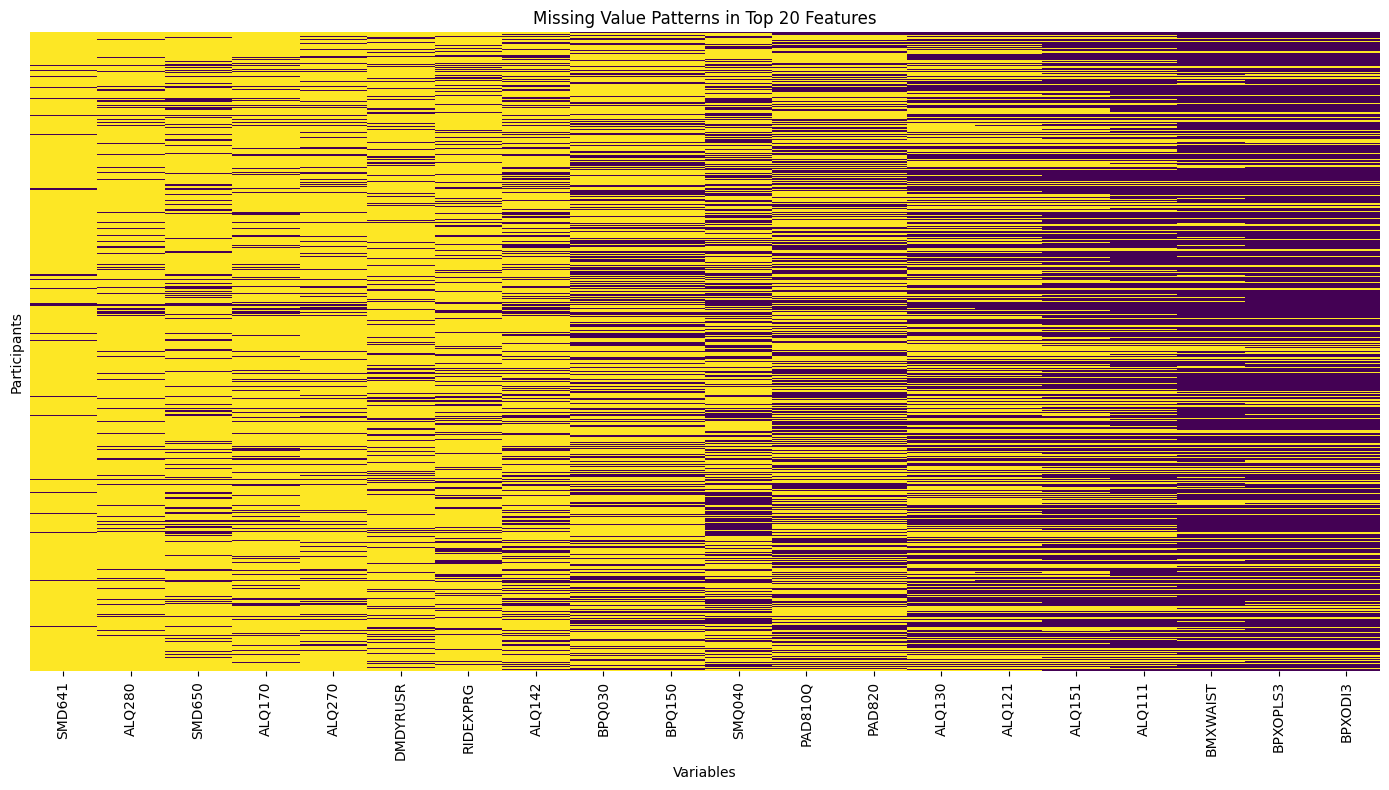

Figure saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/figures/03_missingness_patterns.png


In [63]:
# Visualize missingness patterns for the 20 variables
# with the highest missing percentages

top_missing_features = (
    ml_df.isna().mean()
    .sort_values(ascending=False)
    .head(20)
    .index
)

plt.figure(figsize=(14, 8))

sns.heatmap(
    ml_df[top_missing_features].isna(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Value Patterns in Top 20 Features")
plt.xlabel("Variables")
plt.ylabel("Participants")
plt.xticks(rotation=90)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "03_missingness_patterns.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", FIGURES_DIR / "03_missingness_patterns.png")

In [64]:
# Calculate correlations between missingness indicators

missingness_correlation = missingness_matrix.corr()

display(
    missingness_correlation.round(2)
)

,RIDSTATR,RIAGENDR,RIDAGEYR,RIDRETH1,RIDRETH3,RIDEXMON,DMQMILIZ,DMDBORN4,DMDYRUSR,DMDEDUC2,...,SMD641,SMD650,ALQ111,ALQ121,ALQ130,ALQ142,ALQ270,ALQ280,ALQ151,ALQ170
RIDSTATR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RIAGENDR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RIDAGEYR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RIDRETH1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RIDRETH3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RIDEXMON,NaN,NaN,NaN,NaN,NaN,1.00,0.08,0.08,0.02,0.08,...,-0.00,-0.00,0.77,0.55,0.54,0.34,0.24,0.20,0.67,0.23
DMQMILIZ,NaN,NaN,NaN,NaN,NaN,0.08,1.00,0.93,0.02,0.96,...,0.01,0.01,0.06,0.04,0.04,0.03,0.02,0.02,0.05,0.02
DMDBORN4,NaN,NaN,NaN,NaN,NaN,0.08,0.93,1.00,0.02,0.96,...,0.01,0.02,0.06,0.04,0.04,0.03,0.02,0.02,0.05,0.02
DMDYRUSR,NaN,NaN,NaN,NaN,NaN,0.02,0.02,0.02,1.00,0.02,...,-0.01,-0.08,-0.07,-0.10,-0.10,-0.03,0.01,-0.01,-0.13,-0.04
DMDEDUC2,NaN,NaN,NaN,NaN,NaN,0.08,0.96,0.96,0.02,1.00,...,0.01,0.02,0.06,0.04,0.04,0.03,0.02,0.02,0.05,0.02


In [65]:
missingness_correlation.to_csv(
    TABLES_DIR / "08_missingness_correlation.csv"
)

print("Missingness correlation table saved successfully.")

Missingness correlation table saved successfully.


### 8.24 Identify Variables for Retention or Removal

Review predictor variables based on their missing-value percentages.

Classify variables into missingness groups to identify those requiring further investigation.

Variables with high missingness will not be automatically removed because missing values may result from NHANES questionnaire skip patterns or participant eligibility.

In [66]:
# Create a variable retention review table

feature_missingness = pd.DataFrame({
    "Missing_Count": ml_df.isna().sum(),
    "Missing_Percentage": (
        ml_df.isna().mean() * 100
    ).round(2)
})

def assign_review_category(value):
    if value == 0:
        return "Complete"
    elif value <= 5:
        return "Low Missingness"
    elif value <= 30:
        return "Moderate Missingness"
    else:
        return "High Missingness - Review Required"

feature_missingness["Review_Category"] = (
    feature_missingness["Missing_Percentage"]
    .apply(assign_review_category)
)

feature_missingness = feature_missingness.sort_values(
    "Missing_Percentage",
    ascending=False
)

display(feature_missingness)

,Missing_Count,Missing_Percentage,Review_Category
SMD641,7313,97.04,High Missingness - Review Required
ALQ280,6632,88.00,High Missingness - Review Required
SMD650,6416,85.14,High Missingness - Review Required
ALQ170,6394,84.85,High Missingness - Review Required
ALQ270,6313,83.77,High Missingness - Review Required
DMDYRUSR,6099,80.93,High Missingness - Review Required
RIDEXPRG,6059,80.40,High Missingness - Review Required
ALQ142,5345,70.93,High Missingness - Review Required
BPQ030,4782,63.46,High Missingness - Review Required
BPQ150,4762,63.19,High Missingness - Review Required


In [67]:
feature_missingness.to_csv(
    TABLES_DIR / "09_feature_retention_review.csv"
)

print("Feature retention review saved successfully.")

Feature retention review saved successfully.


In [68]:
display(
    feature_missingness["Review_Category"]
    .value_counts()
    .rename_axis("Review_Category")
    .reset_index(name="Variable_Count")
)

,Review_Category,Variable_Count
0,High Missingness - Review Required,17
1,Moderate Missingness,17
2,Low Missingness,9
3,Complete,9


### 8.25 Review High-Missingness Features

Identify predictor variables with more than 30% missing values.

Review their missing-value counts, percentages, and variable names to determine which features require further investigation.

High-missingness variables will not be automatically removed because missing values may be related to NHANES questionnaire skip patterns or participant eligibility.

In [69]:
# Identify features with more than 30% missing values

high_missing_features = feature_missingness[
    feature_missingness["Missing_Percentage"] > 30
].copy()

display(high_missing_features)

print("\nNumber of high-missingness features:",
      len(high_missing_features))

,Missing_Count,Missing_Percentage,Review_Category
SMD641,7313,97.04,High Missingness - Review Required
ALQ280,6632,88.00,High Missingness - Review Required
SMD650,6416,85.14,High Missingness - Review Required
ALQ170,6394,84.85,High Missingness - Review Required
ALQ270,6313,83.77,High Missingness - Review Required
DMDYRUSR,6099,80.93,High Missingness - Review Required
RIDEXPRG,6059,80.40,High Missingness - Review Required
ALQ142,5345,70.93,High Missingness - Review Required
BPQ030,4782,63.46,High Missingness - Review Required
BPQ150,4762,63.19,High Missingness - Review Required



Number of high-missingness features: 17


In [70]:
high_missing_features.to_csv(
    TABLES_DIR / "10_high_missingness_feature_review.csv"
)

print("High-missingness feature review saved successfully.")

High-missingness feature review saved successfully.


### 8.26 High-Missingness Feature Retention Decisions

Review the 17 predictor variables with more than 30% missing values.

Evaluate their missingness percentages and identify variables that require further investigation.

Variables potentially affected by questionnaire skip patterns or participant eligibility will be retained for further review before making final preprocessing decisions.

In [71]:
# Create a provisional feature retention decision table

retention_review = high_missing_features.copy()

retention_review["Retention_Decision"] = "Retain for further investigation"

retention_review["Review_Reason"] = (
    "Investigate questionnaire skip patterns, "
    "participant eligibility, and variable relevance"
)

display(retention_review)

,Missing_Count,Missing_Percentage,Review_Category,Retention_Decision,Review_Reason
SMD641,7313,97.04,High Missingness - Review Required,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."
ALQ280,6632,88.00,High Missingness - Review Required,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."
SMD650,6416,85.14,High Missingness - Review Required,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."
ALQ170,6394,84.85,High Missingness - Review Required,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."
ALQ270,6313,83.77,High Missingness - Review Required,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."
DMDYRUSR,6099,80.93,High Missingness - Review Required,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."
RIDEXPRG,6059,80.40,High Missingness - Review Required,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."
ALQ142,5345,70.93,High Missingness - Review Required,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."
BPQ030,4782,63.46,High Missingness - Review Required,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."
BPQ150,4762,63.19,High Missingness - Review Required,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."


In [72]:
retention_review.to_csv(
    TABLES_DIR / "11_high_missingness_retention_decisions.csv"
)

print("Feature retention decision table saved successfully.")
print("Variables retained for investigation:", len(retention_review))

Feature retention decision table saved successfully.
Variables retained for investigation: 17


### 8.27 Investigate Questionnaire Skip Patterns

Investigate the high-missingness variables according to their NHANES questionnaire sections.

Identify variables that may have missing values because of participant eligibility, questionnaire skip patterns, or nonresponse.

The investigation will help determine whether missing values should be preserved, treated separately, or handled through imputation.

In [73]:
questionnaire_groups = {
    "Smoking": ["SMD641", "SMD650", "SMQ040"],
    "Alcohol": [
        "ALQ111", "ALQ121", "ALQ130", "ALQ142",
        "ALQ151", "ALQ170", "ALQ270", "ALQ280"
    ],
    "Blood Pressure": ["BPQ030", "BPQ150"],
    "Physical Activity": ["PAD810Q", "PAD820"],
    "Demographic": ["DMDYRUSR", "RIDEXPRG"]
}

review_records = []

for group, variables in questionnaire_groups.items():
    for variable in variables:
        if variable in high_missing_features.index:
            review_records.append({
                "Questionnaire_Group": group,
                "Variable": variable,
                "Missing_Count": feature_missingness.loc[
                    variable, "Missing_Count"
                ],
                "Missing_Percentage": feature_missingness.loc[
                    variable, "Missing_Percentage"
                ],
                "Documentation_Status": "Pending review",
                "Retention_Decision": "Retain provisionally"
            })

questionnaire_review = pd.DataFrame(review_records)

display(questionnaire_review)

print("Total variables reviewed:", len(questionnaire_review))

,Questionnaire_Group,Variable,Missing_Count,Missing_Percentage,Documentation_Status,Retention_Decision
0,Smoking,SMD641,7313,97.04,Pending review,Retain provisionally
1,Smoking,SMD650,6416,85.14,Pending review,Retain provisionally
2,Smoking,SMQ040,4443,58.96,Pending review,Retain provisionally
3,Alcohol,ALQ111,2482,32.94,Pending review,Retain provisionally
4,Alcohol,ALQ121,3716,49.31,Pending review,Retain provisionally
5,Alcohol,ALQ130,3739,49.62,Pending review,Retain provisionally
6,Alcohol,ALQ142,5345,70.93,Pending review,Retain provisionally
7,Alcohol,ALQ151,2949,39.13,Pending review,Retain provisionally
8,Alcohol,ALQ170,6394,84.85,Pending review,Retain provisionally
9,Alcohol,ALQ270,6313,83.77,Pending review,Retain provisionally


Total variables reviewed: 17


In [74]:
questionnaire_review.to_csv(
    TABLES_DIR / "12_questionnaire_skip_pattern_review.csv",
    index=False
)

print("Corrected questionnaire review table saved.")

Corrected questionnaire review table saved.


### 8.28 Review NHANES Variable Definitions and Eligibility

Review the official NHANES August 2021–August 2023 documentation for the 17 high-missingness variables.

Record each variable's description, eligible participant population, questionnaire skip instructions, and special response codes.

This review will help distinguish structural missingness from item nonresponse and support evidence-based feature retention decisions.

In [75]:
# Prepare a table for reviewing official NHANES documentation

variable_documentation = questionnaire_review[
    ["Questionnaire_Group", "Variable", "Missing_Count",
     "Missing_Percentage"]
].copy()

variable_documentation["Variable_Description"] = "Pending verification"
variable_documentation["Eligible_Population"] = "Pending verification"
variable_documentation["Skip_Pattern"] = "Pending verification"
variable_documentation["Special_Codes"] = "Pending verification"
variable_documentation["Documentation_Source"] = "NHANES 2021-2023 codebook"

display(variable_documentation)

,Questionnaire_Group,Variable,Missing_Count,Missing_Percentage,Variable_Description,Eligible_Population,Skip_Pattern,Special_Codes,Documentation_Source
0,Smoking,SMD641,7313,97.04,Pending verification,Pending verification,Pending verification,Pending verification,NHANES 2021-2023 codebook
1,Smoking,SMD650,6416,85.14,Pending verification,Pending verification,Pending verification,Pending verification,NHANES 2021-2023 codebook
2,Smoking,SMQ040,4443,58.96,Pending verification,Pending verification,Pending verification,Pending verification,NHANES 2021-2023 codebook
3,Alcohol,ALQ111,2482,32.94,Pending verification,Pending verification,Pending verification,Pending verification,NHANES 2021-2023 codebook
4,Alcohol,ALQ121,3716,49.31,Pending verification,Pending verification,Pending verification,Pending verification,NHANES 2021-2023 codebook
5,Alcohol,ALQ130,3739,49.62,Pending verification,Pending verification,Pending verification,Pending verification,NHANES 2021-2023 codebook
6,Alcohol,ALQ142,5345,70.93,Pending verification,Pending verification,Pending verification,Pending verification,NHANES 2021-2023 codebook
7,Alcohol,ALQ151,2949,39.13,Pending verification,Pending verification,Pending verification,Pending verification,NHANES 2021-2023 codebook
8,Alcohol,ALQ170,6394,84.85,Pending verification,Pending verification,Pending verification,Pending verification,NHANES 2021-2023 codebook
9,Alcohol,ALQ270,6313,83.77,Pending verification,Pending verification,Pending verification,Pending verification,NHANES 2021-2023 codebook


In [76]:
variable_documentation.to_csv(
    TABLES_DIR / "13_nhanes_variable_documentation_review.csv",
    index=False
)

print("NHANES variable documentation review template saved.")
print("Variables to review:", len(variable_documentation))

NHANES variable documentation review template saved.
Variables to review: 17


#### 8.28.1 Smoking Questionnaire Variables

Document the smoking-related variables using the NHANES August 2021–August 2023 smoking questionnaire codebook.

Review variable descriptions, eligible participants, questionnaire skip patterns, and special response codes.

This documentation will help distinguish structural missingness from item nonresponse and guide appropriate missing-value treatment.

In [77]:
# Record verified smoking variable documentation

smoking_documentation = {
    "SMD641": {
        "Variable_Description": "Number of days smoked cigarettes in past 30 days",
        "Eligible_Population": "Participants aged 12 years and older",
        "Skip_Pattern": "Follow-up cigarette-use question; responses depend on smoking history and prior questions",
        "Special_Codes": "77 = Refused; 99 = Don't know"
    },
    "SMD650": {
        "Variable_Description": "Average number of cigarettes smoked per day in past 30 days",
        "Eligible_Population": "Participants aged 12 years and older",
        "Skip_Pattern": "Follow-up question for participants reporting cigarette smoking",
        "Special_Codes": "777 = Refused; 999 = Don't know"
    },
    "SMQ040": {
        "Variable_Description": "Current cigarette smoking frequency",
        "Eligible_Population": "Adults aged 18 years and older",
        "Skip_Pattern": "Asked after SMQ020; participants answering No to 100 cigarettes skip this question",
        "Special_Codes": "7 = Refused; 9 = Don't know"
    }
}

for variable, details in smoking_documentation.items():
    for column, value in details.items():
        variable_documentation.loc[
            variable_documentation["Variable"] == variable,
            column
        ] = value

variable_documentation.to_csv(
    TABLES_DIR / "13_nhanes_variable_documentation_review.csv",
    index=False
)

display(
    variable_documentation[
        variable_documentation["Variable"].isin(
            smoking_documentation.keys()
        )
    ]
)

print("Verified smoking documentation saved.")

,Questionnaire_Group,Variable,Missing_Count,Missing_Percentage,Variable_Description,Eligible_Population,Skip_Pattern,Special_Codes,Documentation_Source
0,Smoking,SMD641,7313,97.04,Number of days smoked cigarettes in past 30 days,Participants aged 12 years and older,Follow-up cigarette-use question; responses de...,77 = Refused; 99 = Don't know,NHANES 2021-2023 codebook
1,Smoking,SMD650,6416,85.14,Average number of cigarettes smoked per day in...,Participants aged 12 years and older,Follow-up question for participants reporting ...,777 = Refused; 999 = Don't know,NHANES 2021-2023 codebook
2,Smoking,SMQ040,4443,58.96,Current cigarette smoking frequency,Adults aged 18 years and older,Asked after SMQ020; participants answering No ...,7 = Refused; 9 = Don't know,NHANES 2021-2023 codebook


Verified smoking documentation saved.


#### 8.28.2 Alcohol Questionnaire Variables

Document the alcohol-related variables using the NHANES August 2021–August 2023 alcohol questionnaire codebook.

Review variable descriptions, eligible participants, questionnaire skip patterns, and special response codes.

In [78]:
# Document alcohol questionnaire variables

alcohol_documentation = {
    "ALQ111": {
        "Variable_Description": "Ever had at least 12 alcoholic drinks in any one year",
        "Eligible_Population": "Adults aged 18 years and older",
        "Skip_Pattern": "No responses may lead to follow-up questionnaire skips",
        "Special_Codes": "7 = Refused; 9 = Don't know"
    },
    "ALQ121": {
        "Variable_Description": "Frequency of alcohol consumption during the past 12 months",
        "Eligible_Population": "Adults aged 18 years and older",
        "Skip_Pattern": "Depends on previous alcohol consumption screening questions",
        "Special_Codes": "77 = Refused; 99 = Don't know"
    },
    "ALQ130": {
        "Variable_Description": "Average number of alcoholic drinks per drinking day",
        "Eligible_Population": "Adults aged 18 years and older",
        "Skip_Pattern": "Follow-up question for participants reporting alcohol consumption",
        "Special_Codes": "777 = Refused; 999 = Don't know"
    },
    "ALQ142": {
        "Variable_Description": "Frequency of consuming five or more drinks in a day",
        "Eligible_Population": "Adults aged 18 years and older",
        "Skip_Pattern": "Follow-up alcohol consumption question",
        "Special_Codes": "77 = Refused; 99 = Don't know"
    },
    "ALQ151": {
        "Variable_Description": "Ever had a period of heavy drinking",
        "Eligible_Population": "Adults aged 18 years and older",
        "Skip_Pattern": "Alcohol-related questionnaire item",
        "Special_Codes": "7 = Refused; 9 = Don't know"
    },
    "ALQ170": {
        "Variable_Description": "Frequency of consuming eight or more drinks in a day",
        "Eligible_Population": "Adults aged 18 years and older",
        "Skip_Pattern": "Follow-up alcohol consumption question",
        "Special_Codes": "777 = Refused; 999 = Don't know"
    },
    "ALQ270": {
        "Variable_Description": "Frequency of consuming four or more drinks in a day",
        "Eligible_Population": "Adults aged 18 years and older",
        "Skip_Pattern": "Follow-up alcohol consumption question",
        "Special_Codes": "77 = Refused; 99 = Don't know"
    },
    "ALQ280": {
        "Variable_Description": "Frequency of consuming eight or more drinks in a day",
        "Eligible_Population": "Adults aged 18 years and older",
        "Skip_Pattern": "Follow-up alcohol consumption question",
        "Special_Codes": "77 = Refused; 99 = Don't know"
    }
}

for variable, details in alcohol_documentation.items():
    for column, value in details.items():
        variable_documentation.loc[
            variable_documentation["Variable"] == variable,
            column
        ] = value

variable_documentation.to_csv(
    TABLES_DIR / "13_nhanes_variable_documentation_review.csv",
    index=False
)

display(
    variable_documentation[
        variable_documentation["Variable"].isin(
            alcohol_documentation.keys()
        )
    ]
)

print("Alcohol documentation entries updated:",
      len(alcohol_documentation))

,Questionnaire_Group,Variable,Missing_Count,Missing_Percentage,Variable_Description,Eligible_Population,Skip_Pattern,Special_Codes,Documentation_Source
3,Alcohol,ALQ111,2482,32.94,Ever had at least 12 alcoholic drinks in any o...,Adults aged 18 years and older,No responses may lead to follow-up questionnai...,7 = Refused; 9 = Don't know,NHANES 2021-2023 codebook
4,Alcohol,ALQ121,3716,49.31,Frequency of alcohol consumption during the pa...,Adults aged 18 years and older,Depends on previous alcohol consumption screen...,77 = Refused; 99 = Don't know,NHANES 2021-2023 codebook
5,Alcohol,ALQ130,3739,49.62,Average number of alcoholic drinks per drinkin...,Adults aged 18 years and older,Follow-up question for participants reporting ...,777 = Refused; 999 = Don't know,NHANES 2021-2023 codebook
6,Alcohol,ALQ142,5345,70.93,Frequency of consuming five or more drinks in ...,Adults aged 18 years and older,Follow-up alcohol consumption question,77 = Refused; 99 = Don't know,NHANES 2021-2023 codebook
7,Alcohol,ALQ151,2949,39.13,Ever had a period of heavy drinking,Adults aged 18 years and older,Alcohol-related questionnaire item,7 = Refused; 9 = Don't know,NHANES 2021-2023 codebook
8,Alcohol,ALQ170,6394,84.85,Frequency of consuming eight or more drinks in...,Adults aged 18 years and older,Follow-up alcohol consumption question,777 = Refused; 999 = Don't know,NHANES 2021-2023 codebook
9,Alcohol,ALQ270,6313,83.77,Frequency of consuming four or more drinks in ...,Adults aged 18 years and older,Follow-up alcohol consumption question,77 = Refused; 99 = Don't know,NHANES 2021-2023 codebook
10,Alcohol,ALQ280,6632,88.00,Frequency of consuming eight or more drinks in...,Adults aged 18 years and older,Follow-up alcohol consumption question,77 = Refused; 99 = Don't know,NHANES 2021-2023 codebook


Alcohol documentation entries updated: 8


#### 8.28.3 Blood Pressure Questionnaire Variables

Document the blood pressure-related variables using the NHANES August 2021–August 2023 blood pressure questionnaire codebook.

Review variable descriptions, eligible participants, questionnaire skip patterns, and special response codes.

This documentation will help identify missing values associated with questionnaire eligibility and follow-up questions.

In [79]:
# Document blood pressure questionnaire variables

bp_documentation = {
    "BPQ030": {
        "Variable_Description": "Told on two or more different visits that they had hypertension",
        "Eligible_Population": "Adults aged 20 years and older",
        "Skip_Pattern": "Follow-up question based on previous hypertension response",
        "Special_Codes": "7 = Refused; 9 = Don't know"
    },
    "BPQ150": {
        "Variable_Description": "Ever told to take prescribed medicine for hypertension",
        "Eligible_Population": "Adults aged 20 years and older",
        "Skip_Pattern": "Follow-up question dependent on hypertension history",
        "Special_Codes": "7 = Refused; 9 = Don't know"
    }
}

for variable, details in bp_documentation.items():
    for column, value in details.items():
        variable_documentation.loc[
            variable_documentation["Variable"] == variable,
            column
        ] = value

# Save updated documentation
variable_documentation.to_csv(
    TABLES_DIR / "13_nhanes_variable_documentation_review.csv",
    index=False
)

display(
    variable_documentation[
        variable_documentation["Variable"].isin(
            bp_documentation.keys()
        )
    ]
)

print("Blood pressure documentation entries updated:",
      len(bp_documentation))

,Questionnaire_Group,Variable,Missing_Count,Missing_Percentage,Variable_Description,Eligible_Population,Skip_Pattern,Special_Codes,Documentation_Source
11,Blood Pressure,BPQ030,4782,63.46,Told on two or more different visits that they...,Adults aged 20 years and older,Follow-up question based on previous hypertens...,7 = Refused; 9 = Don't know,NHANES 2021-2023 codebook
12,Blood Pressure,BPQ150,4762,63.19,Ever told to take prescribed medicine for hype...,Adults aged 20 years and older,Follow-up question dependent on hypertension h...,7 = Refused; 9 = Don't know,NHANES 2021-2023 codebook


Blood pressure documentation entries updated: 2


#### 8.28.4 Physical Activity Questionnaire Variables

Document the physical activity-related variables using the NHANES August 2021–August 2023 Physical Activity Questionnaire codebook.

Review variable descriptions, eligible participants, questionnaire skip patterns, and special response codes.

This documentation will help identify missing values associated with activity participation, questionnaire eligibility, and follow-up questions.

In [80]:
# Document physical activity questionnaire variables

physical_activity_documentation = {
    "PAD810Q": {
        "Variable_Description": "Number of days per week involving vigorous work activity",
        "Eligible_Population": "Verify using official NHANES codebook",
        "Skip_Pattern": "Follow-up response depends on reported vigorous work activity",
        "Special_Codes": "7777 = Refused; 9999 = Don't know"
    },
    "PAD820": {
        "Variable_Description": "Duration of vigorous work activity",
        "Eligible_Population": "Verify using official NHANES codebook",
        "Skip_Pattern": "Follow-up question dependent on physical activity responses",
        "Special_Codes": "Verify using official NHANES codebook"
    }
}

for variable, details in physical_activity_documentation.items():
    for column, value in details.items():
        variable_documentation.loc[
            variable_documentation["Variable"] == variable,
            column
        ] = value

# Save updated documentation
variable_documentation.to_csv(
    TABLES_DIR / "13_nhanes_variable_documentation_review.csv",
    index=False
)

display(
    variable_documentation[
        variable_documentation["Variable"].isin(
            physical_activity_documentation.keys()
        )
    ]
)

print(
    "Physical activity documentation entries updated:",
    len(physical_activity_documentation)
)

,Questionnaire_Group,Variable,Missing_Count,Missing_Percentage,Variable_Description,Eligible_Population,Skip_Pattern,Special_Codes,Documentation_Source
13,Physical Activity,PAD810Q,4169,55.32,Number of days per week involving vigorous wor...,Verify using official NHANES codebook,Follow-up response depends on reported vigorou...,7777 = Refused; 9999 = Don't know,NHANES 2021-2023 codebook
14,Physical Activity,PAD820,4168,55.31,Duration of vigorous work activity,Verify using official NHANES codebook,Follow-up question dependent on physical activ...,Verify using official NHANES codebook,NHANES 2021-2023 codebook


Physical activity documentation entries updated: 2


#### 8.28.5 Demographic Questionnaire Variables

Document the demographic variables with high missingness using the NHANES August 2021–August 2023 Demographics Data documentation.

Review variable descriptions, eligible participants, questionnaire skip patterns, and special response codes.

This documentation will help distinguish structural missingness from item nonresponse.

In [81]:
# Document demographic variables

demographic_documentation = {
    "DMDYRUSR": {
        "Variable_Description": "Number of years the participant has lived in the United States",
        "Eligible_Population": "Participants born outside the United States; verify exact eligibility",
        "Skip_Pattern": "May be unavailable for participants born in the United States",
        "Special_Codes": "77 = Refused; 99 = Don't know"
    },
    "RIDEXPRG": {
        "Variable_Description": "Pregnancy status at the time of the examination",
        "Eligible_Population": "Female participants in the age range specified by NHANES",
        "Skip_Pattern": "Not applicable to participants outside the eligible population",
        "Special_Codes": "Verify using official NHANES codebook"
    }
}

for variable, details in demographic_documentation.items():
    for column, value in details.items():
        variable_documentation.loc[
            variable_documentation["Variable"] == variable,
            column
        ] = value

# Save updated documentation
variable_documentation.to_csv(
    TABLES_DIR / "13_nhanes_variable_documentation_review.csv",
    index=False
)

display(
    variable_documentation[
        variable_documentation["Variable"].isin(
            demographic_documentation.keys()
        )
    ]
)

print(
    "Demographic documentation entries updated:",
    len(demographic_documentation)
)

,Questionnaire_Group,Variable,Missing_Count,Missing_Percentage,Variable_Description,Eligible_Population,Skip_Pattern,Special_Codes,Documentation_Source
15,Demographic,DMDYRUSR,6099,80.93,Number of years the participant has lived in t...,Participants born outside the United States; v...,May be unavailable for participants born in th...,77 = Refused; 99 = Don't know,NHANES 2021-2023 codebook
16,Demographic,RIDEXPRG,6059,80.40,Pregnancy status at the time of the examination,Female participants in the age range specified...,Not applicable to participants outside the eli...,Verify using official NHANES codebook,NHANES 2021-2023 codebook


Demographic documentation entries updated: 2


#### 8.28.6 Documentation Completeness Check

Review the documentation status of all high-missingness variables.

Check whether each variable has a description, eligible population, skip-pattern information, special response codes, and a documentation source.

Identify incomplete entries that require further verification using the official NHANES documentation.

In [82]:
# Check documentation completeness for high-missingness variables

documentation_columns = [
    "Variable_Description",
    "Eligible_Population",
    "Skip_Pattern",
    "Special_Codes",
    "Documentation_Source"
]

documentation_check = variable_documentation[
    documentation_columns + ["Variable"]
].copy()

for column in documentation_columns:
    documentation_check[column] = (
        documentation_check[column]
        .fillna("")
        .astype(str)
        .str.strip()
    )

documentation_check["Missing_Documentation_Fields"] = (
    documentation_check[documentation_columns]
    .eq("")
    .sum(axis=1)
)

documentation_check["Documentation_Status"] = np.where(
    documentation_check["Missing_Documentation_Fields"] == 0,
    "Fields populated - verification required",
    "Incomplete"
)

display(
    documentation_check[
        ["Variable", "Missing_Documentation_Fields", "Documentation_Status"]
    ]
)

print("Total documented variables:", len(documentation_check))
print(
    "Variables with incomplete fields:",
    (documentation_check["Documentation_Status"] == "Incomplete").sum()
)

documentation_check.to_csv(
    TABLES_DIR / "14_documentation_completeness_check.csv",
    index=False
)

,Variable,Missing_Documentation_Fields,Documentation_Status
0,SMD641,0,Fields populated - verification required
1,SMD650,0,Fields populated - verification required
2,SMQ040,0,Fields populated - verification required
3,ALQ111,0,Fields populated - verification required
4,ALQ121,0,Fields populated - verification required
5,ALQ130,0,Fields populated - verification required
6,ALQ142,0,Fields populated - verification required
7,ALQ151,0,Fields populated - verification required
8,ALQ170,0,Fields populated - verification required
9,ALQ270,0,Fields populated - verification required


Total documented variables: 17
Variables with incomplete fields: 0


## 8.29 Finalize Missing-Value Documentation

Consolidate the missing-value analysis, questionnaire grouping, retention decisions, and variable documentation.

Review the high-missingness variables and their potential questionnaire skip patterns.

The documentation will serve as a reference for selecting appropriate missing-value treatment strategies during preprocessing.

In [83]:
# Consolidate high-missingness documentation

# Convert the retention review index into a Variable column
retention_review_reset = retention_review.reset_index()

retention_review_reset.rename(
    columns={
        retention_review_reset.columns[0]: "Variable",
        "Review_Reason": "Retention_Reason"
    },
    inplace=True
)

# Merge questionnaire review with variable documentation
final_missingness_documentation = questionnaire_review.merge(
    variable_documentation[
        [
            "Variable",
            "Variable_Description",
            "Eligible_Population",
            "Skip_Pattern",
            "Special_Codes",
            "Documentation_Source"
        ]
    ],
    on="Variable",
    how="left"
)

# Add retention decisions and reasons
final_missingness_documentation = final_missingness_documentation.merge(
    retention_review_reset[
        ["Variable", "Retention_Decision", "Retention_Reason"]
    ],
    on="Variable",
    how="left",
    suffixes=("", "_Review")
)

# Display final documentation
display(final_missingness_documentation)

# Save final documentation
final_missingness_documentation.to_csv(
    TABLES_DIR / "15_final_missingness_documentation.csv",
    index=False
)

print("Total variables documented:", len(final_missingness_documentation))
print("Saved final missingness documentation.")

,Questionnaire_Group,Variable,Missing_Count,Missing_Percentage,Documentation_Status,Retention_Decision,Variable_Description,Eligible_Population,Skip_Pattern,Special_Codes,Documentation_Source,Retention_Decision_Review,Retention_Reason
0,Smoking,SMD641,7313,97.04,Pending review,Retain provisionally,Number of days smoked cigarettes in past 30 days,Participants aged 12 years and older,Follow-up cigarette-use question; responses de...,77 = Refused; 99 = Don't know,NHANES 2021-2023 codebook,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."
1,Smoking,SMD650,6416,85.14,Pending review,Retain provisionally,Average number of cigarettes smoked per day in...,Participants aged 12 years and older,Follow-up question for participants reporting ...,777 = Refused; 999 = Don't know,NHANES 2021-2023 codebook,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."
2,Smoking,SMQ040,4443,58.96,Pending review,Retain provisionally,Current cigarette smoking frequency,Adults aged 18 years and older,Asked after SMQ020; participants answering No ...,7 = Refused; 9 = Don't know,NHANES 2021-2023 codebook,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."
3,Alcohol,ALQ111,2482,32.94,Pending review,Retain provisionally,Ever had at least 12 alcoholic drinks in any o...,Adults aged 18 years and older,No responses may lead to follow-up questionnai...,7 = Refused; 9 = Don't know,NHANES 2021-2023 codebook,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."
4,Alcohol,ALQ121,3716,49.31,Pending review,Retain provisionally,Frequency of alcohol consumption during the pa...,Adults aged 18 years and older,Depends on previous alcohol consumption screen...,77 = Refused; 99 = Don't know,NHANES 2021-2023 codebook,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."
5,Alcohol,ALQ130,3739,49.62,Pending review,Retain provisionally,Average number of alcoholic drinks per drinkin...,Adults aged 18 years and older,Follow-up question for participants reporting ...,777 = Refused; 999 = Don't know,NHANES 2021-2023 codebook,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."
6,Alcohol,ALQ142,5345,70.93,Pending review,Retain provisionally,Frequency of consuming five or more drinks in ...,Adults aged 18 years and older,Follow-up alcohol consumption question,77 = Refused; 99 = Don't know,NHANES 2021-2023 codebook,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."
7,Alcohol,ALQ151,2949,39.13,Pending review,Retain provisionally,Ever had a period of heavy drinking,Adults aged 18 years and older,Alcohol-related questionnaire item,7 = Refused; 9 = Don't know,NHANES 2021-2023 codebook,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."
8,Alcohol,ALQ170,6394,84.85,Pending review,Retain provisionally,Frequency of consuming eight or more drinks in...,Adults aged 18 years and older,Follow-up alcohol consumption question,777 = Refused; 999 = Don't know,NHANES 2021-2023 codebook,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."
9,Alcohol,ALQ270,6313,83.77,Pending review,Retain provisionally,Frequency of consuming four or more drinks in ...,Adults aged 18 years and older,Follow-up alcohol consumption question,77 = Refused; 99 = Don't know,NHANES 2021-2023 codebook,Retain for further investigation,"Investigate questionnaire skip patterns, parti..."


Total variables documented: 17
Saved final missingness documentation.


#### 8.29.1 Finalize the Documentation Table

Finalize the consolidated missing-value documentation by removing duplicate retention decision columns and retaining a single consistent retention decision field.

Update the documentation status to indicate that all required fields have been populated but still require verification against the official NHANES codebooks.

Save the finalized documentation table for reference during the remaining data preprocessing stages.

In [84]:
# Clean up the final documentation table

final_missingness_documentation["Retention_Decision"] = (
    final_missingness_documentation["Retention_Decision_Review"]
)

final_missingness_documentation.drop(
    columns=["Retention_Decision_Review"],
    inplace=True
)

# Update documentation status without claiming codebook verification
final_missingness_documentation["Documentation_Status"] = (
    "Fields populated - verification required"
)

# Save the cleaned final table
final_missingness_documentation.to_csv(
    TABLES_DIR / "15_final_missingness_documentation.csv",
    index=False
)

display(final_missingness_documentation)

print("Total variables:", len(final_missingness_documentation))
print("Final documentation table saved successfully.")

,Questionnaire_Group,Variable,Missing_Count,Missing_Percentage,Documentation_Status,Retention_Decision,Variable_Description,Eligible_Population,Skip_Pattern,Special_Codes,Documentation_Source,Retention_Reason
0,Smoking,SMD641,7313,97.04,Fields populated - verification required,Retain for further investigation,Number of days smoked cigarettes in past 30 days,Participants aged 12 years and older,Follow-up cigarette-use question; responses de...,77 = Refused; 99 = Don't know,NHANES 2021-2023 codebook,"Investigate questionnaire skip patterns, parti..."
1,Smoking,SMD650,6416,85.14,Fields populated - verification required,Retain for further investigation,Average number of cigarettes smoked per day in...,Participants aged 12 years and older,Follow-up question for participants reporting ...,777 = Refused; 999 = Don't know,NHANES 2021-2023 codebook,"Investigate questionnaire skip patterns, parti..."
2,Smoking,SMQ040,4443,58.96,Fields populated - verification required,Retain for further investigation,Current cigarette smoking frequency,Adults aged 18 years and older,Asked after SMQ020; participants answering No ...,7 = Refused; 9 = Don't know,NHANES 2021-2023 codebook,"Investigate questionnaire skip patterns, parti..."
3,Alcohol,ALQ111,2482,32.94,Fields populated - verification required,Retain for further investigation,Ever had at least 12 alcoholic drinks in any o...,Adults aged 18 years and older,No responses may lead to follow-up questionnai...,7 = Refused; 9 = Don't know,NHANES 2021-2023 codebook,"Investigate questionnaire skip patterns, parti..."
4,Alcohol,ALQ121,3716,49.31,Fields populated - verification required,Retain for further investigation,Frequency of alcohol consumption during the pa...,Adults aged 18 years and older,Depends on previous alcohol consumption screen...,77 = Refused; 99 = Don't know,NHANES 2021-2023 codebook,"Investigate questionnaire skip patterns, parti..."
5,Alcohol,ALQ130,3739,49.62,Fields populated - verification required,Retain for further investigation,Average number of alcoholic drinks per drinkin...,Adults aged 18 years and older,Follow-up question for participants reporting ...,777 = Refused; 999 = Don't know,NHANES 2021-2023 codebook,"Investigate questionnaire skip patterns, parti..."
6,Alcohol,ALQ142,5345,70.93,Fields populated - verification required,Retain for further investigation,Frequency of consuming five or more drinks in ...,Adults aged 18 years and older,Follow-up alcohol consumption question,77 = Refused; 99 = Don't know,NHANES 2021-2023 codebook,"Investigate questionnaire skip patterns, parti..."
7,Alcohol,ALQ151,2949,39.13,Fields populated - verification required,Retain for further investigation,Ever had a period of heavy drinking,Adults aged 18 years and older,Alcohol-related questionnaire item,7 = Refused; 9 = Don't know,NHANES 2021-2023 codebook,"Investigate questionnaire skip patterns, parti..."
8,Alcohol,ALQ170,6394,84.85,Fields populated - verification required,Retain for further investigation,Frequency of consuming eight or more drinks in...,Adults aged 18 years and older,Follow-up alcohol consumption question,777 = Refused; 999 = Don't know,NHANES 2021-2023 codebook,"Investigate questionnaire skip patterns, parti..."
9,Alcohol,ALQ270,6313,83.77,Fields populated - verification required,Retain for further investigation,Frequency of consuming four or more drinks in ...,Adults aged 18 years and older,Follow-up alcohol consumption question,77 = Refused; 99 = Don't know,NHANES 2021-2023 codebook,"Investigate questionnaire skip patterns, parti..."


Total variables: 17
Final documentation table saved successfully.


## 8.30 Missing-Value Treatment Strategy

Develop a missing-value treatment strategy based on the missingness analysis and questionnaire documentation.

Distinguish between structural missingness caused by questionnaire eligibility or skip patterns and item nonresponse.

Evaluate appropriate strategies for numerical and categorical variables while preserving the original target variable.

The selected treatment methods will be applied during the preprocessing stage and documented for reproducibility.

In [85]:
# Analyze missingness in predictors only

X = ml_df.drop(columns=["DIABETES"]).copy()

predictor_missingness = pd.DataFrame({
    "Missing_Count": X.isna().sum(),
    "Missing_Percentage": (X.isna().mean() * 100).round(2),
    "Data_Type": X.dtypes.astype(str)
})

predictor_missingness = predictor_missingness.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(predictor_missingness)

print("Total predictors:", X.shape[1])
print("Predictors with missing values:", X.isna().any().sum())
print("Total missing predictor values:", X.isna().sum().sum())

,Missing_Count,Missing_Percentage,Data_Type
SMD641,7313,97.04,float64
ALQ280,6632,88.00,float64
SMD650,6416,85.14,float64
ALQ170,6394,84.85,float64
ALQ270,6313,83.77,float64
DMDYRUSR,6099,80.93,float64
RIDEXPRG,6059,80.40,float64
ALQ142,5345,70.93,float64
BPQ030,4782,63.46,float64
BPQ150,4762,63.19,float64


Total predictors: 51
Predictors with missing values: 43
Total missing predictor values: 116614


#### 8.30.1 Classify Missingness by Feature Type

Separate predictor variables into numerical and categorical groups and examine their missing-value distributions.

This analysis will help determine suitable missing-value treatment methods for each feature type.

Questionnaire-related missing values will be reviewed separately to avoid treating structural missingness as ordinary item nonresponse.

In [86]:
# Analyze missingness by feature type

numerical_missingness = pd.DataFrame({
    "Missing_Count": X[numerical_features].isna().sum(),
    "Missing_Percentage": (
        X[numerical_features].isna().mean() * 100
    ).round(2)
})

categorical_missingness = pd.DataFrame({
    "Missing_Count": X[categorical_features].isna().sum(),
    "Missing_Percentage": (
        X[categorical_features].isna().mean() * 100
    ).round(2)
})

print("Numerical feature missingness:")
display(
    numerical_missingness.sort_values(
        "Missing_Percentage", ascending=False
    )
)

print("Categorical feature missingness:")
display(
    categorical_missingness.sort_values(
        "Missing_Percentage", ascending=False
    )
)

print("Numerical predictors:", len(numerical_features))
print("Categorical predictors:", len(categorical_features))

Numerical feature missingness:


,Missing_Count,Missing_Percentage
SMD641,7313,97.04
ALQ280,6632,88.00
SMD650,6416,85.14
ALQ170,6394,84.85
ALQ270,6313,83.77
ALQ142,5345,70.93
PAD810Q,4169,55.32
PAD820,4168,55.31
ALQ130,3739,49.62
BMXWAIST,1983,26.31


Categorical feature missingness:


,Missing_Count,Missing_Percentage
DMDYRUSR,6099,80.93
RIDEXPRG,6059,80.40
BPQ030,4782,63.46
BPQ150,4762,63.19
SMQ040,4443,58.96
ALQ121,3716,49.31
ALQ151,2949,39.13
ALQ111,2482,32.94
RIDEXMON,1693,22.47
BPQ080,46,0.61


Numerical predictors: 28
Categorical predictors: 23


#### 8.30.2 Identify Variables Requiring Special Missing-Value Treatment

Identify predictors with high missingness that may require special handling.

Separate questionnaire-related variables from physical examination and measurement variables.

This review will help distinguish potential structural missingness from ordinary missing observations before selecting imputation methods.

In [87]:
# Identify variables requiring special missing-value treatment

high_missing_threshold = 30

high_missing_predictors = predictor_missingness[
    predictor_missingness["Missing_Percentage"] > high_missing_threshold
].copy()

high_missing_predictors["Treatment_Review"] = "Requires investigation"

# Identify questionnaire-related variables
questionnaire_variables = [
    "SMD641", "SMD650", "SMQ040",
    "ALQ111", "ALQ121", "ALQ130", "ALQ142",
    "ALQ151", "ALQ170", "ALQ270", "ALQ280",
    "BPQ030", "BPQ150", "PAD810Q", "PAD820",
    "DMDYRUSR", "RIDEXPRG"
]

high_missing_predictors["Variable_Group"] = np.where(
    high_missing_predictors.index.isin(questionnaire_variables),
    "Questionnaire-related",
    "Other predictors"
)

display(high_missing_predictors)

print("High-missingness predictors:",
      len(high_missing_predictors))

print(
    high_missing_predictors["Variable_Group"].value_counts()
)

high_missing_predictors.to_csv(
    TABLES_DIR / "16_high_missingness_treatment_review.csv"
)

,Missing_Count,Missing_Percentage,Data_Type,Treatment_Review,Variable_Group
SMD641,7313,97.04,float64,Requires investigation,Questionnaire-related
ALQ280,6632,88.00,float64,Requires investigation,Questionnaire-related
SMD650,6416,85.14,float64,Requires investigation,Questionnaire-related
ALQ170,6394,84.85,float64,Requires investigation,Questionnaire-related
ALQ270,6313,83.77,float64,Requires investigation,Questionnaire-related
DMDYRUSR,6099,80.93,float64,Requires investigation,Questionnaire-related
RIDEXPRG,6059,80.40,float64,Requires investigation,Questionnaire-related
ALQ142,5345,70.93,float64,Requires investigation,Questionnaire-related
BPQ030,4782,63.46,float64,Requires investigation,Questionnaire-related
BPQ150,4762,63.19,float64,Requires investigation,Questionnaire-related


High-missingness predictors: 17
Variable_Group
Questionnaire-related    17
Name: count, dtype: int64


#### 8.30.3 Define Missing-Value Treatment Methods

Define an initial missing-value treatment strategy based on missingness percentages and feature types.

Variables with more than 30% missingness will be retained for further investigation before deciding whether to impute or exclude them.

For numerical and categorical variables with lower missingness, identify suitable imputation methods for evaluation.

No missing values will be modified in this section. The treatment plan will guide the subsequent preprocessing steps.

In [88]:
# Define initial missing-value treatment strategy

treatment_plan = predictor_missingness.copy()

def assign_treatment(row):
    variable = row.name
    missing_pct = row["Missing_Percentage"]
    data_type = row["Data_Type"]

    if missing_pct > 30:
        return "Investigate skip patterns and eligibility"

    elif missing_pct == 0:
        return "No imputation required"

    elif data_type == "object":
        return "Evaluate categorical imputation"

    elif variable in categorical_features:
        return "Evaluate categorical imputation"

    else:
        return "Evaluate numerical median imputation"


treatment_plan["Proposed_Treatment"] = treatment_plan.apply(
    assign_treatment,
    axis=1
)

display(
    treatment_plan.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

# Save treatment strategy
treatment_plan.to_csv(
    TABLES_DIR / "17_missing_value_treatment_strategy.csv"
)

print("Total predictors:", len(treatment_plan))
print("\nProposed treatment distribution:")
print(treatment_plan["Proposed_Treatment"].value_counts())

,Missing_Count,Missing_Percentage,Data_Type,Proposed_Treatment
SMD641,7313,97.04,float64,Investigate skip patterns and eligibility
ALQ280,6632,88.00,float64,Investigate skip patterns and eligibility
SMD650,6416,85.14,float64,Investigate skip patterns and eligibility
ALQ170,6394,84.85,float64,Investigate skip patterns and eligibility
ALQ270,6313,83.77,float64,Investigate skip patterns and eligibility
DMDYRUSR,6099,80.93,float64,Investigate skip patterns and eligibility
RIDEXPRG,6059,80.40,float64,Investigate skip patterns and eligibility
ALQ142,5345,70.93,float64,Investigate skip patterns and eligibility
BPQ030,4782,63.46,float64,Investigate skip patterns and eligibility
BPQ150,4762,63.19,float64,Investigate skip patterns and eligibility


Total predictors: 51

Proposed treatment distribution:
Proposed_Treatment
Investigate skip patterns and eligibility    17
Evaluate numerical median imputation         17
Evaluate categorical imputation               9
No imputation required                        8
Name: count, dtype: int64


#### 8.30.4 Review High-Missingness Variables for Retention

Review the 17 predictors with more than 30% missing values before applying imputation.

Evaluate their missingness levels, questionnaire relationships, and potential relevance to diabetes classification.

Retain these variables provisionally until their eligibility rules and structural missingness have been investigated.

Avoid automatic deletion or imputation based only on missingness percentages.

In [89]:
# Review high-missingness predictors

high_missing_review = high_missing_predictors.copy()

high_missing_review["Retention_Status"] = (
    "Retain provisionally - investigate further"
)

high_missing_review["Reason"] = (
    "Potential questionnaire skip patterns or eligibility-related missingness"
)

display(high_missing_review)

# Save retention review
high_missing_review.to_csv(
    TABLES_DIR / "18_high_missingness_retention_review.csv"
)

print("Variables reviewed:", len(high_missing_review))
print(
    "\nRetention status:\n",
    high_missing_review["Retention_Status"].value_counts()
)

,Missing_Count,Missing_Percentage,Data_Type,Treatment_Review,Variable_Group,Retention_Status,Reason
SMD641,7313,97.04,float64,Requires investigation,Questionnaire-related,Retain provisionally - investigate further,Potential questionnaire skip patterns or eligi...
ALQ280,6632,88.00,float64,Requires investigation,Questionnaire-related,Retain provisionally - investigate further,Potential questionnaire skip patterns or eligi...
SMD650,6416,85.14,float64,Requires investigation,Questionnaire-related,Retain provisionally - investigate further,Potential questionnaire skip patterns or eligi...
ALQ170,6394,84.85,float64,Requires investigation,Questionnaire-related,Retain provisionally - investigate further,Potential questionnaire skip patterns or eligi...
ALQ270,6313,83.77,float64,Requires investigation,Questionnaire-related,Retain provisionally - investigate further,Potential questionnaire skip patterns or eligi...
DMDYRUSR,6099,80.93,float64,Requires investigation,Questionnaire-related,Retain provisionally - investigate further,Potential questionnaire skip patterns or eligi...
RIDEXPRG,6059,80.40,float64,Requires investigation,Questionnaire-related,Retain provisionally - investigate further,Potential questionnaire skip patterns or eligi...
ALQ142,5345,70.93,float64,Requires investigation,Questionnaire-related,Retain provisionally - investigate further,Potential questionnaire skip patterns or eligi...
BPQ030,4782,63.46,float64,Requires investigation,Questionnaire-related,Retain provisionally - investigate further,Potential questionnaire skip patterns or eligi...
BPQ150,4762,63.19,float64,Requires investigation,Questionnaire-related,Retain provisionally - investigate further,Potential questionnaire skip patterns or eligi...


Variables reviewed: 17

Retention status:
 Retention_Status
Retain provisionally - investigate further    17
Name: count, dtype: int64


#### 8.30.5 Analyze Questionnaire Missingness Patterns

Examine missing-value patterns among questionnaire-related predictors.

Compare missingness across related variables to identify potential relationships between unanswered questions and questionnaire skip patterns.

This analysis will help determine whether missing values should be treated as structural missingness or ordinary item nonresponse.

,SMD641,SMD650,SMQ040,ALQ111,ALQ121,ALQ130,ALQ142,ALQ151,ALQ170,ALQ270,ALQ280,BPQ030,BPQ150,PAD810Q,PAD820,DMDYRUSR,RIDEXPRG
SMD641,1.00,0.41,0.21,-0.02,0.01,0.01,0.04,-0.01,0.06,0.04,0.06,0.00,0.00,0.02,0.02,-0.01,-0.02
SMD650,0.41,1.00,0.50,-0.01,0.00,0.00,0.06,0.01,0.10,0.09,0.11,0.00,0.00,-0.06,-0.06,-0.08,-0.05
SMQ040,0.21,0.50,1.00,-0.00,-0.00,-0.00,0.04,0.04,0.07,0.05,0.07,0.10,0.10,-0.09,-0.09,-0.12,-0.15
ALQ111,-0.02,-0.01,-0.00,1.00,0.71,0.71,0.45,0.87,0.30,0.31,0.26,-0.00,-0.01,0.05,0.05,-0.07,-0.05
ALQ121,0.01,0.00,-0.00,0.71,1.00,0.99,0.63,0.80,0.42,0.43,0.36,-0.07,-0.07,0.11,0.11,-0.10,0.02
ALQ130,0.01,0.00,-0.00,0.71,0.99,1.00,0.63,0.80,0.41,0.42,0.36,-0.07,-0.07,0.11,0.11,-0.10,0.02
ALQ142,0.04,0.06,0.04,0.45,0.63,0.63,1.00,0.51,0.66,0.68,0.57,-0.08,-0.08,0.11,0.11,-0.03,0.08
ALQ151,-0.01,0.01,0.04,0.87,0.80,0.80,0.51,1.00,0.34,0.35,0.29,-0.01,-0.02,0.08,0.08,-0.13,-0.04
ALQ170,0.06,0.10,0.07,0.30,0.42,0.41,0.66,0.34,1.00,0.59,0.63,-0.08,-0.08,0.10,0.10,-0.04,0.04
ALQ270,0.04,0.09,0.05,0.31,0.43,0.42,0.68,0.35,0.59,1.00,0.65,-0.08,-0.08,0.07,0.07,0.01,0.07


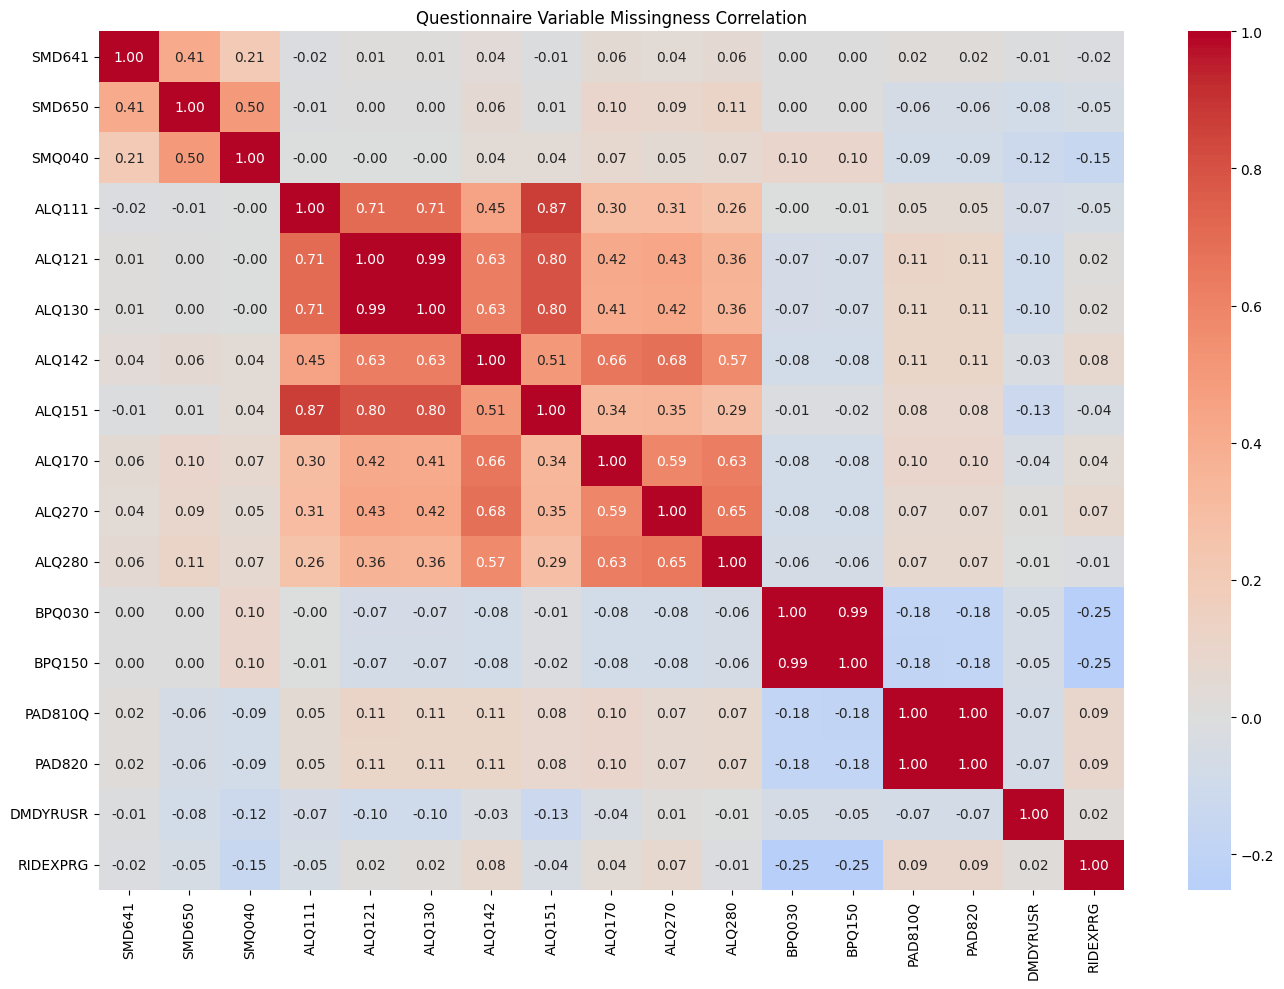

Questionnaire variables analyzed: 17


In [90]:
# Analyze missingness patterns in questionnaire variables

questionnaire_missingness = [
    "SMD641", "SMD650", "SMQ040",
    "ALQ111", "ALQ121", "ALQ130", "ALQ142",
    "ALQ151", "ALQ170", "ALQ270", "ALQ280",
    "BPQ030", "BPQ150", "PAD810Q", "PAD820",
    "DMDYRUSR", "RIDEXPRG"
]

questionnaire_missingness = [
    col for col in questionnaire_missingness
    if col in X.columns
]

questionnaire_missing_matrix = (
    X[questionnaire_missingness].isna().astype(int)
)

# Calculate pairwise missingness correlation
questionnaire_missing_correlation = (
    questionnaire_missing_matrix.corr()
)

display(questionnaire_missing_correlation.round(2))

# Visualize missingness relationships
plt.figure(figsize=(14, 10))

sns.heatmap(
    questionnaire_missing_correlation,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Questionnaire Variable Missingness Correlation")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "04_questionnaire_missingness_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save correlation results
questionnaire_missing_correlation.to_csv(
    TABLES_DIR / "19_questionnaire_missingness_correlation.csv"
)

print("Questionnaire variables analyzed:",
      len(questionnaire_missingness))

#### 8.30.6 Identify Strong Missingness Relationships

Identify pairs of questionnaire variables with strongly correlated missing-value patterns.

Use a correlation threshold of 0.80 to identify variables that may share questionnaire eligibility or skip patterns.

These relationships will be reviewed before selecting missing-value treatment methods. Correlation will be interpreted as an association rather than proof of structural missingness.

In [91]:
# Identify strongly correlated missingness patterns

correlation_threshold = 0.80

# Extract upper triangle to avoid duplicate pairs
upper_triangle = questionnaire_missing_correlation.where(
    np.triu(
        np.ones(questionnaire_missing_correlation.shape),
        k=1
    ).astype(bool)
)

strong_missingness_pairs = (
    upper_triangle.stack()
    .reset_index()
)

strong_missingness_pairs.columns = [
    "Variable_1",
    "Variable_2",
    "Missingness_Correlation"
]

strong_missingness_pairs = strong_missingness_pairs[
    strong_missingness_pairs["Missingness_Correlation"]
    >= correlation_threshold
].sort_values(
    "Missingness_Correlation",
    ascending=False
)

display(strong_missingness_pairs)

strong_missingness_pairs.to_csv(
    TABLES_DIR / "20_strong_missingness_relationships.csv",
    index=False
)

print("Strongly correlated variable pairs:",
      len(strong_missingness_pairs))

,Variable_1,Variable_2,Missingness_Correlation
130,PAD810Q,PAD820,0.999732
121,BPQ030,BPQ150,0.992589
58,ALQ121,ALQ130,0.991790
48,ALQ111,ALQ151,0.871105
60,ALQ121,ALQ151,0.802079


Strongly correlated variable pairs: 5


#### 8.30.7 Quantify Shared Missingness Between Questionnaire Variables

Calculate the number and percentage of participants with jointly missing values for strongly correlated questionnaire variable pairs.

Compare joint missingness with individual variable missingness to better understand shared missing-value patterns.

This analysis will provide additional evidence for reviewing questionnaire eligibility and potential skip patterns before selecting missing-value treatment methods.

In [92]:
# Quantify shared missingness for strongly correlated variable pairs

shared_missingness_results = []

for _, pair in strong_missingness_pairs.iterrows():

    variable_1 = pair["Variable_1"]
    variable_2 = pair["Variable_2"]

    missing_1 = X[variable_1].isna()
    missing_2 = X[variable_2].isna()

    both_missing = (missing_1 & missing_2).sum()
    only_first_missing = (missing_1 & ~missing_2).sum()
    only_second_missing = (~missing_1 & missing_2).sum()
    neither_missing = (~missing_1 & ~missing_2).sum()

    shared_missingness_results.append({
        "Variable_1": variable_1,
        "Variable_2": variable_2,
        "Missingness_Correlation": pair["Missingness_Correlation"],
        "Both_Missing_Count": both_missing,
        "Both_Missing_Percentage": round(
            both_missing / len(X) * 100, 2
        ),
        "Only_Variable_1_Missing": only_first_missing,
        "Only_Variable_2_Missing": only_second_missing,
        "Neither_Missing": neither_missing
    })

shared_missingness_df = pd.DataFrame(
    shared_missingness_results
)

display(shared_missingness_df)

shared_missingness_df.to_csv(
    TABLES_DIR / "21_shared_questionnaire_missingness.csv",
    index=False
)

print("Variable pairs analyzed:", len(shared_missingness_df))
print("Total participants analyzed:", len(X))

,Variable_1,Variable_2,Missingness_Correlation,Both_Missing_Count,Both_Missing_Percentage,Only_Variable_1_Missing,Only_Variable_2_Missing,Neither_Missing
0,PAD810Q,PAD820,0.999732,4168,55.31,1,0,3367
1,BPQ030,BPQ150,0.992589,4759,63.15,23,3,2751
2,ALQ121,ALQ130,0.991790,3712,49.26,4,27,3793
3,ALQ111,ALQ151,0.871105,2477,32.87,5,472,4582
4,ALQ121,ALQ151,0.802079,2929,38.87,787,20,3800


Variable pairs analyzed: 5
Total participants analyzed: 7536


#### 8.30.8 Classify Questionnaire Missingness Patterns

Classify strongly correlated questionnaire variable pairs based on their shared missing-value patterns.

Compare the number of participants with both variables missing against participants with only one variable missing.

Identify pairs with identical or nearly identical missingness patterns for further investigation.

These classifications will support decisions about questionnaire-related missing-value treatment.

In [93]:
# Classify shared questionnaire missingness patterns

shared_missingness_df["Missingness_Pattern"] = np.select(
    [
        (
            (shared_missingness_df["Only_Variable_1_Missing"] == 0) &
            (shared_missingness_df["Only_Variable_2_Missing"] == 0)
        ),
        (
            (shared_missingness_df["Only_Variable_1_Missing"] <= 10) &
            (shared_missingness_df["Only_Variable_2_Missing"] <= 10)
        )
    ],
    [
        "Identical missingness pattern",
        "Nearly identical missingness pattern"
    ],
    default="Partial shared missingness"
)

display(
    shared_missingness_df[
        [
            "Variable_1",
            "Variable_2",
            "Missingness_Correlation",
            "Both_Missing_Count",
            "Only_Variable_1_Missing",
            "Only_Variable_2_Missing",
            "Missingness_Pattern"
        ]
    ]
)

shared_missingness_df.to_csv(
    TABLES_DIR / "21_shared_questionnaire_missingness.csv",
    index=False
)

print("\nMissingness pattern classification:")
print(shared_missingness_df["Missingness_Pattern"].value_counts())

,Variable_1,Variable_2,Missingness_Correlation,Both_Missing_Count,Only_Variable_1_Missing,Only_Variable_2_Missing,Missingness_Pattern
0,PAD810Q,PAD820,0.999732,4168,1,0,Nearly identical missingness pattern
1,BPQ030,BPQ150,0.992589,4759,23,3,Partial shared missingness
2,ALQ121,ALQ130,0.991790,3712,4,27,Partial shared missingness
3,ALQ111,ALQ151,0.871105,2477,5,472,Partial shared missingness
4,ALQ121,ALQ151,0.802079,2929,787,20,Partial shared missingness



Missingness pattern classification:
Missingness_Pattern
Partial shared missingness              4
Nearly identical missingness pattern    1
Name: count, dtype: int64


#### 8.30.9 Create Questionnaire Missingness Review Summary

Summarize the strongly correlated questionnaire variable pairs and their shared missingness patterns.

Identify variable pairs that exhibit identical, nearly identical, or partial shared missingness.

Use this summary to guide further investigation of questionnaire eligibility and missing-value treatment decisions.

In [94]:
# Create questionnaire missingness review summary

questionnaire_review_summary = shared_missingness_df[
    [
        "Variable_1",
        "Variable_2",
        "Missingness_Correlation",
        "Both_Missing_Count",
        "Both_Missing_Percentage",
        "Only_Variable_1_Missing",
        "Only_Variable_2_Missing",
        "Missingness_Pattern"
    ]
].copy()

questionnaire_review_summary["Review_Decision"] = (
    "Retain both variables; investigate questionnaire skip patterns"
)

display(questionnaire_review_summary)

questionnaire_review_summary.to_csv(
    TABLES_DIR / "22_questionnaire_missingness_review_summary.csv",
    index=False
)

print("Variable pairs reviewed:",
      len(questionnaire_review_summary))
print("Summary saved successfully.")

,Variable_1,Variable_2,Missingness_Correlation,Both_Missing_Count,Both_Missing_Percentage,Only_Variable_1_Missing,Only_Variable_2_Missing,Missingness_Pattern,Review_Decision
0,PAD810Q,PAD820,0.999732,4168,55.31,1,0,Nearly identical missingness pattern,Retain both variables; investigate questionnai...
1,BPQ030,BPQ150,0.992589,4759,63.15,23,3,Partial shared missingness,Retain both variables; investigate questionnai...
2,ALQ121,ALQ130,0.991790,3712,49.26,4,27,Partial shared missingness,Retain both variables; investigate questionnai...
3,ALQ111,ALQ151,0.871105,2477,32.87,5,472,Partial shared missingness,Retain both variables; investigate questionnai...
4,ALQ121,ALQ151,0.802079,2929,38.87,787,20,Partial shared missingness,Retain both variables; investigate questionnai...


Variable pairs reviewed: 5
Summary saved successfully.


#### 8.30.10 Finalize Questionnaire Missingness Decisions

Consolidate the findings from questionnaire missingness correlation and shared missingness analysis.

Record provisional treatment decisions for strongly correlated variable pairs.

Retain questionnaire variables until their official NHANES eligibility rules and skip patterns have been verified.

Do not automatically impute or remove variables based solely on missingness correlation.

In [95]:
# Finalize provisional questionnaire missingness decisions

questionnaire_decisions = questionnaire_review_summary[
    [
        "Variable_1",
        "Variable_2",
        "Missingness_Correlation",
        "Both_Missing_Count",
        "Both_Missing_Percentage",
        "Missingness_Pattern"
    ]
].copy()

questionnaire_decisions["Retention_Decision"] = (
    "Retain both variables provisionally"
)

questionnaire_decisions["Imputation_Decision"] = (
    "Defer until eligibility and skip patterns are verified"
)

questionnaire_decisions["Verification_Status"] = (
    "Pending official NHANES codebook review"
)

display(questionnaire_decisions)

questionnaire_decisions.to_csv(
    TABLES_DIR / "23_questionnaire_missingness_decisions.csv",
    index=False
)

print("Variable pairs reviewed:", len(questionnaire_decisions))
print("Decisions recorded successfully.")

,Variable_1,Variable_2,Missingness_Correlation,Both_Missing_Count,Both_Missing_Percentage,Missingness_Pattern,Retention_Decision,Imputation_Decision,Verification_Status
0,PAD810Q,PAD820,0.999732,4168,55.31,Nearly identical missingness pattern,Retain both variables provisionally,Defer until eligibility and skip patterns are ...,Pending official NHANES codebook review
1,BPQ030,BPQ150,0.992589,4759,63.15,Partial shared missingness,Retain both variables provisionally,Defer until eligibility and skip patterns are ...,Pending official NHANES codebook review
2,ALQ121,ALQ130,0.991790,3712,49.26,Partial shared missingness,Retain both variables provisionally,Defer until eligibility and skip patterns are ...,Pending official NHANES codebook review
3,ALQ111,ALQ151,0.871105,2477,32.87,Partial shared missingness,Retain both variables provisionally,Defer until eligibility and skip patterns are ...,Pending official NHANES codebook review
4,ALQ121,ALQ151,0.802079,2929,38.87,Partial shared missingness,Retain both variables provisionally,Defer until eligibility and skip patterns are ...,Pending official NHANES codebook review


Variable pairs reviewed: 5
Decisions recorded successfully.


#### 8.30.11 Summarize Missing-Value Treatment Decisions

Summarize the missing-value treatment decisions developed during the questionnaire missingness analysis.

Consolidate the number of predictors requiring further investigation, numerical imputation review, categorical imputation review, and no imputation.

This summary will provide an overview of the proposed preprocessing strategy before missing values are treated.

In [96]:
# Summarize proposed missing-value treatment decisions

treatment_summary = (
    treatment_plan["Proposed_Treatment"]
    .value_counts()
    .reset_index()
)

treatment_summary.columns = [
    "Proposed_Treatment",
    "Number_of_Predictors"
]

treatment_summary["Percentage"] = (
    treatment_summary["Number_of_Predictors"]
    / len(treatment_plan) * 100
).round(2)

display(treatment_summary)

# Save treatment summary
treatment_summary.to_csv(
    TABLES_DIR / "24_missing_value_treatment_summary.csv",
    index=False
)

print("Total predictors reviewed:", len(treatment_plan))
print("Summary saved successfully.")

,Proposed_Treatment,Number_of_Predictors,Percentage
0,Investigate skip patterns and eligibility,17,33.33
1,Evaluate numerical median imputation,17,33.33
2,Evaluate categorical imputation,9,17.65
3,No imputation required,8,15.69


Total predictors reviewed: 51
Summary saved successfully.


#### 8.30.12 Save Missingness Analysis Checkpoint

Save the current working dataset after completing the missing-value analysis and treatment planning.

This checkpoint preserves the dataset before imputation and provides a reproducible reference for subsequent preprocessing.

The original integrated dataset remains unchanged.

In [97]:
# Save checkpoint before missing-value treatment

pre_imputation_file = (
    CLEANING_DIR / "checkpoint_08_before_missing_value_treatment.csv"
)

cleaning_df.to_csv(pre_imputation_file, index=False)

print("Pre-imputation checkpoint saved successfully.")
print("File:", pre_imputation_file)
print("Dataset shape:", cleaning_df.shape)
print("Total missing values:", cleaning_df.isna().sum().sum())

Pre-imputation checkpoint saved successfully.
File: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/data/processed/cleaning_checkpoints/checkpoint_08_before_missing_value_treatment.csv
Dataset shape: (7536, 57)
Total missing values: 118307


## 8.31 Final Data Cleaning Review

Perform a final review of the working dataset before completing the data-cleaning stage.

Verify dataset dimensions, duplicate participant identifiers, missing values, target variable integrity, and data types.

This review will help ensure that the dataset is consistent and ready for the final preprocessing decisions.

In [98]:
# Final data cleaning review

print("Dataset shape:", cleaning_df.shape)

print("\nDuplicate participant identifiers:")
print(cleaning_df["SEQN"].duplicated().sum())

print("\nTarget variable missing values:")
print(cleaning_df["DIABETES"].isna().sum())

print("\nTarget variable distribution:")
display(cleaning_df["DIABETES"].value_counts())

print("\nTarget variable percentages:")
display(
    (cleaning_df["DIABETES"].value_counts(normalize=True) * 100).round(2)
)

print("\nTotal missing values:")
print(cleaning_df.isna().sum().sum())

print("\nData types:")
display(cleaning_df.dtypes.value_counts())

Dataset shape: (7536, 57)

Duplicate participant identifiers:
0

Target variable missing values:
0

Target variable distribution:


DIABETES
0.0    6466
1.0    1070
Name: count, dtype: int64


Target variable percentages:


DIABETES
0.0    85.8
1.0    14.2
Name: proportion, dtype: float64


Total missing values:
118307

Data types:


float64    55
object      2
Name: count, dtype: int64

#### 8.31.1 Verify Missingness by Column

Review missing-value counts and percentages for every column in the working dataset.

Identify columns with high missingness and confirm that the target variable and participant identifiers remain complete.

This review will provide a final column-level missingness reference before the remaining preprocessing decisions.

In [99]:
# Final column-level missingness review

final_missingness_check = pd.DataFrame({
    "Missing_Count": cleaning_df.isna().sum(),
    "Missing_Percentage": (
        cleaning_df.isna().mean() * 100
    ).round(2)
})

final_missingness_check = final_missingness_check.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(final_missingness_check)

# Save final missingness report
final_missingness_check.to_csv(
    TABLES_DIR / "25_final_column_missingness_check.csv"
)

print("Total columns:", len(final_missingness_check))
print(
    "Columns with missing values:",
    (final_missingness_check["Missing_Count"] > 0).sum()
)
print(
    "Target missing values:",
    final_missingness_check.loc["DIABETES", "Missing_Count"]
)
print("Final missingness report saved.")

,Missing_Count,Missing_Percentage
SMD641,7313,97.04
ALQ280,6632,88.00
SMD650,6416,85.14
ALQ170,6394,84.85
ALQ270,6313,83.77
DMDYRUSR,6099,80.93
RIDEXPRG,6059,80.40
ALQ142,5345,70.93
BPQ030,4782,63.46
BPQ150,4762,63.19


Total columns: 57
Columns with missing values: 44
Target missing values: 0
Final missingness report saved.


#### 8.31.1 Verify Missingness by Column

Review missing-value counts and percentages for every column in the working dataset.

Identify columns with high missingness and confirm that the target variable and participant identifiers remain complete.

This review will provide a final column-level missingness reference before the remaining preprocessing decisions.

In [100]:
# Final column-level missingness review

final_missingness_check = pd.DataFrame({
    "Missing_Count": cleaning_df.isna().sum(),
    "Missing_Percentage": (
        cleaning_df.isna().mean() * 100
    ).round(2)
})

final_missingness_check = final_missingness_check.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(final_missingness_check)

# Save final missingness report
final_missingness_check.to_csv(
    TABLES_DIR / "25_final_column_missingness_check.csv"
)

print("Total columns:", len(final_missingness_check))
print(
    "Columns with missing values:",
    (final_missingness_check["Missing_Count"] > 0).sum()
)
print(
    "Target missing values:",
    final_missingness_check.loc["DIABETES", "Missing_Count"]
)
print("Final missingness report saved.")

,Missing_Count,Missing_Percentage
SMD641,7313,97.04
ALQ280,6632,88.00
SMD650,6416,85.14
ALQ170,6394,84.85
ALQ270,6313,83.77
DMDYRUSR,6099,80.93
RIDEXPRG,6059,80.40
ALQ142,5345,70.93
BPQ030,4782,63.46
BPQ150,4762,63.19


Total columns: 57
Columns with missing values: 44
Target missing values: 0
Final missingness report saved.


### 8.31.2 Identify Columns with No Missing Values

This step identifies columns that contain complete data and columns that still have missing values. This provides a final overview of dataset completeness before applying any missing-value treatment.

In [101]:
# Separate complete and incomplete columns
complete_columns = final_missingness_check[
    final_missingness_check["Missing_Count"] == 0
]

incomplete_columns = final_missingness_check[
    final_missingness_check["Missing_Count"] > 0
]

print("Columns with no missing values:", len(complete_columns))
print("Columns with missing values:", len(incomplete_columns))

print("\nColumns with no missing values:")
display(complete_columns)

print("\nColumns with missing values:")
display(incomplete_columns)

Columns with no missing values: 13
Columns with missing values: 44

Columns with no missing values:


,Missing_Count,Missing_Percentage
RIDRETH3,0,0.0
RIDAGEYR,0,0.0
RIAGENDR,0,0.0
RIDRETH1,0,0.0
PAD790U,0,0.0
DMDHHSIZ,0,0.0
WTINT2YR,0,0.0
PAD810U,0,0.0
SDMVSTRA,0,0.0
SDMVPSU,0,0.0



Columns with missing values:


,Missing_Count,Missing_Percentage
SMD641,7313,97.04
ALQ280,6632,88.00
SMD650,6416,85.14
ALQ170,6394,84.85
ALQ270,6313,83.77
DMDYRUSR,6099,80.93
RIDEXPRG,6059,80.40
ALQ142,5345,70.93
BPQ030,4782,63.46
BPQ150,4762,63.19


### 8.31.3 Missingness by Feature Category

This step compares missing values across numerical and categorical predictors. The purpose is to understand whether missingness is concentrated in a particular feature category and to support the selection of appropriate missing-value treatment methods.

In [102]:
# Compare missingness across numerical and categorical predictors

numerical_missing_count = X[numerical_features].isna().sum().sum()
categorical_missing_count = X[categorical_features].isna().sum().sum()

numerical_total_values = X[numerical_features].size
categorical_total_values = X[categorical_features].size

missingness_by_category = pd.DataFrame({
    "Feature_Category": ["Numerical", "Categorical"],
    "Number_of_Features": [
        len(numerical_features),
        len(categorical_features)
    ],
    "Missing_Values": [
        numerical_missing_count,
        categorical_missing_count
    ],
    "Total_Values": [
        numerical_total_values,
        categorical_total_values
    ]
})

missingness_by_category["Missing_Percentage"] = (
    missingness_by_category["Missing_Values"] /
    missingness_by_category["Total_Values"] * 100
).round(2)

display(missingness_by_category)

missingness_by_category.to_csv(
    TABLES_DIR / "26_missingness_by_feature_category.csv",
    index=False
)

print("Missingness by feature category saved.")

,Feature_Category,Number_of_Features,Missing_Values,Total_Values,Missing_Percentage
0,Numerical,28,79448,211008,37.65
1,Categorical,23,37166,173328,21.44


Missingness by feature category saved.


### 8.31.4 Visualize Missingness by Feature Category

A bar chart is used to compare the percentage of missing values in numerical and categorical predictors. This visualization provides a clear overview of missingness distribution across feature categories.

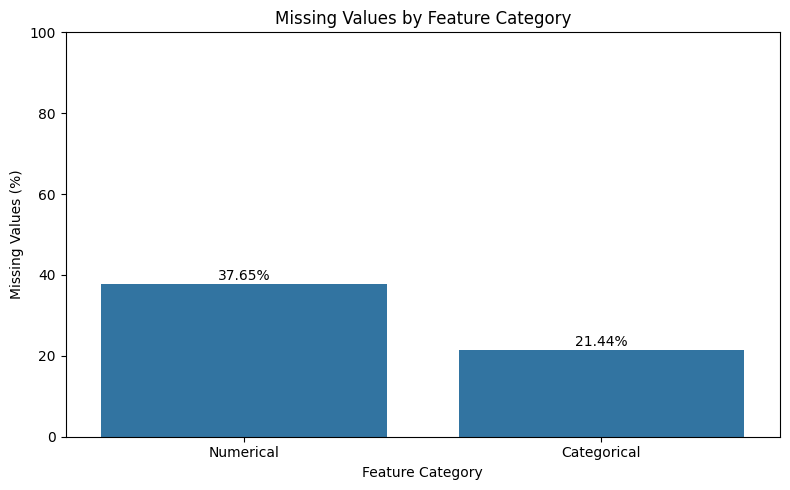

Missingness comparison chart saved.


In [103]:
# Visualize missingness by feature category

plt.figure(figsize=(8, 5))

sns.barplot(
    data=missingness_by_category,
    x="Feature_Category",
    y="Missing_Percentage"
)

plt.title("Missing Values by Feature Category")
plt.xlabel("Feature Category")
plt.ylabel("Missing Values (%)")
plt.ylim(0, 100)

for index, value in enumerate(missingness_by_category["Missing_Percentage"]):
    plt.text(index, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "05_missingness_by_feature_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Missingness comparison chart saved.")

### 8.31.5 Final Missingness Assessment

The missingness analysis shows that numerical predictors have a higher overall percentage of missing values (37.65%) compared with categorical predictors (21.44%).

A total of 44 out of 57 columns contain missing values. The target variable, DIABETES, has no missing values.

Variables with high missingness require further investigation because missing values may be associated with questionnaire skip patterns, participant eligibility, or other data collection conditions. Therefore, missing-value treatment will be determined only after reviewing the relevant variable documentation and eligibility rules.

In [104]:
# Create a final missingness assessment summary

final_missingness_assessment = pd.DataFrame({
    "Assessment": [
        "Total dataset columns",
        "Columns with missing values",
        "Columns without missing values",
        "Numerical predictors",
        "Categorical predictors",
        "Numerical missingness (%)",
        "Categorical missingness (%)",
        "Target missing values",
        "Predictors with more than 30% missingness"
    ],
    "Result": [
        len(cleaning_df.columns),
        len(incomplete_columns),
        len(complete_columns),
        len(numerical_features),
        len(categorical_features),
        missingness_by_category.loc[
            missingness_by_category["Feature_Category"] == "Numerical",
            "Missing_Percentage"
        ].iloc[0],
        missingness_by_category.loc[
            missingness_by_category["Feature_Category"] == "Categorical",
            "Missing_Percentage"
        ].iloc[0],
        cleaning_df["DIABETES"].isna().sum(),
        len(high_missing_predictors)
    ]
})

display(final_missingness_assessment)

final_missingness_assessment.to_csv(
    TABLES_DIR / "27_final_missingness_assessment.csv",
    index=False
)

print("Final missingness assessment saved.")

,Assessment,Result
0,Total dataset columns,57.00
1,Columns with missing values,44.00
2,Columns without missing values,13.00
3,Numerical predictors,28.00
4,Categorical predictors,23.00
5,Numerical missingness (%),37.65
6,Categorical missingness (%),21.44
7,Target missing values,0.00
8,Predictors with more than 30% missingness,17.00


Final missingness assessment saved.


## 8.32 Pre-Imputation Dataset Checkpoint

This section saves the current dataset before applying missing-value treatment. The checkpoint preserves the results of the completed cleaning and missingness analysis.

No missing values are imputed or removed in this step. The original integrated dataset remains unchanged.

In [105]:
# Save dataset before missing-value treatment

pre_imputation_file = (
    CLEANING_DIR / "checkpoint_09_pre_imputation.csv"
)

cleaning_df.to_csv(pre_imputation_file, index=False)

print("Pre-imputation checkpoint saved successfully.")
print("File:", pre_imputation_file)
print("Dataset shape:", cleaning_df.shape)
print("Total missing values:", cleaning_df.isna().sum().sum())
print("Target missing values:", cleaning_df["DIABETES"].isna().sum())

Pre-imputation checkpoint saved successfully.
File: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/data/processed/cleaning_checkpoints/checkpoint_09_pre_imputation.csv
Dataset shape: (7536, 57)
Total missing values: 118307
Target missing values: 0


## 8.33 NHANES Questionnaire Documentation Review

This section reviews questionnaire documentation for variables with high missingness. The purpose is to identify participant eligibility rules, questionnaire skip patterns, and special response codes before selecting an appropriate missing-value treatment strategy.

### 8.33.1 Smoking Questionnaire Variables

The smoking-related variables selected for review are SMD641, SMD650, and SMQ040. Their missingness patterns will be examined before deciding whether imputation is appropriate.

In [106]:
# Review missingness in smoking-related variables

smoking_review_variables = ["SMD641", "SMD650", "SMQ040"]

smoking_review = pd.DataFrame({
    "Variable": smoking_review_variables,
    "Missing_Count": [
        cleaning_df[col].isna().sum()
        for col in smoking_review_variables
    ],
    "Missing_Percentage": [
        round(cleaning_df[col].isna().mean() * 100, 2)
        for col in smoking_review_variables
    ],
    "Available_Count": [
        cleaning_df[col].notna().sum()
        for col in smoking_review_variables
    ]
})

display(smoking_review)

smoking_review.to_csv(
    TABLES_DIR / "28_smoking_variable_missingness_review.csv",
    index=False
)

print("Smoking variable review saved.")

,Variable,Missing_Count,Missing_Percentage,Available_Count
0,SMD641,7313,97.04,223
1,SMD650,6416,85.14,1120
2,SMQ040,4443,58.96,3093


Smoking variable review saved.


#### 8.33.1.1 Examine Smoking Questionnaire Skip Patterns

The smoking questionnaire uses conditional follow-up questions. This step examines the relationship between the initial smoking question (SMQ020), current smoking status (SMQ040), and the availability of detailed smoking responses (SMD641 and SMD650).

The purpose is to identify missingness patterns associated with questionnaire responses. No imputation or deletion will be performed at this stage.

In [107]:
# Examine smoking questionnaire response and missingness patterns

smoking_skip_review = pd.crosstab(
    cleaning_df["SMQ020"],
    cleaning_df["SMQ040"],
    margins=True,
    dropna=False
)

print("SMQ020 vs SMQ040 response counts:")
display(smoking_skip_review)

print("\nAvailability of detailed smoking variables by SMQ040:")
smoking_availability = cleaning_df.groupby(
    "SMQ040",
    dropna=False
)[["SMD641", "SMD650"]].agg(
    ["count", lambda x: x.isna().sum()]
)

smoking_availability.columns = [
    "SMD641_Available",
    "SMD641_Missing",
    "SMD650_Available",
    "SMD650_Missing"
]

display(smoking_availability)

smoking_skip_review.to_csv(
    TABLES_DIR / "29_smoking_skip_pattern_crosstab.csv"
)

smoking_availability.to_csv(
    TABLES_DIR / "30_smoking_availability_by_current_status.csv"
)

print("Smoking skip-pattern review saved.")

SMQ020 vs SMQ040 response counts:


SMQ040,1.0,2.0,3.0,NaN,All
SMQ020,,,,,
1.0,918,226,1949,0,3093.0
2.0,0,0,0,4416,4416.0
NaN,0,0,0,27,NaN
All,918,226,1949,0,7536.0



Availability of detailed smoking variables by SMQ040:


,SMD641_Available,SMD641_Missing,SMD650_Available,SMD650_Missing
SMQ040,,,,
1.0,12,906,911,7
2.0,211,15,209,17
3.0,0,1949,0,1949
NaN,0,4443,0,4443


Smoking skip-pattern review saved.


#### 8.33.1.2 Examine Detailed Smoking Variable Values

This step examines the observed response values and missingness in SMD641 and SMD650. The objective is to understand the available response categories and their distribution before determining the appropriate missing-value treatment.

In [108]:
# Examine response distributions of detailed smoking variables

detailed_smoking_variables = ["SMD641", "SMD650"]

for col in detailed_smoking_variables:
    print(f"\nResponse distribution for {col}:")
    print(cleaning_df[col].value_counts(dropna=False).sort_index())

    print(f"\nMissing percentage for {col}:")
    print(round(cleaning_df[col].isna().mean() * 100, 2), "%")

# Compare detailed smoking variable availability by SMQ020
print("\nAvailability by SMQ020 response:")

smoking_detailed_by_initial = cleaning_df.groupby(
    "SMQ020",
    dropna=False
)[["SMD641", "SMD650"]].agg(
    ["count", lambda x: x.isna().sum()]
)

display(smoking_detailed_by_initial)


Response distribution for SMD641:
SMD641
1.0       10
2.0       21
3.0       20
4.0        6
5.0        9
6.0        6
7.0        3
8.0        9
10.0      29
12.0      12
14.0       3
15.0      34
17.0       1
18.0       1
20.0      32
22.0       1
23.0       1
25.0       8
27.0       2
28.0       2
29.0       1
30.0      12
NaN     7313
Name: count, dtype: int64

Missing percentage for SMD641:
97.04 %

Response distribution for SMD650:
SMD650
1.0       87
2.0       77
3.0       54
4.0       53
5.0       94
6.0       53
7.0       42
8.0       29
9.0        4
10.0     206
11.0       5
12.0      33
13.0       2
15.0      85
16.0       6
17.0       1
18.0       4
20.0     200
21.0       1
24.0       2
25.0      14
26.0       1
28.0       1
30.0      31
38.0       1
40.0      26
50.0       2
60.0       3
90.0       1
95.0       2
NaN     6416
Name: count, dtype: int64

Missing percentage for SMD650:
85.14 %

Availability by SMQ020 response:


SMD641            SMD650           
        count <lambda_0>  count <lambda_0>
SMQ020                                    
1.0       223       2870   1120       1973
2.0         0       4416      0       4416
NaN         0         27      0         27

#### 8.33.1.3 Smoking Variable Retention and Treatment Review

This step consolidates the missingness and response-distribution findings for the smoking-related variables.

Variables are retained provisionally while their questionnaire eligibility rules and response codes are reviewed. No imputation or feature deletion is performed at this stage.

In [109]:
# Consolidate smoking variable review findings

smoking_decisions = pd.DataFrame({
    "Variable": ["SMQ020", "SMQ040", "SMD641", "SMD650"],
    "Missing_Count": [
        cleaning_df[col].isna().sum()
        for col in ["SMQ020", "SMQ040", "SMD641", "SMD650"]
    ],
    "Missing_Percentage": [
        round(cleaning_df[col].isna().mean() * 100, 2)
        for col in ["SMQ020", "SMQ040", "SMD641", "SMD650"]
    ],
    "Retention_Decision": [
        "Retain provisionally",
        "Retain provisionally",
        "Retain provisionally",
        "Retain provisionally"
    ],
    "Treatment_Decision": [
        "Verify response codes and missingness",
        "Investigate questionnaire skip pattern",
        "Verify eligibility and response codes",
        "Verify eligibility and response codes"
    ],
    "Verification_Status": [
        "Official documentation review required",
        "Official documentation review required",
        "Official documentation review required",
        "Official documentation review required"
    ]
})

display(smoking_decisions)

smoking_decisions.to_csv(
    TABLES_DIR / "31_smoking_variable_retention_decisions.csv",
    index=False
)

print("Smoking variable retention review saved.")

,Variable,Missing_Count,Missing_Percentage,Retention_Decision,Treatment_Decision,Verification_Status
0,SMQ020,27,0.36,Retain provisionally,Verify response codes and missingness,Official documentation review required
1,SMQ040,4443,58.96,Retain provisionally,Investigate questionnaire skip pattern,Official documentation review required
2,SMD641,7313,97.04,Retain provisionally,Verify eligibility and response codes,Official documentation review required
3,SMD650,6416,85.14,Retain provisionally,Verify eligibility and response codes,Official documentation review required


Smoking variable retention review saved.


### 8.33.2 Alcohol Questionnaire Variables

This section examines missingness in the alcohol-related NHANES questionnaire variables. The analysis focuses on response availability and missingness patterns across the eight selected variables.

The purpose is to identify potential questionnaire skip patterns and determine which variables require further documentation review before missing-value treatment.

In [110]:
# Review missingness in alcohol-related variables

alcohol_review_variables = [
    "ALQ111", "ALQ121", "ALQ130", "ALQ142",
    "ALQ151", "ALQ170", "ALQ270", "ALQ280"
]

alcohol_review = pd.DataFrame({
    "Variable": alcohol_review_variables,
    "Missing_Count": [
        cleaning_df[col].isna().sum()
        for col in alcohol_review_variables
    ],
    "Missing_Percentage": [
        round(cleaning_df[col].isna().mean() * 100, 2)
        for col in alcohol_review_variables
    ],
    "Available_Count": [
        cleaning_df[col].notna().sum()
        for col in alcohol_review_variables
    ]
})

display(alcohol_review)

alcohol_review.to_csv(
    TABLES_DIR / "32_alcohol_variable_missingness_review.csv",
    index=False
)

print("Alcohol variable review saved.")

,Variable,Missing_Count,Missing_Percentage,Available_Count
0,ALQ111,2482,32.94,5054
1,ALQ121,3716,49.31,3820
2,ALQ130,3739,49.62,3797
3,ALQ142,5345,70.93,2191
4,ALQ151,2949,39.13,4587
5,ALQ170,6394,84.85,1142
6,ALQ270,6313,83.77,1223
7,ALQ280,6632,88.00,904


Alcohol variable review saved.


#### 8.33.2.1 Examine Alcohol Variable Response Distributions

This step examines the observed response values for the eight alcohol-related variables. The response distributions and missingness will be reviewed to identify patterns that may require further investigation.

Response codes will not be interpreted or recoded in this step. Their meanings and eligibility rules must be verified using the official NHANES documentation.

In [111]:
# Examine response distributions of alcohol-related variables

for col in alcohol_review_variables:
    print(f"\nResponse distribution for {col}:")
    print(
        cleaning_df[col]
        .value_counts(dropna=False)
        .sort_index()
    )

    print(
        f"Missing percentage: "
        f"{cleaning_df[col].isna().mean() * 100:.2f}%"
    )


Response distribution for ALQ111:
ALQ111
1.0    4607
2.0     447
NaN    2482
Name: count, dtype: int64
Missing percentage: 32.94%

Response distribution for ALQ121:
ALQ121
1.0      157
2.0      291
3.0      440
4.0      468
5.0      407
6.0      537
7.0      331
8.0      239
9.0      472
10.0     478
NaN     3716
Name: count, dtype: int64
Missing percentage: 49.31%

Response distribution for ALQ130:
ALQ130
1.0     1276
2.0     1236
3.0      560
4.0      228
5.0      195
6.0      131
7.0       15
8.0       39
9.0       15
10.0      27
11.0       4
12.0      50
14.0       2
15.0      19
NaN     3739
Name: count, dtype: int64
Missing percentage: 49.62%

Response distribution for ALQ142:
ALQ142
1.0       38
2.0       58
3.0      117
4.0      111
5.0      198
6.0      228
7.0      268
8.0      132
9.0      367
10.0     674
NaN     5345
Name: count, dtype: int64
Missing percentage: 70.93%

Response distribution for ALQ151:
ALQ151
1.0     860
2.0    3727
NaN    2949
Name: count, dtype: int64

#### 8.33.2.2 Examine Alcohol Questionnaire Missingness Patterns

This step examines whether missing values occur together across alcohol-related questionnaire variables. Pairwise missingness correlations will help identify variables with similar missingness patterns.

These correlations indicate co-occurrence of missing values and do not independently establish questionnaire skip logic or participant eligibility.

,ALQ111,ALQ121,ALQ130,ALQ142,ALQ151,ALQ170,ALQ270,ALQ280
ALQ111,1.000000,0.709957,0.705632,0.448052,0.871105,0.296162,0.307680,0.257860
ALQ121,0.709957,1.000000,0.991790,0.629718,0.802079,0.415344,0.431952,0.362506
ALQ130,0.705632,0.991790,1.000000,0.625402,0.798219,0.411235,0.423814,0.356568
ALQ142,0.448052,0.629718,0.625402,1.000000,0.505574,0.656825,0.679536,0.570357
ALQ151,0.871105,0.802079,0.798219,0.505574,1.000000,0.338860,0.349227,0.293519
ALQ170,0.296162,0.415344,0.411235,0.656825,0.338860,1.000000,0.591831,0.631003
ALQ270,0.307680,0.431952,0.423814,0.679536,0.349227,0.591831,1.000000,0.649407
ALQ280,0.257860,0.362506,0.356568,0.570357,0.293519,0.631003,0.649407,1.000000


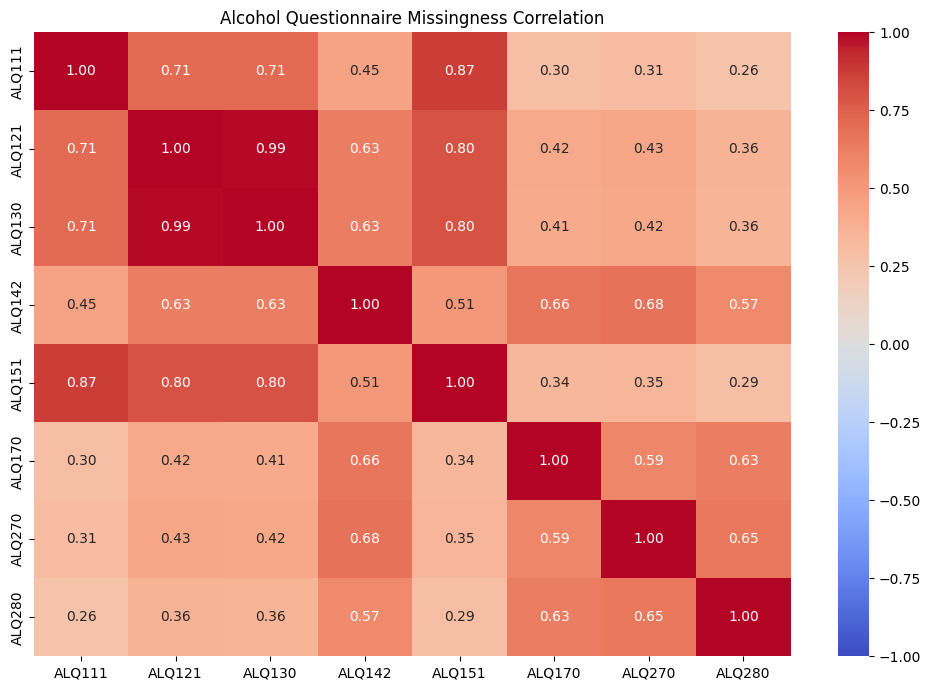

Alcohol missingness correlation saved.


In [112]:
# Examine missingness correlation among alcohol variables

alcohol_missing_matrix = (
    cleaning_df[alcohol_review_variables]
    .isna()
    .astype(int)
)

alcohol_missing_correlation = alcohol_missing_matrix.corr()

display(alcohol_missing_correlation)

# Visualize missingness correlations
plt.figure(figsize=(10, 7))

sns.heatmap(
    alcohol_missing_correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Alcohol Questionnaire Missingness Correlation")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "06_alcohol_missingness_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

alcohol_missing_correlation.to_csv(
    TABLES_DIR / "33_alcohol_missingness_correlation.csv"
)

print("Alcohol missingness correlation saved.")

#### 8.33.2.3 Identify Strong Missingness Relationships

This step identifies pairs of alcohol-related variables with a missingness correlation of 0.80 or higher.

The selected pairs will be examined to determine how frequently both variables are missing, how frequently only one variable is missing, and how frequently neither variable is missing.

These results will support further investigation of questionnaire eligibility and skip patterns.

In [113]:
# Identify strong alcohol missingness correlations

correlation_threshold = 0.80

upper_triangle = alcohol_missing_correlation.where(
    np.triu(
        np.ones(alcohol_missing_correlation.shape),
        k=1
    ).astype(bool)
)

strong_alcohol_missingness_pairs = (
    upper_triangle.stack()
    .reset_index()
)

strong_alcohol_missingness_pairs.columns = [
    "Variable_1",
    "Variable_2",
    "Missingness_Correlation"
]

strong_alcohol_missingness_pairs = (
    strong_alcohol_missingness_pairs[
        strong_alcohol_missingness_pairs[
            "Missingness_Correlation"
        ] >= correlation_threshold
    ]
    .sort_values(
        "Missingness_Correlation",
        ascending=False
    )
    .reset_index(drop=True)
)

display(strong_alcohol_missingness_pairs)

strong_alcohol_missingness_pairs.to_csv(
    TABLES_DIR / "34_strong_alcohol_missingness_pairs.csv",
    index=False
)

print(
    "Number of strong missingness pairs:",
    len(strong_alcohol_missingness_pairs)
)

print("Strong alcohol missingness pairs saved.")

,Variable_1,Variable_2,Missingness_Correlation
0,ALQ121,ALQ130,0.991790
1,ALQ111,ALQ151,0.871105
2,ALQ121,ALQ151,0.802079


Number of strong missingness pairs: 3
Strong alcohol missingness pairs saved.


#### 8.33.2.4 Calculate Shared Missingness

This step examines the three strongly correlated alcohol-variable pairs. It calculates the number of participants for whom both variables are missing, only the first variable is missing, only the second variable is missing, or neither variable is missing.

This comparison provides additional evidence about the relationship between missingness patterns. It does not independently confirm questionnaire eligibility or skip logic.

In [114]:
# Calculate shared missingness for strong alcohol variable pairs

shared_alcohol_missingness = []

for _, pair in strong_alcohol_missingness_pairs.iterrows():

    variable_1 = pair["Variable_1"]
    variable_2 = pair["Variable_2"]

    missing_1 = cleaning_df[variable_1].isna()
    missing_2 = cleaning_df[variable_2].isna()

    shared_alcohol_missingness.append({
        "Variable_1": variable_1,
        "Variable_2": variable_2,
        "Missingness_Correlation": pair["Missingness_Correlation"],
        "Both_Missing": (missing_1 & missing_2).sum(),
        "Only_Variable_1_Missing": (missing_1 & ~missing_2).sum(),
        "Only_Variable_2_Missing": (~missing_1 & missing_2).sum(),
        "Neither_Missing": (~missing_1 & ~missing_2).sum()
    })

shared_alcohol_missingness_df = pd.DataFrame(
    shared_alcohol_missingness
)

display(shared_alcohol_missingness_df)

shared_alcohol_missingness_df.to_csv(
    TABLES_DIR / "35_shared_alcohol_missingness.csv",
    index=False
)

print("Shared alcohol missingness analysis saved.")

,Variable_1,Variable_2,Missingness_Correlation,Both_Missing,Only_Variable_1_Missing,Only_Variable_2_Missing,Neither_Missing
0,ALQ121,ALQ130,0.991790,3712,4,27,3793
1,ALQ111,ALQ151,0.871105,2477,5,472,4582
2,ALQ121,ALQ151,0.802079,2929,787,20,3800


Shared alcohol missingness analysis saved.


#### 8.33.2.5 Classify Alcohol Missingness Patterns

This step classifies the identified alcohol-variable pairs according to their shared missingness counts.

Pairs with no differences in missingness status are classified as having identical missingness. Pairs with relatively few differences are classified as having nearly identical missingness. Other pairs are classified as having partial shared missingness.

These classifications describe observed data patterns and do not establish the official questionnaire skip logic.

In [115]:
# Classify alcohol missingness patterns

shared_alcohol_missingness_df["Missingness_Pattern"] = np.select(
    [
        (
            (shared_alcohol_missingness_df["Only_Variable_1_Missing"] == 0) &
            (shared_alcohol_missingness_df["Only_Variable_2_Missing"] == 0)
        ),
        (
            (shared_alcohol_missingness_df["Only_Variable_1_Missing"] <= 10) &
            (shared_alcohol_missingness_df["Only_Variable_2_Missing"] <= 10)
        )
    ],
    [
        "Identical missingness pattern",
        "Nearly identical missingness pattern"
    ],
    default="Partial shared missingness"
)

display(shared_alcohol_missingness_df)

shared_alcohol_missingness_df.to_csv(
    TABLES_DIR / "36_classified_alcohol_missingness_patterns.csv",
    index=False
)

print("Alcohol missingness pattern classification saved.")

,Variable_1,Variable_2,Missingness_Correlation,Both_Missing,Only_Variable_1_Missing,Only_Variable_2_Missing,Neither_Missing,Missingness_Pattern
0,ALQ121,ALQ130,0.991790,3712,4,27,3793,Partial shared missingness
1,ALQ111,ALQ151,0.871105,2477,5,472,4582,Partial shared missingness
2,ALQ121,ALQ151,0.802079,2929,787,20,3800,Partial shared missingness


Alcohol missingness pattern classification saved.


#### 8.33.2.6 Alcohol Variable Retention and Treatment Decisions

This step consolidates the missingness analysis and response-distribution findings for the eight alcohol-related variables.

All variables will be retained provisionally until their official NHANES questionnaire descriptions, response codes, and participant eligibility rules are verified.

No automatic feature deletion or missing-value imputation will be performed at this stage.

In [116]:
# Consolidate alcohol variable retention and treatment decisions

alcohol_decisions = alcohol_review.copy()

alcohol_decisions["Retention_Decision"] = (
    "Retain provisionally"
)

alcohol_decisions["Treatment_Decision"] = (
    "Verify questionnaire eligibility and skip patterns"
)

alcohol_decisions["Verification_Status"] = (
    "Official NHANES documentation review required"
)

display(alcohol_decisions)

alcohol_decisions.to_csv(
    TABLES_DIR / "37_alcohol_variable_retention_decisions.csv",
    index=False
)

print("Alcohol variable retention decisions saved.")

,Variable,Missing_Count,Missing_Percentage,Available_Count,Retention_Decision,Treatment_Decision,Verification_Status
0,ALQ111,2482,32.94,5054,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required
1,ALQ121,3716,49.31,3820,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required
2,ALQ130,3739,49.62,3797,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required
3,ALQ142,5345,70.93,2191,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required
4,ALQ151,2949,39.13,4587,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required
5,ALQ170,6394,84.85,1142,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required
6,ALQ270,6313,83.77,1223,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required
7,ALQ280,6632,88.00,904,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required


Alcohol variable retention decisions saved.


### 8.33.3 Blood Pressure Questionnaire Variables

This section examines missingness in the blood pressure questionnaire variables. The analysis focuses on response availability and missingness patterns to identify potential questionnaire eligibility rules and conditional follow-up questions.

No missing-value imputation or feature deletion will be performed during this review.

In [117]:
# Review missingness in blood pressure questionnaire variables

bp_review_variables = ["BPQ030", "BPQ150"]

bp_review = pd.DataFrame({
    "Variable": bp_review_variables,
    "Missing_Count": [
        cleaning_df[col].isna().sum()
        for col in bp_review_variables
    ],
    "Missing_Percentage": [
        round(cleaning_df[col].isna().mean() * 100, 2)
        for col in bp_review_variables
    ],
    "Available_Count": [
        cleaning_df[col].notna().sum()
        for col in bp_review_variables
    ]
})

display(bp_review)

bp_review.to_csv(
    TABLES_DIR / "38_blood_pressure_variable_missingness_review.csv",
    index=False
)

print("Blood pressure variable review saved.")

,Variable,Missing_Count,Missing_Percentage,Available_Count
0,BPQ030,4782,63.46,2754
1,BPQ150,4762,63.19,2774


Blood pressure variable review saved.


#### 8.33.3.1 Examine Blood Pressure Response Distributions

This step examines the observed response values for BPQ030 and BPQ150. The response distributions will help identify the available response categories and support further investigation of potential questionnaire skip patterns.

Response codes will not be interpreted or recoded until their meanings are verified using official NHANES documentation.

In [118]:
# Examine response distributions of blood pressure variables

for col in bp_review_variables:
    print(f"\nResponse distribution for {col}:")
    print(
        cleaning_df[col]
        .value_counts(dropna=False)
        .sort_index()
    )

    print(
        f"Missing percentage: "
        f"{cleaning_df[col].isna().mean() * 100:.2f}%"
    )


Response distribution for BPQ030:
BPQ030
1.0    2319
2.0     435
NaN    4782
Name: count, dtype: int64
Missing percentage: 63.46%

Response distribution for BPQ150:
BPQ150
1.0    2305
2.0     469
NaN    4762
Name: count, dtype: int64
Missing percentage: 63.19%


#### 8.33.3.2 Examine Blood Pressure Missingness Patterns

This step examines whether missing values in BPQ030 and BPQ150 occur together. A missingness correlation and a cross-tabulation will be used to compare their missing and available observations.

The analysis describes observed missingness patterns but does not independently establish questionnaire skip logic.

In [119]:
# Examine blood pressure questionnaire missingness patterns

bp_missing_matrix = (
    cleaning_df[bp_review_variables]
    .isna()
    .astype(int)
)

bp_missing_correlation = bp_missing_matrix.corr()

print("Blood pressure missingness correlation:")
display(bp_missing_correlation)

print("\nMissingness pattern cross-tabulation:")

bp_missing_crosstab = pd.crosstab(
    cleaning_df["BPQ030"].isna(),
    cleaning_df["BPQ150"].isna(),
    rownames=["BPQ030 Missing"],
    colnames=["BPQ150 Missing"],
    margins=True
)

display(bp_missing_crosstab)

bp_missing_correlation.to_csv(
    TABLES_DIR / "39_blood_pressure_missingness_correlation.csv"
)

bp_missing_crosstab.to_csv(
    TABLES_DIR / "40_blood_pressure_missingness_crosstab.csv"
)

print("Blood pressure missingness analysis saved.")

Blood pressure missingness correlation:


,BPQ030,BPQ150
BPQ030,1.000000,0.992589
BPQ150,0.992589,1.000000



Missingness pattern cross-tabulation:


BPQ150 Missing,False,True,All
BPQ030 Missing,,,
False,2751,3,2754
True,23,4759,4782
All,2774,4762,7536


Blood pressure missingness analysis saved.


#### 8.33.3.3 Blood Pressure Variable Retention Decisions

This step consolidates the missingness analysis and response-distribution findings for BPQ030 and BPQ150.

Both variables will be retained provisionally because they may provide useful information about participants' blood pressure history. Their questionnaire eligibility and skip patterns must be verified before selecting a missing-value treatment strategy.

No imputation or feature deletion will be performed at this stage.

In [120]:
# Consolidate blood pressure variable retention decisions

bp_decisions = bp_review.copy()

bp_decisions["Retention_Decision"] = (
    "Retain provisionally"
)

bp_decisions["Treatment_Decision"] = (
    "Investigate questionnaire skip patterns"
)

bp_decisions["Verification_Status"] = (
    "Official NHANES documentation review required"
)

display(bp_decisions)

bp_decisions.to_csv(
    TABLES_DIR / "41_blood_pressure_variable_retention_decisions.csv",
    index=False
)

print("Blood pressure variable retention decisions saved.")

,Variable,Missing_Count,Missing_Percentage,Available_Count,Retention_Decision,Treatment_Decision,Verification_Status
0,BPQ030,4782,63.46,2754,Retain provisionally,Investigate questionnaire skip patterns,Official NHANES documentation review required
1,BPQ150,4762,63.19,2774,Retain provisionally,Investigate questionnaire skip patterns,Official NHANES documentation review required


Blood pressure variable retention decisions saved.


### 8.33.4 Physical Activity Questionnaire Variables

This section examines missingness in the physical activity-related NHANES questionnaire variables. The analysis focuses on response availability and missingness patterns for PAD810Q and PAD820.

The purpose is to identify potential questionnaire skip patterns and determine whether further investigation is needed before missing-value treatment.

In [121]:
# Review missingness in physical activity variables

physical_activity_variables = ["PAD810Q", "PAD820"]

physical_activity_review = pd.DataFrame({
    "Variable": physical_activity_variables,
    "Missing_Count": [
        cleaning_df[col].isna().sum()
        for col in physical_activity_variables
    ],
    "Missing_Percentage": [
        round(cleaning_df[col].isna().mean() * 100, 2)
        for col in physical_activity_variables
    ],
    "Available_Count": [
        cleaning_df[col].notna().sum()
        for col in physical_activity_variables
    ]
})

display(physical_activity_review)

physical_activity_review.to_csv(
    TABLES_DIR / "42_physical_activity_missingness_review.csv",
    index=False
)

print("Physical activity missingness review saved.")

,Variable,Missing_Count,Missing_Percentage,Available_Count
0,PAD810Q,4169,55.32,3367
1,PAD820,4168,55.31,3368


Physical activity missingness review saved.


#### 8.33.4.1 Examine Physical Activity Response Distributions

This step examines the observed response values for PAD810Q and PAD820. The response distributions will help identify available response categories and support further investigation of potential questionnaire skip patterns.

Response codes will not be interpreted or recoded until their meanings are verified using official NHANES documentation.

In [122]:
# Examine response distributions of physical activity variables

for col in physical_activity_variables:
    print(f"\nResponse distribution for {col}:")
    print(
        cleaning_df[col]
        .value_counts(dropna=False)
        .sort_index()
    )

    print(
        f"Missing percentage: "
        f"{cleaning_df[col].isna().mean() * 100:.2f}%"
    )


Response distribution for PAD810Q:
PAD810Q
1.0      1174
2.0       966
3.0       589
4.0       273
5.0       186
6.0        73
7.0        76
8.0         4
9.0         2
10.0        8
12.0        1
15.0        4
20.0        1
22.0        1
23.0        1
24.0        2
30.0        2
31.0        1
84.0        1
90.0        1
200.0       1
NaN      4169
Name: count, dtype: int64
Missing percentage: 55.32%

Response distribution for PAD820:
PAD820
1.0         12
2.0          2
3.0          6
4.0          2
5.0         33
6.0          2
7.0          1
8.0          2
10.0        98
12.0         4
15.0       177
20.0       202
25.0        24
30.0       831
32.0         1
35.0        11
40.0        63
45.0       246
46.0         1
50.0        18
55.0         3
60.0       973
70.0         5
75.0        13
90.0       128
100.0        2
105.0        2
120.0      321
150.0        4
180.0       85
240.0       42
300.0       17
360.0       10
420.0        1
480.0        8
540.0        1
600.0        

#### 8.33.4.2 Examine Physical Activity Missingness Patterns

This step examines whether missing values in PAD810Q and PAD820 occur together. A missingness correlation and cross-tabulation will be used to compare their missing and available observations.

The analysis describes observed missingness patterns but does not independently establish questionnaire eligibility or skip logic.

In [123]:
# Examine physical activity missingness patterns

physical_activity_missing_matrix = (
    cleaning_df[physical_activity_variables]
    .isna()
    .astype(int)
)

physical_activity_missing_correlation = (
    physical_activity_missing_matrix.corr()
)

print("Physical activity missingness correlation:")
display(physical_activity_missing_correlation)

print("\nMissingness pattern cross-tabulation:")

physical_activity_missing_crosstab = pd.crosstab(
    cleaning_df["PAD810Q"].isna(),
    cleaning_df["PAD820"].isna(),
    rownames=["PAD810Q Missing"],
    colnames=["PAD820 Missing"],
    margins=True
)

display(physical_activity_missing_crosstab)

physical_activity_missing_correlation.to_csv(
    TABLES_DIR / "43_physical_activity_missingness_correlation.csv"
)

physical_activity_missing_crosstab.to_csv(
    TABLES_DIR / "44_physical_activity_missingness_crosstab.csv"
)

print("Physical activity missingness analysis saved.")

Physical activity missingness correlation:


,PAD810Q,PAD820
PAD810Q,1.000000,0.999732
PAD820,0.999732,1.000000



Missingness pattern cross-tabulation:


PAD820 Missing,False,True,All
PAD810Q Missing,,,
False,3367,0,3367
True,1,4168,4169
All,3368,4168,7536


Physical activity missingness analysis saved.


#### 8.33.4.3 Physical Activity Variable Retention Decisions

This step consolidates the missingness analysis and response-distribution findings for PAD810Q and PAD820.

Both variables will be retained provisionally because they may provide useful physical activity information. Their questionnaire eligibility rules and special response codes must be verified before selecting a missing-value treatment strategy.

No imputation or feature deletion will be performed at this stage.

In [124]:
# Consolidate physical activity variable retention decisions

physical_activity_decisions = physical_activity_review.copy()

physical_activity_decisions["Retention_Decision"] = (
    "Retain provisionally"
)

physical_activity_decisions["Treatment_Decision"] = (
    "Investigate questionnaire eligibility and skip patterns"
)

physical_activity_decisions["Verification_Status"] = (
    "Official NHANES documentation review required"
)

display(physical_activity_decisions)

physical_activity_decisions.to_csv(
    TABLES_DIR / "45_physical_activity_retention_decisions.csv",
    index=False
)

print("Physical activity retention decisions saved.")

,Variable,Missing_Count,Missing_Percentage,Available_Count,Retention_Decision,Treatment_Decision,Verification_Status
0,PAD810Q,4169,55.32,3367,Retain provisionally,Investigate questionnaire eligibility and skip...,Official NHANES documentation review required
1,PAD820,4168,55.31,3368,Retain provisionally,Investigate questionnaire eligibility and skip...,Official NHANES documentation review required


Physical activity retention decisions saved.


### 8.33.5 Demographic Questionnaire Variables

This section examines missingness in selected demographic variables, DMDYRUSR and RIDEXPRG.

The analysis focuses on response availability and missingness patterns. Participant eligibility and questionnaire routing will be investigated before determining an appropriate missing-value treatment strategy.

In [125]:
# Review missingness in demographic variables

demographic_review_variables = ["DMDYRUSR", "RIDEXPRG"]

demographic_review = pd.DataFrame({
    "Variable": demographic_review_variables,
    "Missing_Count": [
        cleaning_df[col].isna().sum()
        for col in demographic_review_variables
    ],
    "Missing_Percentage": [
        round(cleaning_df[col].isna().mean() * 100, 2)
        for col in demographic_review_variables
    ],
    "Available_Count": [
        cleaning_df[col].notna().sum()
        for col in demographic_review_variables
    ]
})

display(demographic_review)

demographic_review.to_csv(
    TABLES_DIR / "46_demographic_variable_missingness_review.csv",
    index=False
)

print("Demographic variable review saved.")

,Variable,Missing_Count,Missing_Percentage,Available_Count
0,DMDYRUSR,6099,80.93,1437
1,RIDEXPRG,6059,80.40,1477


Demographic variable review saved.


#### 8.33.5.1 Examine Demographic Response Distributions

This step examines the observed response values for DMDYRUSR and RIDEXPRG. The response distributions will help identify available response categories and support further investigation of participant eligibility and questionnaire routing.

Response codes will not be interpreted or recoded until their meanings are verified using official NHANES documentation.

In [126]:
# Examine response distributions of demographic variables

for col in demographic_review_variables:
    print(f"\nResponse distribution for {col}:")
    print(
        cleaning_df[col]
        .value_counts(dropna=False)
        .sort_index()
    )

    print(
        f"Missing percentage: "
        f"{cleaning_df[col].isna().mean() * 100:.2f}%"
    )


Response distribution for DMDYRUSR:
DMDYRUSR
1.0      60
2.0     140
3.0     141
4.0     111
5.0     139
6.0     846
NaN    6099
Name: count, dtype: int64
Missing percentage: 80.93%

Response distribution for RIDEXPRG:
RIDEXPRG
1.0      41
2.0    1045
3.0     391
NaN    6059
Name: count, dtype: int64
Missing percentage: 80.40%


#### 8.33.5.2 Examine Demographic Missingness Patterns

This step examines whether missing values in DMDYRUSR and RIDEXPRG occur together. Missingness correlation and cross-tabulation will be used to compare their missing and available observations.

The analysis describes observed missingness patterns but does not independently establish participant eligibility or questionnaire skip logic.

In [127]:
# Examine demographic missingness patterns

demographic_missing_matrix = (
    cleaning_df[demographic_review_variables]
    .isna()
    .astype(int)
)

demographic_missing_correlation = (
    demographic_missing_matrix.corr()
)

print("Demographic missingness correlation:")
display(demographic_missing_correlation)

print("\nMissingness pattern cross-tabulation:")

demographic_missing_crosstab = pd.crosstab(
    cleaning_df["DMDYRUSR"].isna(),
    cleaning_df["RIDEXPRG"].isna(),
    rownames=["DMDYRUSR Missing"],
    colnames=["RIDEXPRG Missing"],
    margins=True
)

display(demographic_missing_crosstab)

demographic_missing_correlation.to_csv(
    TABLES_DIR / "47_demographic_missingness_correlation.csv"
)

demographic_missing_crosstab.to_csv(
    TABLES_DIR / "48_demographic_missingness_crosstab.csv"
)

print("Demographic missingness analysis saved.")

Demographic missingness correlation:


,DMDYRUSR,RIDEXPRG
DMDYRUSR,1.000000,0.019026
RIDEXPRG,0.019026,1.000000



Missingness pattern cross-tabulation:


RIDEXPRG Missing,False,True,All
DMDYRUSR Missing,,,
False,304,1133,1437
True,1173,4926,6099
All,1477,6059,7536


Demographic missingness analysis saved.


#### 8.33.5.3 Demographic Variable Retention Decisions

This step documents the provisional retention decisions for DMDYRUSR and RIDEXPRG based on their observed response distributions and missingness patterns.

Both variables will be retained provisionally because their missingness may reflect eligibility or questionnaire administration rules. Their final treatment will depend on verification of the official NHANES documentation.

No imputation or deletion will be performed at this stage.

In [128]:
# Document demographic variable retention decisions

demographic_decisions = pd.DataFrame({
    "Variable": ["DMDYRUSR", "RIDEXPRG"],
    "Missing_Count": [
        cleaning_df["DMDYRUSR"].isna().sum(),
        cleaning_df["RIDEXPRG"].isna().sum()
    ],
    "Missing_Percentage": [
        cleaning_df["DMDYRUSR"].isna().mean() * 100,
        cleaning_df["RIDEXPRG"].isna().mean() * 100
    ],
    "Observed_Responses": [
        cleaning_df["DMDYRUSR"].nunique(),
        cleaning_df["RIDEXPRG"].nunique()
    ],
    "Retention_Decision": [
        "Retain provisionally",
        "Retain provisionally"
    ],
    "Reason": [
        "Retained pending verification of eligibility and questionnaire routing rules.",
        "Retained pending verification of eligibility and questionnaire routing rules."
    ],
    "Further_Action": [
        "Verify response codes and missingness using official NHANES documentation.",
        "Verify response codes and participant eligibility using official NHANES documentation."
    ]
})

display(demographic_decisions)

demographic_decisions.to_csv(
    TABLES_DIR / "49_demographic_variable_retention_decisions.csv",
    index=False
)

print("Demographic retention decisions saved.")

,Variable,Missing_Count,Missing_Percentage,Observed_Responses,Retention_Decision,Reason,Further_Action
0,DMDYRUSR,6099,80.931529,6,Retain provisionally,Retained pending verification of eligibility a...,Verify response codes and missingness using of...
1,RIDEXPRG,6059,80.400743,3,Retain provisionally,Retained pending verification of eligibility a...,Verify response codes and participant eligibil...


Demographic retention decisions saved.


### 8.33.6 Consolidate Questionnaire Review Decisions

This section consolidates the provisional retention decisions from the questionnaire variable reviews.

The consolidated summary will provide an overview of the variables reviewed, their missingness, and the decisions made before proceeding to the final missing-value treatment strategy.

All decisions remain provisional until relevant NHANES documentation has been verified. No imputation or feature deletion will be performed in this step.

In [129]:
# Consolidate questionnaire variable retention decisions

decision_files = [
    "31_smoking_variable_retention_decisions.csv",
    "37_alcohol_variable_retention_decisions.csv",
    "41_blood_pressure_variable_retention_decisions.csv",
    "45_physical_activity_retention_decisions.csv",
    "49_demographic_variable_retention_decisions.csv"
]

questionnaire_decisions = pd.concat(
    [
        pd.read_csv(TABLES_DIR / file)
        for file in decision_files
    ],
    ignore_index=True
)

print("Consolidated questionnaire review decisions:")
print("Total variables reviewed:", len(questionnaire_decisions))

display(questionnaire_decisions)

questionnaire_decisions.to_csv(
    TABLES_DIR / "50_consolidated_questionnaire_review_decisions.csv",
    index=False
)

print("Consolidated decisions saved successfully.")

Consolidated questionnaire review decisions:
Total variables reviewed: 18


,Variable,Missing_Count,Missing_Percentage,Retention_Decision,Treatment_Decision,Verification_Status,Available_Count,Observed_Responses,Reason,Further_Action
0,SMQ020,27,0.360000,Retain provisionally,Verify response codes and missingness,Official documentation review required,NaN,NaN,NaN,NaN
1,SMQ040,4443,58.960000,Retain provisionally,Investigate questionnaire skip pattern,Official documentation review required,NaN,NaN,NaN,NaN
2,SMD641,7313,97.040000,Retain provisionally,Verify eligibility and response codes,Official documentation review required,NaN,NaN,NaN,NaN
3,SMD650,6416,85.140000,Retain provisionally,Verify eligibility and response codes,Official documentation review required,NaN,NaN,NaN,NaN
4,ALQ111,2482,32.940000,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required,5054.0,NaN,NaN,NaN
5,ALQ121,3716,49.310000,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required,3820.0,NaN,NaN,NaN
6,ALQ130,3739,49.620000,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required,3797.0,NaN,NaN,NaN
7,ALQ142,5345,70.930000,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required,2191.0,NaN,NaN,NaN
8,ALQ151,2949,39.130000,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required,4587.0,NaN,NaN,NaN
9,ALQ170,6394,84.850000,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required,1142.0,NaN,NaN,NaN


Consolidated decisions saved successfully.


### 8.33.7 Summarize Questionnaire Review by Category

This step summarizes the questionnaire review decisions by category. It provides the number of variables reviewed, their average missingness, and their provisional retention status.

The summary will help assess the overall missingness across questionnaire groups before finalizing the missing-value treatment strategy.

In [130]:
# Summarize questionnaire review by category

questionnaire_category_mapping = {
    "Smoking": ["SMQ020", "SMQ040", "SMD641", "SMD650"],
    "Alcohol": [
        "ALQ111", "ALQ121", "ALQ130", "ALQ142",
        "ALQ151", "ALQ170", "ALQ270", "ALQ280"
    ],
    "Blood Pressure": ["BPQ030", "BPQ150"],
    "Physical Activity": ["PAD810Q", "PAD820"],
    "Demographics": ["DMDYRUSR", "RIDEXPRG"]
}

category_summary = []

for category, variables in questionnaire_category_mapping.items():
    category_data = questionnaire_decisions[
        questionnaire_decisions["Variable"].isin(variables)
    ]

    category_summary.append({
        "Category": category,
        "Variables_Reviewed": len(category_data),
        "Average_Missing_Percentage": (
            category_data["Missing_Percentage"].mean()
        ),
        "Maximum_Missing_Percentage": (
            category_data["Missing_Percentage"].max()
        ),
        "Variables_Retained_Provisionally": (
            category_data["Retention_Decision"]
            .eq("Retain provisionally")
            .sum()
        )
    })

category_summary_df = pd.DataFrame(category_summary)

display(category_summary_df.round(2))

category_summary_df.to_csv(
    TABLES_DIR / "51_questionnaire_category_summary.csv",
    index=False
)

print("Questionnaire category summary saved.")

,Category,Variables_Reviewed,Average_Missing_Percentage,Maximum_Missing_Percentage,Variables_Retained_Provisionally
0,Smoking,4,60.38,97.04,4
1,Alcohol,8,62.32,88.00,8
2,Blood Pressure,2,63.32,63.46,2
3,Physical Activity,2,55.32,55.32,2
4,Demographics,2,80.67,80.93,2


Questionnaire category summary saved.


### 8.33.8 Visualize Questionnaire Missingness by Category

This step creates a bar chart comparing average missingness percentages across the five questionnaire categories.

The visualization will help communicate differences in missingness across questionnaire groups. It is descriptive and does not establish the reasons for missing values.

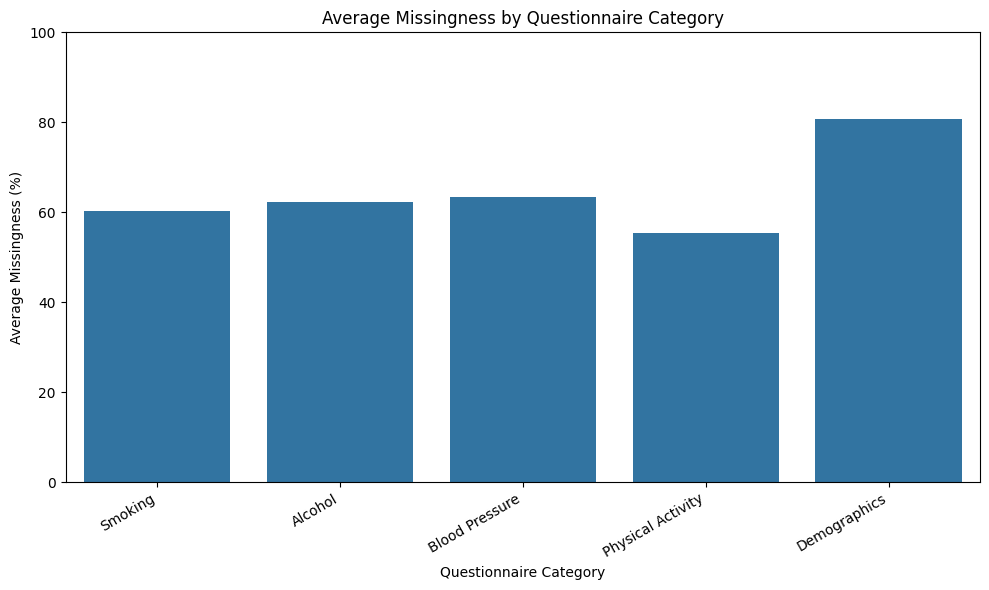

Questionnaire category missingness chart saved.


In [131]:
# Visualize average missingness by questionnaire category

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_summary_df,
    x="Category",
    y="Average_Missing_Percentage"
)

plt.title("Average Missingness by Questionnaire Category")
plt.xlabel("Questionnaire Category")
plt.ylabel("Average Missingness (%)")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 100)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "07_questionnaire_category_missingness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Questionnaire category missingness chart saved.")

### 8.33.9 Final Questionnaire Review Summary

This section summarizes the findings from the questionnaire missingness review.

The analysis covered smoking, alcohol consumption, blood pressure, physical activity, and demographic variables. Missingness patterns, observed response distributions, and provisional retention decisions were examined.

All 18 reviewed variables are retained provisionally. Final decisions regarding missing-value treatment will depend on verification of official NHANES documentation, including participant eligibility and questionnaire skip patterns.

No imputation or deletion of these variables has been performed during this review.

In [132]:
# Final questionnaire review summary

print("FINAL QUESTIONNAIRE REVIEW SUMMARY")
print("-" * 45)

print("Questionnaire categories reviewed:", len(category_summary_df))
print("Total variables reviewed:", len(questionnaire_decisions))

print(
    "Variables retained provisionally:",
    questionnaire_decisions["Retention_Decision"]
    .eq("Retain provisionally")
    .sum()
)

print("\nAverage missingness by category:")
display(
    category_summary_df[
        ["Category", "Average_Missing_Percentage"]
    ].round(2)
)

print("\nDocumentation verification status:")
print("Official NHANES documentation review is still required.")

print("\nData treatment status:")
print("No questionnaire variables deleted.")
print("No questionnaire missing values imputed.")

FINAL QUESTIONNAIRE REVIEW SUMMARY
---------------------------------------------
Questionnaire categories reviewed: 5
Total variables reviewed: 18
Variables retained provisionally: 18

Average missingness by category:


,Category,Average_Missing_Percentage
0,Smoking,60.38
1,Alcohol,62.32
2,Blood Pressure,63.32
3,Physical Activity,55.32
4,Demographics,80.67



Documentation verification status:
Official NHANES documentation review is still required.

Data treatment status:
No questionnaire variables deleted.
No questionnaire missing values imputed.


#### 8.34.1 Verify DMDYRUSR Using Official NHANES Documentation

According to the official NHANES August 2021–August 2023 DEMO_L codebook, DMDYRUSR records the length of time a participant has lived in the United States.

Participants born outside the United States were asked this question. The variable contains six valid residence-duration categories, along with refused and don't know response codes.

This step examines whether DMDYRUSR availability is associated with the participant's country of birth (DMDBORN4).

In [133]:
# Verify DMDYRUSR against country of birth

print("DMDYRUSR availability by country of birth:")

dmdyrusr_birth_crosstab = pd.crosstab(
    cleaning_df["DMDBORN4"],
    cleaning_df["DMDYRUSR"].notna(),
    margins=True
)

display(dmdyrusr_birth_crosstab)

print("\nDMDYRUSR response distribution by country of birth:")

display(
    pd.crosstab(
        cleaning_df["DMDBORN4"],
        cleaning_df["DMDYRUSR"],
        margins=True
    )
)

dmdyrusr_birth_crosstab.to_csv(
    TABLES_DIR / "52_dmdyrusr_country_of_birth_verification.csv"
)

print("\nDMDYRUSR country-of-birth verification saved.")

DMDYRUSR availability by country of birth:


DMDYRUSR,False,True,All
DMDBORN4,,,
1.0,6039,0,6039
2.0,46,1437,1483
All,6085,1437,7522



DMDYRUSR response distribution by country of birth:


DMDYRUSR,1.0,2.0,3.0,4.0,5.0,6.0,All
DMDBORN4,,,,,,,
2.0,60,140,141,111,139,846,1437
All,60,140,141,111,139,846,1437



DMDYRUSR country-of-birth verification saved.


In [134]:
# Investigate DMDYRUSR missingness using the original dataset

print("Original DMDYRUSR values for participants born outside the US:")

foreign_born_missing = (
    (cleaning_df["DMDBORN4"] == 2) &
    (cleaning_df["DMDYRUSR"].isna())
)

display(
    df.loc[
        foreign_born_missing,
        "DMDYRUSR"
    ].value_counts(dropna=False)
)

print("\nOriginal DMDYRUSR response distribution among foreign-born participants:")

display(
    df.loc[
        cleaning_df["DMDBORN4"] == 2,
        "DMDYRUSR"
    ].value_counts(dropna=False).sort_index()
)

print("\nParticipants with missing country of birth:")

display(
    df.loc[
        cleaning_df["DMDBORN4"].isna(),
        ["SEQN", "DMDBORN4", "DMDYRUSR"]
    ]
)

print(
    "\nNumber of participants with missing country of birth:",
    cleaning_df["DMDBORN4"].isna().sum()
)

Original DMDYRUSR values for participants born outside the US:


DMDYRUSR
99.0    34
77.0    12
Name: count, dtype: int64


Original DMDYRUSR response distribution among foreign-born participants:


DMDYRUSR
1.0      60
2.0     140
3.0     141
4.0     111
5.0     139
6.0     846
77.0     12
99.0     34
Name: count, dtype: int64


Participants with missing country of birth:


,SEQN,DMDBORN4,DMDYRUSR
1109,132136.0,NaN,NaN
1265,132387.0,NaN,NaN
1611,132946.0,NaN,NaN
1678,133047.0,NaN,NaN
2053,133644.0,NaN,NaN
2256,134000.0,NaN,NaN
3865,136557.0,NaN,NaN
4670,137786.0,NaN,NaN
5281,138784.0,NaN,NaN
6030,139970.0,NaN,NaN



Number of participants with missing country of birth: 14


#### 8.34.1.1 Document DMDYRUSR Missingness Classification

The investigation of DMDYRUSR identified three distinct missingness groups.

1. Structural missingness: Participants born in the United States who were not eligible for the residence-duration question.
2. Nonresponse: Foreign-born participants with refused or don't know response codes.
3. Unknown eligibility: Participants whose country of birth is missing.

These categories will be documented separately to prevent structural missingness from being incorrectly treated as ordinary missing data during preprocessing.

No imputation or deletion will be performed at this stage.

In [135]:
# Document DMDYRUSR missingness classification

dmdyrusr_missingness_summary = pd.DataFrame({
    "Missingness_Category": [
        "Structural missingness",
        "Refused",
        "Don't know",
        "Unknown eligibility"
    ],
    "Participant_Count": [
        6039,
        12,
        34,
        14
    ],
    "Percentage_of_Dataset": [
        6039 / len(cleaning_df) * 100,
        12 / len(cleaning_df) * 100,
        34 / len(cleaning_df) * 100,
        14 / len(cleaning_df) * 100
    ],
    "Treatment_Recommendation": [
        "Retain as structurally missing; do not impute automatically",
        "Treat as nonresponse; evaluate separately",
        "Treat as nonresponse; evaluate separately",
        "Retain as unknown eligibility; investigate separately"
    ]
})

display(dmdyrusr_missingness_summary.round(2))

print(
    "Total classified:",
    dmdyrusr_missingness_summary["Participant_Count"].sum()
)

dmdyrusr_missingness_summary.to_csv(
    TABLES_DIR / "53_dmdyrusr_missingness_classification.csv",
    index=False
)

print("DMDYRUSR missingness classification saved.")

,Missingness_Category,Participant_Count,Percentage_of_Dataset,Treatment_Recommendation
0,Structural missingness,6039,80.14,Retain as structurally missing; do not impute ...
1,Refused,12,0.16,Treat as nonresponse; evaluate separately
2,Don't know,34,0.45,Treat as nonresponse; evaluate separately
3,Unknown eligibility,14,0.19,Retain as unknown eligibility; investigate sep...


Total classified: 6099
DMDYRUSR missingness classification saved.


#### 8.34.2 Verify RIDEXPRG Using Official NHANES Documentation

RIDEXPRG is a demographic examination variable associated with pregnancy status.

This step examines its observed response distribution and availability across participant demographic groups. The purpose is to investigate whether missingness is associated with participant eligibility or examination procedures.

Response codes and eligibility rules will be interpreted only after verification against the official NHANES documentation.

In [136]:
# Examine RIDEXPRG availability by age and sex

print("RIDEXPRG availability by sex:")

ridexprg_sex_crosstab = pd.crosstab(
    cleaning_df["RIAGENDR"],
    cleaning_df["RIDEXPRG"].notna(),
    margins=True
)

display(ridexprg_sex_crosstab)

print("\nRIDEXPRG availability by age:")

cleaning_df["RIDEXPRG_Availability"] = (
    cleaning_df["RIDEXPRG"].notna()
)

cleaning_df["Age_Group"] = pd.cut(
    cleaning_df["RIDAGEYR"],
    bins=[19, 29, 39, 49, 59, 69, 79, 120],
    labels=[
        "20-29", "30-39", "40-49", "50-59",
        "60-69", "70-79", "80+"
    ]
)

ridexprg_age_crosstab = pd.crosstab(
    cleaning_df["Age_Group"],
    cleaning_df["RIDEXPRG_Availability"],
    margins=True
)

display(ridexprg_age_crosstab)

RIDEXPRG availability by sex:


RIDEXPRG,False,True,All
RIAGENDR,,,
1.0,3365,0,3365
2.0,2694,1477,4171
All,6059,1477,7536



RIDEXPRG availability by age:


RIDEXPRG_Availability,False,True,All
Age_Group,,,
20-29,406,494,900
30-39,494,661,1155
40-49,695,322,1017
50-59,1135,0,1135
60-69,1685,0,1685
70-79,1144,0,1144
80+,500,0,500
All,6059,1477,7536


#### 8.34.2.1 Examine RIDEXPRG Response Codes

This step examines the original RIDEXPRG response codes before special-value conversion.

The observed codes will be compared with the official NHANES documentation to distinguish valid pregnancy-status responses from refused, don't know, or other special responses.

No values will be recoded during this investigation.

In [137]:
# Examine original RIDEXPRG response codes

print("Original RIDEXPRG response distribution:")

display(
    df["RIDEXPRG"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nRIDEXPRG response distribution by sex:")

display(
    pd.crosstab(
        df["RIAGENDR"],
        df["RIDEXPRG"],
        margins=True,
        dropna=False
    )
)

print("\nRIDEXPRG response distribution by age group:")

display(
    pd.crosstab(
        cleaning_df["Age_Group"],
        df["RIDEXPRG"],
        margins=True,
        dropna=False
    )
)

Original RIDEXPRG response distribution:


RIDEXPRG
1.0      41
2.0    1045
3.0     391
NaN    6059
Name: count, dtype: int64


RIDEXPRG response distribution by sex:


RIDEXPRG,1.0,2.0,3.0,NaN,All
RIAGENDR,,,,,
1.0,0,0,0,3365,3365
2.0,41,1045,391,2694,4171
All,41,1045,391,0,7536



RIDEXPRG response distribution by age group:


RIDEXPRG,1.0,2.0,3.0,All
Age_Group,,,,
20-29,19,332,143,900
30-39,21,466,174,1155
40-49,1,247,74,1017
50-59,0,0,0,1135
60-69,0,0,0,1685
70-79,0,0,0,1144
80+,0,0,0,500
All,41,1045,391,7536


#### 8.34.2.2 Document RIDEXPRG Missingness Patterns

The RIDEXPRG analysis identified missingness associated with participant sex and age.

All observed responses belong to female participants aged 20–49. Male participants and participants aged 50 or older have no observed responses.

These patterns suggest eligibility-dependent missingness. The exact eligibility criteria and response-code meanings must be verified using the official NHANES documentation before final treatment decisions are made.

No imputation or deletion will be performed at this stage.

In [138]:
# Document RIDEXPRG missingness patterns

ridexprg_missingness_summary = pd.DataFrame({
    "Missingness_Category": [
        "Male participants",
        "Female participants aged 50 or older",
        "Female participants aged 20-49"
    ],
    "Participant_Count": [
        (cleaning_df["RIAGENDR"] == 1).sum(),
        (
            (cleaning_df["RIAGENDR"] == 2) &
            (cleaning_df["RIDAGEYR"] >= 50)
        ).sum(),
        (
            (cleaning_df["RIAGENDR"] == 2) &
            (cleaning_df["RIDAGEYR"].between(20, 49))
        ).sum()
    ],
    "RIDEXPRG_Missing_Count": [
        (
            (cleaning_df["RIAGENDR"] == 1) &
            cleaning_df["RIDEXPRG"].isna()
        ).sum(),
        (
            (cleaning_df["RIAGENDR"] == 2) &
            (cleaning_df["RIDAGEYR"] >= 50) &
            cleaning_df["RIDEXPRG"].isna()
        ).sum(),
        (
            (cleaning_df["RIAGENDR"] == 2) &
            (cleaning_df["RIDAGEYR"].between(20, 49)) &
            cleaning_df["RIDEXPRG"].isna()
        ).sum()
    ]
})

display(ridexprg_missingness_summary)

ridexprg_missingness_summary.to_csv(
    TABLES_DIR / "54_ridexprg_missingness_patterns.csv",
    index=False
)

print("RIDEXPRG missingness patterns saved.")

,Missingness_Category,Participant_Count,RIDEXPRG_Missing_Count
0,Male participants,3365,3365
1,Female participants aged 50 or older,2450,2450
2,Female participants aged 20-49,1721,244


RIDEXPRG missingness patterns saved.


#### 8.34.2.3 Investigate Missing RIDEXPRG Responses Among Eligible-Age Female Participants

This step examines the 244 female participants aged 20–49 whose RIDEXPRG values are missing.

Their age distribution and other available demographic information will be reviewed to identify potential patterns.

The missing values will not be classified as ordinary nonresponse until the official NHANES examination eligibility criteria have been verified.

In [139]:
# Investigate missing RIDEXPRG among female participants aged 20-49

ridexprg_missing_eligible_age = cleaning_df[
    (cleaning_df["RIAGENDR"] == 2) &
    (cleaning_df["RIDAGEYR"].between(20, 49)) &
    (cleaning_df["RIDEXPRG"].isna())
].copy()

print(
    "Female participants aged 20-49 with missing RIDEXPRG:",
    len(ridexprg_missing_eligible_age)
)

print("\nAge distribution of missing RIDEXPRG cases:")

display(
    ridexprg_missing_eligible_age["RIDAGEYR"]
    .value_counts()
    .sort_index()
)

print("\nAge distribution summary:")

display(
    ridexprg_missing_eligible_age["RIDAGEYR"]
    .describe()
)

print("\nOther available demographic information:")

display(
    ridexprg_missing_eligible_age[
        ["SEQN", "RIDAGEYR", "RIAGENDR", "RIDRETH1", "RIDRETH3"]
    ].head(20)
)

Female participants aged 20-49 with missing RIDEXPRG: 244

Age distribution of missing RIDEXPRG cases:


RIDAGEYR
45.0    47
46.0    63
47.0    44
48.0    49
49.0    41
Name: count, dtype: int64


Age distribution summary:


count    244.000000
mean      46.893443
std        1.377702
min       45.000000
25%       46.000000
50%       47.000000
75%       48.000000
max       49.000000
Name: RIDAGEYR, dtype: float64


Other available demographic information:


,SEQN,RIDAGEYR,RIAGENDR,RIDRETH1,RIDRETH3
105,130544.0,46.0,2.0,3.0,3.0
123,130569.0,47.0,2.0,1.0,1.0
160,130623.0,46.0,2.0,3.0,3.0
173,130645.0,47.0,2.0,2.0,2.0
221,130720.0,46.0,2.0,3.0,3.0
236,130746.0,45.0,2.0,4.0,4.0
268,130799.0,47.0,2.0,4.0,4.0
290,130835.0,45.0,2.0,3.0,3.0
308,130867.0,49.0,2.0,3.0,3.0
317,130881.0,46.0,2.0,3.0,3.0


#### 8.34.2.4 Investigate RIDEXPRG Missingness Within the Eligible Age Group

The official NHANES documentation identifies females aged 20–44 as the public-release eligible group for RIDEXPRG.

This step examines missing RIDEXPRG values within that age range according to interview and examination status (RIDSTATR).

The objective is to determine whether missing values are associated with examination participation or remain unexplained.

In [140]:
# Examine RIDEXPRG missingness among females aged 20-44

ridexprg_eligible_group = cleaning_df[
    (cleaning_df["RIAGENDR"] == 2) &
    (cleaning_df["RIDAGEYR"].between(20, 44))
].copy()

print("Female participants aged 20-44:")
print("Total:", len(ridexprg_eligible_group))

print("\nRIDEXPRG availability by examination status:")

display(
    pd.crosstab(
        ridexprg_eligible_group["RIDSTATR"],
        ridexprg_eligible_group["RIDEXPRG"].notna(),
        margins=True
    )
)

print("\nRIDEXPRG response distribution by examination status:")

display(
    pd.crosstab(
        ridexprg_eligible_group["RIDSTATR"],
        ridexprg_eligible_group["RIDEXPRG"],
        margins=True
    )
)

Female participants aged 20-44:
Total: 1477

RIDEXPRG availability by examination status:


RIDEXPRG,True,All
RIDSTATR,,
1.0,363,363
2.0,1114,1114
All,1477,1477



RIDEXPRG response distribution by examination status:


RIDEXPRG,1.0,2.0,3.0,All
RIDSTATR,,,,
1.0,0,0,363,363
2.0,41,1045,28,1114
All,41,1045,391,1477


#### 8.34.2.5 Document RIDEXPRG Missingness Classification

The official NHANES documentation and dataset investigation identified the following missingness patterns for RIDEXPRG:

1. Male participants: Pregnancy status is not applicable.
2. Female participants aged 45–49: Pregnancy status is not included in the public-release age range.
3. Female participants aged 50 or older: Outside the public-release age range.
4. Female participants aged 20–44: All participants have an observed RIDEXPRG response.

Response code 3 represents an observed response indicating that pregnancy status could not be determined. It is not a missing value.

These findings will be documented separately to distinguish eligibility-related missingness from observed questionnaire responses.

In [141]:
# Document RIDEXPRG missingness classification

ridexprg_missingness_classification = pd.DataFrame({
    "Missingness_Category": [
        "Male participants",
        "Female participants aged 45-49",
        "Female participants aged 50 or older",
        "Eligible female participants aged 20-44"
    ],
    "Participant_Count": [
        3365,
        244,
        2450,
        1477
    ],
    "RIDEXPRG_Missing_Count": [
        3365,
        244,
        2450,
        0
    ],
    "Treatment_Recommendation": [
        "Retain as not applicable; do not impute automatically",
        "Document public-release age restriction; do not impute",
        "Document public-release age restriction; do not impute",
        "Retain observed responses, including response code 3"
    ]
})

display(ridexprg_missingness_classification)

print(
    "Total participants:",
    ridexprg_missingness_classification["Participant_Count"].sum()
)

print(
    "Total missing values:",
    ridexprg_missingness_classification["RIDEXPRG_Missing_Count"].sum()
)

ridexprg_missingness_classification.to_csv(
    TABLES_DIR / "55_ridexprg_missingness_classification.csv",
    index=False
)

print("RIDEXPRG missingness classification saved.")

,Missingness_Category,Participant_Count,RIDEXPRG_Missing_Count,Treatment_Recommendation
0,Male participants,3365,3365,Retain as not applicable; do not impute automa...
1,Female participants aged 45-49,244,244,Document public-release age restriction; do no...
2,Female participants aged 50 or older,2450,2450,Document public-release age restriction; do no...
3,Eligible female participants aged 20-44,1477,0,"Retain observed responses, including response ..."


Total participants: 7536
Total missing values: 6059
RIDEXPRG missingness classification saved.


### 8.34.3 Consolidate Demographic Documentation Findings

This section consolidates the official NHANES documentation review and observed missingness investigations for DMDYRUSR and RIDEXPRG.

The review distinguishes structural missingness, nonresponse, unknown eligibility, and public-release restrictions.

These findings will support the final missing-value treatment strategy without automatically imputing or deleting demographic variables.

In [142]:
# Consolidate demographic documentation findings

demographic_documentation_files = [
    "53_dmdyrusr_missingness_classification.csv",
    "55_ridexprg_missingness_classification.csv"
]

demographic_documentation_summary = pd.concat(
    [
        pd.read_csv(TABLES_DIR / file)
        for file in demographic_documentation_files
    ],
    keys=["DMDYRUSR", "RIDEXPRG"],
    names=["Variable", "Record"]
).reset_index(level="Variable")

display(demographic_documentation_summary)

demographic_documentation_summary.to_csv(
    TABLES_DIR / "56_demographic_documentation_summary.csv",
    index=False
)

print("\nTotal demographic classification records:",
      len(demographic_documentation_summary))

print("Demographic documentation summary saved.")

,Variable,Missingness_Category,Participant_Count,Percentage_of_Dataset,Treatment_Recommendation,RIDEXPRG_Missing_Count
Record,,,,,,
0,DMDYRUSR,Structural missingness,6039,80.135350,Retain as structurally missing; do not impute ...,NaN
1,DMDYRUSR,Refused,12,0.159236,Treat as nonresponse; evaluate separately,NaN
2,DMDYRUSR,Don't know,34,0.451168,Treat as nonresponse; evaluate separately,NaN
3,DMDYRUSR,Unknown eligibility,14,0.185775,Retain as unknown eligibility; investigate sep...,NaN
0,RIDEXPRG,Male participants,3365,NaN,Retain as not applicable; do not impute automa...,3365.0
1,RIDEXPRG,Female participants aged 45-49,244,NaN,Document public-release age restriction; do no...,244.0
2,RIDEXPRG,Female participants aged 50 or older,2450,NaN,Document public-release age restriction; do no...,2450.0
3,RIDEXPRG,Eligible female participants aged 20-44,1477,NaN,"Retain observed responses, including response ...",0.0



Total demographic classification records: 8
Demographic documentation summary saved.


### 8.34.4 Final Demographic Missingness Review

This section summarizes the demographic documentation verification for DMDYRUSR and RIDEXPRG.

The review identified eligibility-dependent missingness, nonresponse codes, unknown eligibility, and public-release restrictions.

Both variables will be retained provisionally. Structural and eligibility-related missing values will not be automatically imputed. Refused and don't know responses will remain documented for further evaluation.

No changes will be made to the original integrated dataset.

In [143]:
# Final demographic missingness review

print("FINAL DEMOGRAPHIC DOCUMENTATION REVIEW")
print("-" * 50)

print("\nDMDYRUSR")
print("Total missing values:", cleaning_df["DMDYRUSR"].isna().sum())
print("Structural missingness: 6039")
print("Refused: 12")
print("Don't know: 34")
print("Unknown eligibility: 14")

print("\nRIDEXPRG")
print("Total missing values:", cleaning_df["RIDEXPRG"].isna().sum())
print("Male participants: 3365")
print("Female participants aged 45-49: 244")
print("Female participants aged 50 or older: 2450")
print("Eligible female participants aged 20-44: 1477")
print("Missing values within eligible group: 0")

print("\nFINAL DECISIONS")
print("DMDYRUSR: Retain provisionally; document eligibility and nonresponse.")
print("RIDEXPRG: Retain provisionally; preserve observed response code 3.")
print("Automatic imputation: Not performed.")
print("Feature deletion: Not performed.")

print("\nDemographic documentation review completed.")

FINAL DEMOGRAPHIC DOCUMENTATION REVIEW
--------------------------------------------------

DMDYRUSR
Total missing values: 6099
Structural missingness: 6039
Refused: 12
Don't know: 34
Unknown eligibility: 14

RIDEXPRG
Total missing values: 6059
Male participants: 3365
Female participants aged 45-49: 244
Female participants aged 50 or older: 2450
Eligible female participants aged 20-44: 1477
Missing values within eligible group: 0

FINAL DECISIONS
DMDYRUSR: Retain provisionally; document eligibility and nonresponse.
RIDEXPRG: Retain provisionally; preserve observed response code 3.
Automatic imputation: Not performed.
Feature deletion: Not performed.

Demographic documentation review completed.


### 8.35.1 Verify Smoking Questionnaire Response Codes

This section verifies the smoking questionnaire variables against the official NHANES August 2021–August 2023 documentation.

The review begins with SMQ020 and SMQ040. Their response distributions and missingness patterns will be examined to understand questionnaire routing and participant eligibility.

Original response codes will be preserved during verification. No imputation or deletion will be performed.

In [144]:
# Examine original smoking questionnaire response codes

smoking_initial_variables = ["SMQ020", "SMQ040"]

for col in smoking_initial_variables:
    print(f"\nOriginal response distribution for {col}:")
    print(
        df[col]
        .value_counts(dropna=False)
        .sort_index()
    )

    print(
        f"\nMissing percentage in cleaning_df: "
        f"{cleaning_df[col].isna().mean() * 100:.2f}%"
    )


Original response distribution for SMQ020:
SMQ020
1.0    3093
2.0    4416
7.0       7
9.0       7
NaN      13
Name: count, dtype: int64

Missing percentage in cleaning_df: 0.36%

Original response distribution for SMQ040:
SMQ040
1.0     918
2.0     226
3.0    1949
NaN    4443
Name: count, dtype: int64

Missing percentage in cleaning_df: 58.96%


#### 8.35.2 Examine SMQ020 and SMQ040 Questionnaire Routing

This step examines the relationship between SMQ020 and SMQ040 using the original NHANES response values.

The objective is to identify whether SMQ040 availability is associated with responses to SMQ020.

Original response codes, including special values, will be preserved during this investigation.

In [145]:
# Examine original SMQ020 and SMQ040 questionnaire routing

smoking_routing_crosstab = pd.crosstab(
    df["SMQ020"],
    df["SMQ040"],
    margins=True,
    dropna=False
)

print("SMQ020 versus SMQ040 response distribution:")
display(smoking_routing_crosstab)

print("\nSMQ040 availability by SMQ020 response:")

smoking_availability = pd.crosstab(
    df["SMQ020"],
    df["SMQ040"].notna(),
    margins=True
)

display(smoking_availability)

smoking_routing_crosstab.to_csv(
    TABLES_DIR / "57_smoking_questionnaire_routing.csv"
)

print("Smoking questionnaire routing analysis saved.")

SMQ020 versus SMQ040 response distribution:


SMQ040,1.0,2.0,3.0,NaN,All
SMQ020,,,,,
1.0,918,226,1949,0,3093.0
2.0,0,0,0,4416,4416.0
7.0,0,0,0,7,7.0
9.0,0,0,0,7,7.0
NaN,0,0,0,13,NaN
All,918,226,1949,0,7536.0



SMQ040 availability by SMQ020 response:


SMQ040,False,True,All
SMQ020,,,
1.0,0,3093,3093
2.0,4416,0,4416
7.0,7,0,7
9.0,7,0,7
All,4430,3093,7523


Smoking questionnaire routing analysis saved.


#### 8.35.3 Examine SMD641 and SMD650 Response Distributions

This step examines the original response distributions of SMD641 and SMD650 before special-value conversion.

The observed values and missingness patterns will be reviewed to identify potential questionnaire eligibility and routing relationships.

Response codes will be verified using the official NHANES documentation before final treatment decisions.

In [146]:
# Examine original SMD641 and SMD650 response distributions

smoking_detailed_variables = ["SMD641", "SMD650"]

for col in smoking_detailed_variables:
    print(f"\nOriginal response distribution for {col}:")

    display(
        df[col]
        .value_counts(dropna=False)
        .sort_index()
    )

    print(
        f"Missing percentage in cleaning_df: "
        f"{cleaning_df[col].isna().mean() * 100:.2f}%"
    )


Original response distribution for SMD641:


SMD641
5.397605e-79      10
1.000000e+00      10
2.000000e+00      21
3.000000e+00      20
4.000000e+00       6
5.000000e+00       9
6.000000e+00       6
7.000000e+00       3
8.000000e+00       9
1.000000e+01      29
1.200000e+01      12
1.400000e+01       3
1.500000e+01      34
1.700000e+01       1
1.800000e+01       1
2.000000e+01      32
2.200000e+01       1
2.300000e+01       1
2.500000e+01       8
2.700000e+01       2
2.800000e+01       2
2.900000e+01       1
3.000000e+01      12
9.900000e+01       5
NaN             7298
Name: count, dtype: int64

Missing percentage in cleaning_df: 97.04%

Original response distribution for SMD650:


SMD650
1.0        87
2.0        77
3.0        54
4.0        53
5.0        94
6.0        53
7.0        42
8.0        29
9.0         4
10.0      206
11.0        5
12.0       33
13.0        2
15.0       85
16.0        6
17.0        1
18.0        4
20.0      200
21.0        1
24.0        2
25.0       14
26.0        1
28.0        1
30.0       31
38.0        1
40.0       26
50.0        2
60.0        3
90.0        1
95.0        2
999.0       9
NaN      6407
Name: count, dtype: int64

Missing percentage in cleaning_df: 85.14%


#### 8.35.4 Examine SMD641 and SMD650 Questionnaire Routing

This step examines the availability of SMD641 and SMD650 across the observed SMQ040 response categories.

The objective is to identify whether the availability of these variables is associated with smoking questionnaire responses.

Missingness patterns will be described using the cleaned working dataset. Original response codes will remain unchanged.

In [147]:
# Examine SMD641 and SMD650 availability by SMQ040

for col in ["SMD641", "SMD650"]:

    print(f"\n{col} availability by SMQ040:")

    availability_table = pd.crosstab(
        cleaning_df["SMQ040"],
        cleaning_df[col].notna(),
        margins=True
    )

    display(availability_table)

    print(f"\n{col} observed response distribution by SMQ040:")

    response_table = pd.crosstab(
        cleaning_df["SMQ040"],
        cleaning_df[col],
        margins=True
    )

    display(response_table)


SMD641 availability by SMQ040:


SMD641,False,True,All
SMQ040,,,
1.0,906,12,918
2.0,15,211,226
3.0,1949,0,1949
All,2870,223,3093



SMD641 observed response distribution by SMQ040:


SMD641,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,10.0,12.0,...,18.0,20.0,22.0,23.0,25.0,27.0,28.0,29.0,30.0,All
SMQ040,,,,,,,,,,,,,,,,,,,,,
1.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,12,12
2.0,10,21,20,6,9,6,3,9,29,12,...,1,32,1,1,8,2,2,1,0,211
All,10,21,20,6,9,6,3,9,29,12,...,1,32,1,1,8,2,2,1,12,223



SMD650 availability by SMQ040:


SMD650,False,True,All
SMQ040,,,
1.0,7,911,918
2.0,17,209,226
3.0,1949,0,1949
All,1973,1120,3093



SMD650 observed response distribution by SMQ040:


SMD650,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,...,26.0,28.0,30.0,38.0,40.0,50.0,60.0,90.0,95.0,All
SMQ040,,,,,,,,,,,,,,,,,,,,,
1.0,39,27,22,35,68,45,39,28,4,193,...,1,1,28,1,25,2,3,1,2,911
2.0,48,50,32,18,26,8,3,1,0,13,...,0,0,3,0,1,0,0,0,0,209
All,87,77,54,53,94,53,42,29,4,206,...,1,1,31,1,26,2,3,1,2,1120


#### 8.35.5 Verify Special Response Codes in Smoking Variables

This step examines the original special response codes in SMD641 and SMD650.

The values 99 and 999 will be compared with the official NHANES documentation to determine whether they represent refused, don't know, or another response category.

The original dataset will remain unchanged during verification.

In [148]:
# Examine special response codes in original smoking variables

special_smoking_codes = {
    "SMD641": [99],
    "SMD650": [999]
}

for col, codes in special_smoking_codes.items():

    print(f"\nSpecial response codes in {col}:")

    for code in codes:
        print(
            f"Code {code}:",
            (df[col] == code).sum()
        )

    print("\nOriginal special-code records:")

    display(
        df.loc[
            df[col].isin(codes),
            ["SEQN", "SMQ020", "SMQ040", col]
        ]
    )


Special response codes in SMD641:
Code 99: 5

Original special-code records:


,SEQN,SMQ020,SMQ040,SMD641
1845,133314.0,1.0,2.0,99.0
2975,135146.0,1.0,2.0,99.0
3163,135454.0,1.0,2.0,99.0
5672,139369.0,1.0,2.0,99.0
6045,139996.0,1.0,2.0,99.0



Special response codes in SMD650:
Code 999: 9

Original special-code records:


,SEQN,SMQ020,SMQ040,SMD650
1506,132786.0,1.0,1.0,999.0
1868,133347.0,1.0,2.0,999.0
1893,133386.0,1.0,2.0,999.0
2214,133928.0,1.0,1.0,999.0
3134,135406.0,1.0,1.0,999.0
6482,140650.0,1.0,1.0,999.0
6619,140860.0,1.0,1.0,999.0
6720,141024.0,1.0,1.0,999.0
6859,141238.0,1.0,1.0,999.0


#### 8.35.6 Document Smoking Special-Code Verification

The official NHANES August 2021–August 2023 SMQ_L documentation was used to verify the special response codes in SMD641 and SMD650.

For SMD641, code 99 represents Don't know, while code 77 represents Refused.

For SMD650, code 999 represents Don't know, while code 777 represents Refused.

The original dataset contains five SMD641 values coded 99 and nine SMD650 values coded 999. These values were converted to missing values during the earlier cleaning process.

No additional recoding or imputation will be performed in this step.

In [149]:
# Document official smoking special-code verification

smoking_code_verification = pd.DataFrame({
    "Variable": ["SMD641", "SMD650"],
    "Refused_Code": [77, 777],
    "Dont_Know_Code": [99, 999],
    "Observed_Refused_Count": [
        (df["SMD641"] == 77).sum(),
        (df["SMD650"] == 777).sum()
    ],
    "Observed_Dont_Know_Count": [
        (df["SMD641"] == 99).sum(),
        (df["SMD650"] == 999).sum()
    ],
    "Verification_Status": [
        "Verified using official CDC SMQ_L documentation",
        "Verified using official CDC SMQ_L documentation"
    ],
    "Cleaning_Decision": [
        "Convert Don't know and refused codes to missing",
        "Convert Don't know and refused codes to missing"
    ]
})

display(smoking_code_verification)

smoking_code_verification.to_csv(
    TABLES_DIR / "58_smoking_special_code_verification.csv",
    index=False
)

print("Smoking special-code verification saved.")

,Variable,Refused_Code,Dont_Know_Code,Observed_Refused_Count,Observed_Dont_Know_Count,Verification_Status,Cleaning_Decision
0,SMD641,77,99,0,5,Verified using official CDC SMQ_L documentation,Convert Don't know and refused codes to missing
1,SMD650,777,999,0,9,Verified using official CDC SMQ_L documentation,Convert Don't know and refused codes to missing


Smoking special-code verification saved.


#### 8.35.7 Verify Special Response Codes in SMQ020 and SMQ040

This step examines the original response codes in SMQ020 and SMQ040.

The observed response codes will be compared with the official NHANES documentation to distinguish valid responses from refused and don't know responses.

The original dataset will remain unchanged during verification.

In [150]:
# Examine original response distributions for SMQ020 and SMQ040

for col in ["SMQ020", "SMQ040"]:

    print(f"\nOriginal response distribution: {col}")

    print(
        df[col]
        .value_counts(dropna=False)
        .sort_index()
    )


Original response distribution: SMQ020
SMQ020
1.0    3093
2.0    4416
7.0       7
9.0       7
NaN      13
Name: count, dtype: int64

Original response distribution: SMQ040
SMQ040
1.0     918
2.0     226
3.0    1949
NaN    4443
Name: count, dtype: int64


#### 8.35.8 Document Smoking Response-Code Verification

The official NHANES August 2021–August 2023 SMQ_L documentation was used to verify the response codes in SMQ020 and SMQ040.

For SMQ020, code 1 represents Yes, code 2 represents No, code 7 represents Refused, and code 9 represents Don't know.

For SMQ040, code 1 represents Every day, code 2 represents Some days, and code 3 represents Not at all. Codes 7 and 9 represent Refused and Don't know, respectively.

The original dataset contains seven refused responses and seven Don't know responses for SMQ020. No special response codes were observed for SMQ040.

The special response codes in SMQ020 were converted to missing values during the earlier cleaning process. Missing values in SMQ040 will be reviewed in the context of the questionnaire skip pattern.

No additional recoding or imputation will be performed in this step.

In [151]:
# Document official smoking response-code verification

smoking_response_verification = pd.DataFrame({
    "Variable": ["SMQ020", "SMQ040"],
    "Valid_Response_Codes": ["1, 2", "1, 2, 3"],
    "Refused_Code": [7, 7],
    "Dont_Know_Code": [9, 9],
    "Observed_Refused_Count": [
        (df["SMQ020"] == 7).sum(),
        (df["SMQ040"] == 7).sum()
    ],
    "Observed_Dont_Know_Count": [
        (df["SMQ020"] == 9).sum(),
        (df["SMQ040"] == 9).sum()
    ],
    "Verification_Status": [
        "Verified using official CDC SMQ_L documentation",
        "Verified using official CDC SMQ_L documentation"
    ],
    "Cleaning_Decision": [
        "Special response codes converted to missing",
        "No special response codes observed"
    ]
})

display(smoking_response_verification)

smoking_response_verification.to_csv(
    TABLES_DIR / "59_smoking_response_code_verification.csv",
    index=False
)

print("Smoking response-code verification saved.")

,Variable,Valid_Response_Codes,Refused_Code,Dont_Know_Code,Observed_Refused_Count,Observed_Dont_Know_Count,Verification_Status,Cleaning_Decision
0,SMQ020,"1, 2",7,9,7,7,Verified using official CDC SMQ_L documentation,Special response codes converted to missing
1,SMQ040,"1, 2, 3",7,9,0,0,Verified using official CDC SMQ_L documentation,No special response codes observed


Smoking response-code verification saved.


#### 8.35.9 Final Smoking Variable Review and Retention Decisions

This section consolidates the findings from the smoking questionnaire review.

The variables SMQ020, SMQ040, SMD641, and SMD650 were evaluated using their original response distributions, questionnaire routing patterns, missingness, and official NHANES response-code documentation.

The variables will be retained provisionally because they contain potentially useful smoking-related information. Their missing values will be addressed during the final preprocessing stage after questionnaire eligibility and missingness have been considered.

No additional recoding, deletion, or imputation will be performed in this step.

In [152]:
# Consolidate final smoking variable review decisions

smoking_final_decisions = pd.DataFrame({
    "Variable": ["SMQ020", "SMQ040", "SMD641", "SMD650"],
    "Description": [
        "Smoked at least 100 cigarettes in life",
        "Current cigarette smoking frequency",
        "Number of days smoked cigarettes in past 30 days",
        "Average number of cigarettes smoked per day"
    ],
    "Missing_Count": [
        cleaning_df[col].isna().sum()
        for col in ["SMQ020", "SMQ040", "SMD641", "SMD650"]
    ],
    "Missing_Percentage": [
        cleaning_df[col].isna().mean() * 100
        for col in ["SMQ020", "SMQ040", "SMD641", "SMD650"]
    ],
    "Retention_Decision": ["Retain provisionally"] * 4,
    "Imputation_Decision": ["Defer until final preprocessing"] * 4,
    "Review_Status": ["Initial review completed; retain provisionally"] * 4
})

display(smoking_final_decisions.round(2))

smoking_final_decisions.to_csv(
    TABLES_DIR / "60_final_smoking_variable_decisions.csv",
    index=False
)

print("Final smoking variable review decisions saved.")

,Variable,Description,Missing_Count,Missing_Percentage,Retention_Decision,Imputation_Decision,Review_Status
0,SMQ020,Smoked at least 100 cigarettes in life,27,0.36,Retain provisionally,Defer until final preprocessing,Initial review completed; retain provisionally
1,SMQ040,Current cigarette smoking frequency,4443,58.96,Retain provisionally,Defer until final preprocessing,Initial review completed; retain provisionally
2,SMD641,Number of days smoked cigarettes in past 30 days,7313,97.04,Retain provisionally,Defer until final preprocessing,Initial review completed; retain provisionally
3,SMD650,Average number of cigarettes smoked per day,6416,85.14,Retain provisionally,Defer until final preprocessing,Initial review completed; retain provisionally


Final smoking variable review decisions saved.


#### 8.35.10 Smoking Questionnaire Review Summary

The smoking questionnaire review covered four variables: SMQ020, SMQ040, SMD641, and SMD650.

Original response distributions, questionnaire routing patterns, missingness, and special response codes were examined. Special response codes were verified against the official NHANES documentation.

All four variables were retained provisionally because they may provide useful information for diabetes prediction.

The high missingness in SMQ040, SMD641, and SMD650 will be considered during the final missing-value treatment stage.

No additional deletion or imputation was performed during this review.

In [153]:
# Consolidate smoking questionnaire review summary

smoking_review_summary = pd.DataFrame({
    "Review_Item": [
        "Variables reviewed",
        "Original response distributions",
        "Questionnaire routing",
        "Special response codes",
        "Missingness assessment",
        "Feature retention",
        "Imputation"
    ],
    "Result": [
        "SMQ020, SMQ040, SMD641, SMD650",
        "Completed",
        "Completed; observed associations documented",
        "Verified against official CDC documentation",
        "Completed",
        "All four variables retained provisionally",
        "Deferred until final preprocessing"
    ]
})

display(smoking_review_summary)

smoking_review_summary.to_csv(
    TABLES_DIR / "61_smoking_questionnaire_review_summary.csv",
    index=False
)

print("Smoking questionnaire review summary saved.")

,Review_Item,Result
0,Variables reviewed,"SMQ020, SMQ040, SMD641, SMD650"
1,Original response distributions,Completed
2,Questionnaire routing,Completed; observed associations documented
3,Special response codes,Verified against official CDC documentation
4,Missingness assessment,Completed
5,Feature retention,All four variables retained provisionally
6,Imputation,Deferred until final preprocessing


Smoking questionnaire review summary saved.


### 8.36 Consolidated Questionnaire Review

This section consolidates the variable-level decisions from the demographic, alcohol, blood pressure, physical activity, and smoking questionnaire reviews.

The consolidated review will provide a single record of feature retention decisions and outstanding missing-value treatment considerations.

No additional recoding, deletion, or imputation will be performed during this consolidation step.

In [154]:
# Identify available questionnaire review decision files

questionnaire_review_files = [
    "50_consolidated_questionnaire_review_decisions.csv",
    "60_final_smoking_variable_decisions.csv"
]

for filename in questionnaire_review_files:

    file_path = TABLES_DIR / filename

    print(f"\n{filename}")
    print("File exists:", file_path.exists())

    if file_path.exists():
        review_data = pd.read_csv(file_path)
        print("Shape:", review_data.shape)
        display(review_data.head())


50_consolidated_questionnaire_review_decisions.csv
File exists: True
Shape: (18, 10)


,Variable,Missing_Count,Missing_Percentage,Retention_Decision,Treatment_Decision,Verification_Status,Available_Count,Observed_Responses,Reason,Further_Action
0,SMQ020,27,0.36,Retain provisionally,Verify response codes and missingness,Official documentation review required,NaN,NaN,NaN,NaN
1,SMQ040,4443,58.96,Retain provisionally,Investigate questionnaire skip pattern,Official documentation review required,NaN,NaN,NaN,NaN
2,SMD641,7313,97.04,Retain provisionally,Verify eligibility and response codes,Official documentation review required,NaN,NaN,NaN,NaN
3,SMD650,6416,85.14,Retain provisionally,Verify eligibility and response codes,Official documentation review required,NaN,NaN,NaN,NaN
4,ALQ111,2482,32.94,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required,5054.0,NaN,NaN,NaN



60_final_smoking_variable_decisions.csv
File exists: True
Shape: (4, 7)


,Variable,Description,Missing_Count,Missing_Percentage,Retention_Decision,Imputation_Decision,Review_Status
0,SMQ020,Smoked at least 100 cigarettes in life,27,0.358280,Retain provisionally,Defer until final preprocessing,Initial review completed; retain provisionally
1,SMQ040,Current cigarette smoking frequency,4443,58.957006,Retain provisionally,Defer until final preprocessing,Initial review completed; retain provisionally
2,SMD641,Number of days smoked cigarettes in past 30 days,7313,97.040870,Retain provisionally,Defer until final preprocessing,Initial review completed; retain provisionally
3,SMD650,Average number of cigarettes smoked per day,6416,85.138004,Retain provisionally,Defer until final preprocessing,Initial review completed; retain provisionally


#### 8.36.2 Update Consolidated Questionnaire Decisions

The consolidated questionnaire review is updated using the completed smoking-variable review.

The four smoking variables are updated with their latest retention and treatment decisions. Previously documented decisions for the other questionnaire variables are preserved.

The updated consolidated review will serve as the working record for the final questionnaire assessment.

In [155]:
# Update smoking decisions in the consolidated questionnaire review

consolidated_review = pd.read_csv(
    TABLES_DIR / "50_consolidated_questionnaire_review_decisions.csv"
)

smoking_decisions = pd.read_csv(
    TABLES_DIR / "60_final_smoking_variable_decisions.csv"
)

smoking_variables = ["SMQ020", "SMQ040", "SMD641", "SMD650"]

for _, row in smoking_decisions.iterrows():

    variable = row["Variable"]

    mask = consolidated_review["Variable"] == variable

    if mask.sum() != 1:
        print(
            f"Review required for {variable}: "
            f"{mask.sum()} matching records found."
        )
        continue

    consolidated_review.loc[mask, "Retention_Decision"] = (
        row["Retention_Decision"]
    )

    consolidated_review.loc[mask, "Treatment_Decision"] = (
        row["Imputation_Decision"]
    )

    consolidated_review.loc[mask, "Verification_Status"] = (
        "Official NHANES response-code documentation verified; "
        "questionnaire review completed"
    )

    consolidated_review.loc[mask, "Further_Action"] = (
        "Consider questionnaire routing and missingness "
        "during final preprocessing"
    )

# Save updated consolidated review
consolidated_review.to_csv(
    TABLES_DIR / "62_updated_consolidated_questionnaire_review_decisions.csv",
    index=False
)

# Display updated smoking records
display(
    consolidated_review.loc[
        consolidated_review["Variable"].isin(smoking_variables)
    ]
)

print("\nUpdated consolidated review shape:", consolidated_review.shape)
print("Updated consolidated questionnaire review saved.")

,Variable,Missing_Count,Missing_Percentage,Retention_Decision,Treatment_Decision,Verification_Status,Available_Count,Observed_Responses,Reason,Further_Action
0,SMQ020,27,0.36,Retain provisionally,Defer until final preprocessing,Official NHANES response-code documentation ve...,NaN,NaN,NaN,Consider questionnaire routing and missingness...
1,SMQ040,4443,58.96,Retain provisionally,Defer until final preprocessing,Official NHANES response-code documentation ve...,NaN,NaN,NaN,Consider questionnaire routing and missingness...
2,SMD641,7313,97.04,Retain provisionally,Defer until final preprocessing,Official NHANES response-code documentation ve...,NaN,NaN,NaN,Consider questionnaire routing and missingness...
3,SMD650,6416,85.14,Retain provisionally,Defer until final preprocessing,Official NHANES response-code documentation ve...,NaN,NaN,NaN,Consider questionnaire routing and missingness...



Updated consolidated review shape: (18, 10)
Updated consolidated questionnaire review saved.


#### 8.36.3 Verify Consolidated Questionnaire Review

This step validates the updated consolidated questionnaire review.

The validation checks the total number of reviewed variables, duplicate variable records, retention decisions, and missingness information.

The purpose is to confirm that all questionnaire review decisions have been preserved before finalizing the review.

In [156]:
# Validate consolidated questionnaire review

consolidated_review = pd.read_csv(
    TABLES_DIR / "62_updated_consolidated_questionnaire_review_decisions.csv"
)

print("Total reviewed variables:", len(consolidated_review))

print(
    "Duplicate variable records:",
    consolidated_review["Variable"].duplicated().sum()
)

print("\nRetention decision distribution:")
print(consolidated_review["Retention_Decision"].value_counts(dropna=False))

print("\nMissing decision records:")
print(consolidated_review.isna().sum())

print("\nQuestionnaire category review:")
display(
    consolidated_review[
        ["Variable", "Missing_Count", "Missing_Percentage",
         "Retention_Decision", "Verification_Status"]
    ]
)

Total reviewed variables: 18
Duplicate variable records: 0

Retention decision distribution:
Retention_Decision
Retain provisionally    18
Name: count, dtype: int64

Missing decision records:
Variable                0
Missing_Count           0
Missing_Percentage      0
Retention_Decision      0
Treatment_Decision      2
Verification_Status     2
Available_Count         6
Observed_Responses     16
Reason                 16
Further_Action         12
dtype: int64

Questionnaire category review:


,Variable,Missing_Count,Missing_Percentage,Retention_Decision,Verification_Status
0,SMQ020,27,0.360000,Retain provisionally,Official NHANES response-code documentation ve...
1,SMQ040,4443,58.960000,Retain provisionally,Official NHANES response-code documentation ve...
2,SMD641,7313,97.040000,Retain provisionally,Official NHANES response-code documentation ve...
3,SMD650,6416,85.140000,Retain provisionally,Official NHANES response-code documentation ve...
4,ALQ111,2482,32.940000,Retain provisionally,Official NHANES documentation review required
5,ALQ121,3716,49.310000,Retain provisionally,Official NHANES documentation review required
6,ALQ130,3739,49.620000,Retain provisionally,Official NHANES documentation review required
7,ALQ142,5345,70.930000,Retain provisionally,Official NHANES documentation review required
8,ALQ151,2949,39.130000,Retain provisionally,Official NHANES documentation review required
9,ALQ170,6394,84.850000,Retain provisionally,Official NHANES documentation review required


#### 8.36.4 Review Demographic Documentation Records

This step examines the previously completed demographic documentation for DMDYRUSR and RIDEXPRG.

The existing demographic review records will be used to identify the appropriate verification status, treatment considerations, and further actions.

Previously documented decisions will be preserved. No new missing-value treatment or dataset modifications will be performed.

In [157]:
# Inspect previously saved demographic documentation

demographic_file = (
    TABLES_DIR / "56_demographic_documentation_summary.csv"
)

print("Demographic documentation file exists:", demographic_file.exists())

if demographic_file.exists():

    demographic_documentation = pd.read_csv(demographic_file)

    print("File shape:", demographic_documentation.shape)

    print("\nAvailable columns:")
    print(demographic_documentation.columns.tolist())

    display(demographic_documentation)

Demographic documentation file exists: True
File shape: (8, 6)

Available columns:
['Variable', 'Missingness_Category', 'Participant_Count', 'Percentage_of_Dataset', 'Treatment_Recommendation', 'RIDEXPRG_Missing_Count']


,Variable,Missingness_Category,Participant_Count,Percentage_of_Dataset,Treatment_Recommendation,RIDEXPRG_Missing_Count
0,DMDYRUSR,Structural missingness,6039,80.135350,Retain as structurally missing; do not impute ...,NaN
1,DMDYRUSR,Refused,12,0.159236,Treat as nonresponse; evaluate separately,NaN
2,DMDYRUSR,Don't know,34,0.451168,Treat as nonresponse; evaluate separately,NaN
3,DMDYRUSR,Unknown eligibility,14,0.185775,Retain as unknown eligibility; investigate sep...,NaN
4,RIDEXPRG,Male participants,3365,NaN,Retain as not applicable; do not impute automa...,3365.0
5,RIDEXPRG,Female participants aged 45-49,244,NaN,Document public-release age restriction; do no...,244.0
6,RIDEXPRG,Female participants aged 50 or older,2450,NaN,Document public-release age restriction; do no...,2450.0
7,RIDEXPRG,Eligible female participants aged 20-44,1477,NaN,"Retain observed responses, including response ...",0.0


#### 8.36.5 Update Demographic Decisions in Consolidated Review

The previously completed demographic documentation is incorporated into the consolidated questionnaire review.

DMDYRUSR and RIDEXPRG are retained provisionally. Their missingness is documented according to structural missingness, nonresponse, unknown eligibility, participant eligibility, and public-release restrictions.

Automatic imputation will not be applied to these variables without further evaluation.

The original demographic review records will be preserved.

In [158]:
# Update demographic decisions in consolidated review

demographic_variables = ["DMDYRUSR", "RIDEXPRG"]

demographic_mask = consolidated_review["Variable"].isin(
    demographic_variables
)

consolidated_review.loc[
    demographic_mask, "Retention_Decision"
] = "Retain provisionally"

consolidated_review.loc[
    demographic_mask, "Treatment_Decision"
] = "Retain documented missingness; evaluate separately during preprocessing"

consolidated_review.loc[
    demographic_mask, "Verification_Status"
] = "Demographic documentation review completed"

consolidated_review.loc[
    demographic_mask, "Further_Action"
] = "Preserve eligibility and structural missingness distinctions; do not automatically impute"

# Save updated consolidated review
consolidated_review.to_csv(
    TABLES_DIR / "63_final_questionnaire_review_decisions.csv",
    index=False
)

# Display updated demographic records
display(
    consolidated_review.loc[
        demographic_mask
    ]
)

print("\nUpdated consolidated review shape:", consolidated_review.shape)
print("Final questionnaire review decisions saved.")

,Variable,Missing_Count,Missing_Percentage,Retention_Decision,Treatment_Decision,Verification_Status,Available_Count,Observed_Responses,Reason,Further_Action
16,DMDYRUSR,6099,80.931529,Retain provisionally,Retain documented missingness; evaluate separa...,Demographic documentation review completed,NaN,6.0,Retained pending verification of eligibility a...,Preserve eligibility and structural missingnes...
17,RIDEXPRG,6059,80.400743,Retain provisionally,Retain documented missingness; evaluate separa...,Demographic documentation review completed,NaN,3.0,Retained pending verification of eligibility a...,Preserve eligibility and structural missingnes...



Updated consolidated review shape: (18, 10)
Final questionnaire review decisions saved.


#### 8.36.6 Final Consolidated Questionnaire Review Validation

This step performs the final validation of the consolidated questionnaire review.

The validation checks the total number of variables, duplicate records, retention decisions, missing treatment decisions, and documentation statuses.

The validated review will serve as the reference for the subsequent missing-value treatment and preprocessing stages.

In [159]:
# Final validation of consolidated questionnaire decisions

final_questionnaire_review = pd.read_csv(
    TABLES_DIR / "63_final_questionnaire_review_decisions.csv"
)

print("Total questionnaire variables:",
      len(final_questionnaire_review))

print("Duplicate variable records:",
      final_questionnaire_review["Variable"].duplicated().sum())

print("\nRetention decisions:")
print(
    final_questionnaire_review["Retention_Decision"]
    .value_counts(dropna=False)
)

print("\nMissing treatment decisions:",
      final_questionnaire_review["Treatment_Decision"].isna().sum())

print("Missing verification statuses:",
      final_questionnaire_review["Verification_Status"].isna().sum())

print("\nMissingness summary:")
display(
    final_questionnaire_review[
        ["Variable", "Missing_Count", "Missing_Percentage",
         "Retention_Decision", "Treatment_Decision",
         "Verification_Status"]
    ]
)

print("\nFinal questionnaire review shape:",
      final_questionnaire_review.shape)

Total questionnaire variables: 18
Duplicate variable records: 0

Retention decisions:
Retention_Decision
Retain provisionally    18
Name: count, dtype: int64

Missing treatment decisions: 0
Missing verification statuses: 0

Missingness summary:


,Variable,Missing_Count,Missing_Percentage,Retention_Decision,Treatment_Decision,Verification_Status
0,SMQ020,27,0.360000,Retain provisionally,Defer until final preprocessing,Official NHANES response-code documentation ve...
1,SMQ040,4443,58.960000,Retain provisionally,Defer until final preprocessing,Official NHANES response-code documentation ve...
2,SMD641,7313,97.040000,Retain provisionally,Defer until final preprocessing,Official NHANES response-code documentation ve...
3,SMD650,6416,85.140000,Retain provisionally,Defer until final preprocessing,Official NHANES response-code documentation ve...
4,ALQ111,2482,32.940000,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required
5,ALQ121,3716,49.310000,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required
6,ALQ130,3739,49.620000,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required
7,ALQ142,5345,70.930000,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required
8,ALQ151,2949,39.130000,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required
9,ALQ170,6394,84.850000,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required



Final questionnaire review shape: (18, 10)


### 8.37 Final Questionnaire Review Summary

The consolidated questionnaire review includes 18 variables across five categories: smoking, alcohol, blood pressure, physical activity, and demographics.

All 18 variables have been provisionally retained. Duplicate records were not found, and all variables have documented treatment decisions and verification statuses.

Smoking and demographic documentation reviews have been completed. Official documentation verification remains pending for the alcohol, blood pressure, and physical activity variables.

No additional feature deletion or missing-value imputation has been performed during this review.

In [160]:
# Create final questionnaire review summary

questionnaire_category_summary = pd.DataFrame({
    "Category": [
        "Smoking",
        "Alcohol",
        "Blood Pressure",
        "Physical Activity",
        "Demographics"
    ],
    "Variables_Reviewed": [4, 8, 2, 2, 2],
    "Documentation_Status": [
        "Completed",
        "Pending official documentation verification",
        "Pending official documentation verification",
        "Pending official documentation verification",
        "Completed"
    ],
    "Retention_Status": [
        "All retained provisionally",
        "All retained provisionally",
        "All retained provisionally",
        "All retained provisionally",
        "All retained provisionally"
    ]
})

display(questionnaire_category_summary)

questionnaire_category_summary.to_csv(
    TABLES_DIR / "64_final_questionnaire_category_summary.csv",
    index=False
)

print("Final questionnaire category summary saved.")

,Category,Variables_Reviewed,Documentation_Status,Retention_Status
0,Smoking,4,Completed,All retained provisionally
1,Alcohol,8,Pending official documentation verification,All retained provisionally
2,Blood Pressure,2,Pending official documentation verification,All retained provisionally
3,Physical Activity,2,Pending official documentation verification,All retained provisionally
4,Demographics,2,Completed,All retained provisionally


Final questionnaire category summary saved.


### 8.38 Alcohol Variable Documentation Review

This section verifies the response codes, questionnaire eligibility, and skip patterns for the eight alcohol-related variables.

The existing alcohol missingness and retention assessments will be used as the starting point.

Official NHANES documentation will be consulted before finalizing missing-value treatment decisions.

No additional recoding, deletion, or imputation will be performed during this review.

In [161]:
# Load existing alcohol questionnaire review decisions

alcohol_file = (
    TABLES_DIR / "37_alcohol_variable_retention_decisions.csv"
)

print("Alcohol review file exists:", alcohol_file.exists())

if alcohol_file.exists():

    alcohol_review = pd.read_csv(alcohol_file)

    print("File shape:", alcohol_review.shape)
    print("\nAvailable columns:")
    print(alcohol_review.columns.tolist())

    display(alcohol_review)

Alcohol review file exists: True
File shape: (8, 7)

Available columns:
['Variable', 'Missing_Count', 'Missing_Percentage', 'Available_Count', 'Retention_Decision', 'Treatment_Decision', 'Verification_Status']


,Variable,Missing_Count,Missing_Percentage,Available_Count,Retention_Decision,Treatment_Decision,Verification_Status
0,ALQ111,2482,32.94,5054,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required
1,ALQ121,3716,49.31,3820,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required
2,ALQ130,3739,49.62,3797,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required
3,ALQ142,5345,70.93,2191,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required
4,ALQ151,2949,39.13,4587,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required
5,ALQ170,6394,84.85,1142,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required
6,ALQ270,6313,83.77,1223,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required
7,ALQ280,6632,88.00,904,Retain provisionally,Verify questionnaire eligibility and skip patt...,Official NHANES documentation review required


#### 8.38.2 Inspect Original Alcohol Response Distributions

This step examines the original response distributions of the eight alcohol questionnaire variables.

The original values will be compared with the official NHANES documentation to distinguish valid responses, refused responses, and don't-know responses.

The original dataset will remain unchanged during this inspection.

In [162]:
# Inspect original alcohol response distributions

alcohol_variables = [
    "ALQ111", "ALQ121", "ALQ130", "ALQ142",
    "ALQ151", "ALQ170", "ALQ270", "ALQ280"
]

for col in alcohol_variables:

    print(f"\nOriginal response distribution: {col}")

    print(
        df[col]
        .value_counts(dropna=False)
        .sort_index()
    )



Original response distribution: ALQ111
ALQ111
1.0    4607
2.0     447
9.0       5
NaN    2477
Name: count, dtype: int64

Original response distribution: ALQ121
ALQ121
5.397605e-79     786
1.000000e+00     157
2.000000e+00     291
3.000000e+00     440
4.000000e+00     468
5.000000e+00     407
6.000000e+00     537
7.000000e+00     331
8.000000e+00     239
9.000000e+00     472
1.000000e+01     478
7.700000e+01       2
9.900000e+01       3
NaN             2925
Name: count, dtype: int64

Original response distribution: ALQ130
ALQ130
1.0      1276
2.0      1236
3.0       560
4.0       228
5.0       195
6.0       131
7.0        15
8.0        39
9.0        15
10.0       27
11.0        4
12.0       50
14.0        2
15.0       19
777.0       4
999.0      10
NaN      3725
Name: count, dtype: int64

Original response distribution: ALQ142
ALQ142
5.397605e-79    1610
1.000000e+00      38
2.000000e+00      58
3.000000e+00     117
4.000000e+00     111
5.000000e+00     198
6.000000e+00     228
7.00000

#### 8.38.3 Verify Special Response Codes in Alcohol Variables

The original response codes for the eight alcohol variables were compared with the official NHANES ALQ_L documentation.

Refused and Don't know codes were identified separately for each variable.

The original dataset remains unchanged. This step verifies the observed special-code counts and their documented meanings before finalizing the cleaning decisions.

In [163]:
# Verify special response codes in original alcohol variables

alcohol_special_codes = {
    "ALQ111": {"Refused": 7, "Dont_Know": 9},
    "ALQ121": {"Refused": 77, "Dont_Know": 99},
    "ALQ130": {"Refused": 777, "Dont_Know": 999},
    "ALQ142": {"Refused": 77, "Dont_Know": 99},
    "ALQ151": {"Refused": 7, "Dont_Know": 9},
    "ALQ170": {"Refused": 777, "Dont_Know": 999},
    "ALQ270": {"Refused": 77, "Dont_Know": 99},
    "ALQ280": {"Refused": 77, "Dont_Know": 99}
}

alcohol_code_verification = []

for col, codes in alcohol_special_codes.items():

    refused_code = codes["Refused"]
    dont_know_code = codes["Dont_Know"]

    alcohol_code_verification.append({
        "Variable": col,
        "Refused_Code": refused_code,
        "Observed_Refused_Count": int((df[col] == refused_code).sum()),
        "Dont_Know_Code": dont_know_code,
        "Observed_Dont_Know_Count": int((df[col] == dont_know_code).sum()),
        "Verification_Status": "Verified against official CDC ALQ_L documentation"
    })

alcohol_code_verification = pd.DataFrame(
    alcohol_code_verification
)

display(alcohol_code_verification)

alcohol_code_verification.to_csv(
    TABLES_DIR / "65_alcohol_special_code_verification.csv",
    index=False
)

print("Alcohol special-code verification saved.")

,Variable,Refused_Code,Observed_Refused_Count,Dont_Know_Code,Observed_Dont_Know_Count,Verification_Status
0,ALQ111,7,0,9,5,Verified against official CDC ALQ_L documentation
1,ALQ121,77,2,99,3,Verified against official CDC ALQ_L documentation
2,ALQ130,777,4,999,10,Verified against official CDC ALQ_L documentation
3,ALQ142,77,8,99,12,Verified against official CDC ALQ_L documentation
4,ALQ151,7,1,9,4,Verified against official CDC ALQ_L documentation
5,ALQ170,777,3,999,3,Verified against official CDC ALQ_L documentation
6,ALQ270,77,4,99,9,Verified against official CDC ALQ_L documentation
7,ALQ280,77,3,99,7,Verified against official CDC ALQ_L documentation


Alcohol special-code verification saved.


#### 8.38.4 Verify Original SAS Missing Representations in Alcohol Variables

This step examines the original SAS numeric missing representation in the alcohol variables.

The special floating-point representation will be counted separately from ordinary missing values and documented.

The original dataset will remain unchanged.

In [164]:
# Verify original SAS missing representations in alcohol variables

sas_missing_value = 5.397605e-79

for col in alcohol_variables:

    sas_count = np.isclose(
        df[col],
        sas_missing_value,
        rtol=0,
        atol=1e-90,
        equal_nan=False
    ).sum()

    print(f"{col}: {sas_count} SAS missing representations")

ALQ111: 0 SAS missing representations
ALQ121: 0 SAS missing representations
ALQ130: 0 SAS missing representations
ALQ142: 0 SAS missing representations
ALQ151: 0 SAS missing representations
ALQ170: 0 SAS missing representations
ALQ270: 0 SAS missing representations
ALQ280: 0 SAS missing representations


In [165]:
# Inspect data types and very small values in original alcohol variables

for col in alcohol_variables:

    print(f"\n{col}")
    print("Data type:", df[col].dtype)

    small_values = df.loc[
        df[col].notna() & (df[col].abs() < 1e-50),
        col
    ]

    print("Values with absolute magnitude below 1e-50:")
    print(small_values.value_counts(dropna=False))


ALQ111
Data type: float64
Values with absolute magnitude below 1e-50:
Series([], Name: count, dtype: int64)

ALQ121
Data type: float64
Values with absolute magnitude below 1e-50:
ALQ121
5.397605e-79    786
Name: count, dtype: int64

ALQ130
Data type: float64
Values with absolute magnitude below 1e-50:
Series([], Name: count, dtype: int64)

ALQ142
Data type: float64
Values with absolute magnitude below 1e-50:
ALQ142
5.397605e-79    1610
Name: count, dtype: int64

ALQ151
Data type: float64
Values with absolute magnitude below 1e-50:
Series([], Name: count, dtype: int64)

ALQ170
Data type: float64
Values with absolute magnitude below 1e-50:
ALQ170
5.397605e-79    1049
Name: count, dtype: int64

ALQ270
Data type: float64
Values with absolute magnitude below 1e-50:
ALQ270
5.397605e-79    969
Name: count, dtype: int64

ALQ280
Data type: float64
Values with absolute magnitude below 1e-50:
ALQ280
5.397605e-79    1287
Name: count, dtype: int64


#### 8.38.5 Document SAS Missing Representation Verification

The original alcohol variables were examined for the SAS numeric missing representation 5.397605e-79.

The representation was identified in ALQ121, ALQ142, ALQ170, ALQ270, and ALQ280.

A total of 5,701 occurrences were identified across these five variables. No occurrences were found in ALQ111, ALQ130, or ALQ151.

These representations had already been converted to NaN in the working dataset during the earlier cleaning stage. The original dataset remains unchanged.

No additional conversion is required.

In [166]:
# Document original SAS missing representation counts

sas_missing_summary = pd.DataFrame({
    "Variable": alcohol_variables,
    "Original_SAS_Missing_Count": [
        int(
            (
                df[col].notna()
                & (df[col].abs() < 1e-50)
            ).sum()
        )
        for col in alcohol_variables
    ],
    "Working_Dataset_Missing_Count": [
        int(cleaning_df[col].isna().sum())
        for col in alcohol_variables
    ],
    "Cleaning_Status": [
        "Previously converted to NaN in cleaning_df"
        if (
            df[col].notna()
            & (df[col].abs() < 1e-50)
        ).any()
        else "No SAS missing representation observed"
        for col in alcohol_variables
    ]
})

display(sas_missing_summary)

sas_missing_summary.to_csv(
    TABLES_DIR / "66_alcohol_sas_missing_verification.csv",
    index=False
)

print(
    "Total original SAS missing representations:",
    sas_missing_summary["Original_SAS_Missing_Count"].sum()
)

print("Alcohol SAS missing verification saved.")

,Variable,Original_SAS_Missing_Count,Working_Dataset_Missing_Count,Cleaning_Status
0,ALQ111,0,2482,No SAS missing representation observed
1,ALQ121,786,3716,Previously converted to NaN in cleaning_df
2,ALQ130,0,3739,No SAS missing representation observed
3,ALQ142,1610,5345,Previously converted to NaN in cleaning_df
4,ALQ151,0,2949,No SAS missing representation observed
5,ALQ170,1049,6394,Previously converted to NaN in cleaning_df
6,ALQ270,969,6313,Previously converted to NaN in cleaning_df
7,ALQ280,1287,6632,Previously converted to NaN in cleaning_df


Total original SAS missing representations: 5701
Alcohol SAS missing verification saved.


#### 8.38.6 Investigate Alcohol Questionnaire Routing

This step examines the relationship between ALQ111 responses and the availability of the remaining alcohol questionnaire variables.

Missingness patterns will be compared across ALQ111 response categories to identify possible questionnaire routing or eligibility patterns.

These observed associations will be treated as exploratory evidence and will not be considered proof of official skip logic.

The working dataset will be used, and no values will be modified.

In [167]:
# Examine alcohol variable availability by ALQ111 response

alcohol_followup_variables = [
    "ALQ121", "ALQ130", "ALQ142",
    "ALQ151", "ALQ170", "ALQ270", "ALQ280"
]

# Create a temporary response group without changing cleaning_df
alq111_group = cleaning_df["ALQ111"].fillna(-1)

for col in alcohol_followup_variables:

    print(f"\nAvailability of {col} by ALQ111 response")

    availability_table = pd.crosstab(
        alq111_group,
        cleaning_df[col].isna(),
        rownames=["ALQ111"],
        colnames=[f"{col}_Missing"],
        dropna=False
    )

    availability_table.index = availability_table.index.map(
        lambda x: "Missing" if x == -1 else f"Response {int(x)}"
    )

    display(availability_table)


Availability of ALQ121 by ALQ111 response


ALQ121_Missing,False,True
ALQ111,,
Missing,1,2481
Response 1,3819,788
Response 2,0,447



Availability of ALQ130 by ALQ111 response


ALQ130_Missing,False,True
ALQ111,,
Missing,1,2481
Response 1,3796,811
Response 2,0,447



Availability of ALQ142 by ALQ111 response


ALQ142_Missing,False,True
ALQ111,,
Missing,1,2481
Response 1,2190,2417
Response 2,0,447


... (4 outputs left out)


Availability of ALQ270 by ALQ111 response


ALQ270_Missing,False,True
ALQ111,,
Missing,1,2481
Response 1,1222,3385
Response 2,0,447



Availability of ALQ280 by ALQ111 response


ALQ280_Missing,False,True
ALQ111,,
Missing,1,2481
Response 1,903,3704
Response 2,0,447


#### 8.38.7 Examine Shared Missingness Across Alcohol Follow-up Variables

This step examines whether missing values occur together across the alcohol follow-up variables.

The analysis will identify pairs of variables with shared missingness and help distinguish common questionnaire availability patterns from variable-specific missingness.

The results will be treated as exploratory evidence and will not independently establish questionnaire skip logic.

In [168]:
# Examine shared missingness across alcohol follow-up variables

alcohol_missingness = cleaning_df[
    alcohol_followup_variables
].isna()

alcohol_missingness_correlation = alcohol_missingness.corr()

display(alcohol_missingness_correlation.round(4))

# Calculate shared missingness for each variable pair

alcohol_shared_missingness = []

for i, col1 in enumerate(alcohol_followup_variables):

    for col2 in alcohol_followup_variables[i + 1:]:

        both_missing = (
            alcohol_missingness[col1]
            & alcohol_missingness[col2]
        ).sum()

        only_first_missing = (
            alcohol_missingness[col1]
            & ~alcohol_missingness[col2]
        ).sum()

        only_second_missing = (
            ~alcohol_missingness[col1]
            & alcohol_missingness[col2]
        ).sum()

        neither_missing = (
            ~alcohol_missingness[col1]
            & ~alcohol_missingness[col2]
        ).sum()

        alcohol_shared_missingness.append({
            "Variable_1": col1,
            "Variable_2": col2,
            "Both_Missing": both_missing,
            "Only_First_Missing": only_first_missing,
            "Only_Second_Missing": only_second_missing,
            "Neither_Missing": neither_missing
        })

alcohol_shared_missingness = pd.DataFrame(
    alcohol_shared_missingness
)

display(alcohol_shared_missingness)

alcohol_shared_missingness.to_csv(
    TABLES_DIR / "67_alcohol_shared_missingness.csv",
    index=False
)

print("Alcohol shared missingness analysis saved.")

,ALQ121,ALQ130,ALQ142,ALQ151,ALQ170,ALQ270,ALQ280
ALQ121,1.0000,0.9918,0.6297,0.8021,0.4153,0.4320,0.3625
ALQ130,0.9918,1.0000,0.6254,0.7982,0.4112,0.4238,0.3566
ALQ142,0.6297,0.6254,1.0000,0.5056,0.6568,0.6795,0.5704
ALQ151,0.8021,0.7982,0.5056,1.0000,0.3389,0.3492,0.2935
ALQ170,0.4153,0.4112,0.6568,0.3389,1.0000,0.5918,0.6310
ALQ270,0.4320,0.4238,0.6795,0.3492,0.5918,1.0000,0.6494
ALQ280,0.3625,0.3566,0.5704,0.2935,0.6310,0.6494,1.0000


,Variable_1,Variable_2,Both_Missing,Only_First_Missing,Only_Second_Missing,Neither_Missing
0,ALQ121,ALQ130,3712,4,27,3793
1,ALQ121,ALQ142,3713,3,1632,2188
2,ALQ121,ALQ151,2929,787,20,3800
3,ALQ121,ALQ170,3714,2,2680,1140
4,ALQ121,ALQ270,3713,3,2600,1220
5,ALQ121,ALQ280,3714,2,2918,902
6,ALQ130,ALQ142,3722,17,1623,2174
7,ALQ130,ALQ151,2931,808,18,3779
8,ALQ130,ALQ170,3728,11,2666,1131
9,ALQ130,ALQ270,3721,18,2592,1205


Alcohol shared missingness analysis saved.


#### 8.38.8 Summary of Alcohol Follow-up Missingness Findings

The shared missingness analysis identified several strong relationships among the alcohol questionnaire follow-up variables.

Key findings:

- ALQ121 and ALQ130 showed the strongest missingness relationship, with a correlation of 0.9918.
- ALQ121 and ALQ151 showed a strong missingness relationship, with a correlation of 0.8021.
- ALQ142, ALQ170, ALQ270, and ALQ280 also showed moderate shared missingness patterns.
- ALQ142 and ALQ170 had 5,341 records missing simultaneously.
- ALQ170 and ALQ270 had 5,946 records missing simultaneously.

These results suggest that missingness among alcohol follow-up variables is not independent. However, shared missingness and correlation alone cannot confirm questionnaire skip patterns or distinguish structural missingness from other missing-value reasons.

The findings will be considered during the final missing-value treatment and feature-retention decisions. No additional columns will be removed based solely on this analysis.

### 8.39 Blood Pressure Questionnaire Documentation Review

#### 8.39.1 Review Blood Pressure Questionnaire Variables

This section reviews the NHANES Blood Pressure and Cholesterol Questionnaire (BPQ_L) variables to verify their response codes, special missing-value codes, and questionnaire eligibility.

The variables reviewed are:

- BPQ020: Ever told you had high blood pressure
- BPQ030: Told you had high blood pressure on two or more visits
- BPQ150: Currently taking high blood pressure medication
- BPQ080: Ever told you had high cholesterol
- BPQ101D: Currently taking cholesterol medication

Official NHANES documentation (BPQ_L) will be used to verify the response codes before finalizing missing-value treatment.

In [169]:
# Review original blood pressure questionnaire response codes

bp_variables = [
    "BPQ020",
    "BPQ030",
    "BPQ150",
    "BPQ080",
    "BPQ101D"
]

for col in bp_variables:
    if col in df.columns:
        print(f"\n{'='*50}")
        print(f"Variable: {col}")
        print("Original response counts:")
        display(df[col].value_counts(dropna=False).sort_index())


Variable: BPQ020
Original response counts:


BPQ020
1.0    2778
2.0    4747
7.0       1
9.0      10
Name: count, dtype: int64


Variable: BPQ030
Original response counts:


BPQ030
1.0    2319
2.0     435
7.0       1
9.0      22
NaN    4759
Name: count, dtype: int64


Variable: BPQ150
Original response counts:


BPQ150
1.0    2305
2.0     469
9.0       4
NaN    4758
Name: count, dtype: int64


Variable: BPQ080
Original response counts:


BPQ080
1.0    2885
2.0    4605
7.0       1
9.0      45
Name: count, dtype: int64


Variable: BPQ101D
Original response counts:


BPQ101D
1.0    2007
2.0    5497
9.0      32
Name: count, dtype: int64

#### 8.39.2 Verify Blood Pressure Special-Code Cleaning

The official NHANES BPQ_L documentation identifies 7 as Refused and 9 as Don't know for the blood pressure questionnaire variables.

This section verifies that these special response codes were correctly converted to missing values during the earlier cleaning process.

The original dataset (df) is used as the reference, while the cleaned dataset (cleaning_df) is checked for remaining special codes.

In [170]:
# Verify that BP questionnaire special codes were converted to NaN

bp_variables = [
    "BPQ020",
    "BPQ030",
    "BPQ150",
    "BPQ080",
    "BPQ101D"
]

for col in bp_variables:
    print(f"\n{'='*45}")
    print(f"Variable: {col}")
    print("Remaining special codes (7 and 9):")

    print("Code 7:", (cleaning_df[col] == 7).sum())
    print("Code 9:", (cleaning_df[col] == 9).sum())

    print("Missing values:", cleaning_df[col].isna().sum())


Variable: BPQ020
Remaining special codes (7 and 9):
Code 7: 0
Code 9: 0
Missing values: 11

Variable: BPQ030
Remaining special codes (7 and 9):
Code 7: 0
Code 9: 0
Missing values: 4782

Variable: BPQ150
Remaining special codes (7 and 9):
Code 7: 0
Code 9: 0
Missing values: 4762

Variable: BPQ080
Remaining special codes (7 and 9):
Code 7: 0
Code 9: 0
Missing values: 46

Variable: BPQ101D
Remaining special codes (7 and 9):
Code 7: 0
Code 9: 0
Missing values: 32


#### 8.39.3 Review Physical Activity Questionnaire Variables

This section reviews the NHANES Physical Activity Questionnaire (PAQ_L) variables to verify their response codes, special missing-value codes, and questionnaire eligibility.

The physical activity variables included in this project are:

- PAD790U
- PAD810Q
- PAD810U
- PAD820

The official NHANES PAQ_L documentation will be used to verify the variable definitions, response codes, and special missing-value codes before finalizing the cleaning strategy.

In [171]:
# Review original physical activity questionnaire response codes

pa_variables = [
    "PAD790U",
    "PAD810Q",
    "PAD810U",
    "PAD820"
]

for col in pa_variables:
    if col in df.columns:
        print(f"\n{'='*50}")
        print(f"Variable: {col}")
        print("Original response counts:")
        display(df[col].value_counts(dropna=False).sort_index())


Variable: PAD790U
Original response counts:


PAD790U
b''     1649
b'D'     906
b'M'     435
b'W'    4471
b'Y'      75
Name: count, dtype: int64


Variable: PAD810Q
Original response counts:


PAD810Q
5.397605e-79    4123
1.000000e+00    1174
2.000000e+00     966
3.000000e+00     589
4.000000e+00     273
5.000000e+00     186
6.000000e+00      73
7.000000e+00      76
8.000000e+00       4
9.000000e+00       2
1.000000e+01       8
1.200000e+01       1
1.500000e+01       4
2.000000e+01       1
2.200000e+01       1
2.300000e+01       1
2.400000e+01       2
3.000000e+01       2
3.100000e+01       1
8.400000e+01       1
9.000000e+01       1
2.000000e+02       1
7.777000e+03       3
9.999000e+03      34
NaN                9
Name: count, dtype: int64


Variable: PAD810U
Original response counts:


PAD810U
b''     4169
b'D'     205
b'M'     655
b'W'    2370
b'Y'     137
Name: count, dtype: int64


Variable: PAD820
Original response counts:


PAD820
1.0         12
2.0          2
3.0          6
4.0          2
5.0         33
6.0          2
7.0          1
8.0          2
10.0        98
12.0         4
15.0       177
20.0       202
25.0        24
30.0       831
32.0         1
35.0        11
40.0        63
45.0       246
46.0         1
50.0        18
55.0         3
60.0       973
70.0         5
75.0        13
90.0       128
100.0        2
105.0        2
120.0      321
150.0        4
180.0       85
240.0       42
300.0       17
360.0       10
420.0        1
480.0        8
540.0        1
600.0        1
660.0        1
900.0        2
7777.0       1
9999.0      12
NaN       4168
Name: count, dtype: int64

In [172]:
# Verify physical activity special-code cleaning

pa_numeric_variables = ["PAD810Q", "PAD820"]

for col in pa_numeric_variables:
    print(f"\n{'='*45}")
    print(f"Variable: {col}")

    print("Remaining 7777:", (cleaning_df[col] == 7777).sum())
    print("Remaining 9999:", (cleaning_df[col] == 9999).sum())
    print("Remaining SAS missing sentinel:",
          (cleaning_df[col] == 5.397605e-79).sum())

    print("Missing values:", cleaning_df[col].isna().sum())


Variable: PAD810Q
Remaining 7777: 0
Remaining 9999: 0
Remaining SAS missing sentinel: 0
Missing values: 4169

Variable: PAD820
Remaining 7777: 1
Remaining 9999: 12
Remaining SAS missing sentinel: 0
Missing values: 4168


In [173]:
# Convert PAD820 special response codes to missing values

cleaning_df["PAD820"] = cleaning_df["PAD820"].replace({
    7777: np.nan,
    9999: np.nan
})

print("PAD820 missing values after correction:",
      cleaning_df["PAD820"].isna().sum())

print("Remaining 7777:", (cleaning_df["PAD820"] == 7777).sum())
print("Remaining 9999:", (cleaning_df["PAD820"] == 9999).sum())

PAD820 missing values after correction: 4181
Remaining 7777: 0
Remaining 9999: 0


#### 8.39.4 Summary of Physical Activity Missing-Value Review

The official NHANES PAQ_L documentation was reviewed for the physical activity variables.

The following cleaning checks were completed:

- PAD790U and PAD810U contain categorical activity-frequency units (Day, Month, Week, and Year). Blank values are retained as missing.
- PAD810Q uses 7777 for Refused and 9999 for Don't know. Both special codes were confirmed as missing in the cleaned dataset.
- PAD820 uses 7777 for Refused and 9999 for Don't know. One 7777 value and twelve 9999 values were converted to missing.

After correction, PAD820 contains 4,181 missing values.

Missing values are retained for further analysis because some may result from questionnaire eligibility and skip patterns. They will be evaluated before selecting an imputation strategy.

### 8.40 Smoking Questionnaire Documentation Review

#### 8.40.1 Review Smoking Questionnaire Variables

This section reviews the NHANES Smoking - Cigarette Use (SMQ_L) variables included in the project.

The variables reviewed are:

- SMQ020: Smoked at least 100 cigarettes in life
- SMD641: Number of days smoked cigarettes during the past 30 days
- SMD650: Average number of cigarettes smoked per day during the past 30 days

The official NHANES SMQ_L documentation will be used to verify variable definitions, response codes, special missing-value codes, and questionnaire skip patterns.

In [174]:
# Review original smoking questionnaire response codes

smoking_variables = [
    "SMQ020",
    "SMD641",
    "SMD650"
]

for col in smoking_variables:
    if col in df.columns:
        print(f"\n{'='*50}")
        print(f"Variable: {col}")
        print("Original response counts:")
        display(df[col].value_counts(dropna=False).sort_index())


Variable: SMQ020
Original response counts:


SMQ020
1.0    3093
2.0    4416
7.0       7
9.0       7
NaN      13
Name: count, dtype: int64


Variable: SMD641
Original response counts:


SMD641
5.397605e-79      10
1.000000e+00      10
2.000000e+00      21
3.000000e+00      20
4.000000e+00       6
5.000000e+00       9
6.000000e+00       6
7.000000e+00       3
8.000000e+00       9
1.000000e+01      29
1.200000e+01      12
1.400000e+01       3
1.500000e+01      34
1.700000e+01       1
1.800000e+01       1
2.000000e+01      32
2.200000e+01       1
2.300000e+01       1
2.500000e+01       8
2.700000e+01       2
2.800000e+01       2
2.900000e+01       1
3.000000e+01      12
9.900000e+01       5
NaN             7298
Name: count, dtype: int64


Variable: SMD650
Original response counts:


SMD650
1.0        87
2.0        77
3.0        54
4.0        53
5.0        94
6.0        53
7.0        42
8.0        29
9.0         4
10.0      206
11.0        5
12.0       33
13.0        2
15.0       85
16.0        6
17.0        1
18.0        4
20.0      200
21.0        1
24.0        2
25.0       14
26.0        1
28.0        1
30.0       31
38.0        1
40.0       26
50.0        2
60.0        3
90.0        1
95.0        2
999.0       9
NaN      6407
Name: count, dtype: int64

#### 8.40.2 Verify Smoking Questionnaire Special-Code Cleaning

The official NHANES SMQ_L documentation identifies the following special response codes:

- SMQ020: 7 = Refused, 9 = Don't know
- SMD641: 77 = Refused, 99 = Don't know
- SMD650: 777 = Refused, 999 = Don't know

This section verifies that these special codes were converted to missing values in the cleaned dataset.

In [175]:
# Verify smoking questionnaire special-code cleaning

smoking_special_codes = {
    "SMQ020": [7, 9],
    "SMD641": [77, 99],
    "SMD650": [777, 999]
}

for col, codes in smoking_special_codes.items():
    print(f"\n{'='*45}")
    print(f"Variable: {col}")

    for code in codes:
        print(f"Remaining code {code}:",
              (cleaning_df[col] == code).sum())

    print("Missing values:", cleaning_df[col].isna().sum())


Variable: SMQ020
Remaining code 7: 0
Remaining code 9: 0
Missing values: 27

Variable: SMD641
Remaining code 77: 0
Remaining code 99: 0
Missing values: 7313

Variable: SMD650
Remaining code 777: 0
Remaining code 999: 0
Missing values: 6416


#### 8.40.3 Summary of Smoking Questionnaire Missing-Value Review

The official NHANES SMQ_L documentation was reviewed for the smoking questionnaire variables.

The following cleaning checks were completed:

- SMQ020: Refused (7) and Don't know (9) were converted to missing values.
- SMD641: Refused (77) and Don't know (99) were converted to missing values.
- SMD650: Refused (777) and Don't know (999) were converted to missing values.

Verification confirmed that no special response codes remain in the cleaned dataset.

Missing values in the smoking follow-up variables may reflect questionnaire skip patterns and eligibility differences. These missing values will be evaluated before selecting an imputation strategy.

### 8.41 Final Data Cleaning Review

#### 8.41.1 Review Final Dataset Structure

This section performs a final review of the cleaned dataset before preprocessing.

The review includes:
- Dataset dimensions and data types
- Missing-value counts and percentages
- Duplicate records
- Remaining special response codes
- Temporary columns that should not be included in the final modeling dataset

No imputation or feature scaling will be performed in this section.

In [176]:
# Final cleaned dataset structure

print("Dataset shape:", cleaning_df.shape)

print("\nData types:")
display(cleaning_df.dtypes.value_counts())

print("\nDuplicate rows:", cleaning_df.duplicated().sum())

print("\nMissing values by column:")
missing_summary = pd.DataFrame({
    "Missing_Count": cleaning_df.isna().sum(),
    "Missing_Percentage": (
        cleaning_df.isna().mean() * 100
    ).round(2)
})

display(
    missing_summary[missing_summary["Missing_Count"] > 0]
    .sort_values("Missing_Percentage", ascending=False)
)

Dataset shape: (7536, 59)

Data types:


float64     55
object       2
bool         1
category     1
Name: count, dtype: int64


Duplicate rows: 0

Missing values by column:


,Missing_Count,Missing_Percentage
SMD641,7313,97.04
ALQ280,6632,88.00
SMD650,6416,85.14
ALQ170,6394,84.85
ALQ270,6313,83.77
DMDYRUSR,6099,80.93
RIDEXPRG,6059,80.40
ALQ142,5345,70.93
BPQ030,4782,63.46
BPQ150,4762,63.19


In [177]:
# Inspect all columns in the cleaned dataset

print("Total columns:", len(cleaning_df.columns))

for i, col in enumerate(cleaning_df.columns, start=1):
    print(f"{i}. {col}")
    

Total columns: 59
1. SEQN
2. RIDSTATR
3. RIAGENDR
4. RIDAGEYR
5. RIDRETH1
6. RIDRETH3
7. RIDEXMON
8. DMQMILIZ
9. DMDBORN4
10. DMDYRUSR
11. DMDEDUC2
12. DMDMARTZ
13. RIDEXPRG
14. DMDHHSIZ
15. WTINT2YR
16. WTMEC2YR
17. SDMVSTRA
18. SDMVPSU
19. INDFMPIR
20. DIABETES
21. BMXBMI
22. BMXWT
23. BMXHT
24. BMXWAIST
25. BPXOSY1
26. BPXODI1
27. BPXOSY2
28. BPXODI2
29. BPXOSY3
30. BPXODI3
31. BPXOPLS1
32. BPXOPLS2
33. BPXOPLS3
34. BPQ020
35. BPQ030
36. BPQ150
37. BPQ080
38. BPQ101D
39. PAD790Q
40. PAD790U
41. PAD800
42. PAD810Q
43. PAD810U
44. PAD820
45. PAD680
46. SMQ020
47. SMQ040
48. SMD641
49. SMD650
50. ALQ111
51. ALQ121
52. ALQ130
53. ALQ142
54. ALQ270
55. ALQ280
56. ALQ151
57. ALQ170
58. RIDEXPRG_Availability
59. Age_Group


In [178]:
# Inspect temporary analysis columns

temporary_columns = [
    "RIDEXPRG_Availability",
    "Age_Group"
]

for col in temporary_columns:
    print(f"\n{'='*45}")
    print(f"Column: {col}")
    print("Data type:", cleaning_df[col].dtype)
    print("Value counts:")
    display(cleaning_df[col].value_counts(dropna=False))


Column: RIDEXPRG_Availability
Data type: bool
Value counts:


RIDEXPRG_Availability
False    6059
True     1477
Name: count, dtype: int64


Column: Age_Group
Data type: category
Value counts:


Age_Group
60-69    1685
30-39    1155
70-79    1144
50-59    1135
40-49    1017
20-29     900
80+       500
Name: count, dtype: int64

In [179]:
# Remove temporary analysis columns

temporary_columns = [
    "RIDEXPRG_Availability",
    "Age_Group"
]

cleaning_df = cleaning_df.drop(columns=temporary_columns)

print("Updated dataset shape:", cleaning_df.shape)

print("\nRemaining temporary columns:")
print([
    col for col in temporary_columns
    if col in cleaning_df.columns
])

Updated dataset shape: (7536, 57)

Remaining temporary columns:
[]


In [180]:
# Recreate modeling dataset from the updated cleaned dataset

exclude_columns = [
    "SEQN",
    "WTINT2YR",
    "WTMEC2YR",
    "SDMVSTRA",
    "SDMVPSU"
]

ml_df = cleaning_df.drop(columns=exclude_columns).copy()

print("Cleaned dataset shape:", cleaning_df.shape)
print("Modeling dataset shape:", ml_df.shape)

print("\nTarget distribution:")
display(ml_df["DIABETES"].value_counts())

print("\nTarget missing values:", ml_df["DIABETES"].isna().sum())

Cleaned dataset shape: (7536, 57)
Modeling dataset shape: (7536, 52)

Target distribution:


DIABETES
0.0    6466
1.0    1070
Name: count, dtype: int64


Target missing values: 0


#### 8.41.2 Final Modeling Dataset Preparation

The modeling dataset was recreated from the updated cleaned dataset to include all completed cleaning corrections.

The following identifier and survey design variables were excluded from the predictor dataset:

- SEQN
- WTINT2YR
- WTMEC2YR
- SDMVSTRA
- SDMVPSU

Final dataset dimensions:

- Observations: 7,536
- Total columns: 52
- Predictors: 51
- Target variable: DIABETES

Target distribution:

- No diabetes (0): 6,466 participants (85.8%)
- Diabetes (1): 1,070 participants (14.2%)

The target variable contains no missing values.

The dataset is ready for the next stage of feature review and preprocessing. Missing predictor values have not yet been imputed.

### 8.42 Feature Type Classification

#### 8.42.1 Identify Numerical, Categorical, and Ordinal Features

The 51 predictor variables will be reviewed and classified into three groups:

- Numerical: Continuous measurements and quantitative values.
- Categorical: Variables representing distinct groups or categories.
- Ordinal: Variables with categories that have a meaningful order.

This classification will guide the selection of appropriate missing-value imputation and encoding methods.

The target variable DIABETES will be excluded from predictor classification.

In [181]:
# Review predictor data types and unique values

feature_review = pd.DataFrame({
    "Data_Type": ml_df.drop(columns=["DIABETES"]).dtypes.astype(str),
    "Unique_Values": ml_df.drop(columns=["DIABETES"]).nunique(),
    "Missing_Count": ml_df.drop(columns=["DIABETES"]).isna().sum()
})

display(feature_review)

,Data_Type,Unique_Values,Missing_Count
RIDSTATR,float64,2,0
RIAGENDR,float64,2,0
RIDAGEYR,float64,61,0
RIDRETH1,float64,5,0
RIDRETH3,float64,6,0
RIDEXMON,float64,2,1693
DMQMILIZ,float64,2,14
DMDBORN4,float64,2,14
DMDYRUSR,float64,6,6099
DMDEDUC2,float64,6,13


In [182]:
# Inspect variables with 15 or fewer unique values

predictors = ml_df.drop(columns=["DIABETES"])

low_cardinality_columns = [
    col for col in predictors.columns
    if predictors[col].nunique(dropna=True) <= 15
]

for col in low_cardinality_columns:
    print(f"\n{'='*45}")
    print(f"Variable: {col}")
    print("Unique values:")
    print(sorted(predictors[col].dropna().unique().tolist(), key=str))


Variable: RIDSTATR
Unique values:
[1.0, 2.0]

Variable: RIAGENDR
Unique values:
[1.0, 2.0]

Variable: RIDRETH1
Unique values:
[1.0, 2.0, 3.0, 4.0, 5.0]

Variable: RIDRETH3
Unique values:
[1.0, 2.0, 3.0, 4.0, 6.0, 7.0]

Variable: RIDEXMON
Unique values:
[1.0, 2.0]

Variable: DMQMILIZ
Unique values:
[1.0, 2.0]

Variable: DMDBORN4
Unique values:
[1.0, 2.0]

Variable: DMDYRUSR
Unique values:
[1.0, 2.0, 3.0, 4.0, 5.0, 6.0]

Variable: DMDEDUC2
Unique values:
[1.0, 2.0, 3.0, 4.0, 5.0, 9.0]

Variable: DMDMARTZ
Unique values:
[1.0, 2.0, 3.0]

Variable: RIDEXPRG
Unique values:
[1.0, 2.0, 3.0]

Variable: DMDHHSIZ
Unique values:
[1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0]

Variable: BPQ020
Unique values:
[1.0, 2.0]

Variable: BPQ030
Unique values:
[1.0, 2.0]

Variable: BPQ150
Unique values:
[1.0, 2.0]

Variable: BPQ080
Unique values:
[1.0, 2.0]

Variable: BPQ101D
Unique values:
[1.0, 2.0]

Variable: PAD790U
Unique values:
["b''", "b'D'", "b'M'", "b'W'", "b'Y'"]

Variable: PAD810U
Unique values:
["b''", "

In [183]:
# Inspect variables with more than 15 unique values

predictors = ml_df.drop(columns=["DIABETES"])

high_cardinality_columns = [
    col for col in predictors.columns
    if predictors[col].nunique(dropna=True) > 15
]

for col in high_cardinality_columns:
    print(f"\n{'='*50}")
    print(f"Variable: {col}")
    print("Unique values:", predictors[col].nunique())
    print("Minimum:", predictors[col].min())
    print("Maximum:", predictors[col].max())
    print("\nDescriptive statistics:")
    display(predictors[col].describe())


Variable: RIDAGEYR
Unique values: 61
Minimum: 20.0
Maximum: 80.0

Descriptive statistics:


count    7536.000000
mean       53.339039
std        17.574952
min        20.000000
25%        38.000000
50%        56.000000
75%        68.000000
max        80.000000
Name: RIDAGEYR, dtype: float64


Variable: INDFMPIR
Unique values: 467
Minimum: 0.01
Maximum: 5.0

Descriptive statistics:


count    6191.000000
mean        2.941488
std         1.645196
min         0.010000
25%         1.440000
50%         2.850000
75%         5.000000
max         5.000000
Name: INDFMPIR, dtype: float64


Variable: BMXBMI
Unique values: 410
Minimum: 11.1
Maximum: 74.8

Descriptive statistics:


count    5752.000000
mean       29.741777
std         7.324317
min        11.100000
25%        24.600000
50%        28.400000
75%        33.500000
max        74.800000
Name: BMXBMI, dtype: float64

... (36 outputs left out)


Variable: SMD650
Unique values: 30
Minimum: 1.0
Maximum: 95.0

Descriptive statistics:


count    1120.000000
mean       11.609821
std        10.026796
min         1.000000
25%         5.000000
50%        10.000000
75%        20.000000
max        95.000000
Name: SMD650, dtype: float64


Variable: ALQ170
Unique values: 18
Minimum: 1.0
Maximum: 30.0

Descriptive statistics:


count    1142.000000
mean        4.159370
std         6.214187
min         1.000000
25%         1.000000
50%         2.000000
75%         4.000000
max        30.000000
Name: ALQ170, dtype: float64

In [184]:
# Check remaining special codes in physical activity and alcohol variables

special_code_check = {
    "PAD790Q": [7777, 9999],
    "PAD800": [7777, 9999],
    "PAD680": [7777, 9999],
    "ALQ170": [777, 999]
}

for col, codes in special_code_check.items():
    print(f"\n{'='*45}")
    print(f"Variable: {col}")

    for code in codes:
        print(f"Remaining {code}:",
              (cleaning_df[col] == code).sum())


Variable: PAD790Q
Remaining 7777: 8
Remaining 9999: 35

Variable: PAD800
Remaining 7777: 0
Remaining 9999: 18

Variable: PAD680
Remaining 7777: 6
Remaining 9999: 61

Variable: ALQ170
Remaining 777: 0
Remaining 999: 0


In [185]:
# Convert remaining NHANES special codes to missing values

pa_special_codes = {
    "PAD790Q": [7777, 9999],
    "PAD800": [9999],
    "PAD680": [7777, 9999]
}

for col, codes in pa_special_codes.items():
    cleaning_df[col] = cleaning_df[col].replace(codes, np.nan)

    print(f"\n{col}")
    print("Missing values:", cleaning_df[col].isna().sum())

    for code in codes:
        print(f"Remaining {code}:",
              (cleaning_df[col] == code).sum())

# Refresh modeling dataset with the latest corrections
exclude_columns = [
    "SEQN", "WTINT2YR", "WTMEC2YR", "SDMVSTRA", "SDMVPSU"
]

ml_df = cleaning_df.drop(columns=exclude_columns).copy()

print("\nUpdated modeling dataset shape:", ml_df.shape)


PAD790Q
Missing values: 1649
Remaining 7777: 0
Remaining 9999: 0

PAD800
Missing values: 1667
Remaining 9999: 0

PAD680
Missing values: 85
Remaining 7777: 0
Remaining 9999: 0

Updated modeling dataset shape: (7536, 52)


#### 8.42.2 Identify Numerical Features

Numerical features represent measurable quantities or values that can be used for mathematical calculations.

The numerical features are classified into the following groups:

- Demographic and socioeconomic: RIDAGEYR, INDFMPIR, DMDHHSIZ.
- Body measurements: BMXBMI, BMXWT, BMXHT, BMXWAIST.
- Blood pressure measurements: BPXOSY1, BPXOSY2, BPXOSY3, BPXODI1, BPXODI2, BPXODI3.
- Pulse measurements: BPXOPLS1, BPXOPLS2, BPXOPLS3.
- Physical activity: PAD790Q, PAD800, PAD810Q, PAD820, PAD680.
- Smoking measurements: SMD641, SMD650.
- Alcohol consumption: ALQ130, ALQ170.

These 25 features will be treated as numerical variables, with appropriate consideration of their measurement scales during preprocessing.

In [186]:
# Identify numerical features

numerical_features = [
    "RIDAGEYR", "INDFMPIR",
    "BMXBMI", "BMXWT", "BMXHT", "BMXWAIST",
    "BPXOSY1", "BPXOSY2", "BPXOSY3",
    "BPXODI1", "BPXODI2", "BPXODI3",
    "BPXOPLS1", "BPXOPLS2", "BPXOPLS3",
    "PAD790Q", "PAD800", "PAD810Q", "PAD820", "PAD680",
    "SMD641", "SMD650", "ALQ130", "ALQ170",
    "DMDHHSIZ"
]

print("Numerical features:", len(numerical_features))

for col in numerical_features:
    if col not in ml_df.columns:
        print("Not found:", col)

Numerical features: 25


#### 8.42.3 Categorical Features

Categorical features represent distinct groups or classifications rather than measurable quantities.

The following 20 variables are provisionally classified as categorical:

- Demographic: RIDSTATR, RIAGENDR, RIDRETH1, RIDRETH3, RIDEXMON
- Background information: DMQMILIZ, DMDBORN4, DMDMARTZ, RIDEXPRG
- Blood pressure questionnaire: BPQ020, BPQ030, BPQ150, BPQ080, BPQ101D
- Physical activity units: PAD790U, PAD810U
- Smoking questionnaire: SMQ020, SMQ040
- Alcohol questionnaire: ALQ111, ALQ151

These variables will be reviewed for appropriate categorical encoding during preprocessing.

In [187]:
# Identify categorical features

categorical_features = [
    "RIDSTATR", "RIAGENDR", "RIDRETH1", "RIDRETH3",
    "RIDEXMON", "DMQMILIZ", "DMDBORN4", "DMDMARTZ",
    "RIDEXPRG",
    "BPQ020", "BPQ030", "BPQ150", "BPQ080", "BPQ101D",
    "PAD790U", "PAD810U",
    "SMQ020", "SMQ040",
    "ALQ111", "ALQ151"
]

print("Categorical features:", len(categorical_features))

for col in categorical_features:
    if col not in ml_df.columns:
        print("Not found:", col)

Categorical features: 20


#### 8.42.4 Identify Ordinal Features

Ordinal features represent categories that have a meaningful order or ranking.

The following six variables are provisionally classified as ordinal:

- DMDYRUSR: Years lived in the United States.
- DMDEDUC2: Education level.
- ALQ121: Alcohol consumption frequency.
- ALQ142: Frequency of consuming four or five alcoholic drinks.
- ALQ270: Frequency of consuming four or five drinks within two hours.
- ALQ280: Frequency of consuming eight or more drinks in one day.

These variables have ordered response categories and will be reviewed for appropriate ordinal encoding during preprocessing.

In [188]:
# Identify ordinal features

ordinal_features = [
    "DMDYRUSR",
    "DMDEDUC2",
    "ALQ121",
    "ALQ142",
    "ALQ270",
    "ALQ280"
]

print("Ordinal features:", len(ordinal_features))

for col in ordinal_features:
    if col not in ml_df.columns:
        print("Not found:", col)

Ordinal features: 6


#### 8.42.5 Validate Feature Classification

The numerical, categorical, and ordinal feature groups have been identified.

The classification will be checked to ensure that:

- Every predictor is assigned to one feature group.
- No predictor is assigned to multiple groups.
- No predictor is accidentally omitted.
- The target variable DIABETES is excluded from predictor classification.

This validation helps establish a consistent feature structure before preprocessing.

In [189]:
# Validate feature classification

all_classified_features = (
    numerical_features
    + categorical_features
    + ordinal_features
)

all_predictors = ml_df.drop(columns=["DIABETES"]).columns.tolist()

print("Total predictors:", len(all_predictors))
print("Total classified features:", len(all_classified_features))
print("Duplicate classifications:",
      len(all_classified_features) - len(set(all_classified_features)))

print("\nUnclassified features:",
      sorted(set(all_predictors) - set(all_classified_features)))

print("\nFeatures not in modeling dataset:",
      sorted(set(all_classified_features) - set(all_predictors)))

Total predictors: 51
Total classified features: 51
Duplicate classifications: 0

Unclassified features: []

Features not in modeling dataset: []


#### 8.42.6 Feature Classification Summary

The 51 predictor variables have been classified into three feature groups:

| Feature Type | Number of Features |
|---|---:|
| Numerical | 25 |
| Categorical | 20 |
| Ordinal | 6 |
| **Total** | **51** |

The classification confirms that every predictor belongs to exactly one feature group. No duplicate or unclassified predictors were identified.

This classification will guide the missing-value treatment, encoding, and scaling decisions in the subsequent preprocessing stage.

In [190]:
# Display feature classification summary

feature_summary = pd.DataFrame({
    "Feature_Type": ["Numerical", "Categorical", "Ordinal"],
    "Feature_Count": [
        len(numerical_features),
        len(categorical_features),
        len(ordinal_features)
    ]
})

display(feature_summary)

print("Total classified predictors:",
      feature_summary["Feature_Count"].sum())

,Feature_Type,Feature_Count
0,Numerical,25
1,Categorical,20
2,Ordinal,6


Total classified predictors: 51


### 8.43 Missing-Value Treatment Strategy

#### 8.43.1 Overview of Missing-Value Treatment

Missing values are present across several predictor variables in the NHANES dataset. These missing values may result from questionnaire skip patterns, participant eligibility, nonresponse, or unavailable measurements.

A suitable missing-value treatment strategy is required before applying machine learning algorithms.

The treatment strategy will consider:

- Numerical features: Evaluate median imputation where appropriate.
- Categorical features: Evaluate mode imputation or a separate missing category.
- Ordinal features: Preserve the meaningful order of response categories during imputation.
- Structural missingness: Identify eligibility-related and questionnaire skip-pattern missingness before applying imputation.

Imputation decisions will be made using the training data only to prevent data leakage.

The target variable DIABETES will not be imputed.

#### 8.43.2 Missing-Value Distribution

The missing-value distribution will be examined across all predictor variables to understand the extent of incomplete data.

For each feature, the number and percentage of missing observations will be calculated.

This analysis will help identify variables requiring special consideration during the missing-value treatment process.

In [191]:
# Analyze missing values across predictor variables

missing_summary = pd.DataFrame({
    "Missing_Count": ml_df.drop(columns=["DIABETES"]).isna().sum(),
    "Missing_Percentage": (
        ml_df.drop(columns=["DIABETES"]).isna().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_summary)

print("\nTotal predictors:", len(missing_summary))
print("Predictors with missing values:",
      (missing_summary["Missing_Count"] > 0).sum())
print("Predictors without missing values:",
      (missing_summary["Missing_Count"] == 0).sum())

,Missing_Count,Missing_Percentage
SMD641,7313,97.04
ALQ280,6632,88.00
SMD650,6416,85.14
ALQ170,6394,84.85
ALQ270,6313,83.77
DMDYRUSR,6099,80.93
RIDEXPRG,6059,80.40
ALQ142,5345,70.93
BPQ030,4782,63.46
BPQ150,4762,63.19



Total predictors: 51
Predictors with missing values: 43
Predictors without missing values: 8


#### 8.43.3 Categorization of Missingness Levels

Predictor variables will be grouped according to their percentage of missing observations.

The following thresholds will be used for initial assessment:

- Low missingness: Less than 5%.
- Moderate missingness: 5% to less than 30%.
- High missingness: 30% to less than 60%.
- Very high missingness: 60% or greater.

These categories are used for descriptive assessment only. They will not determine automatic feature removal.

Variables with high or very high missingness will receive additional consideration based on NHANES questionnaire eligibility, skip patterns, and variable documentation.

In [192]:
# Categorize predictors by missingness percentage

def classify_missingness(value):
    if value == 0:
        return "No Missingness"
    elif value < 5:
        return "Low"
    elif value < 30:
        return "Moderate"
    elif value < 60:
        return "High"
    else:
        return "Very High"

missing_summary["Missingness_Category"] = (
    missing_summary["Missing_Percentage"]
    .apply(classify_missingness)
)

missingness_category_summary = (
    missing_summary["Missingness_Category"]
    .value_counts()
    .reindex(
        ["No Missingness", "Low", "Moderate", "High", "Very High"],
        fill_value=0
    )
    .reset_index()
)

missingness_category_summary.columns = [
    "Missingness_Category", "Feature_Count"
]

display(missingness_category_summary)

,Missingness_Category,Feature_Count
0,No Missingness,8
1,Low,9
2,Moderate,17
3,High,7
4,Very High,10


#### 8.43.4 Missingness Category Summary

The missingness assessment identified five categories across the 51 predictor variables:

- 8 predictors have no missing values.
- 9 predictors have low missingness.
- 17 predictors have moderate missingness.
- 7 predictors have high missingness.
- 10 predictors have very high missingness.

Most predictors (17) fall into the moderate missingness category.

These results provide an overview of data completeness. Variables with high and very high missingness will be examined further before deciding whether to retain, exclude, or apply a missing-value treatment method.

No variables will be removed solely because they exceed a missingness threshold.

In [193]:
# Display missingness category summary without index

display(
    missingness_category_summary.style.hide(axis="index")
)

Missingness_Category,Feature_Count
No Missingness,8
Low,9
Moderate,17
High,7
Very High,10


#### 8.43.5 Identification of High Missingness Features

Predictors with high missingness (30% to less than 60%) and very high missingness (60% or greater) will be examined separately.

The purpose of this review is to identify variables that may require special treatment before machine learning.

High missingness alone will not be considered sufficient reason for removing a feature. Questionnaire eligibility, skip patterns, and the meaning of each variable will also be considered.


In [194]:
# Identify high and very high missingness features

high_missingness_features = missing_summary[
    missing_summary["Missingness_Category"].isin(
        ["High", "Very High"]
    )
].copy()

display(
    high_missingness_features[
        ["Missing_Count", "Missing_Percentage",
         "Missingness_Category"]
    ]
)

print("\nTotal high and very high missingness features:",
      len(high_missingness_features))

,Missing_Count,Missing_Percentage,Missingness_Category
SMD641,7313,97.04,Very High
ALQ280,6632,88.00,Very High
SMD650,6416,85.14,Very High
ALQ170,6394,84.85,Very High
ALQ270,6313,83.77,Very High
DMDYRUSR,6099,80.93,Very High
RIDEXPRG,6059,80.40,Very High
ALQ142,5345,70.93,Very High
BPQ030,4782,63.46,Very High
BPQ150,4762,63.19,Very High



Total high and very high missingness features: 17


#### 8.43.6 Review of High Missingness by Feature Group

The 17 high and very high missingness predictors belong to different questionnaire and demographic groups.

These variables will be reviewed according to their feature groups to understand whether missingness may be associated with participant eligibility, questionnaire routing, or nonresponse.

The review will help determine whether variables should be retained and what missing-value treatment may be appropriate.

No feature removal or imputation will be performed at this stage.

In [195]:
# Summarize high missingness by feature group

feature_groups = {
    "Smoking": ["SMD641", "SMD650", "SMQ040"],
    "Alcohol": [
        "ALQ111", "ALQ121", "ALQ130", "ALQ142",
        "ALQ170", "ALQ270", "ALQ280", "ALQ151"
    ],
    "Physical Activity": ["PAD810Q", "PAD820"],
    "Demographic": ["DMDYRUSR", "RIDEXPRG"],
    "Blood Pressure Questionnaire": ["BPQ030", "BPQ150"]
}

group_summary = []

for group, variables in feature_groups.items():
    available = high_missingness_features.loc[
        high_missingness_features.index.isin(variables)
    ]

    group_summary.append({
        "Feature_Group": group,
        "Feature_Count": len(available),
        "Average_Missing_Percentage":
            round(available["Missing_Percentage"].mean(), 2)
    })

group_summary_df = pd.DataFrame(group_summary)

display(group_summary_df)

,Feature_Group,Feature_Count,Average_Missing_Percentage
0,Smoking,3,80.38
1,Alcohol,8,62.32
2,Physical Activity,2,55.40
3,Demographic,2,80.67
4,Blood Pressure Questionnaire,2,63.32


#### 8.43.7 Missingness Treatment Considerations

The high missingness review indicates that missing values occur across multiple NHANES feature groups.

The following considerations will guide subsequent treatment decisions:

- Smoking variables: Review questionnaire eligibility and routing before imputation.
- Alcohol variables: Examine drinking-related screening questions and skip patterns.
- Physical activity variables: Consider questionnaire eligibility and activity reporting patterns.
- Demographic variables: Review population eligibility and the meaning of each variable.
- Blood pressure questionnaire variables: Examine conditional questions and participant responses.

Variables with high missingness will not be automatically removed or imputed using a single method.

The final treatment strategy will be determined using variable documentation and missingness patterns.

In [196]:
# Display detailed missingness review by feature group

for group, variables in feature_groups.items():
    print(f"\n{'=' * 55}")
    print(group)
    print("=" * 55)

    available = high_missingness_features.loc[
        high_missingness_features.index.isin(variables),
        ["Missing_Count", "Missing_Percentage",
         "Missingness_Category"]
    ]

    display(available)


Smoking


,Missing_Count,Missing_Percentage,Missingness_Category
SMD641,7313,97.04,Very High
SMD650,6416,85.14,Very High
SMQ040,4443,58.96,High



Alcohol


,Missing_Count,Missing_Percentage,Missingness_Category
ALQ280,6632,88.00,Very High
ALQ170,6394,84.85,Very High
ALQ270,6313,83.77,Very High
ALQ142,5345,70.93,Very High
ALQ130,3739,49.62,High
ALQ121,3716,49.31,High
ALQ151,2949,39.13,High
ALQ111,2482,32.94,High



Physical Activity


,Missing_Count,Missing_Percentage,Missingness_Category
PAD820,4181,55.48,High
PAD810Q,4169,55.32,High



Demographic


,Missing_Count,Missing_Percentage,Missingness_Category
DMDYRUSR,6099,80.93,Very High
RIDEXPRG,6059,80.40,Very High



Blood Pressure Questionnaire


,Missing_Count,Missing_Percentage,Missingness_Category
BPQ030,4782,63.46,Very High
BPQ150,4762,63.19,Very High


#### 8.43.8 Analysis of Missingness Relationships

Missingness may be related across variables because of questionnaire routing, participant eligibility, or shared response patterns.

To investigate these relationships, binary missingness indicators will be created for the high and very high missingness features.

Pairwise correlations between these indicators will be examined to identify variables that frequently have missing values together.

These correlations will be used as exploratory evidence only. They will not independently establish the reason for missingness or determine feature removal.

In [197]:
# Analyze relationships between missingness indicators

high_missingness_data = ml_df[
    high_missingness_features.index
].copy()

missingness_indicators = high_missingness_data.isna().astype(int)

missingness_correlation = missingness_indicators.corr()

display(missingness_correlation.round(2))

,SMD641,ALQ280,SMD650,ALQ170,ALQ270,DMDYRUSR,RIDEXPRG,ALQ142,BPQ030,BPQ150,SMQ040,PAD820,PAD810Q,ALQ130,ALQ121,ALQ151,ALQ111
SMD641,1.00,0.06,0.41,0.06,0.04,-0.01,-0.02,0.04,0.00,0.00,0.21,0.02,0.02,0.01,0.01,-0.01,-0.02
ALQ280,0.06,1.00,0.11,0.63,0.65,-0.01,-0.01,0.57,-0.06,-0.06,0.07,0.08,0.07,0.36,0.36,0.29,0.26
SMD650,0.41,0.11,1.00,0.10,0.09,-0.08,-0.05,0.06,0.00,0.00,0.50,-0.06,-0.06,0.00,0.00,0.01,-0.01
ALQ170,0.06,0.63,0.10,1.00,0.59,-0.04,0.04,0.66,-0.08,-0.08,0.07,0.10,0.10,0.41,0.42,0.34,0.30
ALQ270,0.04,0.65,0.09,0.59,1.00,0.01,0.07,0.68,-0.08,-0.08,0.05,0.07,0.07,0.42,0.43,0.35,0.31
DMDYRUSR,-0.01,-0.01,-0.08,-0.04,0.01,1.00,0.02,-0.03,-0.05,-0.05,-0.12,-0.07,-0.07,-0.10,-0.10,-0.13,-0.07
RIDEXPRG,-0.02,-0.01,-0.05,0.04,0.07,0.02,1.00,0.08,-0.25,-0.25,-0.15,0.09,0.09,0.02,0.02,-0.04,-0.05
ALQ142,0.04,0.57,0.06,0.66,0.68,-0.03,0.08,1.00,-0.08,-0.08,0.04,0.11,0.11,0.63,0.63,0.51,0.45
BPQ030,0.00,-0.06,0.00,-0.08,-0.08,-0.05,-0.25,-0.08,1.00,0.99,0.10,-0.18,-0.18,-0.07,-0.07,-0.01,-0.00
BPQ150,0.00,-0.06,0.00,-0.08,-0.08,-0.05,-0.25,-0.08,0.99,1.00,0.10,-0.18,-0.18,-0.07,-0.07,-0.02,-0.01


#### 8.43.9 Identification of Strong Missingness Relationships

The pairwise missingness correlation analysis identified several strong relationships between predictor variables.

Pairs with an absolute missingness correlation of 0.50 or higher will be extracted for further review.

These relationships may indicate shared questionnaire routing, eligibility conditions, or related response patterns.

The results will support the missing-value treatment decisions but will not independently determine whether a variable should be removed.

In [198]:
# Identify strong relationships between missingness indicators

threshold = 0.50

upper_triangle = missingness_correlation.where(
    np.triu(
        np.ones(missingness_correlation.shape),
        k=1
    ).astype(bool)
)

strong_missingness_pairs = (
    upper_triangle.stack()
    .reset_index()
)

strong_missingness_pairs.columns = [
    "Variable_1",
    "Variable_2",
    "Missingness_Correlation"
]

strong_missingness_pairs = (
    strong_missingness_pairs[
        strong_missingness_pairs["Missingness_Correlation"].abs()
        >= threshold
    ]
    .sort_values(
        by="Missingness_Correlation",
        key=abs,
        ascending=False
    )
    .reset_index(drop=True)
)

display(strong_missingness_pairs)

print(
    "\nTotal strong missingness relationships:",
    len(strong_missingness_pairs)
)


,Variable_1,Variable_2,Missingness_Correlation
0,PAD820,PAD810Q,0.996246
1,BPQ030,BPQ150,0.992589
2,ALQ130,ALQ121,0.991790
3,ALQ151,ALQ111,0.871105
4,ALQ121,ALQ151,0.802079
5,ALQ130,ALQ151,0.798219
6,ALQ121,ALQ111,0.709957
7,ALQ130,ALQ111,0.705632
8,ALQ270,ALQ142,0.679536
9,ALQ170,ALQ142,0.656825



Total strong missingness relationships: 18


#### 8.43.10 Missingness Relationship Summary

The pairwise missingness analysis identified 18 strong relationships among the high and very high missingness predictors.

The strongest relationships were observed between:

- PAD820 and PAD810Q.
- BPQ030 and BPQ150.
- ALQ130 and ALQ121.
- ALQ151 and ALQ111.

Several alcohol-related variables also demonstrated strong shared missingness patterns.

These findings suggest that questionnaire routing, eligibility, or shared response conditions may contribute to missingness.

The correlations will be considered alongside NHANES variable documentation before finalizing missing-value treatment decisions. No variables will be removed based solely on these correlations.

In [199]:
# Summarize strong missingness relationships by feature group

print("Total strong relationships:",
      len(strong_missingness_pairs))

print("\nHighest missingness correlation:")
display(strong_missingness_pairs.head(5))

print("\nMean correlation of strong relationships:",
      round(
          strong_missingness_pairs[
              "Missingness_Correlation"
          ].mean(), 3
      ))

Total strong relationships: 18

Highest missingness correlation:


,Variable_1,Variable_2,Missingness_Correlation
0,PAD820,PAD810Q,0.996246
1,BPQ030,BPQ150,0.992589
2,ALQ130,ALQ121,0.991790
3,ALQ151,ALQ111,0.871105
4,ALQ121,ALQ151,0.802079



Mean correlation of strong relationships: 0.717


#### 8.43.11 Consolidated Missingness Assessment

The missing-value analysis identified incomplete observations across 43 of the 51 predictor variables.

The assessment produced the following findings:

- 8 predictors have no missing values.
- 9 predictors have low missingness.
- 17 predictors have moderate missingness.
- 7 predictors have high missingness.
- 10 predictors have very high missingness.
- 18 strong relationships were identified between missingness indicators.

Smoking, alcohol consumption, physical activity, demographic, and blood pressure questionnaire variables require additional consideration.

The analysis suggests that some missingness patterns may be related to questionnaire routing or participant eligibility.

The findings will be used to develop the final missing-value treatment strategy. No automatic feature removal or imputation has been performed.

In [200]:
# Final missingness assessment summary

print("DATASET MISSINGNESS SUMMARY")
print("=" * 45)

print("Total observations:", len(ml_df))
print("Total predictors:", len(all_predictors))
print("Predictors with missing values:",
      (missing_summary["Missing_Count"] > 0).sum())
print("Predictors without missing values:",
      (missing_summary["Missing_Count"] == 0).sum())

print("\nMISSINGNESS CATEGORIES")
display(missingness_category_summary)

print("\nHIGH MISSINGNESS FEATURES:",
      len(high_missingness_features))

print("STRONG MISSINGNESS RELATIONSHIPS:",
      len(strong_missingness_pairs))

print("\nTarget missing values:",
      ml_df["DIABETES"].isna().sum())

DATASET MISSINGNESS SUMMARY
Total observations: 7536
Total predictors: 51
Predictors with missing values: 43
Predictors without missing values: 8

MISSINGNESS CATEGORIES


,Missingness_Category,Feature_Count
0,No Missingness,8
1,Low,9
2,Moderate,17
3,High,7
4,Very High,10



HIGH MISSINGNESS FEATURES: 17
STRONG MISSINGNESS RELATIONSHIPS: 18

Target missing values: 0


## 8.44 Missing-Value Treatment Strategy

This section establishes the approach for handling missing values before machine learning.

The treatment strategy considers:

- Missingness percentage for each predictor.
- Numerical, categorical, and ordinal feature types.
- NHANES questionnaire eligibility and skip patterns.
- Potential structural missingness.
- Prevention of data leakage during model preparation.

Missing-value treatment decisions will be made at the feature level. Imputation parameters will be learned using training data only.

The target variable DIABETES will not be imputed.

### 8.44.1 Review of Missing Values by Feature Type

Missing values will be evaluated separately for numerical, categorical, and ordinal predictors.

Numerical features may require median imputation where appropriate. Categorical features may require mode imputation or a separate missing category. Ordinal features will require treatment that preserves their meaningful ordering.

Features with high missingness will receive additional review before any imputation or removal decision.

#### 8.44.1.1 Missing-Value Distribution by Feature Type

This analysis examines the distribution of missing values across the three predictor groups:

- Numerical features
- Categorical features
- Ordinal features

The comparison will help identify whether missingness is concentrated in a particular feature type and guide the selection of appropriate treatment methods.

No imputation or feature removal will be performed during this analysis.

In [201]:
# Analyze missing values by feature type

feature_type_groups = {
    "Numerical": numerical_features,
    "Categorical": categorical_features,
    "Ordinal": ordinal_features
}

missingness_by_type = []

for feature_type, features in feature_type_groups.items():
    type_summary = missing_summary.loc[
        missing_summary.index.isin(features)
    ]

    missingness_by_type.append({
        "Feature_Type": feature_type,
        "Total_Features": len(features),
        "Features_With_Missing": (
            type_summary["Missing_Count"] > 0
        ).sum(),
        "Features_Without_Missing": (
            type_summary["Missing_Count"] == 0
        ).sum(),
        "Average_Missing_Percentage": round(
            type_summary["Missing_Percentage"].mean(), 2
        )
    })

missingness_by_type_df = pd.DataFrame(missingness_by_type)

display(missingness_by_type_df.style.hide(axis="index"))

Feature_Type,Total_Features,Features_With_Missing,Features_Without_Missing,Average_Missing_Percentage
Numerical,25,23,2,32.540000
Categorical,20,14,6,18.140000
Ordinal,6,6,0,62.180000


### 8.44.2 Feature-Level Missing-Value Treatment Assessment

A feature-level assessment will be conducted to identify predictors that require special consideration during missing-value treatment.

The assessment will combine:

- Feature type (numerical, categorical, or ordinal).
- Missing-value count.
- Missing-value percentage.
- Missingness category.

Features with very high missingness will be reviewed carefully to determine whether missing values may be associated with questionnaire eligibility, skip patterns, or nonresponse.

No features will be removed or imputed solely based on their missingness percentage.

In [202]:
# Create a feature-level missing-value assessment

feature_type_lookup = {}

for feature in numerical_features:
    feature_type_lookup[feature] = "Numerical"

for feature in categorical_features:
    feature_type_lookup[feature] = "Categorical"

for feature in ordinal_features:
    feature_type_lookup[feature] = "Ordinal"

feature_treatment_assessment = missing_summary.copy()

feature_treatment_assessment["Feature_Type"] = (
    feature_treatment_assessment.index.map(feature_type_lookup)
)

feature_treatment_assessment = (
    feature_treatment_assessment.reset_index()
    .rename(columns={"index": "Feature"})
)

feature_treatment_assessment = feature_treatment_assessment[
    [
        "Feature",
        "Feature_Type",
        "Missing_Count",
        "Missing_Percentage",
        "Missingness_Category"
    ]
]

feature_treatment_assessment = (
    feature_treatment_assessment.sort_values(
        by="Missing_Percentage",
        ascending=False
    ).reset_index(drop=True)
)

display(feature_treatment_assessment.style.hide(axis="index"))

print("\nTotal assessed features:",
      len(feature_treatment_assessment))

Feature,Feature_Type,Missing_Count,Missing_Percentage,Missingness_Category
SMD641,Numerical,7313,97.040000,Very High
ALQ280,Ordinal,6632,88.000000,Very High
SMD650,Numerical,6416,85.140000,Very High
ALQ170,Numerical,6394,84.850000,Very High
ALQ270,Ordinal,6313,83.770000,Very High
DMDYRUSR,Ordinal,6099,80.930000,Very High
RIDEXPRG,Categorical,6059,80.400000,Very High
ALQ142,Ordinal,5345,70.930000,Very High
BPQ030,Categorical,4782,63.460000,Very High
BPQ150,Categorical,4762,63.190000,Very High



Total assessed features: 51


### 8.44.3 Missingness Analysis by Diabetes Status

This analysis examines whether missing-value patterns differ between participants with and without diagnosed diabetes.

For each predictor, the percentage of missing observations will be calculated separately for:

- Participants without diagnosed diabetes (DIABETES = 0).
- Participants with diagnosed diabetes (DIABETES = 1).

The difference between these percentages will help identify predictors whose missingness patterns may vary according to diabetes status.

This is an exploratory analysis. Differences do not establish causation or prove that missingness is informative.

In [203]:
# Compare missingness percentages by diabetes status

missingness_by_diabetes = pd.DataFrame({
    "Missing_Percentage_No_Diabetes": (
        ml_df[ml_df["DIABETES"] == 0]
        .drop(columns=["DIABETES"])
        .isna()
        .mean() * 100
    ),
    "Missing_Percentage_Diabetes": (
        ml_df[ml_df["DIABETES"] == 1]
        .drop(columns=["DIABETES"])
        .isna()
        .mean() * 100
    )
})

missingness_by_diabetes["Absolute_Difference"] = (
    missingness_by_diabetes[
        "Missing_Percentage_Diabetes"
    ] -
    missingness_by_diabetes[
        "Missing_Percentage_No_Diabetes"
    ]
).abs()

missingness_by_diabetes = (
    missingness_by_diabetes
    .round(2)
    .sort_values(
        by="Absolute_Difference",
        ascending=False
    )
    .reset_index()
    .rename(columns={"index": "Feature"})
)

display(missingness_by_diabetes.head(20).style.hide(axis="index"))

print("\nTotal predictors analyzed:",
      len(missingness_by_diabetes))

Feature,Missing_Percentage_No_Diabetes,Missing_Percentage_Diabetes,Absolute_Difference
BPQ150,69.040000,27.850000,41.190000
BPQ030,69.220000,28.600000,40.630000
PAD820,51.960000,76.730000,24.760000
PAD810Q,51.810000,76.540000,24.730000
RIDEXPRG,77.880000,95.610000,17.720000
PAD800,19.690000,36.820000,17.130000
PAD790Q,19.520000,36.170000,16.650000
SMQ040,60.520000,49.530000,10.980000
ALQ130,48.110000,58.690000,10.580000
ALQ121,47.850000,58.130000,10.280000



Total predictors analyzed: 51


### 8.44.4 Identification of Features with Large Missingness Differences

This section identifies predictors with substantial differences in missing-value percentages between participants with and without diagnosed diabetes.

An absolute difference of 10 percentage points or more is used as an exploratory threshold.

These features will receive additional attention during missing-value treatment planning.

The threshold is used for prioritization only and does not indicate statistical significance or establish a causal relationship.
    

In [204]:
# Identify features with large missingness differences

difference_threshold = 10

large_missingness_differences = (
    missingness_by_diabetes[
        missingness_by_diabetes["Absolute_Difference"]
        >= difference_threshold
    ].copy()
)

display(
    large_missingness_differences.style.hide(axis="index")
)

print("\nThreshold:", difference_threshold,
      "percentage points")

print("Features with large missingness differences:",
      len(large_missingness_differences))

Feature,Missing_Percentage_No_Diabetes,Missing_Percentage_Diabetes,Absolute_Difference
BPQ150,69.040000,27.850000,41.190000
BPQ030,69.220000,28.600000,40.630000
PAD820,51.960000,76.730000,24.760000
PAD810Q,51.810000,76.540000,24.730000
RIDEXPRG,77.880000,95.610000,17.720000
PAD800,19.690000,36.820000,17.130000
PAD790Q,19.520000,36.170000,16.650000
SMQ040,60.520000,49.530000,10.980000
ALQ130,48.110000,58.690000,10.580000
ALQ121,47.850000,58.130000,10.280000



Threshold: 10 percentage points
Features with large missingness differences: 10


### 8.44.5 Missingness Treatment Decision Framework

A feature-level decision framework will be used to determine appropriate missing-value treatment.

The following considerations will guide decisions:

1. Features without missing values will be retained without imputation.
2. Features with low missingness will be evaluated for appropriate imputation.
3. Numerical features will be considered for median imputation where appropriate.
4. Categorical features will be evaluated for mode imputation or a separate missing category.
5. Ordinal features will retain their meaningful ordering during treatment.
6. Features with high or very high missingness will be reviewed for questionnaire eligibility, skip patterns, and structural missingness.
7. Features with substantial missingness differences between diabetes groups will receive additional attention.

No feature will be automatically removed based only on its missingness percentage.

All imputation parameters will be learned from training data only to prevent data leakage.

#### 8.44.5.1 Preliminary Treatment Categories

Predictors will be grouped into the following preliminary treatment categories:

- Retain: Features without missing values.
- Low missingness: Features requiring limited missing-value treatment.
- Moderate missingness: Features requiring further assessment.
- High missingness: Features requiring investigation of missingness mechanisms.
- Very high missingness: Features requiring detailed eligibility and questionnaire review.

These categories are preliminary and do not represent final imputation decisions.

#### 8.44.5.2 Summary of Preliminary Treatment Categories

The predictors are grouped according to their missingness levels to support the development of the final treatment strategy.

The summary identifies:

- Predictors that can be retained without imputation.
- Predictors with low or moderate missingness.
- Predictors requiring additional investigation because of high or very high missingness.

This summary is intended for treatment planning. Final decisions will consider feature type, NHANES eligibility criteria, questionnaire skip patterns, and the potential impact on model performance.

In [205]:
# Summarize preliminary missing-value treatment categories

treatment_category_summary = (
    feature_treatment_assessment
    .groupby("Missingness_Category")
    .agg(
        Feature_Count=("Feature", "count"),
        Average_Missing_Percentage=(
            "Missing_Percentage", "mean"
        )
    )
    .reindex([
        "No Missingness",
        "Low",
        "Moderate",
        "High",
        "Very High"
    ])
    .reset_index()
)

treatment_category_summary[
    "Average_Missing_Percentage"
] = treatment_category_summary[
    "Average_Missing_Percentage"
].round(2)

display(treatment_category_summary.style.hide(axis="index"))

print("\nTotal predictors:",
      treatment_category_summary["Feature_Count"].sum())

Missingness_Category,Feature_Count,Average_Missing_Percentage
No Missingness,8,0.000000
Low,9,0.390000
Moderate,17,23.960000
High,7,48.680000
Very High,10,79.770000



Total predictors: 51


### 8.44.6 Review of Missingness in Numerical Features

This section examines missing values in numerical predictors.

The analysis focuses on:

- Identifying numerical features with missing observations.
- Comparing missingness percentages across numerical variables.
- Identifying features that require additional investigation.
- Considering whether missing values may be associated with measurement availability, participant eligibility, or questionnaire skip patterns.

Median imputation will not be applied automatically. The final treatment will depend on the nature and distribution of each feature.

In [206]:
# Review missingness in numerical features

numerical_missingness = (
    feature_treatment_assessment[
        feature_treatment_assessment["Feature_Type"] == "Numerical"
    ][
        [
            "Feature",
            "Missing_Count",
            "Missing_Percentage",
            "Missingness_Category"
        ]
    ]
    .sort_values(
        by="Missing_Percentage",
        ascending=False
    )
    .reset_index(drop=True)
)

display(numerical_missingness.style.hide(axis="index"))

print("\nTotal numerical features:",
      len(numerical_features))

print("Numerical features with missing values:",
      (numerical_missingness["Missing_Count"] > 0).sum())

print("Numerical features without missing values:",
      (numerical_missingness["Missing_Count"] == 0).sum())

Feature,Missing_Count,Missing_Percentage,Missingness_Category
SMD641,7313,97.040000,Very High
SMD650,6416,85.140000,Very High
ALQ170,6394,84.850000,Very High
PAD820,4181,55.480000,High
PAD810Q,4169,55.320000,High
ALQ130,3739,49.620000,High
BMXWAIST,1983,26.310000,Moderate
BPXOSY3,1905,25.280000,Moderate
BPXOPLS3,1905,25.280000,Moderate
BPXODI3,1905,25.280000,Moderate



Total numerical features: 25
Numerical features with missing values: 23
Numerical features without missing values: 2


### 8.44.7 Review of Missingness in Categorical Features

This section examines missing values in categorical predictors.

The analysis focuses on:

- Identifying categorical features with missing observations.
- Comparing missingness percentages across categorical variables.
- Identifying features that require additional investigation.
- Considering questionnaire eligibility, skip patterns, and nonresponse.

Categorical missing values will not automatically be replaced with the most frequent category. The final treatment will consider the meaning of each variable and its missingness mechanism.

In [207]:
# Review missingness in categorical features

categorical_missingness = (
    feature_treatment_assessment[
        feature_treatment_assessment["Feature_Type"] == "Categorical"
    ][
        [
            "Feature",
            "Missing_Count",
            "Missing_Percentage",
            "Missingness_Category"
        ]
    ]
    .sort_values(
        by="Missing_Percentage",
        ascending=False
    )
    .reset_index(drop=True)
)

display(categorical_missingness.style.hide(axis="index"))

print("\nTotal categorical features:",
      len(categorical_features))

print("Categorical features with missing values:",
      (categorical_missingness["Missing_Count"] > 0).sum())

print("Categorical features without missing values:",
      (categorical_missingness["Missing_Count"] == 0).sum())

Feature,Missing_Count,Missing_Percentage,Missingness_Category
RIDEXPRG,6059,80.400000,Very High
BPQ030,4782,63.460000,Very High
BPQ150,4762,63.190000,Very High
SMQ040,4443,58.960000,High
ALQ151,2949,39.130000,High
ALQ111,2482,32.940000,High
RIDEXMON,1693,22.470000,Moderate
BPQ080,46,0.610000,Low
BPQ101D,32,0.420000,Low
SMQ020,27,0.360000,Low



Total categorical features: 20
Categorical features with missing values: 14
Categorical features without missing values: 6


### 8.44.8 Review of Missingness in Ordinal Features

This section examines missing values in ordinal predictors.

Ordinal variables represent categories with a meaningful order. Their missing-value treatment must preserve this ordering.

The analysis focuses on:

- Identifying ordinal features with missing observations.
- Comparing missingness percentages.
- Identifying ordinal features requiring additional investigation.
- Considering questionnaire eligibility, skip patterns, and nonresponse.

Ordinal values will not automatically be replaced with the most frequent category. The final treatment strategy will consider the meaning and ordering of each variable.

In [208]:
# Review missingness in ordinal features

ordinal_missingness = (
    feature_treatment_assessment[
        feature_treatment_assessment["Feature_Type"] == "Ordinal"
    ][
        [
            "Feature",
            "Missing_Count",
            "Missing_Percentage",
            "Missingness_Category"
        ]
    ]
    .sort_values(
        by="Missing_Percentage",
        ascending=False
    )
    .reset_index(drop=True)
)

display(ordinal_missingness.style.hide(axis="index"))

print("\nTotal ordinal features:",
      len(ordinal_features))

print("Ordinal features with missing values:",
      (ordinal_missingness["Missing_Count"] > 0).sum())

print("Ordinal features without missing values:",
      (ordinal_missingness["Missing_Count"] == 0).sum())

Feature,Missing_Count,Missing_Percentage,Missingness_Category
ALQ280,6632,88.000000,Very High
ALQ270,6313,83.770000,Very High
DMDYRUSR,6099,80.930000,Very High
ALQ142,5345,70.930000,Very High
ALQ121,3716,49.310000,High
DMDEDUC2,13,0.170000,Low



Total ordinal features: 6
Ordinal features with missing values: 6
Ordinal features without missing values: 0


### 8.44.9 Combined Missingness Assessment by Feature Type

This section consolidates the missing-value assessment across numerical, categorical, and ordinal predictors.

The comparison provides an overall view of missingness distribution and identifies feature groups requiring additional attention.

The results will support the final feature-level missing-value treatment strategy. No imputation or feature removal will be performed in this section.

In [209]:
# Combine missingness summaries across feature types

combined_missingness_summary = pd.concat(
    [
        numerical_missingness.assign(
            Feature_Type="Numerical"
        ),
        categorical_missingness.assign(
            Feature_Type="Categorical"
        ),
        ordinal_missingness.assign(
            Feature_Type="Ordinal"
        )
    ],
    ignore_index=True
)

combined_missingness_summary = (
    combined_missingness_summary[
        [
            "Feature",
            "Feature_Type",
            "Missing_Count",
            "Missing_Percentage",
            "Missingness_Category"
        ]
    ]
    .sort_values(
        by=["Feature_Type", "Missing_Percentage"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

display(combined_missingness_summary.style.hide(axis="index"))

print("\nTotal predictors:",
      len(combined_missingness_summary))

print("\nFeature counts by type:")
print(
    combined_missingness_summary[
        "Feature_Type"
    ].value_counts()
)

Feature,Feature_Type,Missing_Count,Missing_Percentage,Missingness_Category
RIDEXPRG,Categorical,6059,80.400000,Very High
BPQ030,Categorical,4782,63.460000,Very High
BPQ150,Categorical,4762,63.190000,Very High
SMQ040,Categorical,4443,58.960000,High
ALQ151,Categorical,2949,39.130000,High
ALQ111,Categorical,2482,32.940000,High
RIDEXMON,Categorical,1693,22.470000,Moderate
BPQ080,Categorical,46,0.610000,Low
BPQ101D,Categorical,32,0.420000,Low
SMQ020,Categorical,27,0.360000,Low



Total predictors: 51

Feature counts by type:
Feature_Type
Numerical      25
Categorical    20
Ordinal         6
Name: count, dtype: int64


### 8.44.10 Visualization of Missingness by Feature Type

This section presents a visual comparison of missing-value percentages across numerical, categorical, and ordinal predictors.

The visualization uses the average missingness percentage for each feature type to identify differences in missing-data distribution.

The figure supports the descriptive missingness assessment and will be included in the final project outputs.

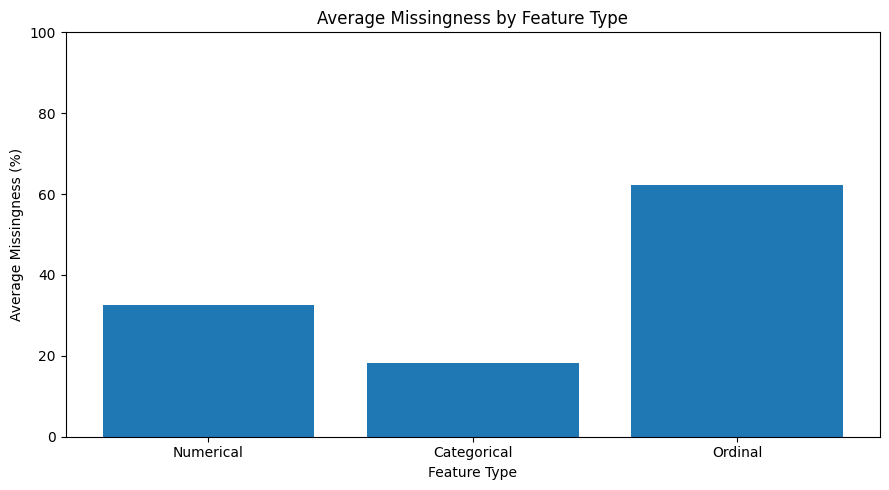

Figure saved successfully: outputs/figures/average_missingness_by_feature_type.png


In [210]:
# Visualize and save average missingness by feature type

import matplotlib.pyplot as plt
from pathlib import Path

# Create figures output directory
figures_dir = Path("outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9, 5))

plt.bar(
    missingness_by_type_df["Feature_Type"],
    missingness_by_type_df["Average_Missing_Percentage"]
)

plt.title("Average Missingness by Feature Type")
plt.xlabel("Feature Type")
plt.ylabel("Average Missingness (%)")
plt.ylim(0, 100)

plt.tight_layout()

# Save figure before displaying
figure_path = figures_dir / "average_missingness_by_feature_type.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()
plt.close()

print("Figure saved successfully:", figure_path)

### 8.44.11 Visualization of Missingness Across Individual Features

This section visualizes the 20 predictors with the highest missing-value percentages.

The chart provides a feature-level comparison of missingness and highlights variables that may require additional investigation before missing-value treatment.

The visualization will support the identification of predictors with substantial missingness and will be saved as a project output.

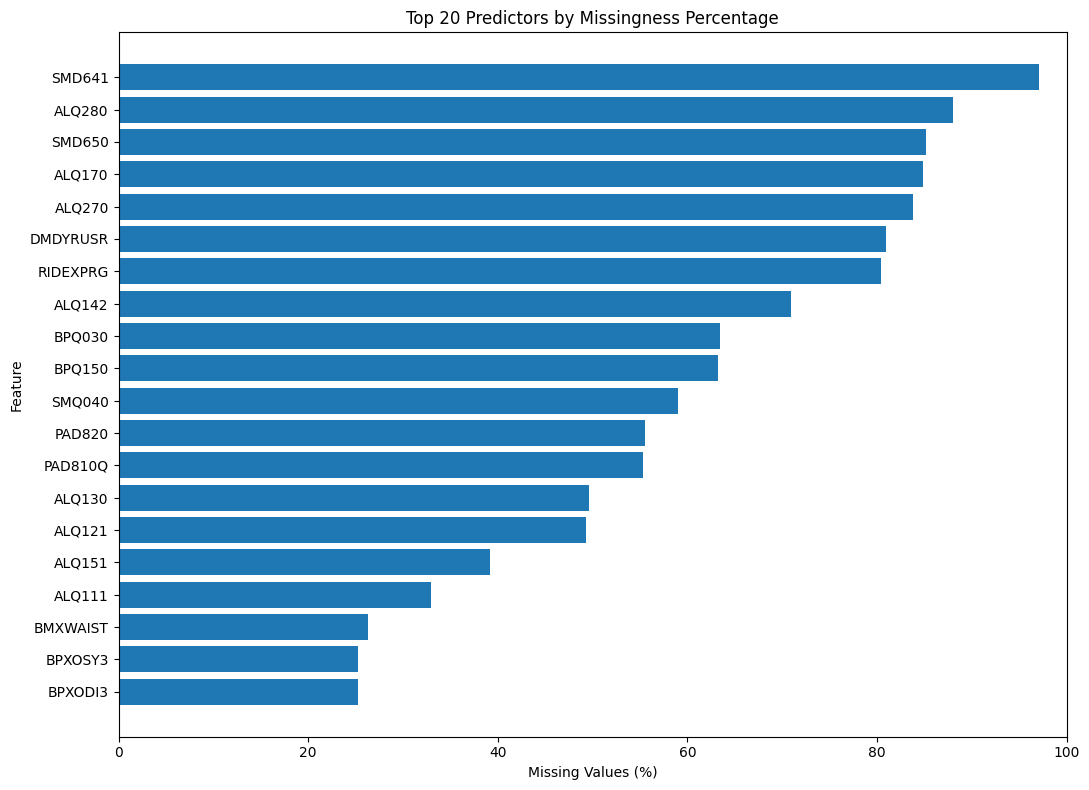

Figure saved successfully: outputs/figures/top_20_features_missingness.png


In [211]:
# Visualize and save the 20 features with highest missingness

import matplotlib.pyplot as plt
from pathlib import Path

figures_dir = Path("outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

top_missing_features = (
    combined_missingness_summary
    .sort_values(
        by="Missing_Percentage",
        ascending=False
    )
    .head(20)
    .sort_values(
        by="Missing_Percentage",
        ascending=True
    )
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_missing_features["Feature"],
    top_missing_features["Missing_Percentage"]
)

plt.title("Top 20 Predictors by Missingness Percentage")
plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.xlim(0, 100)

plt.tight_layout()

figure_path = (
    figures_dir / "top_20_features_missingness.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Figure saved successfully:", figure_path)

### 8.44.12 Visualization of Missingness by Diabetes Status

This section compares missing-value percentages between participants with and without diagnosed diabetes.

The visualization focuses on the 10 predictors with the largest absolute differences in missingness.

The comparison helps identify predictors whose missingness patterns vary across diabetes groups.

This analysis is descriptive and does not establish causation.

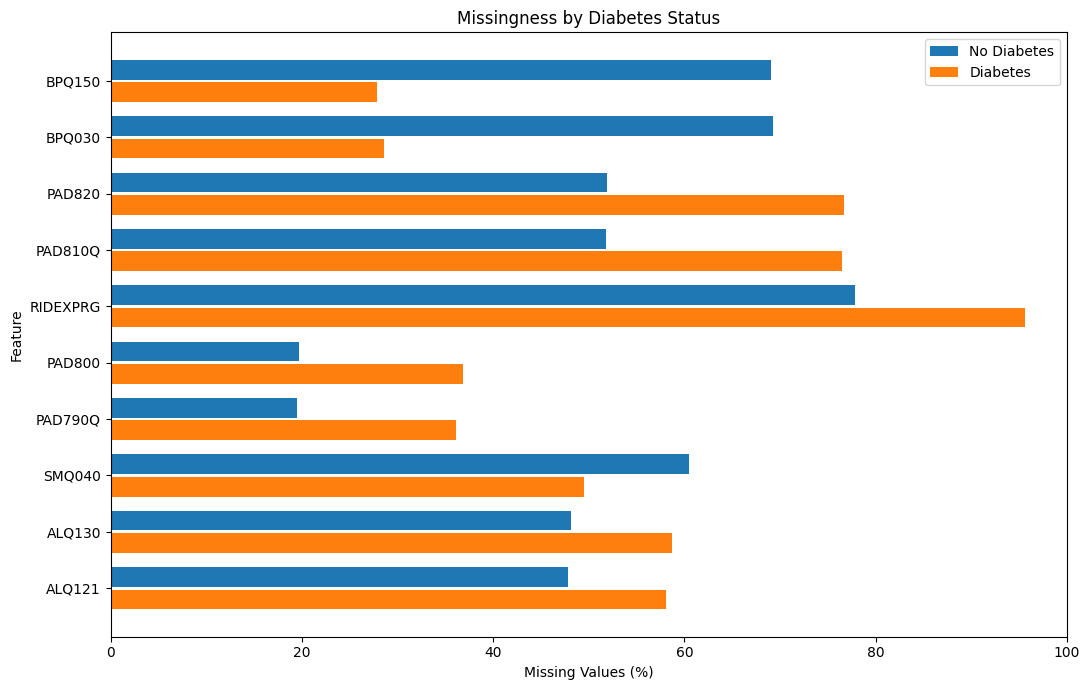

Figure saved successfully: outputs/figures/missingness_by_diabetes_status.png


In [212]:
# Visualize and save missingness differences by diabetes status

import matplotlib.pyplot as plt
from pathlib import Path

figures_dir = Path("outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plot_data = (
    large_missingness_differences
    .sort_values(
        by="Absolute_Difference",
        ascending=True
    )
)

plt.figure(figsize=(11, 7))

y = range(len(plot_data))

plt.barh(
    [i + 0.2 for i in y],
    plot_data["Missing_Percentage_No_Diabetes"],
    height=0.35,
    label="No Diabetes"
)

plt.barh(
    [i - 0.2 for i in y],
    plot_data["Missing_Percentage_Diabetes"],
    height=0.35,
    label="Diabetes"
)

plt.yticks(y, plot_data["Feature"])
plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.title("Missingness by Diabetes Status")
plt.xlim(0, 100)
plt.legend()

plt.tight_layout()

figure_path = (
    figures_dir / "missingness_by_diabetes_status.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Figure saved successfully:", figure_path)

### 8.44.13 Review of Missingness Treatment Considerations

The missingness analysis identified differences across numerical, categorical, and ordinal predictors.

The following considerations will guide the final treatment strategy:

- Numerical measurements will be evaluated for appropriate statistical imputation.
- Categorical variables will be reviewed for questionnaire-related missingness before selecting an imputation method.
- Ordinal variables will be treated in a way that preserves their meaningful ordering.
- Features with high and very high missingness will receive additional eligibility and questionnaire review.
- Features with different missingness patterns across diabetes groups will receive special attention.

No automatic feature removal or imputation will be performed solely based on missingness percentages.

The final treatment decisions will be documented before preparing the modeling dataset.

#### 8.44.13.1 Summary of Missingness Analysis

The missingness assessment covered all 51 predictors and identified:

- 43 predictors with missing values.
- 8 predictors without missing values.
- 17 predictors with high or very high missingness.
- 18 strong relationships between missingness indicators.
- 10 predictors with at least a 10-percentage-point difference in missingness between diabetes groups.

Two visualizations were generated and saved to the project figures directory.

These findings provide the basis for the final missing-value treatment decisions.

### 8.44.14 Identification of Features Requiring Special Missingness Review

This section identifies predictors requiring additional investigation before missing-value treatment.

Features will be selected based on:

- High or very high missingness.
- Large differences in missingness between diabetes groups.
- Potential questionnaire eligibility and skip-pattern considerations.
- The nature and measurement characteristics of each predictor.

The identified features will be reviewed before deciding whether to retain, impute, or exclude them.

A high missingness percentage alone will not be considered sufficient justification for feature removal.

In [213]:
# Identify all features requiring special missingness review

from pathlib import Path

review_features = feature_treatment_assessment.merge(
    missingness_by_diabetes,
    on="Feature",
    how="left"
)

review_features["Large_Diabetes_Group_Difference"] = (
    review_features["Absolute_Difference"] >= 10
)

review_features["Requires_Special_Review"] = (
    review_features["Missingness_Category"].isin(
        ["High", "Very High"]
    )
    | review_features["Large_Diabetes_Group_Difference"]
)

review_features = review_features[
    review_features["Requires_Special_Review"]
].copy()

review_features = review_features.sort_values(
    by="Missing_Percentage",
    ascending=False
).reset_index(drop=True)

# Save the complete review table
tables_dir = Path("outputs/tables")
tables_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    tables_dir / "features_requiring_special_missingness_review.csv"
)

review_features.to_csv(output_path, index=False)

display(review_features.style.hide(axis="index"))

print("\nTotal features requiring special review:",
      len(review_features))

print("Saved successfully:", output_path)

Feature,Feature_Type,Missing_Count,Missing_Percentage,Missingness_Category,Missing_Percentage_No_Diabetes,Missing_Percentage_Diabetes,Absolute_Difference,Large_Diabetes_Group_Difference,Requires_Special_Review
SMD641,Numerical,7313,97.040000,Very High,97.110000,96.640000,0.470000,False,True
ALQ280,Ordinal,6632,88.000000,Very High,87.440000,91.400000,3.960000,False,True
SMD650,Numerical,6416,85.140000,Very High,85.280000,84.300000,0.980000,False,True
ALQ170,Numerical,6394,84.850000,Very High,83.650000,92.060000,8.400000,False,True
ALQ270,Ordinal,6313,83.770000,Very High,83.000000,88.410000,5.410000,False,True
DMDYRUSR,Ordinal,6099,80.930000,Very High,80.930000,80.930000,0.000000,False,True
RIDEXPRG,Categorical,6059,80.400000,Very High,77.880000,95.610000,17.720000,True,True
ALQ142,Ordinal,5345,70.930000,Very High,69.580000,79.070000,9.490000,False,True
BPQ030,Categorical,4782,63.460000,Very High,69.220000,28.600000,40.630000,True,True
BPQ150,Categorical,4762,63.190000,Very High,69.040000,27.850000,41.190000,True,True



Total features requiring special review: 19
Saved successfully: outputs/tables/features_requiring_special_missingness_review.csv


### 8.44.15 Summary of Special-Review Features

This section summarizes the predictors identified for additional missingness investigation.

The review includes features with high or very high missingness and features with substantial missingness differences between diabetes groups.

The predictors will be evaluated according to their feature type and potential questionnaire eligibility or skip-pattern considerations.

This summary supports the final missing-value treatment plan. It does not represent a decision to remove or impute any predictor.

In [214]:
# Summarize special-review features by feature type

special_review_summary = (
    review_features
    .groupby("Feature_Type")
    .agg(
        Total_Features=("Feature", "count"),
        Average_Missingness=("Missing_Percentage", "mean"),
        High_Difference_Count=(
            "Large_Diabetes_Group_Difference", "sum"
        )
    )
    .reset_index()
)

special_review_summary["Average_Missingness"] = (
    special_review_summary["Average_Missingness"].round(2)
)

# Save summary table
tables_dir = Path("outputs/tables")
tables_dir.mkdir(parents=True, exist_ok=True)

summary_path = (
    tables_dir / "special_review_summary_by_feature_type.csv"
)

special_review_summary.to_csv(summary_path, index=False)

display(special_review_summary.style.hide(axis="index"))

print("\nTotal special-review features:",
      special_review_summary["Total_Features"].sum())

print("Saved successfully:", summary_path)

Feature_Type,Total_Features,Average_Missingness,High_Difference_Count
Categorical,6,56.350000,4
Numerical,8,58.930000,5
Ordinal,5,74.590000,1



Total special-review features: 19
Saved successfully: outputs/tables/special_review_summary_by_feature_type.csv


### 8.44.16 NHANES Eligibility and Skip-Pattern Review

Missing values in NHANES data may arise from questionnaire eligibility, skip patterns, participant nonresponse, or unavailable measurements.

This section organizes the 19 special-review predictors according to their NHANES feature groups.

The review will use the corresponding NHANES documentation to investigate:

- Participant eligibility requirements.
- Questionnaire routing and skip patterns.
- Age or demographic restrictions.
- Refused and don't-know responses.
- Whether missing values represent structural missingness or ordinary nonresponse.

No missing-value imputation or feature removal will be performed until the relevant documentation has been reviewed.

In [215]:
# Organize special-review features for NHANES documentation review

feature_group_lookup = {
    "SMD641": "Smoking",
    "SMD650": "Smoking",
    "SMQ040": "Smoking",

    "ALQ280": "Alcohol",
    "ALQ170": "Alcohol",
    "ALQ270": "Alcohol",
    "ALQ142": "Alcohol",
    "ALQ130": "Alcohol",
    "ALQ121": "Alcohol",
    "ALQ151": "Alcohol",
    "ALQ111": "Alcohol",

    "PAD820": "Physical Activity",
    "PAD810Q": "Physical Activity",
    "PAD800": "Physical Activity",
    "PAD790Q": "Physical Activity",

    "DMDYRUSR": "Demographic",
    "RIDEXPRG": "Demographic",

    "BPQ030": "Blood Pressure Questionnaire",
    "BPQ150": "Blood Pressure Questionnaire"
}

nhanes_review_checklist = review_features[
    ["Feature", "Feature_Type", "Missing_Percentage"]
].copy()

nhanes_review_checklist["NHANES_Feature_Group"] = (
    nhanes_review_checklist["Feature"].map(feature_group_lookup)
)

nhanes_review_checklist["Eligibility_Review"] = (
    "Pending documentation review"
)

nhanes_review_checklist["Skip_Pattern_Review"] = (
    "Pending documentation review"
)

nhanes_review_checklist["Treatment_Decision"] = "Not yet decided"

nhanes_review_checklist = nhanes_review_checklist.sort_values(
    by=["NHANES_Feature_Group", "Missing_Percentage"],
    ascending=[True, False]
).reset_index(drop=True)

# Save documentation review checklist
tables_dir = Path("outputs/tables")
tables_dir.mkdir(parents=True, exist_ok=True)

checklist_path = (
    tables_dir / "nhanes_eligibility_skip_pattern_review.csv"
)

nhanes_review_checklist.to_csv(
    checklist_path,
    index=False
)

display(nhanes_review_checklist.style.hide(axis="index"))

print("\nTotal features for documentation review:",
      len(nhanes_review_checklist))

print("Saved successfully:", checklist_path)

Feature,Feature_Type,Missing_Percentage,NHANES_Feature_Group,Eligibility_Review,Skip_Pattern_Review,Treatment_Decision
ALQ280,Ordinal,88.000000,Alcohol,Pending documentation review,Pending documentation review,Not yet decided
ALQ170,Numerical,84.850000,Alcohol,Pending documentation review,Pending documentation review,Not yet decided
ALQ270,Ordinal,83.770000,Alcohol,Pending documentation review,Pending documentation review,Not yet decided
ALQ142,Ordinal,70.930000,Alcohol,Pending documentation review,Pending documentation review,Not yet decided
ALQ130,Numerical,49.620000,Alcohol,Pending documentation review,Pending documentation review,Not yet decided
ALQ121,Ordinal,49.310000,Alcohol,Pending documentation review,Pending documentation review,Not yet decided
ALQ151,Categorical,39.130000,Alcohol,Pending documentation review,Pending documentation review,Not yet decided
ALQ111,Categorical,32.940000,Alcohol,Pending documentation review,Pending documentation review,Not yet decided
BPQ030,Categorical,63.460000,Blood Pressure Questionnaire,Pending documentation review,Pending documentation review,Not yet decided
BPQ150,Categorical,63.190000,Blood Pressure Questionnaire,Pending documentation review,Pending documentation review,Not yet decided



Total features for documentation review: 19
Saved successfully: outputs/tables/nhanes_eligibility_skip_pattern_review.csv


### 8.44.17 Alcohol Questionnaire Eligibility and Skip-Pattern Review

The NHANES ALQ_L documentation was reviewed for the eight alcohol-related predictors.

The documentation confirms that the public-use alcohol questionnaire includes participants aged 18 years and older.

The questionnaire contains skip patterns associated with previous responses. For example, participants reporting no alcohol consumption during the past 12 months may skip certain subsequent questions.

These routing instructions may contribute to missing values in ALQ121, ALQ142, and related variables.

However, not all missing values can be classified as structural missingness from the available documentation alone.

The distinction between questionnaire-related missingness and ordinary nonresponse will be retained during the final treatment decisions.

In [216]:
# Update alcohol documentation review findings

alcohol_findings = {
    "ALQ111": (
        "Adults 18+",
        "No response skips to end of section",
        "Review skip-related missingness"
    ),
    "ALQ121": (
        "Adults 18+",
        "Response 0 skips to ALQ151",
        "Review skip-related missingness"
    ),
    "ALQ130": (
        "Adults 18+",
        "No specific skip established in reviewed excerpt",
        "Review nonresponse and eligibility"
    ),
    "ALQ142": (
        "Adults 18+",
        "Response 0 skips to ALQ151",
        "Review skip-related missingness"
    ),
    "ALQ151": (
        "Adults 18+",
        "No specific skip established in reviewed excerpt",
        "Review nonresponse and eligibility"
    ),
    "ALQ170": (
        "Adults 18+",
        "No specific skip established in reviewed excerpt",
        "Review nonresponse and eligibility"
    ),
    "ALQ270": (
        "Adults 18+",
        "No specific skip established in reviewed excerpt",
        "Review nonresponse and eligibility"
    ),
    "ALQ280": (
        "Adults 18+",
        "No specific skip established in reviewed excerpt",
        "Review nonresponse and eligibility"
    )
}

for feature, findings in alcohol_findings.items():
    mask = nhanes_review_checklist["Feature"] == feature

    nhanes_review_checklist.loc[mask, "Eligibility_Review"] = findings[0]
    nhanes_review_checklist.loc[mask, "Skip_Pattern_Review"] = findings[1]
    nhanes_review_checklist.loc[mask, "Treatment_Decision"] = findings[2]

# Save updated checklist
checklist_path = (
    Path("outputs/tables") /
    "nhanes_eligibility_skip_pattern_review.csv"
)

nhanes_review_checklist.to_csv(checklist_path, index=False)

display(
    nhanes_review_checklist[
        nhanes_review_checklist["NHANES_Feature_Group"] == "Alcohol"
    ].style.hide(axis="index")
)

print("Alcohol features reviewed:", len(alcohol_findings))
print("Updated checklist saved:", checklist_path)

Feature,Feature_Type,Missing_Percentage,NHANES_Feature_Group,Eligibility_Review,Skip_Pattern_Review,Treatment_Decision
ALQ280,Ordinal,88.000000,Alcohol,Adults 18+,No specific skip established in reviewed excerpt,Review nonresponse and eligibility
ALQ170,Numerical,84.850000,Alcohol,Adults 18+,No specific skip established in reviewed excerpt,Review nonresponse and eligibility
ALQ270,Ordinal,83.770000,Alcohol,Adults 18+,No specific skip established in reviewed excerpt,Review nonresponse and eligibility
ALQ142,Ordinal,70.930000,Alcohol,Adults 18+,Response 0 skips to ALQ151,Review skip-related missingness
ALQ130,Numerical,49.620000,Alcohol,Adults 18+,No specific skip established in reviewed excerpt,Review nonresponse and eligibility
ALQ121,Ordinal,49.310000,Alcohol,Adults 18+,Response 0 skips to ALQ151,Review skip-related missingness
ALQ151,Categorical,39.130000,Alcohol,Adults 18+,No specific skip established in reviewed excerpt,Review nonresponse and eligibility
ALQ111,Categorical,32.940000,Alcohol,Adults 18+,No response skips to end of section,Review skip-related missingness


Alcohol features reviewed: 8
Updated checklist saved: outputs/tables/nhanes_eligibility_skip_pattern_review.csv


### 8.44.18 Blood Pressure Questionnaire Eligibility and Skip-Pattern Review

The NHANES BPQ_L documentation was reviewed for BPQ030 and BPQ150.

The questionnaire was administered to participants aged 16 years and older.

BPQ030 asks whether participants were told on two or more different visits that they had high blood pressure.

BPQ150 asks whether participants are currently taking medication prescribed for high blood pressure.

The 2021–2023 NHANES cycle introduced a change in the blood pressure medication question's skip pattern. BPQ150 replaced BPQ050A from earlier cycles.

These questionnaire details may contribute to missing observations. However, the available documentation does not establish the reason for every missing value.

Missing observations will therefore be reviewed before deciding on imputation or exclusion.

In [217]:
# Update blood pressure questionnaire documentation findings

bpq_findings = {
    "BPQ030": (
        "Participants aged 16+",
        "Questionnaire routing requires review of BPQ020 responses",
        "Review questionnaire-related missingness"
    ),
    "BPQ150": (
        "Participants aged 16+",
        "2021-2023 medication question uses revised skip pattern",
        "Review questionnaire-related missingness"
    )
}

for feature, findings in bpq_findings.items():
    mask = nhanes_review_checklist["Feature"] == feature

    nhanes_review_checklist.loc[mask, "Eligibility_Review"] = findings[0]
    nhanes_review_checklist.loc[mask, "Skip_Pattern_Review"] = findings[1]
    nhanes_review_checklist.loc[mask, "Treatment_Decision"] = findings[2]

# Save updated checklist
checklist_path = (
    Path("outputs/tables") /
    "nhanes_eligibility_skip_pattern_review.csv"
)

nhanes_review_checklist.to_csv(checklist_path, index=False)

display(
    nhanes_review_checklist[
        nhanes_review_checklist["NHANES_Feature_Group"]
        == "Blood Pressure Questionnaire"
    ].style.hide(axis="index")
)

print("\nBlood pressure features reviewed:", len(bpq_findings))
print("Updated checklist saved:", checklist_path)

Feature,Feature_Type,Missing_Percentage,NHANES_Feature_Group,Eligibility_Review,Skip_Pattern_Review,Treatment_Decision
BPQ030,Categorical,63.460000,Blood Pressure Questionnaire,Participants aged 16+,Questionnaire routing requires review of BPQ020 responses,Review questionnaire-related missingness
BPQ150,Categorical,63.190000,Blood Pressure Questionnaire,Participants aged 16+,2021-2023 medication question uses revised skip pattern,Review questionnaire-related missingness



Blood pressure features reviewed: 2
Updated checklist saved: outputs/tables/nhanes_eligibility_skip_pattern_review.csv


### 8.44.19 Smoking Questionnaire Eligibility and Skip-Pattern Review

The NHANES SMQ_L documentation was reviewed for SMD641, SMD650, and SMQ040.

The smoking questionnaire was administered to participants aged 12 years and older. However, question eligibility varied by age.

SMD641 records the number of days cigarettes were smoked during the past 30 days. SMD650 records the average number of cigarettes smoked per day during the past 30 days. Both variables have an eligible age range of 12 years and older.

SMQ040 records current cigarette smoking frequency and is specifically targeted at adults aged 18 years and older.

The NHANES documentation identifies a skip pattern involving SMQ020 and SMQ040. Participants who did not report smoking at least 100 cigarettes during their lifetime were not asked the follow-up current-smoking question.

Therefore, missing observations in these variables may reflect age eligibility or questionnaire routing rather than ordinary nonresponse.

These patterns will be considered before selecting missing-value treatment methods.

In [218]:
# Update smoking questionnaire documentation findings

smoking_findings = {
    "SMD641": (
        "Participants aged 12+",
        "Age-specific questionnaire routing; review past-30-day smoking eligibility",
        "Review eligibility-related missingness"
    ),
    "SMD650": (
        "Participants aged 12+",
        "Age-specific questionnaire routing; review past-30-day smoking eligibility",
        "Review eligibility-related missingness"
    ),
    "SMQ040": (
        "Adults aged 18+",
        "SMQ020 responses of No, Refused, or Don't know skip the follow-up question",
        "Review skip-related missingness"
    )
}

for feature, findings in smoking_findings.items():
    mask = nhanes_review_checklist["Feature"] == feature

    nhanes_review_checklist.loc[mask, "Eligibility_Review"] = findings[0]
    nhanes_review_checklist.loc[mask, "Skip_Pattern_Review"] = findings[1]
    nhanes_review_checklist.loc[mask, "Treatment_Decision"] = findings[2]

# Save updated checklist
checklist_path = (
    Path("outputs/tables") /
    "nhanes_eligibility_skip_pattern_review.csv"
)

nhanes_review_checklist.to_csv(checklist_path, index=False)

display(
    nhanes_review_checklist[
        nhanes_review_checklist["NHANES_Feature_Group"] == "Smoking"
    ].style.hide(axis="index")
)

print("\nSmoking features reviewed:", len(smoking_findings))
print("Updated checklist saved:", checklist_path)

Feature,Feature_Type,Missing_Percentage,NHANES_Feature_Group,Eligibility_Review,Skip_Pattern_Review,Treatment_Decision
SMD641,Numerical,97.040000,Smoking,Participants aged 12+,Age-specific questionnaire routing; review past-30-day smoking eligibility,Review eligibility-related missingness
SMD650,Numerical,85.140000,Smoking,Participants aged 12+,Age-specific questionnaire routing; review past-30-day smoking eligibility,Review eligibility-related missingness
SMQ040,Categorical,58.960000,Smoking,Adults aged 18+,"SMQ020 responses of No, Refused, or Don't know skip the follow-up question",Review skip-related missingness



Smoking features reviewed: 3
Updated checklist saved: outputs/tables/nhanes_eligibility_skip_pattern_review.csv


### 8.44.20 Demographic Eligibility and Missingness Review

The NHANES DEMO_L documentation was reviewed for DMDYRUSR and RIDEXPRG.

DMDYRUSR represents the length of time a participant has lived in the United States. Participants born outside the United States were asked when they came to live in the country. Therefore, missing values may reflect participants who were born in the United States and were not eligible for this question.

RIDEXPRG represents pregnancy status at the time of the health examination. Although pregnancy status was ascertained for females aged 8–59, public-use values are released only for females aged 20–44 due to disclosure concerns.

RIDEXPRG value 3 indicates that pregnancy status could not be determined. This is a valid response category and must not be treated as an ordinary missing value.

These eligibility and disclosure-related restrictions must be considered before selecting missing-value treatment methods.

In [219]:
# Update demographic eligibility and missingness findings

demographic_findings = {
    "DMDYRUSR": (
        "Participants born outside the United States",
        "Question applies to participants born outside the U.S.; U.S.-born participants are not asked",
        "Review structural missingness related to country of birth"
    ),
    "RIDEXPRG": (
        "Females aged 20–44 in the public-use release",
        "Values released only for females aged 20–44 due to disclosure concerns",
        "Review age- and sex-related structural missingness"
    )
}

for feature, findings in demographic_findings.items():
    mask = nhanes_review_checklist["Feature"] == feature

    nhanes_review_checklist.loc[mask, "Eligibility_Review"] = findings[0]
    nhanes_review_checklist.loc[mask, "Skip_Pattern_Review"] = findings[1]
    nhanes_review_checklist.loc[mask, "Treatment_Decision"] = findings[2]

# Save updated checklist
checklist_path = (
    Path("outputs/tables") /
    "nhanes_eligibility_skip_pattern_review.csv"
)

nhanes_review_checklist.to_csv(checklist_path, index=False)

display(
    nhanes_review_checklist[
        nhanes_review_checklist["NHANES_Feature_Group"] == "Demographic"
    ].style.hide(axis="index")
)

print("\nDemographic features reviewed:", len(demographic_findings))
print("Updated checklist saved:", checklist_path)

Feature,Feature_Type,Missing_Percentage,NHANES_Feature_Group,Eligibility_Review,Skip_Pattern_Review,Treatment_Decision
DMDYRUSR,Ordinal,80.930000,Demographic,Participants born outside the United States,Question applies to participants born outside the U.S.; U.S.-born participants are not asked,Review structural missingness related to country of birth
RIDEXPRG,Categorical,80.400000,Demographic,Females aged 20–44 in the public-use release,Values released only for females aged 20–44 due to disclosure concerns,Review age- and sex-related structural missingness



Demographic features reviewed: 2
Updated checklist saved: outputs/tables/nhanes_eligibility_skip_pattern_review.csv


### 8.44.21 Physical Activity Eligibility and Skip-Pattern Review

The NHANES PAQ_L documentation was reviewed for PAD820, PAD810Q, PAD800, and PAD790Q.

The adult Physical Activity questionnaire was administered to participants aged 18 years and older.

PAD790Q records the frequency of moderate-intensity leisure-time physical activity, while PAD810Q records the frequency of vigorous-intensity leisure-time physical activity.

The questionnaire records activity frequency and its corresponding unit, such as day, week, month, or year.

NHANES documentation indicates that reported activity averaging 24 hours or more per day was set to missing during data processing.

The available documentation reviewed does not establish the reason for every missing observation in these four variables. Therefore, missingness will be reviewed in relation to questionnaire eligibility, response routing, and nonresponse before selecting treatment methods.

In [220]:
# Update physical activity questionnaire documentation findings

physical_activity_findings = {
    "PAD820": (
        "Participants aged 18+",
        "Review questionnaire routing and corresponding activity responses",
        "Review eligibility and questionnaire-related missingness"
    ),
    "PAD810Q": (
        "Participants aged 18+",
        "Vigorous leisure-time activity frequency; review related unit and response routing",
        "Review eligibility and questionnaire-related missingness"
    ),
    "PAD800": (
        "Participants aged 18+",
        "Review questionnaire routing and corresponding activity responses",
        "Review eligibility and questionnaire-related missingness"
    ),
    "PAD790Q": (
        "Participants aged 18+",
        "Moderate leisure-time activity frequency; review related unit and response routing",
        "Review eligibility and questionnaire-related missingness"
    )
}

for feature, findings in physical_activity_findings.items():
    mask = nhanes_review_checklist["Feature"] == feature

    nhanes_review_checklist.loc[mask, "Eligibility_Review"] = findings[0]
    nhanes_review_checklist.loc[mask, "Skip_Pattern_Review"] = findings[1]
    nhanes_review_checklist.loc[mask, "Treatment_Decision"] = findings[2]

# Save updated checklist
checklist_path = (
    Path("outputs/tables") /
    "nhanes_eligibility_skip_pattern_review.csv"
)

nhanes_review_checklist.to_csv(checklist_path, index=False)

display(
    nhanes_review_checklist[
        nhanes_review_checklist["NHANES_Feature_Group"] == "Physical Activity"
    ].style.hide(axis="index")
)

print("\nPhysical activity features reviewed:", len(physical_activity_findings))
print("Updated checklist saved:", checklist_path)

Feature,Feature_Type,Missing_Percentage,NHANES_Feature_Group,Eligibility_Review,Skip_Pattern_Review,Treatment_Decision
PAD820,Numerical,55.480000,Physical Activity,Participants aged 18+,Review questionnaire routing and corresponding activity responses,Review eligibility and questionnaire-related missingness
PAD810Q,Numerical,55.320000,Physical Activity,Participants aged 18+,Vigorous leisure-time activity frequency; review related unit and response routing,Review eligibility and questionnaire-related missingness
PAD800,Numerical,22.120000,Physical Activity,Participants aged 18+,Review questionnaire routing and corresponding activity responses,Review eligibility and questionnaire-related missingness
PAD790Q,Numerical,21.880000,Physical Activity,Participants aged 18+,Moderate leisure-time activity frequency; review related unit and response routing,Review eligibility and questionnaire-related missingness



Physical activity features reviewed: 4
Updated checklist saved: outputs/tables/nhanes_eligibility_skip_pattern_review.csv


### 8.44.22 Consolidated Missingness and Eligibility Review

This section consolidates the missingness and NHANES eligibility/skip-pattern review for all 19 special-review features. The resulting table will be saved for the final data-cleaning documentation.

In [221]:
special_review_summary = (
    nhanes_review_checklist[
        [
            "Feature",
            "Feature_Type",
            "Missing_Percentage",
            "NHANES_Feature_Group",
            "Eligibility_Review",
            "Skip_Pattern_Review",
            "Treatment_Decision"
        ]
    ]
    .copy()
    .sort_values(
        ["NHANES_Feature_Group", "Feature"]
    )
    .reset_index(drop=True)
)

summary_path = (
    Path("outputs/tables") /
    "consolidated_special_missingness_review.csv"
)

special_review_summary.to_csv(
    summary_path,
    index=False
)

display(special_review_summary)

print("Special-review features:", len(special_review_summary))
print("Saved:", summary_path)

,Feature,Feature_Type,Missing_Percentage,NHANES_Feature_Group,Eligibility_Review,Skip_Pattern_Review,Treatment_Decision
0,ALQ111,Categorical,32.94,Alcohol,Adults 18+,No response skips to end of section,Review skip-related missingness
1,ALQ121,Ordinal,49.31,Alcohol,Adults 18+,Response 0 skips to ALQ151,Review skip-related missingness
2,ALQ130,Numerical,49.62,Alcohol,Adults 18+,No specific skip established in reviewed excerpt,Review nonresponse and eligibility
3,ALQ142,Ordinal,70.93,Alcohol,Adults 18+,Response 0 skips to ALQ151,Review skip-related missingness
4,ALQ151,Categorical,39.13,Alcohol,Adults 18+,No specific skip established in reviewed excerpt,Review nonresponse and eligibility
5,ALQ170,Numerical,84.85,Alcohol,Adults 18+,No specific skip established in reviewed excerpt,Review nonresponse and eligibility
6,ALQ270,Ordinal,83.77,Alcohol,Adults 18+,No specific skip established in reviewed excerpt,Review nonresponse and eligibility
7,ALQ280,Ordinal,88.00,Alcohol,Adults 18+,No specific skip established in reviewed excerpt,Review nonresponse and eligibility
8,BPQ030,Categorical,63.46,Blood Pressure Questionnaire,Participants aged 16+,Questionnaire routing requires review of BPQ02...,Review questionnaire-related missingness
9,BPQ150,Categorical,63.19,Blood Pressure Questionnaire,Participants aged 16+,2021-2023 medication question uses revised ski...,Review questionnaire-related missingness


Special-review features: 19
Saved: outputs/tables/consolidated_special_missingness_review.csv


### 8.44.23 Final Missingness Treatment Decisions

Missing values will be classified into three categories:

1. **Structural missingness:** Values unavailable because of age, sex, birthplace, or other NHANES eligibility restrictions.
2. **Skip-pattern missingness:** Values not collected because a participant's previous response routed them past a follow-up question.
3. **Genuine nonresponse:** Values missing because of refusal, uncertainty, or unanswered questions.

Structural and skip-pattern missingness will not automatically be treated as ordinary missing values. Genuine nonresponse will be handled during the modeling preprocessing stage. No imputation is performed in this section.

In [222]:
missingness_treatment_plan = pd.DataFrame([
    {
        "Missingness_Category": "Structural missingness",
        "Identification": "Age-, sex-, or birthplace-related eligibility restrictions",
        "Treatment_Plan": "Preserve as missing; assess feature suitability during preprocessing"
    },
    {
        "Missingness_Category": "Skip-pattern missingness",
        "Identification": "Missing values caused by previous questionnaire responses",
        "Treatment_Plan": "Preserve as missing; do not automatically impute"
    },
    {
        "Missingness_Category": "Genuine nonresponse",
        "Identification": "Refused, don't know, or unanswered responses",
        "Treatment_Plan": "Evaluate appropriate imputation or missingness handling during preprocessing"
    }
])

treatment_path = (
    Path("outputs/tables") /
    "final_missingness_treatment_plan.csv"
)

missingness_treatment_plan.to_csv(
    treatment_path,
    index=False
)

display(missingness_treatment_plan)

print("Treatment categories:", len(missingness_treatment_plan))
print("Saved:", treatment_path)

,Missingness_Category,Identification,Treatment_Plan
0,Structural missingness,"Age-, sex-, or birthplace-related eligibility ...",Preserve as missing; assess feature suitabilit...
1,Skip-pattern missingness,Missing values caused by previous questionnair...,Preserve as missing; do not automatically impute
2,Genuine nonresponse,"Refused, don't know, or unanswered responses",Evaluate appropriate imputation or missingness...


Treatment categories: 3
Saved: outputs/tables/final_missingness_treatment_plan.csv


## 8.45 Final Data Cleaning Validation

This section performs the final checks on the cleaned NHANES dataset before exploratory data analysis. It verifies dataset dimensions, data types, duplicate records, target distribution, and remaining missing values. The validated cleaned dataset will be saved for subsequent analysis.

In [223]:
# 7. Resolve project root (notebooks is one level below it)
project_root = Path.cwd().parent

# Create output directories if they do not exist
processed_dir = project_root / "data" / "processed"
tables_dir = project_root / "outputs" / "tables"

processed_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

# Save final cleaned dataset
cleaned_path = processed_dir / "nhanes_diabetes_cleaned.csv"
cleaning_df.to_csv(cleaned_path, index=False)

# Save modeling dataset
modeling_path = processed_dir / "nhanes_diabetes_modeling.csv"
ml_df.to_csv(modeling_path, index=False)

# Save validation report
validation_path = tables_dir / "final_cleaning_missingness_validation.csv"
missing_summary.to_csv(validation_path)

print("Final cleaned dataset saved:", cleaned_path)
print("Final modeling dataset saved:", modeling_path)
print("Validation report saved:", validation_path)

print("\nFinal cleaning dimensions:")
print("Cleaning dataset:", cleaning_df.shape)
print("Modeling dataset:", ml_df.shape)

Final cleaned dataset saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/data/processed/nhanes_diabetes_cleaned.csv
Final modeling dataset saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/data/processed/nhanes_diabetes_modeling.csv
Validation report saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/final_cleaning_missingness_validation.csv

Final cleaning dimensions:
Cleaning dataset: (7536, 57)
Modeling dataset: (7536, 52)


# 9. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution, patterns, and relationships within the cleaned NHANES dataset. This section examines the target variable and predictor features before machine learning preprocessing and model development.

## 9.1 Target Variable Distribution

The target variable `DIABETES` represents whether an adult participant reported having been diagnosed with diabetes. Its distribution is examined to understand the proportion of participants with and without diabetes and identify potential class imbalance.

,Participant_Count,Percentage
DIABETES,,
No Diabetes,6466,85.8
Diabetes,1070,14.2


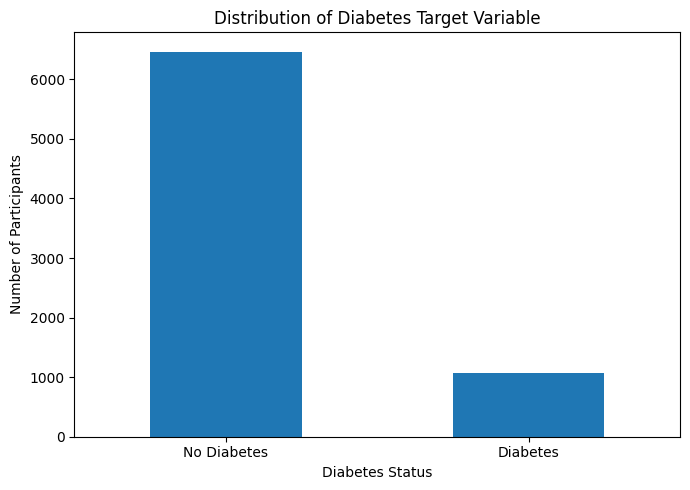

Table saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/diabetes_target_distribution.csv
Figure saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/figures/diabetes_target_distribution.png


In [224]:
import matplotlib.pyplot as plt
from pathlib import Path

# Use the final modeling dataset
eda_df = ml_df.copy()

# Project output directory
project_root = Path.cwd().parent
tables_dir = project_root / "outputs" / "tables"
figures_dir = project_root / "outputs" / "figures"

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Target distribution
target_summary = (
    eda_df["DIABETES"]
    .value_counts()
    .sort_index()
    .rename(index={0: "No Diabetes", 1: "Diabetes"})
    .to_frame("Participant_Count")
)

target_summary["Percentage"] = (
    target_summary["Participant_Count"]
    / target_summary["Participant_Count"].sum()
    * 100
).round(2)

display(target_summary)

# Save summary table
target_summary.to_csv(
    tables_dir / "diabetes_target_distribution.csv"
)

# Plot target distribution
plt.figure(figsize=(7, 5))

target_summary["Participant_Count"].plot(
    kind="bar",
    rot=0
)

plt.title("Distribution of Diabetes Target Variable")
plt.xlabel("Diabetes Status")
plt.ylabel("Number of Participants")
plt.tight_layout()

# Save figure before displaying
plt.savefig(
    figures_dir / "diabetes_target_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Table saved:", tables_dir / "diabetes_target_distribution.csv")
print("Figure saved:", figures_dir / "diabetes_target_distribution.png")

### 9.2 Numerical Feature Distribution

This section examines the distributions of numerical predictor variables using descriptive statistics and histograms. The analysis helps identify skewness, unusual values, and potential outliers before data preprocessing and model development.

,count,mean,std,min,25%,50%,75%,max
RIDAGEYR,7536.0,53.34,17.57,20.00,38.00,56.00,68.00,80.0
INDFMPIR,6191.0,2.94,1.65,0.01,1.44,2.85,5.00,5.0
BMXBMI,5752.0,29.74,7.32,11.10,24.60,28.40,33.50,74.8
BMXWT,5765.0,83.09,22.22,27.90,67.40,79.80,95.10,248.2
BMXHT,5779.0,166.94,10.06,133.00,159.60,166.50,174.25,200.7
BMXWAIST,5553.0,100.82,16.79,60.00,88.70,99.30,111.10,187.0
BPXOSY1,5651.0,122.95,18.48,75.00,110.00,120.00,133.00,232.0
BPXOSY2,5644.0,122.81,18.43,65.00,110.00,120.00,133.00,233.0
BPXOSY3,5631.0,122.60,18.35,62.00,110.00,120.00,132.00,232.0
BPXODI1,5651.0,75.29,11.35,37.00,68.00,75.00,82.00,142.0


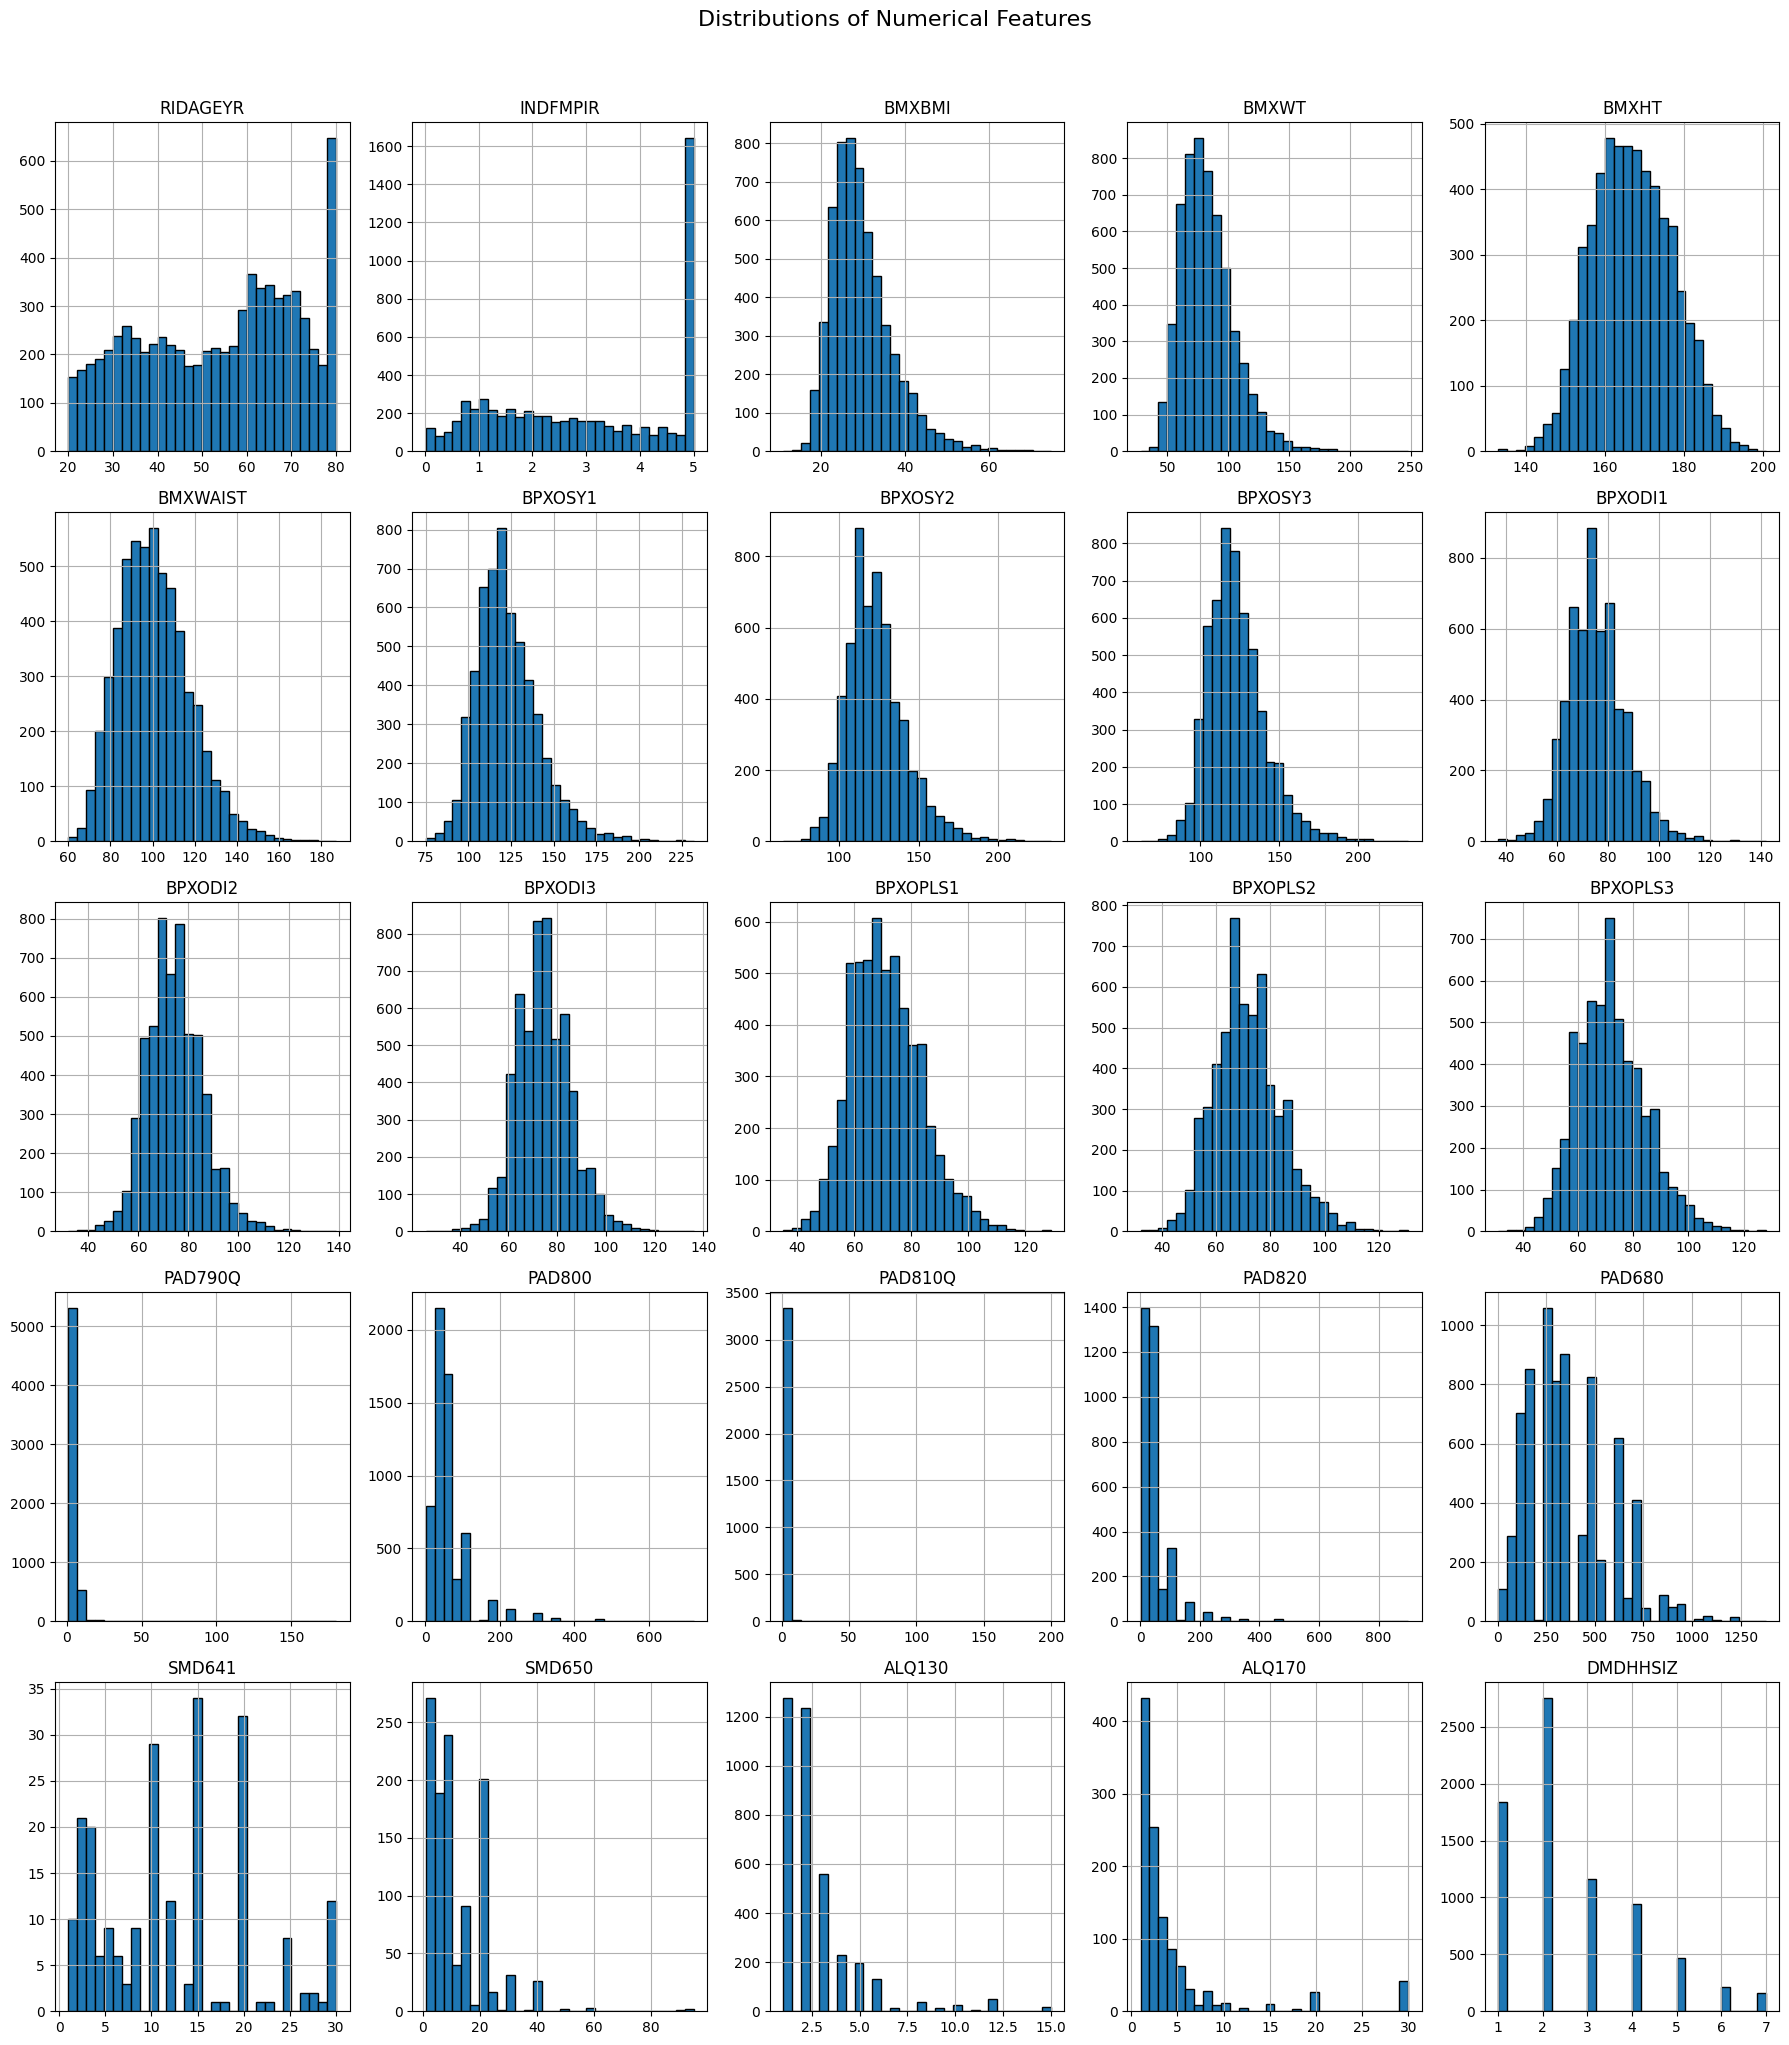

Table saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/numerical_features_descriptive_statistics.csv
Figure saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/figures/numerical_features_distributions.png


In [225]:
# Numerical feature descriptive statistics
numerical_summary = eda_df[numerical_features].describe().T

display(numerical_summary.round(2))

# Save descriptive statistics
numerical_summary.to_csv(
    tables_dir / "numerical_features_descriptive_statistics.csv"
)

# Plot numerical feature distributions
eda_df[numerical_features].hist(
    figsize=(18, 20),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distributions of Numerical Features",
    fontsize=16,
    y=1.02
)

plt.tight_layout()

# Save figure
plt.savefig(
    figures_dir / "numerical_features_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Table saved:",
    tables_dir / "numerical_features_descriptive_statistics.csv"
)

print(
    "Figure saved:",
    figures_dir / "numerical_features_distributions.png"
)

### 9.3 Categorical Feature Distribution

This section examines the frequency distribution of categorical predictor variables. Frequency tables and bar charts are used to understand participant characteristics, identify dominant categories, and observe the distribution of responses across categorical features.

In [226]:
# Categorical feature frequency tables
categorical_summary = {}

for feature in categorical_features:
    counts = eda_df[feature].value_counts(dropna=False)

    categorical_summary[feature] = pd.DataFrame({
        "Category": counts.index.astype(str),
        "Count": counts.values,
        "Percentage": (
            counts.values / len(eda_df) * 100
        ).round(2)
    })

# Display frequency tables
for feature, summary in categorical_summary.items():
    print(f"\n{feature}")
    display(summary)

# Save all categorical frequency tables
categorical_frequency = pd.concat(
    [
        summary.assign(Feature=feature)
        for feature, summary in categorical_summary.items()
    ],
    ignore_index=True
)

categorical_frequency = categorical_frequency[
    ["Feature", "Category", "Count", "Percentage"]
]

categorical_frequency.to_csv(
    tables_dir / "categorical_features_frequency.csv",
    index=False
)

print(
    "\nTable saved:",
    tables_dir / "categorical_features_frequency.csv"
)


RIDSTATR


,Category,Count,Percentage
0,2.0,5843,77.53
1,1.0,1693,22.47



RIAGENDR


,Category,Count,Percentage
0,2.0,4171,55.35
1,1.0,3365,44.65



RIDRETH1


,Category,Count,Percentage
0,3.0,4419,58.64
1,4.0,959,12.73
2,5.0,883,11.72
3,2.0,748,9.93
4,1.0,527,6.99


... (31 outputs left out)

,Category,Count,Percentage
0,1.0,4607,61.13
1,nan,2482,32.94
2,2.0,447,5.93



ALQ151


,Category,Count,Percentage
0,2.0,3727,49.46
1,nan,2949,39.13
2,1.0,860,11.41



Table saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/categorical_features_frequency.csv


### 9.4 Ordinal Feature Distribution

This section examines ordinal predictor variables using frequency distributions. The analysis identifies the most common response categories and examines the distribution of ordered responses before preprocessing.

In [227]:
# Ordinal feature frequency tables
ordinal_summary = {}

for feature in ordinal_features:
    counts = eda_df[feature].value_counts(dropna=False).sort_index()

    ordinal_summary[feature] = pd.DataFrame({
        "Category": counts.index.astype(str),
        "Count": counts.values,
        "Percentage": (
            counts.values / len(eda_df) * 100
        ).round(2)
    })

# Display frequency tables
for feature, summary in ordinal_summary.items():
    print(f"\n{feature}")
    display(summary)

# Combine and save all ordinal frequency tables
ordinal_frequency = pd.concat(
    [
        summary.assign(Feature=feature)
        for feature, summary in ordinal_summary.items()
    ],
    ignore_index=True
)

ordinal_frequency = ordinal_frequency[
    ["Feature", "Category", "Count", "Percentage"]
]

ordinal_frequency.to_csv(
    tables_dir / "ordinal_features_frequency.csv",
    index=False
)

print(
    "\nTable saved:",
    tables_dir / "ordinal_features_frequency.csv"
)


DMDYRUSR


,Category,Count,Percentage
0,1.0,60,0.80
1,2.0,140,1.86
2,3.0,141,1.87
3,4.0,111,1.47
4,5.0,139,1.84
5,6.0,846,11.23
6,nan,6099,80.93



DMDEDUC2


,Category,Count,Percentage
0,1.0,350,4.64
1,2.0,633,8.40
2,3.0,1689,22.41
3,4.0,2292,30.41
4,5.0,2548,33.81
5,9.0,11,0.15
6,nan,13,0.17



ALQ121


,Category,Count,Percentage
0,1.0,157,2.08
1,2.0,291,3.86
2,3.0,440,5.84
3,4.0,468,6.21
4,5.0,407,5.40
5,6.0,537,7.13
6,7.0,331,4.39
7,8.0,239,3.17
8,9.0,472,6.26
9,10.0,478,6.34


... (3 outputs left out)

,Category,Count,Percentage
0,1.0,12,0.16
1,2.0,33,0.44
2,3.0,53,0.70
3,4.0,69,0.92
4,5.0,91,1.21
5,6.0,116,1.54
6,7.0,170,2.26
7,8.0,69,0.92
8,9.0,152,2.02
9,10.0,458,6.08



ALQ280


,Category,Count,Percentage
0,1.0,12,0.16
1,2.0,19,0.25
2,3.0,33,0.44
3,4.0,48,0.64
4,5.0,71,0.94
5,6.0,75,1.00
6,7.0,113,1.50
7,8.0,75,1.00
8,9.0,110,1.46
9,10.0,348,4.62



Table saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/ordinal_features_frequency.csv


### 9.5 Correlation Analysis

This section examines correlations among numerical predictor variables using the Pearson correlation coefficient. A correlation matrix and heatmap are used to identify strongly associated features and potential multicollinearity. Correlation indicates association and does not establish causation.

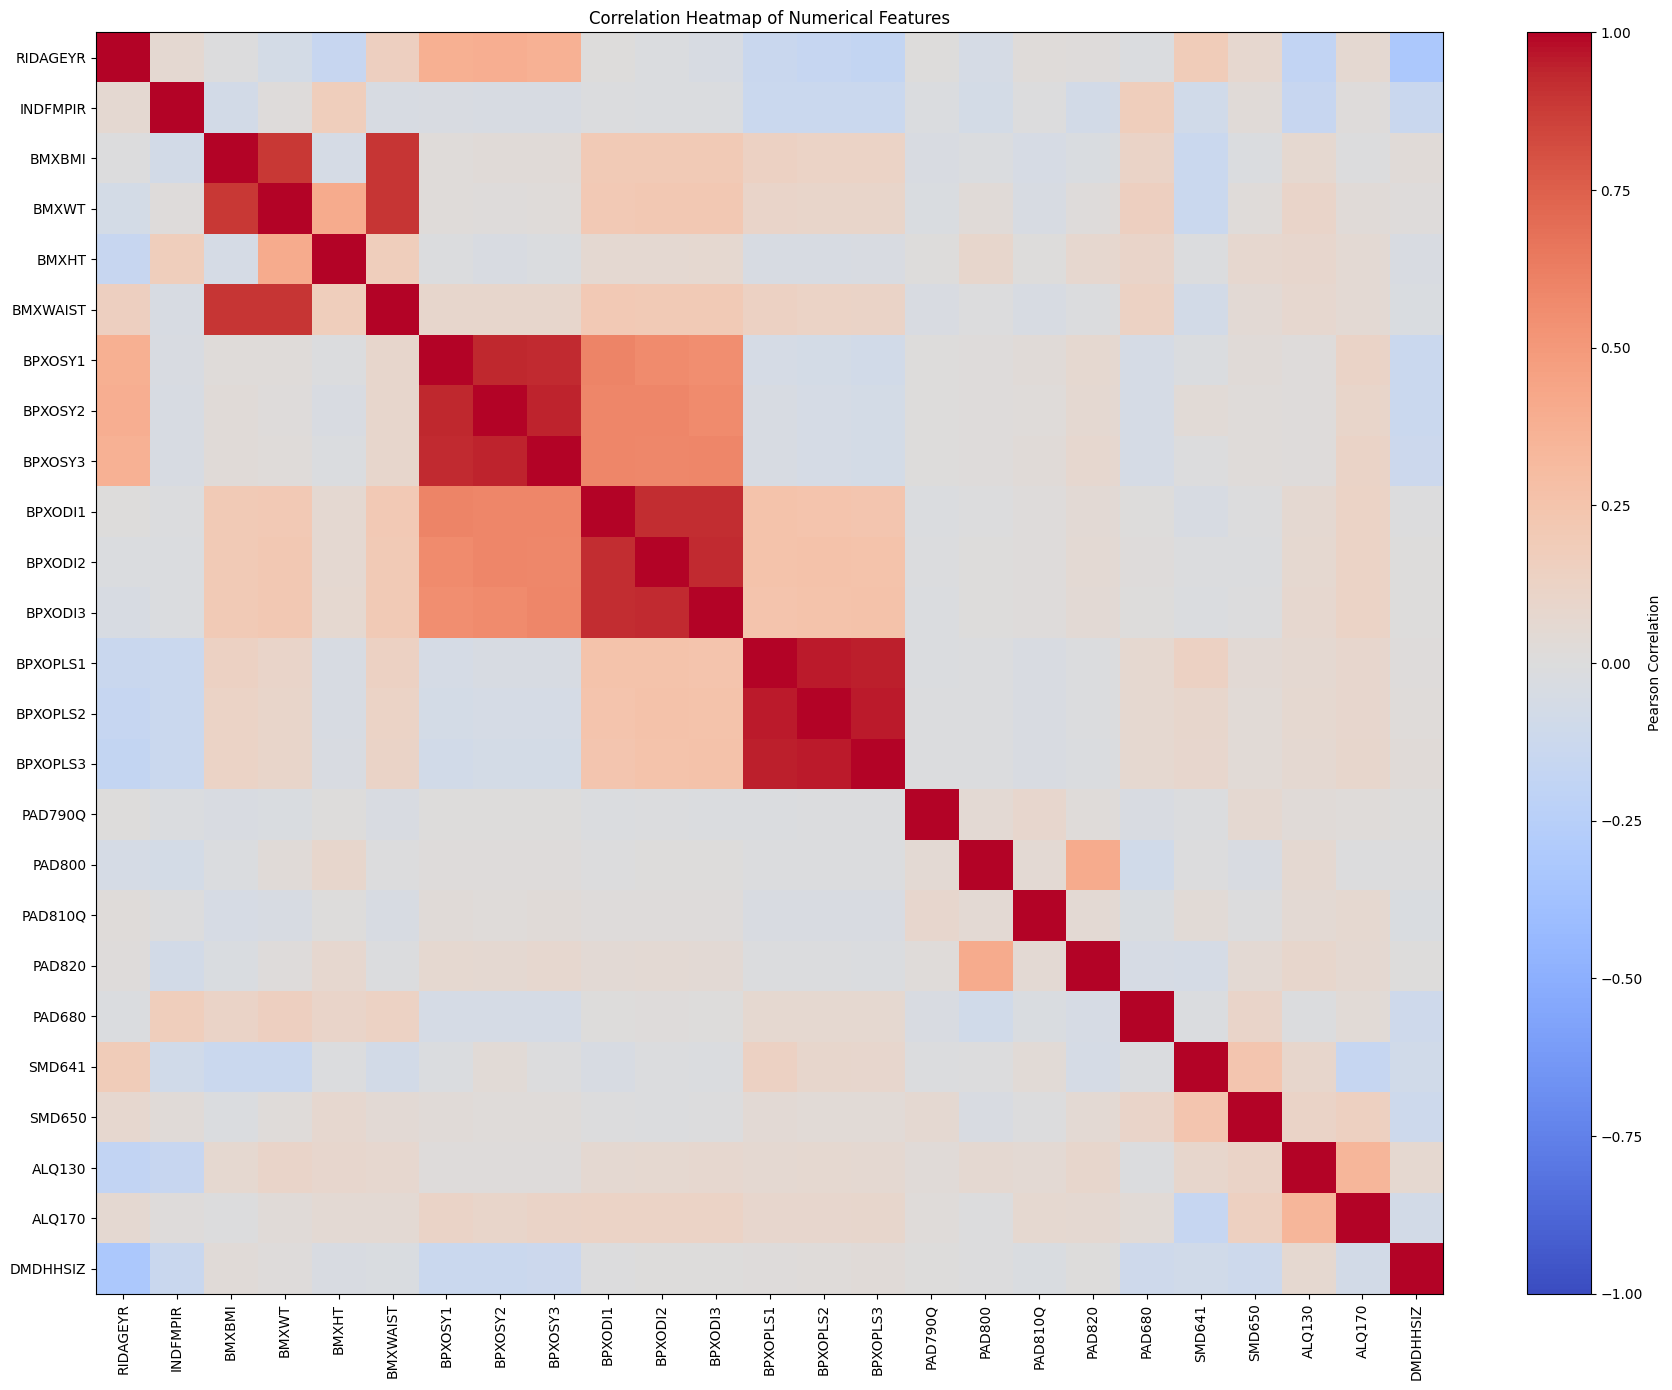

,Feature_1,Feature_2,Correlation
234,BPXOPLS2,BPXOPLS3,0.958600
222,BPXOPLS1,BPXOPLS2,0.958469
223,BPXOPLS1,BPXOPLS3,0.948702
147,BPXOSY2,BPXOSY3,0.939259
129,BPXOSY1,BPXOSY2,0.936443
195,BPXODI2,BPXODI3,0.928703
130,BPXOSY1,BPXOSY3,0.926628
180,BPXODI1,BPXODI2,0.917255
181,BPXODI1,BPXODI3,0.914662
49,BMXBMI,BMXWAIST,0.898418


Correlation matrix saved.
Heatmap saved.
Strong correlation pairs saved.
Strong pairs found: 12


In [228]:
# Select numerical features
correlation_data = eda_df[numerical_features]

# Calculate Pearson correlation
correlation_matrix = correlation_data.corr(
    method="pearson"
)

# Save correlation matrix
correlation_matrix.to_csv(
    tables_dir / "numerical_features_correlation_matrix.csv"
)

# Plot correlation heatmap
plt.figure(figsize=(18, 14))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.colorbar(label="Pearson Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.index)),
    correlation_matrix.index
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()

# Save figure
plt.savefig(
    figures_dir / "numerical_features_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Identify strongly correlated feature pairs
correlation_pairs = (
    correlation_matrix.where(
        np.triu(
            np.ones(correlation_matrix.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Feature_1",
    "Feature_2",
    "Correlation"
]

strong_correlations = (
    correlation_pairs[
        correlation_pairs["Correlation"].abs() >= 0.70
    ]
    .sort_values(
        "Correlation",
        key=abs,
        ascending=False
    )
)

display(strong_correlations)

# Save strong correlation pairs
strong_correlations.to_csv(
    tables_dir / "strong_numerical_correlations.csv",
    index=False
)

print("Correlation matrix saved.")
print("Heatmap saved.")
print("Strong correlation pairs saved.")
print("Strong pairs found:", len(strong_correlations))

### 9.6 Numerical Features by Diabetes Status

This section compares numerical predictor distributions between participants with and without diagnosed diabetes. Group-wise descriptive statistics and boxplots are used to identify differences in age, body measurements, blood pressure, physical activity, smoking, and other numerical characteristics.

RIDAGEYR               INDFMPIR              BMXBMI               \
             mean median    std     mean median   std   mean median   std   
DIABETES                                                                    
0.0         51.64   53.0  17.75     3.01   2.95  1.64  29.19   27.8  7.08   
1.0         63.61   65.0  12.22     2.54   2.18  1.59  32.95   31.8  7.87   

          BMXWT  ... SMD650 ALQ130              ALQ170              DMDHHSIZ  \
           mean  ...    std   mean median   std   mean median   std     mean   
DIABETES         ...                                                           
0.0       81.71  ...   9.50    2.6    2.0  2.16   4.22    2.0  6.29     2.60   
1.0       91.07  ...  12.38    2.6    2.0  2.43   3.45    2.0  5.13     2.39   

                       
         median   std  
DIABETES               
0.0         2.0  1.46  
1.0         2.0  1.44  

[2 rows x 75 columns]

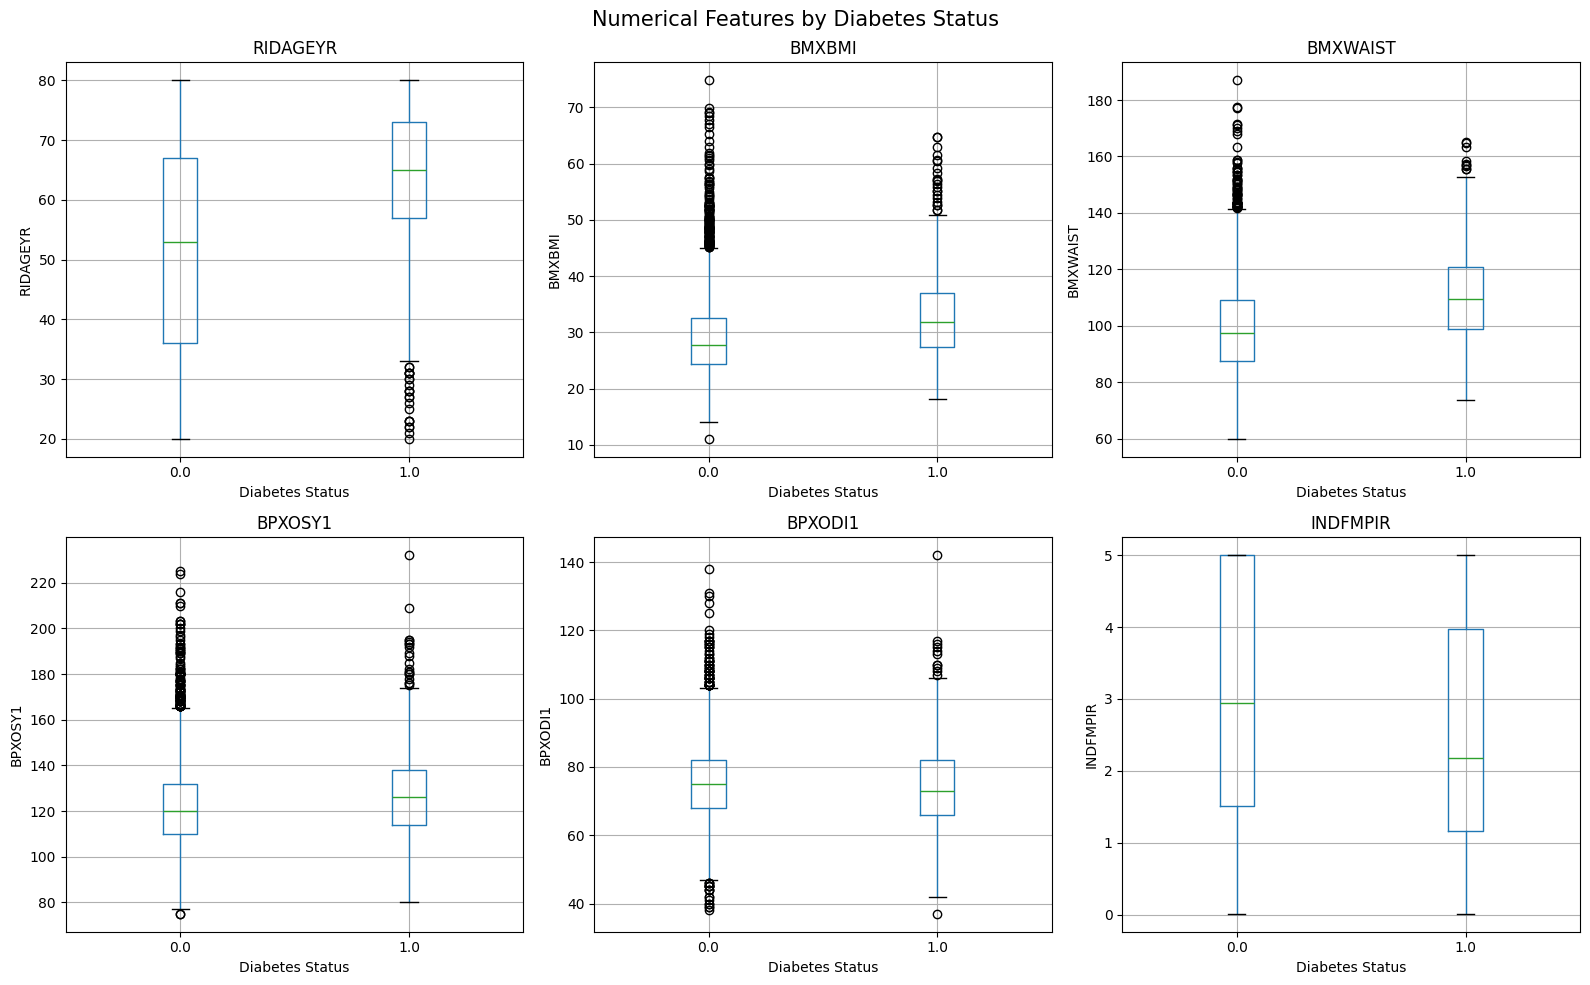

Summary saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/numerical_features_by_diabetes_status.csv
Figure saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/figures/numerical_features_by_diabetes_status.png


In [229]:
# Group-wise descriptive statistics
diabetes_group_summary = (
    eda_df.groupby("DIABETES")[numerical_features]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(diabetes_group_summary)

# Save summary table
diabetes_group_summary.to_csv(
    tables_dir / "numerical_features_by_diabetes_status.csv"
)

# Compare selected important numerical features
selected_features = [
    "RIDAGEYR",
    "BMXBMI",
    "BMXWAIST",
    "BPXOSY1",
    "BPXODI1",
    "INDFMPIR"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for feature, ax in zip(selected_features, axes.flatten()):
    eda_df.boxplot(
        column=feature,
        by="DIABETES",
        ax=ax
    )
    ax.set_title(feature)
    ax.set_xlabel("Diabetes Status")
    ax.set_ylabel(feature)

plt.suptitle(
    "Numerical Features by Diabetes Status",
    fontsize=15
)
plt.tight_layout()

# Save figure
plt.savefig(
    figures_dir / "numerical_features_by_diabetes_status.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Summary saved:",
      tables_dir / "numerical_features_by_diabetes_status.csv")

print("Figure saved:",
      figures_dir / "numerical_features_by_diabetes_status.png")

### 9.7 Categorical Features by Diabetes Status

This section compares categorical predictor distributions between participants with and without diagnosed diabetes. Cross-tabulations and normalized percentages are used to examine differences in participant characteristics across diabetes groups.
    

In [230]:
# Categorical feature comparisons by diabetes status
categorical_diabetes_results = []

for feature in categorical_features:
    counts = pd.crosstab(
        eda_df[feature],
        eda_df["DIABETES"],
        dropna=False
    )

    percentages = pd.crosstab(
        eda_df[feature],
        eda_df["DIABETES"],
        normalize="columns",
        dropna=False
    ) * 100

    result = percentages.copy()
    result.columns = [
        f"Diabetes_{int(col)}_Percentage"
        for col in result.columns
    ]

    result.insert(
        0,
        "Feature",
        feature
    )

    result.insert(
        1,
        "Category",
        result.index.astype(str)
    )

    categorical_diabetes_results.append(
        result.reset_index(drop=True)
    )

categorical_diabetes_summary = pd.concat(
    categorical_diabetes_results,
    ignore_index=True
)

display(categorical_diabetes_summary)

# Save consolidated comparison
categorical_diabetes_summary.to_csv(
    tables_dir / "categorical_features_by_diabetes_status.csv",
    index=False
)

print(
    "Table saved:",
    tables_dir / "categorical_features_by_diabetes_status.csv"
)


,Feature,Category,Diabetes_0_Percentage,Diabetes_1_Percentage
0,RIDSTATR,1.0,23.059078,18.878505
1,RIDSTATR,2.0,76.940922,81.121495
2,RIAGENDR,1.0,44.045778,48.317757
3,RIAGENDR,2.0,55.954222,51.682243
4,RIDRETH1,1.0,6.773894,8.317757
...,...,...,...,...
65,ALQ111,2.0,5.366533,9.345794
66,ALQ111,nan,32.987937,32.616822
67,ALQ151,1.0,10.949582,14.205607
68,ALQ151,2.0,50.494896,43.177570


Table saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/categorical_features_by_diabetes_status.csv


### 9.8 Exploratory Data Analysis Summary

This section summarizes the main findings from the exploratory analysis, including target distribution, numerical and categorical feature distributions, correlations, and differences between diabetes groups. These findings will guide subsequent preprocessing and model development decisions.

In [231]:
eda_findings = pd.DataFrame([
    {
        "Analysis": "Target Distribution",
        "Finding": "Diabetes prevalence is 14.2%; the target classes are imbalanced."
    },
    {
        "Analysis": "Numerical Features",
        "Finding": "Age, BMI, weight, blood pressure, and activity variables show varying distributions."
    },
    {
        "Analysis": "Categorical Features",
        "Finding": "Participant characteristics and questionnaire responses have different category distributions."
    },
    {
        "Analysis": "Ordinal Features",
        "Finding": "Several alcohol and demographic variables have substantial missingness."
    },
    {
        "Analysis": "Correlation Analysis",
        "Finding": "12 numerical feature pairs have absolute Pearson correlation of at least 0.70."
    },
    {
        "Analysis": "Diabetes Group Comparison",
        "Finding": "The diabetes group has higher average age, BMI, and body weight."
    },
    {
        "Analysis": "Missingness",
        "Finding": "Structural and questionnaire skip-pattern missingness must be considered during preprocessing."
    }
])

display(eda_findings)

eda_findings.to_csv(
    tables_dir / "eda_findings_summary.csv",
    index=False
)

print("EDA summary saved:", tables_dir / "eda_findings_summary.csv")

,Analysis,Finding
0,Target Distribution,Diabetes prevalence is 14.2%; the target class...
1,Numerical Features,"Age, BMI, weight, blood pressure, and activity..."
2,Categorical Features,Participant characteristics and questionnaire ...
3,Ordinal Features,Several alcohol and demographic variables have...
4,Correlation Analysis,12 numerical feature pairs have absolute Pears...
5,Diabetes Group Comparison,"The diabetes group has higher average age, BMI..."
6,Missingness,Structural and questionnaire skip-pattern miss...


EDA summary saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/eda_findings_summary.csv


# 10. Data Preprocessing

This section prepares the cleaned NHANES dataset for machine learning. It addresses missing values, special response codes, categorical encoding, and numerical feature preparation. All preprocessing decisions will be applied without using information from the test dataset to avoid data leakage.

## 10.1 Prepare the Modeling Dataset

The final cleaned modeling dataset is loaded for preprocessing. The target variable (`DIABETES`) is separated from the predictor variables. The original cleaned dataset remains unchanged so that all preprocessing operations can be reproduced and audited.

In [232]:
# Create a separate preprocessing copy
preprocessing_df = pd.read_csv(
    project_root / "data" / "processed" /
    "nhanes_diabetes_modeling.csv"
)

# Separate predictors and target
X = preprocessing_df.drop(columns=["DIABETES"]).copy()
y = preprocessing_df["DIABETES"].copy()

# Verify dimensions
print("Preprocessing dataset:", preprocessing_df.shape)
print("Predictor matrix:", X.shape)
print("Target vector:", y.shape)

# Verify target distribution
print("\nTarget distribution:")
display(
    y.value_counts()
    .sort_index()
    .rename(index={0: "No Diabetes", 1: "Diabetes"})
    .to_frame("Count")
)

# Check missing values
preprocessing_missingness = pd.DataFrame({
    "Missing_Count": X.isnull().sum(),
    "Missing_Percentage": (X.isnull().mean() * 100).round(2)
})

preprocessing_missingness = (
    preprocessing_missingness[
        preprocessing_missingness["Missing_Count"] > 0
    ]
    .sort_values("Missing_Percentage", ascending=False)
)

display(preprocessing_missingness)

# Save preprocessing missingness report
preprocessing_missingness.to_csv(
    tables_dir / "preprocessing_missingness_report.csv"
)

print(
    "\nMissingness report saved:",
    tables_dir / "preprocessing_missingness_report.csv"
)

Preprocessing dataset: (7536, 52)
Predictor matrix: (7536, 51)
Target vector: (7536,)

Target distribution:


,Count
DIABETES,
No Diabetes,6466
Diabetes,1070


,Missing_Count,Missing_Percentage
SMD641,7313,97.04
ALQ280,6632,88.00
SMD650,6416,85.14
ALQ170,6394,84.85
ALQ270,6313,83.77
DMDYRUSR,6099,80.93
RIDEXPRG,6059,80.40
ALQ142,5345,70.93
BPQ030,4782,63.46
BPQ150,4762,63.19



Missingness report saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/preprocessing_missingness_report.csv


### 10.2 Special Response Code Validation

NHANES datasets may contain special response codes representing refused responses, don't know responses, or other questionnaire-specific categories. This section checks the remaining predictor values against known special response codes to ensure they are handled appropriately before preprocessing.

In [233]:
# Check known special response codes
special_codes = {
    7, 9,
    77, 99,
    777, 999,
    7777, 9999
}

special_code_results = []

for feature in X.columns:
    if pd.api.types.is_numeric_dtype(X[feature]):
        for code in special_codes:
            count = (X[feature] == code).sum()

            if count > 0:
                special_code_results.append({
                    "Feature": feature,
                    "Special_Code": code,
                    "Count": count
                })

special_codes_df = pd.DataFrame(
    special_code_results,
    columns=["Feature", "Special_Code", "Count"]
)

display(special_codes_df)

# Save validation results
special_codes_df.to_csv(
    tables_dir / "remaining_special_response_codes.csv",
    index=False
)

print("Remaining special-code entries:", len(special_codes_df))
print(
    "Report saved:",
    tables_dir / "remaining_special_response_codes.csv"
)

,Feature,Special_Code,Count
0,RIDAGEYR,77,81
1,RIDRETH3,7,497
2,DMDEDUC2,9,11
3,DMDHHSIZ,7,164
4,BMXWT,99,5
5,BMXWT,77,8
6,BMXWAIST,99,23
7,BMXWAIST,77,11
8,BPXOSY1,99,60
9,BPXOSY1,77,1


Remaining special-code entries: 47
Report saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/remaining_special_response_codes.csv


### 10.3 Review Remaining Special Codes

The special-code audit identified 47 feature/code combinations. These values will be reviewed using the NHANES variable definitions before any further replacement.

Valid numerical values and category codes will be retained. Confirmed refused, don't know, and other nonresponse codes will be converted to missing values only when supported by the variable documentation.

In [234]:
# Create a focused review table for remaining special codes

review_features = [
    "DMDEDUC2",
    "BMXWT", "BMXWAIST",
    "BPXOSY1", "BPXOSY2", "BPXOSY3",
    "BPXODI1", "BPXODI2", "BPXODI3",
    "BPXOPLS1", "BPXOPLS2", "BPXOPLS3",
    "PAD790Q", "PAD800", "PAD810Q", "PAD820", "PAD680",
    "SMD641", "SMD650",
    "ALQ121", "ALQ130", "ALQ142",
    "ALQ270", "ALQ280", "ALQ170"
]

review_rows = []

for feature in review_features:
    if feature in X.columns:
        counts = X[feature].value_counts(dropna=False).sort_index()

        for value, count in counts.items():
            if value in [7, 9, 77, 99]:
                review_rows.append({
                    "Feature": feature,
                    "Value": value,
                    "Count": count
                })

special_code_review = pd.DataFrame(review_rows)

display(special_code_review)

special_code_review.to_csv(
    tables_dir / "special_code_variable_review.csv",
    index=False
)

print(
    "Review table saved:",
    tables_dir / "special_code_variable_review.csv"
)

,Feature,Value,Count
0,DMDEDUC2,9.0,11
1,BMXWT,77.0,8
2,BMXWT,99.0,5
3,BMXWAIST,77.0,11
4,BMXWAIST,99.0,23
5,BPXOSY1,77.0,1
6,BPXOSY1,99.0,60
7,BPXOSY2,77.0,1
8,BPXOSY2,99.0,55
9,BPXOSY3,77.0,1


Review table saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/special_code_variable_review.csv


### 10.4 Handle Confirmed Special Response Codes

The variable-specific review identified 11 records in `DMDEDUC2` coded as 9, representing "Don't know." These values will be converted to missing values. Other reviewed values will be retained because they represent valid measurements or responses.

In [235]:
# Convert confirmed special response code to missing

before_count = X["DMDEDUC2"].isna().sum()

X["DMDEDUC2"] = X["DMDEDUC2"].replace(9, np.nan)

after_count = X["DMDEDUC2"].isna().sum()

print("DMDEDUC2 missing values before:", before_count)
print("DMDEDUC2 missing values after:", after_count)
print("Newly converted to missing:", after_count - before_count)

# Save updated predictors and modeling dataset
preprocessing_df["DMDEDUC2"] = X["DMDEDUC2"]

preprocessing_df.to_csv(
    processed_dir / "nhanes_diabetes_modeling.csv",
    index=False
)

print("Updated modeling dataset saved.")

DMDEDUC2 missing values before: 13
DMDEDUC2 missing values after: 24
Newly converted to missing: 11
Updated modeling dataset saved.


### 10.5 Validate the Updated Modeling Dataset

Verify that the confirmed special response codes were handled correctly, the dataset dimensions remain unchanged, and the target variable has not been modified.

In [236]:
# Validate updated modeling dataset

updated_df = pd.read_csv(
    processed_dir / "nhanes_diabetes_modeling.csv"
)

print("Dataset shape:", updated_df.shape)

print("\nDMDEDUC2 missing values:",
      updated_df["DMDEDUC2"].isna().sum())

print("\nDMDEDUC2 value 9 remaining:",
      (updated_df["DMDEDUC2"] == 9).sum())

print("\nTarget missing values:",
      updated_df["DIABETES"].isna().sum())

print("\nTarget distribution:")
display(updated_df["DIABETES"].value_counts().sort_index())

print("\nDuplicate rows:", updated_df.duplicated().sum())

# Save validation report
validation = pd.DataFrame({
    "Check": [
        "Dataset rows",
        "Dataset columns",
        "DMDEDUC2 missing",
        "DMDEDUC2 value 9 remaining",
        "Target missing",
        "Duplicate rows"
    ],
    "Result": [
        updated_df.shape[0],
        updated_df.shape[1],
        updated_df["DMDEDUC2"].isna().sum(),
        (updated_df["DMDEDUC2"] == 9).sum(),
        updated_df["DIABETES"].isna().sum(),
        updated_df.duplicated().sum()
    ]
})

validation.to_csv(
    tables_dir / "special_code_validation.csv",
    index=False
)

print("\nValidation report saved:",
      tables_dir / "special_code_validation.csv")

Dataset shape: (7536, 52)

DMDEDUC2 missing values: 24

DMDEDUC2 value 9 remaining: 0

Target missing values: 0

Target distribution:


DIABETES
0.0    6466
1.0    1070
Name: count, dtype: int64


Duplicate rows: 0

Validation report saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/special_code_validation.csv


### 10.6 Split the Dataset into Training and Testing Sets

The dataset will be divided into training (80%) and testing (20%) subsets. Stratified splitting will preserve the proportion of participants with and without diabetes in both subsets. A fixed random state will ensure reproducibility.

In [237]:
from sklearn.model_selection import train_test_split

# Separate predictors and target
X = updated_df.drop(columns=["DIABETES"])
y = updated_df["DIABETES"].astype(int)

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training predictors:", X_train.shape)
print("Testing predictors:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).mul(100).round(2))

Training predictors: (6028, 51)
Testing predictors: (1508, 51)

Training target distribution:


DIABETES
0    85.8
1    14.2
Name: proportion, dtype: float64


Testing target distribution:


DIABETES
0    85.81
1    14.19
Name: proportion, dtype: float64

### 10.7 Build Preprocessing Pipelines

Three preprocessing pipelines will be created:

1. **Numerical features:** Median imputation, missingness indicators, and standard scaling.
2. **Categorical features:** Most-frequent imputation, missingness indicators, and one-hot encoding.
3. **Ordinal features:** Most-frequent imputation, missingness indicators, and standard scaling while preserving their numeric ordering.

The pipelines will be combined using a ColumnTransformer. All transformations will be fitted on the training dataset and then applied to the testing dataset to prevent data leakage.

This will serve as an initial preprocessing baseline. Features with substantial structural or skip-pattern missingness will be reviewed before final model selection.

In [238]:
# Import preprocessing tools

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Work with copies of the training and testing datasets
X_train = X_train.copy()
X_test = X_test.copy()

# Decode byte-string categories in physical activity unit columns
unit_columns = ["PAD790U", "PAD810U"]

for col in unit_columns:
    if col in X_train.columns:
        X_train[col] = X_train[col].apply(
            lambda value: value.decode("utf-8")
            if isinstance(value, bytes) else value
        )

        X_test[col] = X_test[col].apply(
            lambda value: value.decode("utf-8")
            if isinstance(value, bytes) else value
        )

# Numerical pipeline
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

# Categorical pipeline
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent",
        add_indicator=True
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Ordinal pipeline
ordinal_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

# Combine all three pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline, numerical_features),
        ("categorical", categorical_pipeline, categorical_features),
        ("ordinal", ordinal_pipeline, ordinal_features)
    ],
    remainder="drop"
)

print("Preprocessing pipelines created successfully.")

print("\nNumerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Ordinal features:", len(ordinal_features))

print("\nTotal features:", 
      len(numerical_features) +
      len(categorical_features) +
      len(ordinal_features))

Preprocessing pipelines created successfully.

Numerical features: 25
Categorical features: 20
Ordinal features: 6

Total features: 51


### 10.8 Fit and Apply Preprocessing Transformations

The preprocessing pipeline will be fitted using only the training dataset. The fitted transformations will then be applied to both training and testing datasets.

This ensures that information from the testing dataset does not influence imputation, scaling, or category encoding. The transformed datasets will be checked for missing values, dimensions, and numerical validity.

In [239]:
# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the fitted preprocessing to testing data
X_test_processed = preprocessor.transform(X_test)

# Convert sparse matrices to dense arrays if necessary
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()

if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

# Display results
print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

print("\nTraining missing values:",
      np.isnan(X_train_processed).sum())

print("Testing missing values:",
      np.isnan(X_test_processed).sum())

print("\nTraining infinite values:",
      np.isinf(X_train_processed).sum())

print("Testing infinite values:",
      np.isinf(X_test_processed).sum())

Training data shape: (6028, 144)
Testing data shape: (1508, 144)

Training missing values: 0
Testing missing values: 0

Training infinite values: 0
Testing infinite values: 0


### 10.9 Save Preprocessed Datasets

The transformed training and testing datasets will be saved for reproducibility and subsequent machine learning experiments. The original target labels will be saved separately to maintain the correct correspondence between predictors and outcomes.

In [240]:
# Create output directory
preprocessed_dir = project_root / "data" / "processed" / "preprocessed"
preprocessed_dir.mkdir(parents=True, exist_ok=True)

# Save transformed feature matrices
np.save(
    preprocessed_dir / "X_train_preprocessed.npy",
    X_train_processed
)

np.save(
    preprocessed_dir / "X_test_preprocessed.npy",
    X_test_processed
)

# Save target labels
np.save(
    preprocessed_dir / "y_train.npy",
    y_train.to_numpy()
)

np.save(
    preprocessed_dir / "y_test.npy",
    y_test.to_numpy()
)

print("Preprocessed datasets saved successfully.")

print("Training features:", X_train_processed.shape)
print("Testing features:", X_test_processed.shape)

print("\nSaved files:")
for file in preprocessed_dir.iterdir():
    print(file.name)

Preprocessed datasets saved successfully.
Training features: (6028, 144)
Testing features: (1508, 144)

Saved files:
X_test_preprocessed.npy
feature_names.npy
y_train.npy
y_test.npy
X_train_preprocessed.npy


### 10.10 Save Transformed Feature Names

The feature names generated by the preprocessing pipeline will be extracted and saved. This provides traceability between the original NHANES variables and the transformed features, supporting model interpretation and feature importance analysis.

In [241]:
# Extract transformed feature names
feature_names = preprocessor.get_feature_names_out()

print("Total transformed features:", len(feature_names))

# Create feature mapping table
feature_mapping = pd.DataFrame({
    "Feature_Index": range(len(feature_names)),
    "Transformed_Feature": feature_names
})

display(feature_mapping.head(20))

# Save feature names
feature_mapping.to_csv(
    tables_dir / "preprocessed_feature_names.csv",
    index=False
)

# Save as a separate NumPy file
np.save(
    preprocessed_dir / "feature_names.npy",
    feature_names
)

print("\nFeature names saved successfully.")
print("CSV:", tables_dir / "preprocessed_feature_names.csv")
print("NumPy:", preprocessed_dir / "feature_names.npy")

Total transformed features: 144


,Feature_Index,Transformed_Feature
0,0,numerical__RIDAGEYR
1,1,numerical__INDFMPIR
2,2,numerical__BMXBMI
3,3,numerical__BMXWT
4,4,numerical__BMXHT
5,5,numerical__BMXWAIST
6,6,numerical__BPXOSY1
7,7,numerical__BPXOSY2
8,8,numerical__BPXOSY3
9,9,numerical__BPXODI1



Feature names saved successfully.
CSV: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/preprocessed_feature_names.csv
NumPy: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/data/processed/preprocessed/feature_names.npy


### 10.11 Final Preprocessing Validation

The saved training and testing datasets, target labels, and transformed feature names will be reloaded and checked. This final validation ensures that the preprocessing outputs are complete, consistent, and ready for machine learning model development.

In [242]:
# Reload saved preprocessing outputs

X_train_check = np.load(
    preprocessed_dir / "X_train_preprocessed.npy"
)

X_test_check = np.load(
    preprocessed_dir / "X_test_preprocessed.npy"
)

y_train_check = np.load(
    preprocessed_dir / "y_train.npy"
)

y_test_check = np.load(
    preprocessed_dir / "y_test.npy"
)

# Allow loading the saved object array of feature names
feature_names_check = np.load(
    preprocessed_dir / "feature_names.npy",
    allow_pickle=True
)

# Final validation
print("Training features:", X_train_check.shape)
print("Testing features:", X_test_check.shape)

print("Training labels:", y_train_check.shape)
print("Testing labels:", y_test_check.shape)

print("Feature names:", feature_names_check.shape)

print("\nFeature count matches:",
      X_train_check.shape[1] == len(feature_names_check))

print("Training records match:",
      X_train_check.shape[0] == len(y_train_check))

print("Testing records match:",
      X_test_check.shape[0] == len(y_test_check))

print("\nAll training values finite:",
      np.isfinite(X_train_check).all())

print("All testing values finite:",
      np.isfinite(X_test_check).all())

Training features: (6028, 144)
Testing features: (1508, 144)
Training labels: (6028,)
Testing labels: (1508,)
Feature names: (144,)

Feature count matches: True
Training records match: True
Testing records match: True

All training values finite: True
All testing values finite: True


# 11. Machine Learning Model Development

### 11.1 Establish a Baseline Model — Logistic Regression

Logistic Regression will be used as the baseline model for predicting self-reported diagnosed diabetes.

A five-fold stratified cross-validation approach will be used to evaluate model performance. The preprocessing pipeline will be fitted separately within each fold to prevent data leakage.

Class weighting will be enabled to account for the imbalance between participants with and without diabetes.

Performance will be evaluated using accuracy, precision, recall, F1-score, and ROC-AUC.

In [243]:
# Import model evaluation tools

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

# Define baseline Logistic Regression pipeline
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Define stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Run cross-validation on raw training data
logistic_cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

# Summarize cross-validation results
logistic_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Mean Score": [
        logistic_cv_results["test_accuracy"].mean(),
        logistic_cv_results["test_precision"].mean(),
        logistic_cv_results["test_recall"].mean(),
        logistic_cv_results["test_f1"].mean(),
        logistic_cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        logistic_cv_results["test_accuracy"].std(),
        logistic_cv_results["test_precision"].std(),
        logistic_cv_results["test_recall"].std(),
        logistic_cv_results["test_f1"].std(),
        logistic_cv_results["test_roc_auc"].std()
    ]
})

display(logistic_summary.round(4))

# Save baseline cross-validation results
logistic_summary.to_csv(
    tables_dir / "logistic_regression_cv_results.csv",
    index=False
)

print(
    "Results saved:",
    tables_dir / "logistic_regression_cv_results.csv"
)

/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6

,Metric,Mean Score,Standard Deviation
0,Accuracy,0.7721,0.0088
1,Precision,0.3579,0.0105
2,Recall,0.7605,0.0229
3,F1-score,0.4866,0.0117
4,ROC-AUC,0.8494,0.0131


Results saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/logistic_regression_cv_results.csv


### 11.1.1 Diagnose Numerical Stability

The initial Logistic Regression cross-validation generated numerical overflow and invalid matrix multiplication warnings. The transformed training data will be examined for unusually large values, non-finite values, and features with extreme ranges before finalizing the baseline model.

In [244]:
# Diagnose transformed training data

diagnostic_preprocessor = preprocessor

X_train_diagnostic = diagnostic_preprocessor.fit_transform(X_train)

if hasattr(X_train_diagnostic, "toarray"):
    X_train_diagnostic = X_train_diagnostic.toarray()

diagnostic_names = diagnostic_preprocessor.get_feature_names_out()

print("Data shape:", X_train_diagnostic.shape)
print("Data type:", X_train_diagnostic.dtype)

print("\nNaN values:", np.isnan(X_train_diagnostic).sum())
print("Infinite values:", np.isinf(X_train_diagnostic).sum())

print("\nMaximum absolute value:",
      np.nanmax(np.abs(X_train_diagnostic)))

# Identify features with the largest absolute values
feature_max_values = pd.DataFrame({
    "Feature": diagnostic_names,
    "Max_Absolute_Value": np.max(
        np.abs(X_train_diagnostic), axis=0
    )
})

feature_max_values = feature_max_values.sort_values(
    "Max_Absolute_Value",
    ascending=False
)

print("\nTop 20 features by maximum absolute value:")
display(feature_max_values.head(20))

feature_max_values.to_csv(
    tables_dir / "logistic_regression_numerical_diagnostics.csv",
    index=False
)

print("\nDiagnostic report saved.")

Data shape: (6028, 144)
Data type: float64

NaN values: 0
Infinite values: 0

Maximum absolute value: 51.12586869605014

Top 20 features by maximum absolute value:


,Feature,Max_Absolute_Value
15,numerical__PAD790Q,51.125869
17,numerical__PAD810Q,49.516942
21,numerical__SMD650,21.723885
18,numerical__PAD820,21.389009
139,ordinal__missingindicator_DMDEDUC2,18.803942
20,numerical__SMD641,12.475978
16,numerical__PAD800,12.161061
23,numerical__ALQ170,11.689994
43,numerical__missingindicator_PAD680,9.432399
3,numerical__BMXWT,8.524545



Diagnostic report saved.


### 11.1.2 Improve Logistic Regression Numerical Stability

The initial Logistic Regression model generated numerical overflow warnings during optimization. A more strongly regularized Logistic Regression model using the Liblinear solver will be evaluated. This approach will help determine whether the initial numerical warnings can be reduced while maintaining predictive performance.

In [245]:
# Create a more strongly regularized Logistic Regression model

logistic_pipeline_stable = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        solver="liblinear",
        C=0.1,
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

# Run stratified 5-fold cross-validation
logistic_stable_results = cross_validate(
    logistic_pipeline_stable,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False
)

# Summarize results
logistic_stable_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Mean Score": [
        logistic_stable_results["test_accuracy"].mean(),
        logistic_stable_results["test_precision"].mean(),
        logistic_stable_results["test_recall"].mean(),
        logistic_stable_results["test_f1"].mean(),
        logistic_stable_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        logistic_stable_results["test_accuracy"].std(),
        logistic_stable_results["test_precision"].std(),
        logistic_stable_results["test_recall"].std(),
        logistic_stable_results["test_f1"].std(),
        logistic_stable_results["test_roc_auc"].std()
    ]
})

display(logistic_stable_summary.round(4))

# Save updated results
logistic_stable_summary.to_csv(
    tables_dir / "logistic_regression_stable_cv_results.csv",
    index=False
)

print("Stable Logistic Regression results saved.")

/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.ven

,Metric,Mean Score,Standard Deviation
0,Accuracy,0.7736,0.0104
1,Precision,0.3610,0.0125
2,Recall,0.7698,0.0256
3,F1-score,0.4914,0.0137
4,ROC-AUC,0.8531,0.0155


Stable Logistic Regression results saved.


### 11.1.3 Investigate Feature Scaling and Variance

The Logistic Regression model continues to produce numerical warnings despite stronger regularization. Feature variance and distribution will be examined to identify potential numerical instability caused by constant, near-constant, or highly skewed transformed features.

In [246]:
# Inspect transformed feature variance and distribution

diagnostic_df = pd.DataFrame(
    X_train_diagnostic,
    columns=diagnostic_names
)

feature_diagnostics = pd.DataFrame({
    "Feature": diagnostic_df.columns,
    "Mean": diagnostic_df.mean().values,
    "Std_Deviation": diagnostic_df.std().values,
    "Minimum": diagnostic_df.min().values,
    "Maximum": diagnostic_df.max().values,
    "Variance": diagnostic_df.var().values
})

feature_diagnostics = feature_diagnostics.sort_values(
    "Variance"
)

print("Lowest variance features:")
display(feature_diagnostics.head(20))

print("\nHighest variance features:")
display(
    feature_diagnostics.sort_values(
        "Variance", ascending=False
    ).head(20)
)

# Save diagnostic report
feature_diagnostics.to_csv(
    tables_dir / "feature_variance_diagnostics.csv",
    index=False
)

print("\nVariance diagnostic report saved.")

Lowest variance features:


,Feature,Mean,Std_Deviation,Minimum,Maximum,Variance
108,categorical__missingindicator_DMDBORN4_False,0.998673,0.036409,0.0,1.0,0.001326
106,categorical__missingindicator_DMQMILIZ_False,0.998673,0.036409,0.0,1.0,0.001326
107,categorical__missingindicator_DMQMILIZ_True,0.001327,0.036409,0.0,1.0,0.001326
109,categorical__missingindicator_DMDBORN4_True,0.001327,0.036409,0.0,1.0,0.001326
114,categorical__missingindicator_BPQ020_False,0.998507,0.038614,0.0,1.0,0.001491
115,categorical__missingindicator_BPQ020_True,0.001493,0.038614,0.0,1.0,0.001491
110,categorical__missingindicator_DMDMARTZ_False,0.997014,0.054568,0.0,1.0,0.002978
111,categorical__missingindicator_DMDMARTZ_True,0.002986,0.054568,0.0,1.0,0.002978
125,categorical__missingindicator_SMQ020_True,0.003152,0.056058,0.0,1.0,0.003143
124,categorical__missingindicator_SMQ020_False,0.996848,0.056058,0.0,1.0,0.003143



Highest variance features:


,Feature,Mean,Std_Deviation,Minimum,Maximum,Variance
0,numerical__RIDAGEYR,-1.033605e-16,1.000083,-1.887409,1.520414,1.000166
31,numerical__missingindicator_BPXOSY2,3.798480e-16,1.000083,-0.583225,1.714605,1.000166
141,ordinal__missingindicator_ALQ142,2.007168e-16,1.000083,-1.568563,0.637526,1.000166
43,numerical__missingindicator_PAD680,-7.384926e-16,1.000083,-0.106018,9.432399,1.000166
139,ordinal__missingindicator_DMDEDUC2,-4.778144e-16,1.000083,-0.053180,18.803942,1.000166
138,ordinal__missingindicator_DMDYRUSR,6.008612e-16,1.000083,-2.046364,0.488672,1.000166
24,numerical__DMDHHSIZ,4.409950e-16,1.000083,-1.076323,3.026158,1.000166
37,numerical__missingindicator_BPXOPLS2,3.798480e-16,1.000083,-0.583225,1.714605,1.000166
14,numerical__BPXOPLS3,-5.205621e-16,1.000083,-3.832868,5.289506,1.000166
134,ordinal__ALQ121,-9.146724e-18,1.000083,-2.572108,2.117749,1.000166



Variance diagnostic report saved.


### 11.1.4 Test an Alternative Logistic Regression Solver

An alternative Logistic Regression solver will be evaluated to investigate whether the numerical warnings are related to the optimization algorithm. The same stratified cross-validation procedure and preprocessing pipeline will be retained to make the comparison consistent.

In [247]:
# Alternative Logistic Regression using SAGA

logistic_pipeline_saga = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        solver="saga",
        C=0.01,
        class_weight="balanced",
        max_iter=10000,
        tol=1e-3,
        random_state=42
    ))
])

# Run cross-validation
logistic_saga_results = cross_validate(
    logistic_pipeline_saga,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False
)

# Summarize performance
logistic_saga_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Mean Score": [
        logistic_saga_results["test_accuracy"].mean(),
        logistic_saga_results["test_precision"].mean(),
        logistic_saga_results["test_recall"].mean(),
        logistic_saga_results["test_f1"].mean(),
        logistic_saga_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        logistic_saga_results["test_accuracy"].std(),
        logistic_saga_results["test_precision"].std(),
        logistic_saga_results["test_recall"].std(),
        logistic_saga_results["test_f1"].std(),
        logistic_saga_results["test_roc_auc"].std()
    ]
})

display(logistic_saga_summary.round(4))

# Save results
logistic_saga_summary.to_csv(
    tables_dir / "logistic_regression_saga_cv_results.csv",
    index=False
)

print("SAGA results saved successfully.")

/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.ven

,Metric,Mean Score,Standard Deviation
0,Accuracy,0.7734,0.0115
1,Precision,0.3625,0.0142
2,Recall,0.7827,0.0278
3,F1-score,0.4953,0.0162
4,ROC-AUC,0.8567,0.0173


SAGA results saved successfully.


### 11.1.5 Inspect Original Training Features

The original training features will be examined for unexpected data types, unusually large values, and extreme observations. This check will help identify whether the numerical warnings originate from the source variables or from the preprocessing transformations.

In [248]:
# Inspect original training features

print("Training dataset shape:", X_train.shape)

print("\nData types:")
display(X_train.dtypes.value_counts())

# Numerical feature summary
raw_numeric_summary = X_train[numerical_features + ordinal_features].describe().T

raw_numeric_summary["Missing_Count"] = (
    X_train[numerical_features + ordinal_features].isna().sum()
)

raw_numeric_summary["Missing_Percentage"] = (
    raw_numeric_summary["Missing_Count"] / len(X_train) * 100
)

display(
    raw_numeric_summary.sort_values(
        "max", ascending=False
    ).head(20)
)

# Check non-numeric values in numeric feature groups
for col in numerical_features + ordinal_features:
    if not pd.api.types.is_numeric_dtype(X_train[col]):
        print("Unexpected non-numeric feature:", col)

# Save report
raw_numeric_summary.to_csv(
    tables_dir / "raw_training_feature_diagnostics.csv"
)

print("\nRaw feature diagnostic report saved.")

Training dataset shape: (6028, 51)

Data types:


float64    49
object      2
Name: count, dtype: int64

,count,mean,std,min,25%,50%,75%,max,Missing_Count,Missing_Percentage
PAD680,5961.0,361.456635,212.492414,1.0,180.0,300.0,480.0,1380.0,67,1.111480
PAD820,2695.0,59.945455,58.276932,1.0,30.0,45.0,60.0,900.0,3333,55.291971
PAD800,4723.0,63.402922,60.772760,1.0,30.0,45.0,60.0,720.0,1305,21.648971
BMXWT,4586.0,83.127824,22.251023,27.9,67.5,79.8,95.0,248.2,1442,23.921699
BPXOSY2,4498.0,122.761227,18.360930,65.0,110.0,120.0,133.0,233.0,1530,25.381553
BPXOSY1,4501.0,122.959565,18.456788,75.0,110.0,120.0,133.0,232.0,1527,25.331785
BPXOSY3,4486.0,122.511815,18.185057,62.0,110.0,120.0,132.0,232.0,1542,25.580624
BMXHT,4603.0,166.891810,10.118903,133.0,159.6,166.4,174.4,200.7,1425,23.639681
BMXWAIST,4424.0,100.826334,16.765992,62.8,88.7,99.4,111.0,187.0,1604,26.609157
PAD790Q,4735.0,3.367054,3.896584,1.0,2.0,3.0,4.0,180.0,1293,21.449900



Raw feature diagnostic report saved.


### 11.1.6 Investigate Object Columns and Extreme Observations

The original training dataset contains two object-type features. Their values and the extreme observations in selected physical activity variables will be inspected. This will help determine whether the numerical warnings are associated with data representation or valid but extreme observations.

In [249]:
# Identify object-type columns

object_columns = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Object columns:", object_columns)

for col in object_columns:
    print(f"\nValues in {col}:")
    print(X_train[col].value_counts(dropna=False).head(15))


# Inspect extreme physical activity observations
activity_columns = [
    "PAD790Q",
    "PAD810Q",
    "PAD800",
    "PAD820",
    "PAD680"
]

for col in activity_columns:
    print(f"\nTop 10 highest values in {col}:")
    display(
        X_train[col]
        .dropna()
        .nlargest(10)
        .to_frame()
    )


# Check all numerical values for infinities
numeric_data = X_train.select_dtypes(include=np.number)

print("\nInfinite values in raw numerical data:")
print(np.isinf(numeric_data.to_numpy()).sum())

# Save object-column report
object_report = pd.DataFrame({
    "Feature": object_columns,
    "Data_Type": [str(X_train[col].dtype) for col in object_columns],
    "Unique_Values": [
        X_train[col].nunique(dropna=False)
        for col in object_columns
    ]
})

object_report.to_csv(
    tables_dir / "object_feature_diagnostics.csv",
    index=False
)

print("\nObject feature report saved.")

Object columns: ['PAD790U', 'PAD810U']

Values in PAD790U:
PAD790U
b'W'    3601
b''     1293
b'D'     723
b'M'     350
b'Y'      61
Name: count, dtype: int64

Values in PAD810U:
PAD810U
b''     3323
b'W'    1903
b'M'     524
b'D'     169
b'Y'     109
Name: count, dtype: int64

Top 10 highest values in PAD790Q:


,PAD790Q
1174,180.0
3488,104.0
7363,50.0
3586,40.0
5184,30.0
3565,30.0
3051,30.0
1405,30.0
1746,30.0
4338,28.0



Top 10 highest values in PAD810Q:


,PAD810Q
4697,90.0
4937,31.0
1787,30.0
4012,30.0
3932,24.0
7498,24.0
5330,23.0
4346,22.0
1362,20.0
1215,15.0



Top 10 highest values in PAD800:


,PAD800
1473,720.0
2486,720.0
6504,660.0
7095,600.0
2366,600.0
5854,600.0
4397,600.0
1558,480.0
4677,480.0
206,480.0



Top 10 highest values in PAD820:


,PAD820
871,900.0
6504,660.0
7381,600.0
7126,540.0
5910,480.0
6710,480.0
1558,480.0
4357,480.0
337,480.0
795,480.0



Top 10 highest values in PAD680:


,PAD680
5248,1380.0
2076,1380.0
1616,1320.0
1618,1200.0
3425,1200.0
2279,1200.0
6284,1200.0
6946,1200.0
539,1200.0
4357,1200.0



Infinite values in raw numerical data:
0

Object feature report saved.


### 11.1.7 Revised Preprocessing Pipeline for Logistic Regression

A revised preprocessing pipeline will be created without automatic missingness indicators. Numerical variables will receive median imputation and standardization, categorical variables will receive most-frequent imputation and one-hot encoding, and ordinal variables will receive most-frequent imputation and standardization.

This revised pipeline will be evaluated using stratified five-fold cross-validation to determine whether the previous numerical warnings were associated with the original preprocessing configuration.

In [250]:
# Revised numerical pipeline
numerical_pipeline_revised = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Revised categorical pipeline
categorical_pipeline_revised = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Revised ordinal pipeline
ordinal_pipeline_revised = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler())
])

# Revised column transformer
preprocessor_revised = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline_revised, numerical_features),
        ("categorical", categorical_pipeline_revised, categorical_features),
        ("ordinal", ordinal_pipeline_revised, ordinal_features)
    ],
    remainder="drop"
)

print("Revised preprocessing pipeline created.")

Revised preprocessing pipeline created.


### 11.1.8 Revised Logistic Regression Cross-Validation

The revised preprocessing pipeline will be evaluated using five-fold stratified cross-validation. Accuracy, precision, recall, F1-score, and ROC-AUC will be calculated. The results and numerical warnings will be compared with the previous Logistic Regression experiments.

In [251]:
# Revised Logistic Regression pipeline

logistic_pipeline_revised = Pipeline(steps=[
    ("preprocessor", preprocessor_revised),
    ("classifier", LogisticRegression(
        solver="liblinear",
        C=0.1,
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

# Five-fold stratified cross-validation
revised_cv_results = cross_validate(
    logistic_pipeline_revised,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False
)

# Summarize results
revised_cv_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Mean": [
        revised_cv_results["test_accuracy"].mean(),
        revised_cv_results["test_precision"].mean(),
        revised_cv_results["test_recall"].mean(),
        revised_cv_results["test_f1"].mean(),
        revised_cv_results["test_roc_auc"].mean()
    ],
    "Standard_Deviation": [
        revised_cv_results["test_accuracy"].std(),
        revised_cv_results["test_precision"].std(),
        revised_cv_results["test_recall"].std(),
        revised_cv_results["test_f1"].std(),
        revised_cv_results["test_roc_auc"].std()
    ]
})

display(revised_cv_summary.round(4))

# Save results
revised_cv_summary.to_csv(
    tables_dir / "logistic_regression_revised_cv_results.csv",
    index=False
)

print("Results saved to:", tables_dir / "logistic_regression_revised_cv_results.csv")

/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.ven

,Metric,Mean,Standard_Deviation
0,Accuracy,0.7717,0.0103
1,Precision,0.3581,0.0146
2,Recall,0.7651,0.0316
3,F1,0.4877,0.0185
4,ROC-AUC,0.8545,0.0163


Results saved to: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/logistic_regression_revised_cv_results.csv


### 11.1.9 Diagnostic Analysis of Revised Preprocessed Features

The revised preprocessing pipeline will be fitted to the training data for diagnostic purposes. The transformed feature matrix will be examined for non-finite values, extreme magnitudes, and zero-variance features. These checks will help isolate the source of the Logistic Regression numerical warnings.

In [252]:
# Fit revised preprocessing on training data only
X_train_revised = preprocessor_revised.fit_transform(X_train)

# Convert sparse matrix to dense if necessary
if hasattr(X_train_revised, "toarray"):
    X_train_revised = X_train_revised.toarray()

# Basic validation
print("Transformed training shape:", X_train_revised.shape)
print("NaN values:", np.isnan(X_train_revised).sum())
print("Infinite values:", np.isinf(X_train_revised).sum())
print("Maximum absolute value:", np.max(np.abs(X_train_revised)))

# Feature names
revised_feature_names = preprocessor_revised.get_feature_names_out()

# Feature diagnostics
revised_diagnostic_df = pd.DataFrame(
    X_train_revised,
    columns=revised_feature_names
)

diagnostic_summary = pd.DataFrame({
    "Feature": revised_diagnostic_df.columns,
    "Mean": revised_diagnostic_df.mean().values,
    "Std": revised_diagnostic_df.std().values,
    "Min": revised_diagnostic_df.min().values,
    "Max": revised_diagnostic_df.max().values
})

diagnostic_summary["Max_Absolute"] = diagnostic_summary[
    ["Min", "Max"]
].abs().max(axis=1)

diagnostic_summary["Zero_Variance"] = (
    diagnostic_summary["Std"] == 0
)

display(
    diagnostic_summary.sort_values(
        "Max_Absolute",
        ascending=False
    ).head(20).round(4)
)

print(
    "\nZero-variance features:",
    diagnostic_summary["Zero_Variance"].sum()
)

# Save diagnostics
diagnostic_summary.to_csv(
    tables_dir / "revised_preprocessed_feature_diagnostics.csv",
    index=False
)

print(
    "\nSaved:",
    tables_dir / "revised_preprocessed_feature_diagnostics.csv"
)

Transformed training shape: (6028, 87)
NaN values: 0
Infinite values: 0
Maximum absolute value: 51.12586869605014


,Feature,Mean,Std,Min,Max,Max_Absolute,Zero_Variance
15,numerical__PAD790Q,-0.0,1.0001,-0.6621,51.1259,51.1259,False
17,numerical__PAD810Q,-0.0,1.0001,-0.6848,49.5169,49.5169,False
21,numerical__SMD650,-0.0,1.0001,-2.3686,21.7239,21.7239,False
18,numerical__PAD820,0.0,1.0001,-1.2779,21.3890,21.3890,False
20,numerical__SMD641,-0.0,1.0001,-7.6394,12.4760,12.4760,False
16,numerical__PAD800,0.0,1.0001,-1.0755,12.1611,12.1611,False
23,numerical__ALQ170,0.0,1.0001,-0.5470,11.6900,11.6900,False
3,numerical__BMXWT,0.0,1.0001,-2.7974,8.5245,8.5245,False
22,numerical__ALQ130,0.0,1.0001,-0.8185,8.0074,8.0074,False
86,ordinal__ALQ280,-0.0,1.0001,-7.9813,0.2355,7.9813,False



Zero-variance features: 0

Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/revised_preprocessed_feature_diagnostics.csv


### 11.1.10 Robust Scaling for Numerical Features

RobustScaler will be tested as an alternative to StandardScaler for numerical predictors. Unlike standard scaling, RobustScaler uses the median and interquartile range, making it less sensitive to extreme observations. The categorical and ordinal preprocessing steps will remain unchanged for this experiment.

In [253]:
from sklearn.preprocessing import RobustScaler

# Numerical pipeline with robust scaling
numerical_pipeline_robust = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

# Keep categorical pipeline unchanged
categorical_pipeline_robust = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Keep ordinal pipeline unchanged
ordinal_pipeline_robust = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler())
])

# Combined preprocessing
preprocessor_robust = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline_robust, numerical_features),
        ("categorical", categorical_pipeline_robust, categorical_features),
        ("ordinal", ordinal_pipeline_robust, ordinal_features)
    ],
    remainder="drop"
)

# Logistic Regression
logistic_pipeline_robust = Pipeline(steps=[
    ("preprocessor", preprocessor_robust),
    ("classifier", LogisticRegression(
        solver="liblinear",
        C=0.1,
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

# Cross-validation
robust_cv_results = cross_validate(
    logistic_pipeline_robust,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False
)

# Results summary
robust_cv_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Mean": [
        robust_cv_results["test_accuracy"].mean(),
        robust_cv_results["test_precision"].mean(),
        robust_cv_results["test_recall"].mean(),
        robust_cv_results["test_f1"].mean(),
        robust_cv_results["test_roc_auc"].mean()
    ],
    "Standard_Deviation": [
        robust_cv_results["test_accuracy"].std(),
        robust_cv_results["test_precision"].std(),
        robust_cv_results["test_recall"].std(),
        robust_cv_results["test_f1"].std(),
        robust_cv_results["test_roc_auc"].std()
    ]
})

display(robust_cv_summary.round(4))

robust_cv_summary.to_csv(
    tables_dir / "logistic_regression_robust_scaler_cv_results.csv",
    index=False
)

print("Saved:", tables_dir / "logistic_regression_robust_scaler_cv_results.csv")

/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.ven

,Metric,Mean,Standard_Deviation
0,Accuracy,0.7729,0.0101
1,Precision,0.3598,0.0144
2,Recall,0.7675,0.0307
3,F1,0.4898,0.0183
4,ROC-AUC,0.8543,0.0162


Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/logistic_regression_robust_scaler_cv_results.csv


### 11.1.11 Isolating Numerical Features for Logistic Regression

A Logistic Regression model will be evaluated using only numerical predictors. This experiment will help determine whether the numerical warnings originate from numerical feature transformations or from the categorical and ordinal preprocessing branches.

In [254]:
# Numerical-only preprocessing
numerical_only_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Numerical-only Logistic Regression
logistic_numerical_only = Pipeline(steps=[
    ("preprocessor", numerical_only_pipeline),
    ("classifier", LogisticRegression(
        solver="liblinear",
        C=0.1,
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

# Five-fold cross-validation
numerical_only_results = cross_validate(
    logistic_numerical_only,
    X_train[numerical_features],
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False
)

# Display metrics
numerical_only_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Mean": [
        numerical_only_results["test_accuracy"].mean(),
        numerical_only_results["test_precision"].mean(),
        numerical_only_results["test_recall"].mean(),
        numerical_only_results["test_f1"].mean(),
        numerical_only_results["test_roc_auc"].mean()
    ],
    "Standard_Deviation": [
        numerical_only_results["test_accuracy"].std(),
        numerical_only_results["test_precision"].std(),
        numerical_only_results["test_recall"].std(),
        numerical_only_results["test_f1"].std(),
        numerical_only_results["test_roc_auc"].std()
    ]
})

display(numerical_only_summary.round(4))

numerical_only_summary.to_csv(
    tables_dir / "logistic_regression_numerical_only_cv_results.csv",
    index=False
)

print("Saved:", tables_dir / "logistic_regression_numerical_only_cv_results.csv")

/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.ven

,Metric,Mean,Standard_Deviation
0,Accuracy,0.6992,0.0076
1,Precision,0.2830,0.0080
2,Recall,0.7290,0.0278
3,F1,0.4077,0.0117
4,ROC-AUC,0.7843,0.0123


Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/logistic_regression_numerical_only_cv_results.csv


### 11.1.12 Individual Numerical Feature Stability Analysis

Each numerical predictor will be examined after median imputation and standardization. The analysis will identify features with unusually large standardized values and assess whether these features may contribute to numerical instability in Logistic Regression.

In [255]:
# Impute numerical training features
numerical_imputed = SimpleImputer(
    strategy="median"
).fit_transform(X_train[numerical_features])

# Standardize numerical features
numerical_scaled = StandardScaler().fit_transform(
    numerical_imputed
)

# Calculate feature-level diagnostics
feature_stability = pd.DataFrame({
    "Feature": numerical_features,
    "Maximum_Absolute_Z": np.max(
        np.abs(numerical_scaled), axis=0
    ),
    "Minimum_Z": np.min(numerical_scaled, axis=0),
    "Maximum_Z": np.max(numerical_scaled, axis=0),
    "Mean": np.mean(numerical_scaled, axis=0),
    "Standard_Deviation": np.std(numerical_scaled, axis=0)
})

feature_stability = feature_stability.sort_values(
    "Maximum_Absolute_Z",
    ascending=False
)

display(feature_stability.round(4))

feature_stability.to_csv(
    tables_dir / "individual_numerical_feature_stability.csv",
    index=False
)

print(
    "Saved:",
    tables_dir / "individual_numerical_feature_stability.csv"
)

,Feature,Maximum_Absolute_Z,Minimum_Z,Maximum_Z,Mean,Standard_Deviation
15,PAD790Q,51.1259,-0.6621,51.1259,0.0,1.0
17,PAD810Q,49.5169,-0.6848,49.5169,-0.0,1.0
21,SMD650,21.7239,-2.3686,21.7239,0.0,1.0
18,PAD820,21.3890,-1.2779,21.3890,0.0,1.0
20,SMD641,12.4760,-7.6394,12.4760,-0.0,1.0
16,PAD800,12.1611,-1.0755,12.1611,0.0,1.0
23,ALQ170,11.6900,-0.5470,11.6900,-0.0,1.0
3,BMXWT,8.5245,-2.7974,8.5245,0.0,1.0
22,ALQ130,8.0074,-0.8185,8.0074,0.0,1.0
2,BMXBMI,7.0341,-2.8464,7.0341,-0.0,1.0


Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/individual_numerical_feature_stability.csv


### 11.1.13 Investigation of Extreme Numerical Observations

The six numerical predictors with the largest standardized values will be investigated. Their original distributions, extreme observations, and relationship with diabetes status will be examined to determine whether the values represent legitimate responses or potential data-quality concerns.

In [256]:
extreme_features = [
    "PAD790Q", "PAD810Q", "SMD650",
    "PAD820", "SMD641", "PAD800"
]

extreme_summary = []

for col in extreme_features:
    values = X_train[col].dropna()

    extreme_summary.append({
        "Feature": col,
        "Count": len(values),
        "Median": values.median(),
        "Q1": values.quantile(0.25),
        "Q3": values.quantile(0.75),
        "IQR": values.quantile(0.75) - values.quantile(0.25),
        "99th_Percentile": values.quantile(0.99),
        "Maximum": values.max(),
        "Above_99th_Percentile": (values > values.quantile(0.99)).sum()
    })

extreme_summary_df = pd.DataFrame(extreme_summary)

display(extreme_summary_df.round(2))

# Compare extreme observations by diabetes status
for col in extreme_features:
    print(f"\n{col} by diabetes status:")
    display(
        pd.DataFrame({
            "Count": X_train.groupby(y_train)[col].count(),
            "Median": X_train.groupby(y_train)[col].median(),
            "Mean": X_train.groupby(y_train)[col].mean(),
            "Maximum": X_train.groupby(y_train)[col].max()
        }).rename_axis("DIABETES")
    )

extreme_summary_df.to_csv(
    tables_dir / "extreme_feature_investigation.csv",
    index=False
)

print("\nSaved:", tables_dir / "extreme_feature_investigation.csv")

,Feature,Count,Median,Q1,Q3,IQR,99th_Percentile,Maximum,Above_99th_Percentile
0,PAD790Q,4735,3.0,2.0,4.0,2.0,10.0,180.0,46
1,PAD810Q,2705,2.0,1.0,3.0,2.0,7.0,90.0,22
2,SMD650,898,10.0,5.0,20.0,15.0,40.0,95.0,7
3,PAD820,2695,45.0,30.0,60.0,30.0,300.0,900.0,20
4,SMD641,180,12.0,5.0,20.0,15.0,30.0,30.0,0
5,PAD800,4723,45.0,30.0,60.0,30.0,300.0,720.0,40



PAD790Q by diabetes status:


,Count,Median,Mean,Maximum
DIABETES,,,,
0,4185,3.0,3.387814,180.0
1,550,3.0,3.209091,40.0



PAD810Q by diabetes status:


,Count,Median,Mean,Maximum
DIABETES,,,,
0,2502,2.0,2.491207,90.0
1,203,2.0,2.300493,30.0



SMD650 by diabetes status:


... (4 outputs left out)

,Count,Median,Mean,Maximum
DIABETES,,,,
0,148,10.0,12.263514,30.0
1,32,12.0,13.343750,30.0



PAD800 by diabetes status:


,Count,Median,Mean,Maximum
DIABETES,,,,
0,4176,60.0,64.019875,720.0
1,547,40.0,58.692870,720.0



Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/extreme_feature_investigation.csv


### 11.1.14 Logarithmic Transformation of Skewed Numerical Features

A logarithmic transformation using log1p will be tested on selected highly skewed numerical variables. This transformation reduces right skew while preserving zero values. The original dataset will remain unchanged, and the transformed features will be evaluated through a separate Logistic Regression pipeline.

In [257]:
from sklearn.preprocessing import FunctionTransformer
# Features selected for logarithmic transformation
log_features = [
    "PAD790Q",
    "PAD810Q",
    "PAD800",
    "PAD820",
    "PAD680",
    "SMD641",
    "SMD650",
    "ALQ130",
    "ALQ170"
]

# Create a separate numerical pipeline
numerical_pipeline_log = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", FunctionTransformer(
        np.log1p,
        feature_names_out="one-to-one"
    )),
    ("scaler", StandardScaler())
])

# Other numerical features
other_numerical_features = [
    col for col in numerical_features
    if col not in log_features
]

other_numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline
categorical_pipeline_log = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Ordinal pipeline
ordinal_pipeline_log = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler())
])

# Combined preprocessing
preprocessor_log = ColumnTransformer(
    transformers=[
        ("log_numerical", numerical_pipeline_log, log_features),
        ("other_numerical", other_numerical_pipeline, other_numerical_features),
        ("categorical", categorical_pipeline_log, categorical_features),
        ("ordinal", ordinal_pipeline_log, ordinal_features)
    ],
    remainder="drop"
)

print("Logarithmic transformation pipeline created.")

Logarithmic transformation pipeline created.


### 11.1.15 Logistic Regression Evaluation with Logarithmic Transformation

The logarithmically transformed numerical features will be evaluated using five-fold stratified cross-validation. Accuracy, precision, recall, F1-score, and ROC-AUC will be compared against the previous Logistic Regression experiments. Numerical warnings will also be monitored to assess whether the transformation improves model stability.

In [258]:
# Logistic Regression with logarithmic transformation

logistic_pipeline_log = Pipeline(steps=[
    ("preprocessor", preprocessor_log),
    ("classifier", LogisticRegression(
        solver="liblinear",
        C=0.1,
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

# Five-fold stratified cross-validation
log_cv_results = cross_validate(
    logistic_pipeline_log,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=False
)

# Summarize results
log_cv_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "Mean": [
        log_cv_results["test_accuracy"].mean(),
        log_cv_results["test_precision"].mean(),
        log_cv_results["test_recall"].mean(),
        log_cv_results["test_f1"].mean(),
        log_cv_results["test_roc_auc"].mean()
    ],
    "Standard_Deviation": [
        log_cv_results["test_accuracy"].std(),
        log_cv_results["test_precision"].std(),
        log_cv_results["test_recall"].std(),
        log_cv_results["test_f1"].std(),
        log_cv_results["test_roc_auc"].std()
    ]
})

display(log_cv_summary.round(4))

# Save results
log_cv_summary.to_csv(
    tables_dir / "logistic_regression_log_transform_cv_results.csv",
    index=False
)

print(
    "Saved:",
    tables_dir / "logistic_regression_log_transform_cv_results.csv"
)

/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/.ven

,Metric,Mean,Standard_Deviation
0,Accuracy,0.7701,0.0120
1,Precision,0.3564,0.0170
2,Recall,0.7663,0.0344
3,F1,0.4864,0.0215
4,ROC-AUC,0.8547,0.0172


Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/logistic_regression_log_transform_cv_results.csv


### 11.1.16 Logistic Regression Numerical Stability Diagnostics

A single stratified training fold will be used to inspect Logistic Regression fitting, coefficient magnitudes, decision scores, and predicted probabilities. Runtime warnings will be captured during fitting and prediction to help identify the stage at which numerical instability occurs.

In [259]:
import warnings

# Create one stratified fold
diagnostic_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, valid_idx = next(
    diagnostic_cv.split(X_train, y_train)
)

X_fold_train = X_train.iloc[train_idx]
X_fold_valid = X_train.iloc[valid_idx]

y_fold_train = y_train.iloc[train_idx]

# Fit and predict while capturing warnings
with warnings.catch_warnings(record=True) as captured_warnings:
    warnings.simplefilter("always", RuntimeWarning)

    logistic_pipeline_revised.fit(
        X_fold_train,
        y_fold_train
    )

    fold_probabilities = logistic_pipeline_revised.predict_proba(
        X_fold_valid
    )[:, 1]

    fold_scores = logistic_pipeline_revised.decision_function(
        X_fold_valid
    )

# Inspect classifier coefficients
fitted_classifier = logistic_pipeline_revised.named_steps["classifier"]

print("Maximum absolute coefficient:",
      np.max(np.abs(fitted_classifier.coef_)))

print("All coefficients finite:",
      np.isfinite(fitted_classifier.coef_).all())

print("Decision scores finite:",
      np.isfinite(fold_scores).all())

print("Predicted probabilities finite:",
      np.isfinite(fold_probabilities).all())

print("Minimum predicted probability:",
      fold_probabilities.min())

print("Maximum predicted probability:",
      fold_probabilities.max())

print("Runtime warnings captured:", len(captured_warnings))

for warning in captured_warnings[:10]:
    print(type(warning.message).__name__, ":", warning.message)

Maximum absolute coefficient: 0.5933009977631011
All coefficients finite: True
Decision scores finite: True
Predicted probabilities finite: True
Minimum predicted probability: 0.002550822405435059
Maximum predicted probability: 0.9854759854938917
Runtime warnings captured: 6


### 11.1.17 Comparison of Logistic Regression Optimization Solvers

The L-BFGS optimizer will be evaluated on the same stratified training fold used in the previous diagnostic. Its numerical warnings, convergence status, coefficient magnitudes, and validation performance will be compared with the liblinear solver.

In [260]:
from sklearn.model_selection import StratifiedKFold

diagnostic_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, valid_idx = next(
    diagnostic_cv.split(X_train, y_train)
)

X_fold_train = X_train.iloc[train_idx]
X_fold_valid = X_train.iloc[valid_idx]

y_fold_train = y_train.iloc[train_idx]
y_fold_valid = y_train.iloc[valid_idx]

print("Fold variables created successfully.")
print("Training features:", X_fold_train.shape)
print("Validation features:", X_fold_valid.shape)
print("Training labels:", y_fold_train.shape)
print("Validation labels:", y_fold_valid.shape)

Fold variables created successfully.
Training features: (4822, 51)
Validation features: (1206, 51)
Training labels: (4822,)
Validation labels: (1206,)


In [261]:
import numpy as np
import warnings

from sklearn.metrics import roc_auc_score
from sklearn.exceptions import ConvergenceWarning

# Define the L-BFGS pipeline explicitly so this cell works after a kernel restart.
logistic_lbfgs = Pipeline(steps=[
    ("preprocessor", preprocessor_revised),
    ("classifier", LogisticRegression(
        solver="lbfgs",
        C=0.1,
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

# Capture warnings during model fitting and prediction
with warnings.catch_warnings(record=True) as lbfgs_warnings:
    warnings.simplefilter("always")

    # Fit L-BFGS Logistic Regression
    logistic_lbfgs.fit(X_fold_train, y_fold_train)

    # Predict probabilities
    lbfgs_probabilities = logistic_lbfgs.predict_proba(
        X_fold_valid
    )[:, 1]

# Calculate ROC-AUC
lbfgs_roc_auc = roc_auc_score(
    y_fold_valid,
    lbfgs_probabilities
)

# Display results
print("L-BFGS Validation Results")
print("-" * 40)

print("ROC-AUC:", round(lbfgs_roc_auc, 4))

print("\nModel convergence:")
print(
    "Iterations:",
    logistic_lbfgs.named_steps["classifier"].n_iter_[0]
)

print(
    "Maximum absolute coefficient:",
    round(
        np.max(
            np.abs(
                logistic_lbfgs.named_steps["classifier"].coef_
            )
        ),
        4
    )
)

print("\nProbability validation:")
print(
    "All probabilities finite:",
    np.isfinite(lbfgs_probabilities).all()
)

print(
    "Probability minimum:",
    round(lbfgs_probabilities.min(), 6)
)

print(
    "Probability maximum:",
    round(lbfgs_probabilities.max(), 6)
)

print("\nWarning diagnostics:")
print("Total warnings:", len(lbfgs_warnings))

for warning in lbfgs_warnings[:10]:
    print(
        warning.category.__name__,
        ":",
        str(warning.message)
    )

L-BFGS Validation Results
----------------------------------------
ROC-AUC: 0.8394

Model convergence:
Iterations: 39
Maximum absolute coefficient: 0.591

Probability validation:
All probabilities finite: True
Probability minimum: 0.002565
Probability maximum: 0.985432

Warning diagnostics:
Total warnings: 249


## 11.2 Random Forest Classification

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve prediction performance and reduce overfitting.

For this project, Random Forest will be used to predict the presence or absence of self-reported diagnosed diabetes using demographic, physical activity, blood pressure, body measurement, smoking, and alcohol-related variables.

The model will be evaluated using five-fold stratified cross-validation. Accuracy, precision, recall, F1-score, and ROC-AUC will be used to assess classification performance.

In [262]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_revised),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


In [263]:
from sklearn.model_selection import cross_validate

rf_cv_results = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

rf_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Mean": [
        rf_cv_results["test_accuracy"].mean(),
        rf_cv_results["test_precision"].mean(),
        rf_cv_results["test_recall"].mean(),
        rf_cv_results["test_f1"].mean(),
        rf_cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        rf_cv_results["test_accuracy"].std(),
        rf_cv_results["test_precision"].std(),
        rf_cv_results["test_recall"].std(),
        rf_cv_results["test_f1"].std(),
        rf_cv_results["test_roc_auc"].std()
    ]
})

display(rf_summary.round(4))

,Metric,Mean,Standard Deviation
0,Accuracy,0.8661,0.0060
1,Precision,0.5525,0.0400
2,Recall,0.3073,0.0235
3,F1-score,0.3945,0.0264
4,ROC-AUC,0.8485,0.0154


In [264]:
rf_summary.to_csv(
    tables_dir / "random_forest_cv_results.csv",
    index=False
)

print("Saved:", tables_dir / "random_forest_cv_results.csv")

Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/random_forest_cv_results.csv


## 11.3 Gradient Boosting Classification

Gradient Boosting is an ensemble learning technique that builds decision trees sequentially. Each subsequent tree attempts to correct errors made by the previous trees.

In this project, Gradient Boosting will be evaluated for predicting self-reported diagnosed diabetes using the same training dataset and five-fold stratified cross-validation.

Performance will be measured using accuracy, precision, recall, F1-score, and ROC-AUC.

In [265]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

gradient_boosting_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_revised),
    ("classifier", GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    ))
])

print("Gradient Boosting pipeline created successfully.")

Gradient Boosting pipeline created successfully.


In [266]:
gb_cv_results = cross_validate(
    gradient_boosting_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

gb_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Mean": [
        gb_cv_results["test_accuracy"].mean(),
        gb_cv_results["test_precision"].mean(),
        gb_cv_results["test_recall"].mean(),
        gb_cv_results["test_f1"].mean(),
        gb_cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        gb_cv_results["test_accuracy"].std(),
        gb_cv_results["test_precision"].std(),
        gb_cv_results["test_recall"].std(),
        gb_cv_results["test_f1"].std(),
        gb_cv_results["test_roc_auc"].std()
    ]
})

display(gb_summary.round(4))

,Metric,Mean,Standard Deviation
0,Accuracy,0.8698,0.0054
1,Precision,0.5936,0.0388
2,Recall,0.2605,0.0254
3,F1-score,0.3620,0.0316
4,ROC-AUC,0.8556,0.0180


In [267]:
gb_summary.to_csv(
    tables_dir / "gradient_boosting_cv_results.csv",
    index=False
)

print(
    "Saved:",
    tables_dir / "gradient_boosting_cv_results.csv"
)

Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/gradient_boosting_cv_results.csv


## 11.4 Support Vector Machine Classification

Support Vector Machine (SVM) is a supervised learning algorithm that identifies an optimal decision boundary between classes.

In this project, an SVM classifier will be evaluated to predict self-reported diagnosed diabetes. The model will use the existing preprocessing pipeline and five-fold stratified cross-validation.

Accuracy, precision, recall, F1-score, and ROC-AUC will be used to evaluate its performance.

In [268]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

svm_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_revised),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        class_weight="balanced",
        probability=True,
        random_state=42
    ))
])

print("SVM pipeline created successfully.")

SVM pipeline created successfully.


In [269]:
svm_cv_results = cross_validate(
    svm_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

svm_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Mean": [
        svm_cv_results["test_accuracy"].mean(),
        svm_cv_results["test_precision"].mean(),
        svm_cv_results["test_recall"].mean(),
        svm_cv_results["test_f1"].mean(),
        svm_cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        svm_cv_results["test_accuracy"].std(),
        svm_cv_results["test_precision"].std(),
        svm_cv_results["test_recall"].std(),
        svm_cv_results["test_f1"].std(),
        svm_cv_results["test_roc_auc"].std()
    ]
})

display(svm_summary.round(4))

,Metric,Mean,Standard Deviation
0,Accuracy,0.7978,0.0084
1,Precision,0.3862,0.0131
2,Recall,0.7173,0.0124
3,F1-score,0.5020,0.0134
4,ROC-AUC,0.8419,0.0117


In [270]:
svm_summary.to_csv(
    tables_dir / "svm_cv_results.csv",
    index=False
)

print("Saved:", tables_dir / "svm_cv_results.csv")

Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/svm_cv_results.csv


## 11.5 Decision Tree Classification

Decision Tree is a supervised learning algorithm that makes predictions using a sequence of feature-based decision rules.

It can capture nonlinear relationships and is relatively easy to interpret. In this project, a Decision Tree classifier will be evaluated for predicting self-reported diagnosed diabetes.

Five-fold stratified cross-validation will be used with accuracy, precision, recall, F1-score, and ROC-AUC.

In [271]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

decision_tree_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_revised),
    ("classifier", DecisionTreeClassifier(
        max_depth=8,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ))
])

print("Decision Tree pipeline created successfully.")

Decision Tree pipeline created successfully.


In [272]:
dt_cv_results = cross_validate(
    decision_tree_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

dt_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Mean": [
        dt_cv_results["test_accuracy"].mean(),
        dt_cv_results["test_precision"].mean(),
        dt_cv_results["test_recall"].mean(),
        dt_cv_results["test_f1"].mean(),
        dt_cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        dt_cv_results["test_accuracy"].std(),
        dt_cv_results["test_precision"].std(),
        dt_cv_results["test_recall"].std(),
        dt_cv_results["test_f1"].std(),
        dt_cv_results["test_roc_auc"].std()
    ]
})

display(dt_summary.round(4))

,Metric,Mean,Standard Deviation
0,Accuracy,0.7190,0.0093
1,Precision,0.2996,0.0073
2,Recall,0.7314,0.0408
3,F1-score,0.4248,0.0117
4,ROC-AUC,0.7585,0.0211


In [273]:
dt_summary.to_csv(
    tables_dir / "decision_tree_cv_results.csv",
    index=False
)

print("Saved:", tables_dir / "decision_tree_cv_results.csv")

Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/decision_tree_cv_results.csv


## 11.6 XGBoost Classification

XGBoost (Extreme Gradient Boosting) is an ensemble learning algorithm based on gradient-boosted decision trees. It builds trees sequentially and uses regularization to control model complexity.

This baseline model predicts self-reported diagnosed diabetes using the existing preprocessing pipeline. The training data class ratio is used for XGBoost class weighting. Five-fold stratified cross-validation evaluates accuracy, precision, recall, F1-score, and ROC-AUC. The held-out test set remains reserved for final evaluation.

In [274]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgboost_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_revised),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=1,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        n_jobs=1,
        tree_method="hist"
    ))
])

print("XGBoost version:", __import__("xgboost").__version__)
print("Training split scale_pos_weight:", round(scale_pos_weight, 4))
print("XGBoost pipeline created successfully.")

XGBoost version: 2.1.4
Training split scale_pos_weight: 6.0421
XGBoost pipeline created successfully.


In [275]:
xgb_cv_results = cross_validate(
    xgboost_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

xgb_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Mean": [
        xgb_cv_results["test_accuracy"].mean(),
        xgb_cv_results["test_precision"].mean(),
        xgb_cv_results["test_recall"].mean(),
        xgb_cv_results["test_f1"].mean(),
        xgb_cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        xgb_cv_results["test_accuracy"].std(),
        xgb_cv_results["test_precision"].std(),
        xgb_cv_results["test_recall"].std(),
        xgb_cv_results["test_f1"].std(),
        xgb_cv_results["test_roc_auc"].std()
    ]
})

display(xgb_summary.round(4))

,Metric,Mean,Standard Deviation
0,Accuracy,0.7938,0.0116
1,Precision,0.3841,0.0189
2,Recall,0.7465,0.0301
3,F1-score,0.5071,0.0227
4,ROC-AUC,0.8575,0.0144


In [276]:
xgb_summary.to_csv(
    tables_dir / "xgboost_cv_results.csv",
    index=False
)

print("Saved:", tables_dir / "xgboost_cv_results.csv")

Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/xgboost_cv_results.csv


## 11.7 Consolidated Cross-Validation Comparison

The saved five-fold cross-validation summaries are combined below. Model selection will consider recall, precision, F1-score, ROC-AUC, and variability; accuracy alone is not used to choose a model. These results use training data only, and the held-out test set remains reserved.

In [277]:
model_result_files = {
    "Logistic Regression (SAGA)": "logistic_regression_saga_cv_results.csv",
    "Random Forest": "random_forest_cv_results.csv",
    "Gradient Boosting": "gradient_boosting_cv_results.csv",
    "SVM": "svm_cv_results.csv",
    "Decision Tree": "decision_tree_cv_results.csv",
    "XGBoost": "xgboost_cv_results.csv"
}

comparison_rows = []
for model_name, filename in model_result_files.items():
    model_results = pd.read_csv(tables_dir / filename)
    mean_column = "Mean Score" if "Mean Score" in model_results.columns else "Mean"
    model_results = model_results.rename(columns={mean_column: "Mean"})
    model_results["Model"] = model_name
    comparison_rows.append(
        model_results[["Model", "Metric", "Mean", "Standard Deviation"]]
    )

model_comparison = pd.concat(comparison_rows, ignore_index=True)
metric_order = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
model_comparison["Metric"] = pd.Categorical(
    model_comparison["Metric"], categories=metric_order, ordered=True
)
model_comparison = model_comparison.sort_values(
    ["Metric", "Mean"], ascending=[True, False]
).reset_index(drop=True)

display(model_comparison.pivot(
    index="Model", columns="Metric", values="Mean"
).round(4))

model_comparison.to_csv(
    tables_dir / "model_comparison_cv_results.csv", index=False
)
print("Saved:", tables_dir / "model_comparison_cv_results.csv")

Metric,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Decision Tree,0.7190,0.2996,0.7314,0.4248,0.7585
Gradient Boosting,0.8698,0.5936,0.2605,0.3620,0.8556
Logistic Regression (SAGA),0.7734,0.3625,0.7827,0.4953,0.8567
Random Forest,0.8661,0.5525,0.3073,0.3945,0.8485
SVM,0.7978,0.3862,0.7173,0.5020,0.8419
XGBoost,0.7938,0.3841,0.7465,0.5071,0.8575


Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/model_comparison_cv_results.csv


## 11.8 XGBoost Hyperparameter Tuning

Hyperparameter tuning is performed to identify an improved XGBoost configuration for diabetes prediction.

RandomizedSearchCV is used to explore different combinations of model parameters through stratified cross-validation.

The tuning process focuses on tree depth, learning rate, number of estimators, subsampling, column sampling, and regularization.

The F1-score is used as the primary optimization metric because the dataset is imbalanced and both precision and recall are important.

ROC-AUC, precision, recall, and accuracy are also examined to assess the resulting model.

In [278]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

# Calculate class imbalance from training data only
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

# XGBoost pipeline
xgb_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_revised),
    ("classifier", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        n_jobs=1
    ))
])

# Hyperparameter search space
param_distributions = {
    "classifier__n_estimators": [200, 300, 400, 500],
    "classifier__max_depth": [2, 3, 4, 5, 6],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__min_child_weight": [1, 3, 5, 7],
    "classifier__reg_lambda": [1, 2, 5, 10]
}

xgb_random_search = RandomizedSearchCV(
    estimator=xgb_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

print("XGBoost hyperparameter search configured.")
print("Class imbalance weight:", round(scale_pos_weight, 4))
print("Parameter combinations:", 20)
print("Cross-validation folds:", cv.n_splits)

XGBoost hyperparameter search configured.
Class imbalance weight: 6.0421
Parameter combinations: 20
Cross-validation folds: 5


In [279]:
xgb_random_search.fit(X_train, y_train)

print("Best cross-validation F1-score:",
      round(xgb_random_search.best_score_, 4))

print("\nBest hyperparameters:")

for parameter, value in xgb_random_search.best_params_.items():
    print(parameter, ":", value)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best cross-validation F1-score: 0.5129

Best hyperparameters:
classifier__subsample : 0.7
classifier__reg_lambda : 1
classifier__n_estimators : 400
classifier__min_child_weight : 5
classifier__max_depth : 5
classifier__learning_rate : 0.03
classifier__colsample_bytree : 1.0


In [280]:
xgb_tuning_results = pd.DataFrame(
    xgb_random_search.cv_results_
)

xgb_tuning_results = xgb_tuning_results.sort_values(
    by="rank_test_score"
)

xgb_tuning_results.to_csv(
    tables_dir / "xgboost_hyperparameter_tuning_results.csv",
    index=False
)

print(
    "Saved:",
    tables_dir / "xgboost_hyperparameter_tuning_results.csv"
)

Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/xgboost_hyperparameter_tuning_results.csv


## 11.9 Tuned XGBoost Model Evaluation

The best hyperparameters identified through RandomizedSearchCV are used to construct the tuned XGBoost classifier.

The tuned model is evaluated using five-fold stratified cross-validation. Its performance is compared against the baseline XGBoost model using accuracy, precision, recall, F1-score, and ROC-AUC.

The evaluation determines whether hyperparameter tuning improves the overall classification performance.

In [281]:
best_xgb_pipeline = xgb_random_search.best_estimator_

print("Tuned XGBoost model created.")
print("Best CV F1-score:", round(xgb_random_search.best_score_, 4))

Tuned XGBoost model created.
Best CV F1-score: 0.5129


In [282]:
tuned_xgb_cv = cross_validate(
    best_xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

tuned_xgb_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Mean": [
        tuned_xgb_cv["test_accuracy"].mean(),
        tuned_xgb_cv["test_precision"].mean(),
        tuned_xgb_cv["test_recall"].mean(),
        tuned_xgb_cv["test_f1"].mean(),
        tuned_xgb_cv["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        tuned_xgb_cv["test_accuracy"].std(),
        tuned_xgb_cv["test_precision"].std(),
        tuned_xgb_cv["test_recall"].std(),
        tuned_xgb_cv["test_f1"].std(),
        tuned_xgb_cv["test_roc_auc"].std()
    ]
})

display(tuned_xgb_summary.round(4))

,Metric,Mean,Standard Deviation
0,Accuracy,0.8227,0.0124
1,Precision,0.4212,0.0250
2,Recall,0.6565,0.0261
3,F1-score,0.5129,0.0248
4,ROC-AUC,0.8536,0.0149


In [283]:
tuned_xgb_summary.to_csv(
    tables_dir / "xgboost_tuned_cv_results.csv",
    index=False
)

print(
    "Saved:",
    tables_dir / "xgboost_tuned_cv_results.csv"
)

Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/xgboost_tuned_cv_results.csv


## 11.10 Baseline and Tuned XGBoost Comparison

The baseline and tuned XGBoost models are compared to evaluate the impact of hyperparameter optimization.

The comparison considers accuracy, precision, recall, F1-score, and ROC-AUC.

Particular attention is given to the trade-off between precision and recall because the diabetes target variable is imbalanced.

The results will help determine which configuration should be considered for further threshold optimization and final evaluation.

In [284]:
# Create baseline and tuned comparison

xgb_comparison = pd.DataFrame({
    "Model": ["Baseline XGBoost", "Tuned XGBoost"],
    "Accuracy": [
        0.7938,
        tuned_xgb_summary.loc[
            tuned_xgb_summary["Metric"] == "Accuracy", "Mean"
        ].iloc[0]
    ],
    "Precision": [
        0.3841,
        tuned_xgb_summary.loc[
            tuned_xgb_summary["Metric"] == "Precision", "Mean"
        ].iloc[0]
    ],
    "Recall": [
        0.7465,
        tuned_xgb_summary.loc[
            tuned_xgb_summary["Metric"] == "Recall", "Mean"
        ].iloc[0]
    ],
    "F1-score": [
        0.5071,
        tuned_xgb_summary.loc[
            tuned_xgb_summary["Metric"] == "F1-score", "Mean"
        ].iloc[0]
    ],
    "ROC-AUC": [
        0.8575,
        tuned_xgb_summary.loc[
            tuned_xgb_summary["Metric"] == "ROC-AUC", "Mean"
        ].iloc[0]
    ]
})

display(xgb_comparison.round(4))

xgb_comparison.to_csv(
    tables_dir / "xgboost_baseline_vs_tuned_comparison.csv",
    index=False
)

print(
    "Saved:",
    tables_dir / "xgboost_baseline_vs_tuned_comparison.csv"
)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Baseline XGBoost,0.7938,0.3841,0.7465,0.5071,0.8575
1,Tuned XGBoost,0.8227,0.4212,0.6565,0.5129,0.8536


Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/xgboost_baseline_vs_tuned_comparison.csv


## 11.11 Classification Threshold Optimization

The default classification threshold of 0.50 may not provide the most appropriate balance between precision and recall for an imbalanced dataset.

This section evaluates alternative classification thresholds using out-of-fold predicted probabilities generated from the training dataset.

The threshold will be selected using training data only. The held-out test dataset will remain untouched until final model evaluation.

Precision, recall, and F1-score will be examined across different thresholds.

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

oof_probabilities = cross_val_predict(
    best_xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Out-of-fold predictions generated.")
print("Number of predictions:", len(oof_probabilities))
print("All probabilities finite:",
      np.isfinite(oof_probabilities).all())

In [287]:
import numpy as np
import pandas as pd

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# 1. Generate out-of-fold probabilities
print("Generating out-of-fold predictions...")

oof_probabilities = cross_val_predict(
    best_xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Out-of-fold predictions generated.")
print("Total predictions:", len(oof_probabilities))
print("All probabilities finite:",
      np.isfinite(oof_probabilities).all())

# 2. Evaluate classification thresholds
thresholds = np.arange(0.10, 0.71, 0.05)

threshold_results = []

for threshold in thresholds:

    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_train, predictions, zero_division=0
        )
    })

# 3. Create results table
threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

# 4. Save results
threshold_df.to_csv(
    tables_dir / "xgboost_threshold_optimization.csv",
    index=False
)

print(
    "\nSaved:",
    tables_dir / "xgboost_threshold_optimization.csv"
)

Generating out-of-fold predictions...
Out-of-fold predictions generated.
Total predictions: 6028
All probabilities finite: True


,Threshold,Precision,Recall,F1-score
0,0.10,0.2482,0.9404,0.3928
1,0.15,0.2757,0.9065,0.4228
2,0.20,0.2966,0.8703,0.4424
3,0.25,0.3207,0.8411,0.4644
4,0.30,0.3444,0.8084,0.4831
5,0.35,0.3594,0.7722,0.4905
6,0.40,0.3779,0.7395,0.5002
7,0.45,0.3996,0.6998,0.5087
8,0.50,0.4203,0.6565,0.5125
9,0.55,0.4435,0.6098,0.5135



Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/xgboost_threshold_optimization.csv


## 11.12 Final XGBoost Test-Set Evaluation

The tuned XGBoost model is evaluated using the reserved test dataset, which was not used during model training or threshold optimization.

The model's predicted probabilities are converted into binary classifications using the selected threshold of 0.60.

For comparison, results using the default threshold of 0.50 are also calculated.

The evaluation includes accuracy, precision, recall, F1-score, ROC-AUC, confusion matrix, and classification report.

This provides an assessment of the model's performance on previously unseen observations.

In [288]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predict diabetes probabilities on untouched test data
test_probabilities = best_xgb_pipeline.predict_proba(X_test)[:, 1]

# Compare two thresholds
default_threshold = 0.50
selected_threshold = 0.60

y_pred_050 = (test_probabilities >= default_threshold).astype(int)
y_pred_060 = (test_probabilities >= selected_threshold).astype(int)

print("Test predictions generated successfully.")
print("Test observations:", len(y_test))
print("All probabilities finite:",
      np.isfinite(test_probabilities).all())

Test predictions generated successfully.
Test observations: 1508
All probabilities finite: True


In [289]:
test_threshold_results = []

for threshold, predictions in [
    (0.50, y_pred_050),
    (0.60, y_pred_060)
]:

    test_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, test_probabilities)
    })

test_threshold_comparison = pd.DataFrame(test_threshold_results)

display(test_threshold_comparison.round(4))

,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,0.5,0.8084,0.3932,0.6449,0.4885,0.8487
1,0.6,0.8408,0.4515,0.5654,0.5021,0.8487


In [290]:
test_threshold_comparison.to_csv(
    tables_dir / "xgboost_final_test_threshold_comparison.csv",
    index=False
)

print(
    "Saved:",
    tables_dir / "xgboost_final_test_threshold_comparison.csv"
)

Saved: /Users/iamajaygaur/Downloads/SEM III/Data Science/CSCI6970/outputs/tables/xgboost_final_test_threshold_comparison.csv


In [291]:
final_predictions = y_pred_060

final_confusion_matrix = confusion_matrix(
    y_test,
    final_predictions
)

print("Confusion Matrix:")
print(final_confusion_matrix)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        final_predictions,
        target_names=["No Diabetes", "Diabetes"],
        zero_division=0
    )
)

Confusion Matrix:
[[1147  147]
 [  93  121]]

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.93      0.89      0.91      1294
    Diabetes       0.45      0.57      0.50       214

    accuracy                           0.84      1508
   macro avg       0.69      0.73      0.70      1508
weighted avg       0.86      0.84      0.85      1508



## 11.13 Final Model Performance Visualization

This section presents visual evaluations of the selected XGBoost model using the reserved test dataset.

Three visualizations are generated:

1. Confusion matrix to examine correct and incorrect classifications.
2. ROC curve to evaluate the model's ability to distinguish between diabetes and non-diabetes cases.
3. Precision-recall curve to examine the trade-off between precision and recall for the minority diabetes class.

All visualizations use the final test-set predictions at the selected classification threshold of 0.60 where applicable.

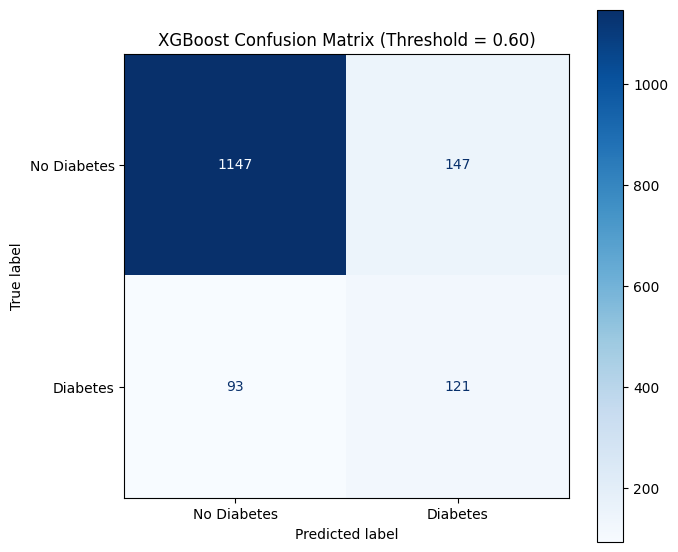

In [293]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    display_labels=["No Diabetes", "Diabetes"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("XGBoost Confusion Matrix (Threshold = 0.60)")
plt.tight_layout()

plt.savefig(
    figures_dir / "xgboost_final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

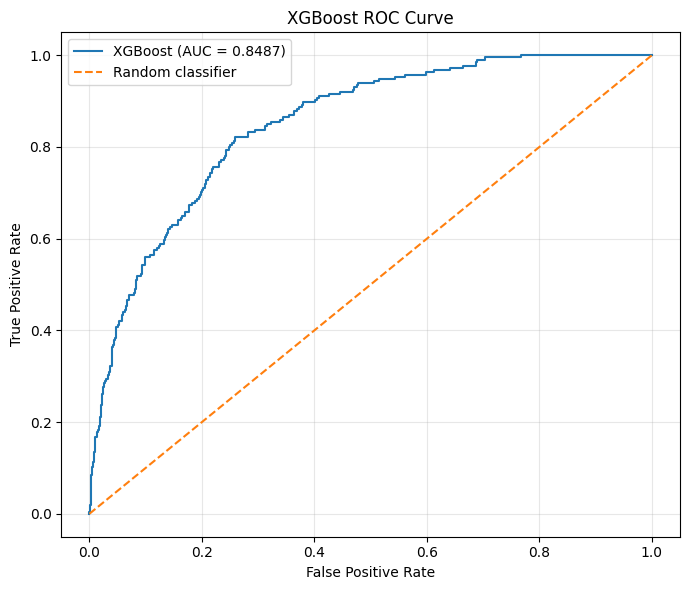

In [294]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    test_probabilities
)

roc_auc_value = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    fpr,
    tpr,
    label=f"XGBoost (AUC = {roc_auc_value:.4f})"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("XGBoost ROC Curve")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_dir / "xgboost_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

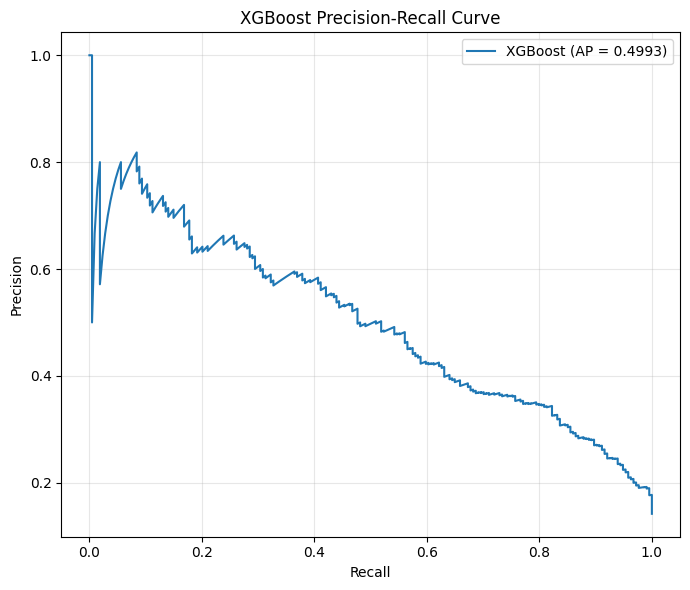

In [295]:
from sklearn.metrics import precision_recall_curve, average_precision_score

pr_precision, pr_recall, pr_thresholds = precision_recall_curve(
    y_test,
    test_probabilities
)

average_precision = average_precision_score(
    y_test,
    test_probabilities
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    pr_recall,
    pr_precision,
    label=f"XGBoost (AP = {average_precision:.4f})"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("XGBoost Precision-Recall Curve")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    figures_dir / "xgboost_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [296]:
final_test_metrics = pd.DataFrame([{
    "Model": "Tuned XGBoost",
    "Threshold": 0.60,
    "Accuracy": accuracy_score(y_test, final_predictions),
    "Precision": precision_score(y_test, final_predictions),
    "Recall": recall_score(y_test, final_predictions),
    "F1-score": f1_score(y_test, final_predictions),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "Average Precision": average_precision_score(
        y_test, test_probabilities
    )
}])

display(final_test_metrics.round(4))

final_test_metrics.to_csv(
    tables_dir / "xgboost_final_test_metrics.csv",
    index=False
)

print("Final evaluation metrics saved.")

,Model,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Tuned XGBoost,0.6,0.8408,0.4515,0.5654,0.5021,0.8487,0.4993


Final evaluation metrics saved.
